In [1]:

from pathlib import Path
from IPython.display import display
import urllib.request
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

# 원본 Colab과 동일한 Drive ID를 사용합니다. 다른 로컬 데이터로 대체하지 않습니다.
DRIVE_FILE_ID = "1M57ApeqppLf44pBA686f8pnyc2JrVTdq"
ORIGINAL_SHA256 = "eadcecf36fdd158a2bcf82ae1f69f6976a6498e74b78d5d62fb1bb9e87b82713"
원본폴더 = Path.cwd() / "Drive_원본" / DRIVE_FILE_ID
원본폴더.mkdir(parents=True, exist_ok=True)
파일 = 원본폴더 / "체류시간_찐최종.csv"
if not 파일.is_file():
    urllib.request.urlretrieve(
        f"https://drive.google.com/uc?export=download&id={DRIVE_FILE_ID}", 파일
    )
if hashlib.sha256(파일.read_bytes()).hexdigest() != ORIGINAL_SHA256:
    raise ValueError("입력 파일이 검증한 Colab 원본과 다릅니다. 다른 CSV로 대체하지 말고 원본 Drive 파일을 확인하세요.")

최종자료 = pd.read_csv(파일, encoding="utf-8-sig", low_memory=False)
최종자료.columns = 최종자료.columns.str.strip()

# 실제 열 이름을 확인한 뒤 날짜 변환
for 열 in ["접안일시", "출항일시"]:
    if 열 in 최종자료.columns:
        최종자료[열] = pd.to_datetime(최종자료[열], format="mixed", errors="coerce")
    else:
        print(f"새 CSV에 '{열}' 열이 없습니다.")

df1 = 최종자료

print(f"최종자료 {len(df1):,}행 × {df1.shape[1]}열")
display(df1.head())
if 최종자료.shape != (33994, 21):
    raise ValueError(f"원본 Colab의 33994행 × 21열과 다릅니다: {최종자료.shape}")
print("원본 Drive ID:", DRIVE_FILE_ID)
print("원본 파일 SHA-256 검증 완료")


최종자료 33,994행 × 21열


,선박명,총톤수,항만구분,터미널,선사,접안일시,출항일시,체류시간,순수물동량,Shift수량,총작업량,체류시간_풍속_중앙값_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_유의파고_최댓값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h)
0,NORTHERN GENERAL,41835,신항,BNCT,CMA,2021-01-01 03:20:00,2021-01-01 19:00:00,15.666667,814,0,814.0,1.640,NaN,NaN,0.30,0.4,0.6,0.4,"5,000.00","5,000.00",0.0
1,PRESIDENT FD ROOSEVELT,75752,신항,BNCT,APL,2021-01-01 15:20:00,2021-01-03 00:00:00,32.666667,"1,589.00",260,1849.0,1.850,NaN,NaN,0.30,0.4,0.6,0.4,"4,842.00","5,000.00",0.0
2,PRESIDENT CLEVELAND,75015,신항,BNCT,APL,2021-01-02 10:20:00,2021-01-03 00:05:00,13.750000,729,0,729.0,2.355,NaN,NaN,0.25,0.3,0.5,0.4,"4,842.00","5,000.00",0.0
3,COSCO GUANGZHOU,109149,신항,BNCT,COS,2021-01-01 21:25:00,2021-01-03 05:30:00,32.083333,"2,153.00",0,2153.0,2.050,NaN,NaN,0.25,0.3,0.5,0.4,"4,842.00","5,000.00",0.0
4,CONTSHIP DAY,7170,신항,BNCT,APC,2021-01-03 09:15:00,2021-01-03 17:50:00,8.583333,222,0,222.0,2.830,NaN,NaN,0.30,0.3,0.5,0.4,"5,000.00","5,000.00",0.0


원본 Drive ID: 1M57ApeqppLf44pBA686f8pnyc2JrVTdq
원본 파일 SHA-256 검증 완료


In [2]:
df1 = df1.rename(
    columns={"체류시간_특보노출시간(h)": "체류시간_특보노출시간"},
)
최종자료 = df1


In [3]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.text import Text

# 각 그림의 실제 글자에도 글꼴을 적용해 재실행이나 테마 변경의 영향을 줄입니다.
_available_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((name for name in (
    "Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"
) if name in _available_fonts), None)
if KOREAN_FONT is None:
    raise RuntimeError("한글 글꼴을 찾지 못했습니다. 맑은 고딕 설치를 확인하세요.")

def 한글설정():
    plt.rcParams["font.family"] = KOREAN_FONT
    plt.rcParams["font.sans-serif"] = [KOREAN_FONT]
    plt.rcParams["axes.unicode_minus"] = False

def 그림표시():
    그림 = plt.gcf()
    한글설정()
    for 글자 in 그림.findobj(match=Text):
        글자.set_fontfamily(KOREAN_FONT)
    plt.show()
    plt.close(그림)

한글설정()
print("사용 글꼴:", KOREAN_FONT)


사용 글꼴: Malgun Gothic


In [4]:
df1 = 최종자료

In [5]:
df1.shape

(33994, 21)

In [6]:
df1.columns.to_list()

['선박명',
 '총톤수',
 '항만구분',
 '터미널',
 '선사',
 '접안일시',
 '출항일시',
 '체류시간',
 '순수물동량',
 'Shift수량',
 '총작업량',
 '체류시간_풍속_중앙값_mps',
 '체류시간_최대순간풍속_최댓값_mps',
 '체류시간_최대순간풍속_중앙값_mps',
 '체류시간_유의파고_중앙값_m',
 '체류시간_유의파고_최댓값_m',
 '체류시간_순간최대파고_최댓값_m',
 '체류시간_순간최대파고_중앙값_m',
 '체류시간_시정_최솟값_10m',
 '체류시간_시정_중앙값_10m',
 '체류시간_특보노출시간']

In [7]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 33994 entries, 0 to 33993
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   선박명                  33994 non-null  str           
 1   총톤수                  33994 non-null  int64         
 2   항만구분                 33994 non-null  str           
 3   터미널                  33994 non-null  str           
 4   선사                   33993 non-null  str           
 5   접안일시                 33994 non-null  datetime64[us]
 6   출항일시                 33994 non-null  datetime64[us]
 7   체류시간                 33994 non-null  float64       
 8   순수물동량                33994 non-null  str           
 9   Shift수량              33994 non-null  str           
 10  총작업량                 33994 non-null  float64       
 11  체류시간_풍속_중앙값_mps      33856 non-null  float64       
 12  체류시간_최대순간풍속_최댓값_mps  32617 non-null  float64       
 13  체류시간_최대순간풍속_중앙값_mps  32617 non-null  float

In [8]:
열 = ["순수물동량", "Shift수량"]

for 이름 in 열:
    값 = df1[이름].astype("string").str.strip().str.replace(",", "", regex=False)
    df1[이름] = pd.to_numeric(값, errors="raise").astype("float64")

df1[열].dtypes

순수물동량      float64
Shift수량    float64
dtype: object

In [9]:
df1[["순수물동량", "Shift수량"]].head()

,순수물동량,Shift수량
0,814.0,0.0
1,1589.0,260.0
2,729.0,0.0
3,2153.0,0.0
4,222.0,0.0


In [10]:
df1.isna().sum()

선박명                       0
총톤수                       0
항만구분                      0
터미널                       0
선사                        1
접안일시                      0
출항일시                      0
체류시간                      0
순수물동량                     0
Shift수량                   0
총작업량                      0
체류시간_풍속_중앙값_mps         138
체류시간_최대순간풍속_최댓값_mps    1377
체류시간_최대순간풍속_중앙값_mps    1377
체류시간_유의파고_중앙값_m         545
체류시간_유의파고_최댓값_m         539
체류시간_순간최대파고_최댓값_m       545
체류시간_순간최대파고_중앙값_m       545
체류시간_시정_최솟값_10m          24
체류시간_시정_중앙값_10m          24
체류시간_특보노출시간               0
dtype: int64

In [11]:
display(df1.loc[df1["선사"].isna()])

,선박명,총톤수,항만구분,터미널,선사,접안일시,출항일시,체류시간,순수물동량,Shift수량,총작업량,체류시간_풍속_중앙값_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_유의파고_최댓값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간
6721,SUNNY LOTUS,9910,북항,BPTC_G,NaN,2023-02-04 19:00:00,2023-02-08 12:00:00,89.0,0.0,0.0,0.0,1.2,5.66,1.75,0.4,1.3,1.6,0.5,851,"3,236.00",0.0


In [12]:
기상열 = [
    열 for 열 in df1.columns
    if 열.startswith(("접안시_", "체류시간_"))
]

기상결측 = pd.DataFrame({
    "결측 건수": df1[기상열].isna().sum(),
    "결측률(%)": df1[기상열].isna().mean().mul(100).round(2)
})

display(기상결측.sort_values("결측률(%)", ascending=False))

,결측 건수,결측률(%)
체류시간_최대순간풍속_최댓값_mps,1377,4.05
체류시간_최대순간풍속_중앙값_mps,1377,4.05
체류시간_순간최대파고_최댓값_m,545,1.60
체류시간_유의파고_중앙값_m,545,1.60
체류시간_순간최대파고_중앙값_m,545,1.60
체류시간_유의파고_최댓값_m,539,1.59
체류시간_풍속_중앙값_mps,138,0.41
체류시간_시정_최솟값_10m,24,0.07
체류시간_시정_중앙값_10m,24,0.07
체류시간_특보노출시간,0,0.00


In [13]:
df1.describe().round(2)

,총톤수,접안일시,출항일시,체류시간,순수물동량,Shift수량,총작업량,체류시간_풍속_중앙값_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_유의파고_최댓값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_특보노출시간
count,33994.00,33994,33994,33994.00,33994.00,33994.00,33994.00,33856.00,32617.00,32617.00,33449.00,33455.00,33449.00,33449.00,33994.00
mean,41511.65,2023-01-13 17:43:24.381949,2023-01-14 13:42:19.614637,19.98,1069.15,32.21,1101.58,2.00,5.54,3.02,0.51,0.76,1.07,0.68,1.68
min,1864.00,2021-01-01 00:00:00,2021-01-01 09:00:00,1.00,0.00,0.00,0.00,0.00,0.21,0.00,0.10,0.10,0.20,0.10,0.00
25%,9563.00,2022-01-22 04:45:00,2022-01-23 00:58:30,13.25,438.00,0.00,441.00,1.30,4.29,1.96,0.30,0.40,0.60,0.40,0.00
50%,17933.00,2023-02-01 23:03:00,2023-02-02 21:01:00,18.00,693.00,0.00,700.00,1.80,5.34,2.75,0.40,0.60,0.90,0.60,0.00
75%,68687.00,2024-01-03 02:00:00,2024-01-03 16:15:00,24.75,1370.00,4.00,1412.00,2.50,6.56,3.84,0.60,0.90,1.30,0.85,0.00
max,236583.00,2024-12-31 11:30:00,2024-12-31 23:00:00,119.50,5845.00,1084.00,6085.00,9.84,20.18,11.90,4.05,10.80,17.20,5.75,68.00
std,47627.27,NaN,NaN,9.49,969.15,104.27,1012.02,0.98,1.97,1.42,0.31,0.48,0.67,0.42,5.11


In [14]:
기상열 = [열 for 열 in df1.columns if 열.startswith("체류시간_")]
기상자료 = df1[기상열]

분포요약 = 기상자료.describe(
    percentiles=[0.25, 0.50, 0.75, 0.95]
).T.rename(columns={
    "count": "유효건수",
    "mean": "평균",
    "std": "표준편차",
    "min": "최솟값",
    "50%": "중앙값",
    "max": "최댓값",
})

분포요약["0인 건수"] = 기상자료.eq(0).sum()

display(분포요약.round(2))

,유효건수,평균,표준편차,최솟값,25%,중앙값,75%,95%,최댓값,0인 건수
체류시간_풍속_중앙값_mps,33856.0,2.00,0.98,0.00,1.30,1.80,2.50,3.86,9.84,8
체류시간_최대순간풍속_최댓값_mps,32617.0,5.54,1.97,0.21,4.29,5.34,6.56,8.94,20.18,0
체류시간_최대순간풍속_중앙값_mps,32617.0,3.02,1.42,0.00,1.96,2.75,3.84,5.70,11.90,2
체류시간_유의파고_중앙값_m,33449.0,0.51,0.31,0.10,0.30,0.40,0.60,1.15,4.05,0
체류시간_유의파고_최댓값_m,33455.0,0.76,0.48,0.10,0.40,0.60,0.90,1.70,10.80,0
체류시간_순간최대파고_최댓값_m,33449.0,1.07,0.67,0.20,0.60,0.90,1.30,2.40,17.20,0
체류시간_순간최대파고_중앙값_m,33449.0,0.68,0.42,0.10,0.40,0.60,0.85,1.50,5.75,0
체류시간_특보노출시간,33994.0,1.68,5.11,0.00,0.00,0.00,0.00,14.00,68.00,29207


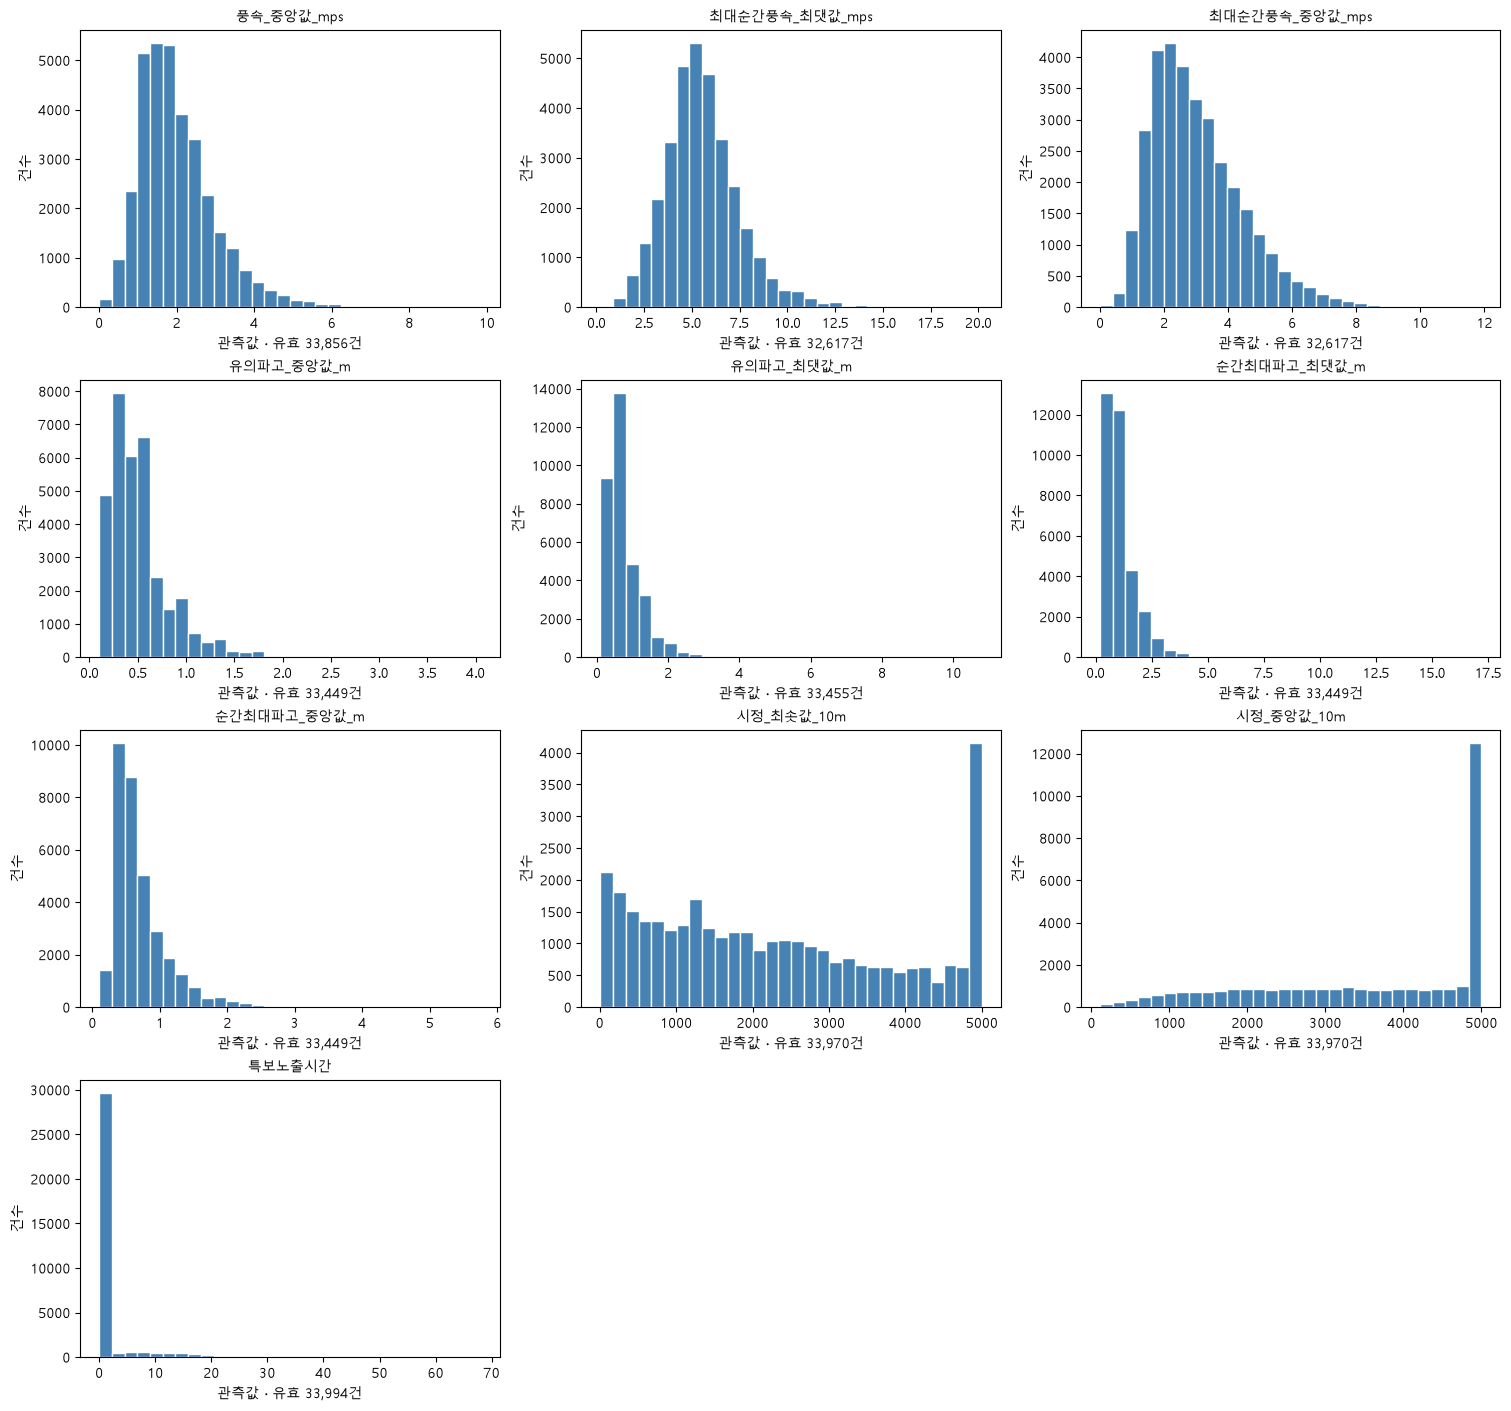

In [15]:
그래프열 = [열 for 열 in df1.columns if 열.startswith("체류시간_")]
행수 = (len(그래프열) + 2) // 3

fig, axes = plt.subplots(
    행수, 3,
    figsize=(15, 3.5 * 행수),
    squeeze=False,
    layout="constrained",
)

for ax, 열 in zip(axes.flat, 그래프열):
    값 = pd.to_numeric(
        df1[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    ).dropna()

    ax.hist(값, bins=30, color="steelblue", edgecolor="white")
    ax.set_title(열.removeprefix("체류시간_"), fontsize=10)
    ax.set_xlabel(f"관측값 · 유효 {len(값):,}건")
    ax.set_ylabel("건수")

for ax in list(axes.flat)[len(그래프열):]:
    ax.set_visible(False)

그림표시()

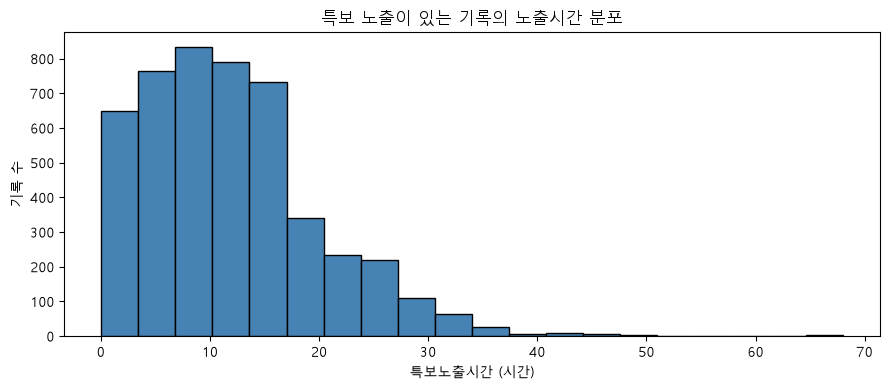

In [16]:
특보있음 = df1.loc[df1["체류시간_특보노출시간"] > 0].copy()

plt.figure(figsize=(9, 4))
plt.hist(
    특보있음["체류시간_특보노출시간"],
    bins=20,
    color="steelblue",
    edgecolor="black",
)

plt.title("특보 노출이 있는 기록의 노출시간 분포")
plt.xlabel("특보노출시간 (시간)")
plt.ylabel("기록 수")
plt.tight_layout()
그림표시()

In [17]:
display(
    특보있음.sort_values("체류시간_특보노출시간", ascending=False)
    [["선박명", "접안일시", "체류시간", "체류시간_특보노출시간"]]
    .head(10)
)

,선박명,접안일시,체류시간,체류시간_특보노출시간
6096,PACIFIC GENEVA,2022-09-17 11:40:00,99.333333,68.000
6044,XIUMEI SHANGHAI,2022-09-03 21:05:00,91.916667,67.917
4684,OCEAN PROBE,2021-09-16 03:00:00,74.000000,51.000
32931,MSC JEWEL,2023-09-05 12:50:00,49.166667,49.167
31936,CAPE ARTEMISIO,2022-06-06 05:05:00,46.916667,46.917
15025,BF CARP,2022-12-23 09:00:00,52.000000,46.000
16136,PANCON CHAMPION,2023-05-05 09:10:00,45.833333,45.833
3796,PRESIDENT WILSON,2021-02-24 00:00:00,109.000000,45.000
10270,SKY WIND,2021-02-26 07:50:00,53.166667,45.000
33344,VALOR,2024-02-21 04:30:00,44.200000,44.200


###특보노출 기록의 노출시간
분포특보노출시간 상위 10건의 노출시간은 **44.20~68.00시간**이었다.  
**PACIFIC GENEVA**의 특보노출시간이 **68시간**으로 가장 길었다.  
10건 중 **4건**은 체류 기간 전체가 특보 기간과 겹쳤다. 이는 체류시간내 특보가 발효된 경우이다.

In [18]:
sorted(df1["터미널"].dropna().unique())

['BNCT', 'BPTC_G', 'BPT_S', 'HPNT', 'PNC', 'PNIT']

In [19]:
df1["항만구분"] = "신항"
df1.loc[df1["터미널"].isin(["BPTC_G", "BPT_S"]), "항만구분"] = "북항"

display(df1[["터미널", "항만구분"]].drop_duplicates().sort_values("터미널"))

,터미널,항만구분
0,BNCT,신항
3559,BPTC_G,북항
9842,BPT_S,북항
21122,HPNT,신항
24107,PNC,신항
30833,PNIT,신항


In [20]:
# 항만·터미널별 연도별 기록 수와 터미널 내 비율을 확인한다.
연도 = pd.to_datetime(df1["접안일시"], errors="coerce").dt.year

건수표 = pd.crosstab(
    [df1["항만구분"], df1["터미널"]],
    연도,
)
건수표.columns = 건수표.columns.astype(int)
건수표["전체"] = 건수표.sum(axis=1)

연도별건수 = 건수표.drop(columns="전체")
연도별비율 = 연도별건수.div(건수표["전체"], axis=0)

표시표 = 연도별건수.astype("string")

for 연도 in 연도별건수.columns:
    표시표[연도] = (
        연도별건수[연도].map("{:,}".format)
        + " (" + 연도별비율[연도].map("{:.1%}".format) + ")"
    )

표시표["전체"] = 건수표["전체"].map("{:,}".format)
display(표시표)

접안일시                  2021           2022           2023           2024  \
항만구분 터미널                                                                  
북항   BPTC_G  1,535 (24.4%)  1,458 (23.2%)  1,692 (26.9%)  1,598 (25.4%)   
     BPT_S   2,597 (23.0%)  2,649 (23.5%)  3,155 (28.0%)  2,879 (25.5%)   
신항   BNCT      826 (23.2%)    884 (24.8%)    931 (26.2%)    918 (25.8%)   
     HPNT      688 (23.0%)    697 (23.4%)    798 (26.7%)    802 (26.9%)   
     PNC     1,619 (24.1%)  1,779 (26.4%)  1,745 (25.9%)  1,583 (23.5%)   
     PNIT      759 (24.0%)    743 (23.5%)    894 (28.3%)    765 (24.2%)   

접안일시             전체  
항만구분 터미널             
북항   BPTC_G   6,283  
     BPT_S   11,280  
신항   BNCT     3,559  
     HPNT     2,985  
     PNC      6,726  
     PNIT     3,161

In [21]:
체류시간요약 = (
    df1.groupby(["항만구분", "터미널"])["체류시간"]
    .agg(최솟값="min", 중앙값="median", 최댓값="max", 평균값="mean")
    .round(2)
)

display(체류시간요약)

최솟값    중앙값     최댓값    평균값
항만구분 터미널                               
북항   BPTC_G  2.00  15.00  119.00  16.33
     BPT_S   1.00  17.67  119.50  18.42
신항   BNCT    1.17  22.55   57.42  23.76
     HPNT    1.50  19.90   57.10  21.59
     PNC     1.33  19.20   57.88  20.71
     PNIT    1.67  23.50   64.00  25.48

북항 터미널의 체류시간 최댓값이 119.0 - 119.5로 재항시간의 최댓값인 75시간을 초과하는 경우를 보아, 이상치로 판단되었다. 우선 북항 터미널의 체류시간 TOP10을 확인하고 분석대상의 기준을 축소한다.

## 북항 터미널 BPT_S, BPTC_G

In [22]:
북항_TOP10 = (
    df1.loc[df1["항만구분"].eq("북항"), [
        "터미널", "선박명", "접안일시", "출항일시", "체류시간", "총작업량"
    ]]
    .nlargest(10, "체류시간")
    .copy()
)

북항_TOP10["75시간_초과"] = 북항_TOP10["체류시간"].gt(75)

display(북항_TOP10.round({"체류시간": 2}).reset_index(drop=True))

,터미널,선박명,접안일시,출항일시,체류시간,총작업량,75시간_초과
0,BPT_S,NIIGATA TRADER,2021-12-13 10:30:00,2021-12-18 10:00:00,119.50,223.00,True
1,BPTC_G,PADIAN 3,2021-05-26 21:00:00,2021-05-31 20:00:00,119.00,0.00,True
2,BPTC_G,MAJURO CHIEF,2021-10-07 18:00:00,2021-10-12 15:00:00,117.00,0.00,True
3,BPTC_G,PRESIDENT WILSON,2021-02-24 00:00:00,2021-02-28 13:00:00,109.00,0.00,True
4,BPTC_G,MAJURO CHIEF,2022-01-03 06:00:00,2022-01-07 19:00:00,109.00,0.00,True
5,BPTC_G,YANGTZE TRADER,2022-02-11 15:30:00,2022-02-15 23:00:00,103.50,172.00,True
6,BPTC_G,GRACE MERCHANT,2023-01-10 05:00:00,2023-01-14 09:00:00,100.00,419.98,True
7,BPTC_G,PACIFIC GENEVA,2022-09-17 11:40:00,2022-09-21 15:00:00,99.33,817.00,True
8,BPTC_G,STAR CLIPPER,2022-03-10 07:00:00,2022-03-14 07:00:00,96.00,0.00,True
9,BPTC_G,AS CLEMENTINA,2021-08-28 07:00:00,2021-09-01 06:00:00,95.00,0.00,True


In [23]:
북항_터미널별_TOP10 = (
    df1.loc[df1["항만구분"].eq("북항"), [
        "터미널", "선박명", "접안일시", "출항일시", "체류시간", "총작업량"
    ]]
    .sort_values(["터미널", "체류시간"], ascending=[True, False])
    .groupby("터미널", sort=False)
    .head(10)
    .reset_index(drop=True)
)

북항_터미널별_TOP10["순위"] = (
    북항_터미널별_TOP10.groupby("터미널").cumcount() + 1
)
북항_터미널별_TOP10["75시간_초과"] = (
    북항_터미널별_TOP10["체류시간"].gt(75)
)

display(
    북항_터미널별_TOP10
    .set_index(["터미널", "순위"])
    .round({"체류시간": 2})
)

선박명                접안일시                출항일시    체류시간  \
터미널    순위                                                                     
BPTC_G 1           PADIAN 3 2021-05-26 21:00:00 2021-05-31 20:00:00  119.00   
       2       MAJURO CHIEF 2021-10-07 18:00:00 2021-10-12 15:00:00  117.00   
       3   PRESIDENT WILSON 2021-02-24 00:00:00 2021-02-28 13:00:00  109.00   
       4       MAJURO CHIEF 2022-01-03 06:00:00 2022-01-07 19:00:00  109.00   
       5     YANGTZE TRADER 2022-02-11 15:30:00 2022-02-15 23:00:00  103.50   
       6     GRACE MERCHANT 2023-01-10 05:00:00 2023-01-14 09:00:00  100.00   
       7     PACIFIC GENEVA 2022-09-17 11:40:00 2022-09-21 15:00:00   99.33   
       8       STAR CLIPPER 2022-03-10 07:00:00 2022-03-14 07:00:00   96.00   
       9      AS CLEMENTINA 2021-08-28 07:00:00 2021-09-01 06:00:00   95.00   
       10        VEGA VENTO 2021-11-18 00:00:00 2021-11-21 23:00:00   95.00   
BPT_S  1     NIIGATA TRADER 2021-12-13 10:30:00 2021-12-18 10:00:00  119.50   
       2    SINOKOR NIIGATA 2021-01-26 23:30:00 2021-01-30 01:00:00   73.50   
       3   HEUNG-A HAIPHONG 2022-09-09 15:20:00 2022-09-11 23:00:00   55.67   
       4       STAR SKIPPER 2021-08-23 00:30:00 2021-08-25 08:00:00   55.50   
       5    SAWASDEE BALTIC 2023-09-28 16:30:00 2023-10-01 00:00:00   55.50   
       6    PORT VILA CHIEF 2023-09-28 11:40:00 2023-09-30 19:00:00   55.33   
       7         KMTC ULSAN 2024-02-04 00:00:00 2024-02-06 07:00:00   55.00   
       8     QINGDAO TRADER 2022-05-01 07:30:00 2022-05-03 14:00:00   54.50   
       9   SAWASDEE INCHEON 2024-09-16 11:00:00 2024-09-18 17:00:00   54.00   
       10         VASI MOON 2021-09-01 11:40:00 2021-09-03 17:00:00   53.33   

              총작업량  75시간_초과  
터미널    순위                    
BPTC_G 1      0.00     True  
       2      0.00     True  
       3      0.00     True  
       4      0.00     True  
       5    172.00     True  
       6    419.98     True  
       7    817.00     True  
       8      0.00     True  
       9      0.00     True  
       10     0.00     True  
BPT_S  1    223.00     True  
       2    236.00    False  
       3    750.00    False  
       4    569.00    False  
       5   1386.00    False  
       6    644.00    False  
       7   1233.00    False  
       8    460.00    False  
       9   1326.00    False  
       10  1432.00    False

## 신항 터미널 BNCT, HPNT, PNC, PNIT 비교

In [24]:
신항_TOP10 = (
    df1.loc[df1["항만구분"].eq("신항"), [
        "터미널", "선박명", "접안일시", "출항일시", "체류시간", "총작업량"
    ]]
    .sort_values(["터미널", "체류시간"], ascending=[True, False])
    .groupby("터미널", sort=False)
    .head(10)
    .copy()
)

신항_TOP10["순위"] = 신항_TOP10.groupby("터미널").cumcount() + 1
신항_TOP10["75시간_초과"] = 신항_TOP10["체류시간"].gt(75)

display(
    신항_TOP10.set_index(["터미널", "순위"])
    .round({"체류시간": 2})
)

선박명                접안일시                출항일시   체류시간  \
터미널  순위                                                                       
BNCT 1          CMA CGM VELA 2021-04-17 22:30:00 2021-04-20 07:55:00  57.42   
     2     ZHONG GU BEI JING 2022-10-28 12:30:00 2022-10-30 21:50:00  57.33   
     3    CMA CGM LISA MARIE 2021-04-24 12:50:00 2021-04-26 21:00:00  56.17   
     4      CMA CGM CONCORDE 2021-11-23 02:40:00 2021-11-25 09:05:00  54.42   
     5                ERVING 2022-03-23 09:06:00 2022-03-25 15:13:00  54.12   
     6     CMA CGM TROCADERO 2022-06-17 00:01:00 2022-06-19 05:36:00  53.58   
     7     CMA CGM INTEGRITY 2024-02-28 12:30:00 2024-03-01 17:55:00  53.42   
     8     CMA CGM ARGENTINA 2022-11-09 07:12:00 2022-11-11 12:00:00  52.80   
     9   CMA CGM JEAN MERMOZ 2022-10-28 07:27:00 2022-10-30 12:00:00  52.55   
     10       CMA CGM NEVADA 2022-02-06 20:48:00 2022-02-09 01:20:00  52.53   
HPNT 1       HYUNDAI JUPITER 2021-02-05 19:54:00 2021-02-08 05:00:00  57.10   
     2       HAMBURG EXPRESS 2021-06-06 21:18:00 2021-06-09 06:00:00  56.70   
     3        NAGOYA EXPRESS 2021-03-22 19:30:00 2021-03-25 04:00:00  56.50   
     4      HYUNDAI INTEGRAL 2022-05-03 04:54:00 2022-05-05 13:00:00  56.10   
     5       HYUNDAI NEPTUNE 2021-02-24 20:00:00 2021-02-27 04:00:00  56.00   
     6             HMM DRIVE 2021-08-01 13:12:00 2021-08-03 21:00:00  55.80   
     7           HMM VICTORY 2022-05-03 06:12:00 2022-05-05 14:00:00  55.80   
     8           YM TOTALITY 2021-01-25 00:24:00 2021-01-27 08:00:00  55.60   
     9            YM WELCOME 2021-07-02 23:24:00 2021-07-05 06:00:00  54.60   
     10           ONE TRITON 2021-11-01 00:28:00 2021-11-03 07:00:00  54.53   
PNC  1            NYK FUTAGO 2021-08-22 17:05:00 2021-08-25 02:58:00  57.88   
     2        RIO CHARLESTON 2021-08-22 19:03:00 2021-08-25 04:00:00  56.95   
     3         MAERSK HAVANA 2023-03-02 08:44:00 2023-03-04 17:02:00  56.30   
     4       SEASPAN HARRIER 2021-09-24 12:10:00 2021-09-26 19:55:00  55.75   
     5            MSC GENOVA 2021-09-04 18:20:00 2021-09-07 02:00:00  55.67   
     6        MAERSK HALIFAX 2023-01-19 22:30:00 2023-01-22 06:05:00  55.58   
     7            MSC ELOANE 2023-08-30 04:30:00 2023-09-01 12:00:00  55.50   
     8              HMM OSLO 2021-03-16 00:11:00 2021-03-18 07:00:00  54.82   
     9          MAREN MAERSK 2023-07-20 17:52:00 2023-07-23 00:15:00  54.38   
     10        MAERSK HAVANA 2021-08-20 06:40:00 2021-08-22 13:00:00  54.33   
PNIT 1     MSC MARTINA MARIA 2024-02-09 19:00:00 2024-02-12 11:00:00  64.00   
     2            YM WELCOME 2022-06-12 15:20:00 2022-06-15 07:00:00  63.67   
     3             MSC DAMLA 2023-07-28 15:50:00 2023-07-31 07:00:00  63.17   
     4    NAVIGARE COLLECTOR 2022-05-15 04:15:00 2022-05-17 19:00:00  62.75   
     5              MSC RUBY 2022-05-16 20:15:00 2022-05-19 11:00:00  62.75   
     6          YM WELLBEING 2022-02-16 12:25:00 2022-02-19 03:00:00  62.58   
     7   SOUTHAMPTON EXPRESS 2022-05-19 13:30:00 2022-05-22 04:00:00  62.50   
     8           ONE ORINOCO 2024-02-09 10:40:00 2024-02-12 01:00:00  62.33   
     9        CARSTEN MAERSK 2021-02-11 20:00:00 2021-02-14 10:05:00  62.08   
     10   SEASPAN BRILLIANCE 2022-02-16 04:10:00 2022-02-18 18:00:00  61.83   

           총작업량  75시간_초과  
터미널  순위                   
BNCT 1   4242.0    False  
     2   1964.0    False  
     3   3748.0    False  
     4   4454.0    False  
     5   2875.0    False  
     6   4960.0    False  
     7   4642.0    False  
     8   4117.0    False  
     9   3501.0    False  
     10  4849.0    False  
HPNT 1   3918.0    False  
     2   4714.0    False  
     3   4428.0    False  
     4   3885.0    False  
     5   3407.0    False  
     6   3912.0    False  
     7   4528.0    False  
     8   3707.0    False  
     9   5175.0    False  
     10  3290.0    False  
PNC  1   2324.0    False  
     2   2552.0    False  
     3   5360.0    False  
     4   6007.0    False  
    

## 신항 터미널 BNCT, HPNT, PNC, PNIT / 북항 터미널 BPT_S, BPTC_G - 기상 연결해서 비교

In [25]:
풍속열 = "체류시간_풍속_중앙값_mps"
터미널순서 = [
    ("신항", "BNCT"), ("신항", "HPNT"),
    ("신항", "PNC"),  ("신항", "PNIT"),
    ("북항", "BPTC_G"), ("북항", "BPT_S"),
]

비교 = df1[["항만구분", "터미널", 풍속열, "체류시간"]].copy()

for 열 in [풍속열, "체류시간"]:
    비교[열] = pd.to_numeric(
        비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

비교 = 비교.dropna(subset=[풍속열, "체류시간"])
비교 = 비교.loc[
    비교.set_index(["항만구분", "터미널"]).index.isin(터미널순서)
    & 비교[풍속열].ge(0)
].copy()

비교["풍속구간"] = pd.cut(
    비교[풍속열],
    bins=[0, 1, 2, 3, 4, 5, 6, 8, float("inf")],
    labels=["0-1", "1-2", "2-3", "3-4", "4-5", "5-6", "6-8", "8 이상"],
    right=False,
)

결과 = (
    비교.groupby(["항만구분", "터미널", "풍속구간"], observed=True)["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
    .round(2)
)

display(결과)

기록수  체류시간_중앙값
항만구분 터미널    풍속구간                
북항   BPTC_G 0-1    991     13.67
            1-2   2637      16.0
            2-3   1726      15.0
            3-4    693      15.0
            4-5    175     14.83
            5-6     21      16.0
            6-8      2      13.0
     BPT_S  0-1   1649      16.0
            1-2   5009      18.0
            2-3   3059      17.5
            3-4   1187      18.0
            4-5    268      17.5
            5-6     42      16.5
            6-8      4     12.92
신항   BNCT   0-1    181     17.42
            1-2   1843     23.52
            2-3   1025     22.13
            3-4    309     21.75
            4-5    131     22.95
            5-6     51      23.5
            6-8      9      21.6
            8 이상     2     15.68
     HPNT   0-1    172      15.0
            1-2   1505      21.5
            2-3    840      19.5
            3-4    293      17.8
            4-5    102      16.8
            5-6     46      18.0
            6-8     19      16.5
            8 이상     1      19.8
     PNC    0-1    402     15.11
            1-2   3358     20.55
            2-3   1881     19.42
            3-4    665      16.0
            4-5    261     16.67
            5-6    103     17.83
            6-8     40     16.13
            8 이상     1     23.95
     PNIT   0-1    156      16.8
            1-2   1596     24.33
            2-3    944     23.13
            3-4    276     22.01
            4-5    114     26.85
            5-6     48      19.0
            6-8     18      17.5
            8 이상     1     17.92

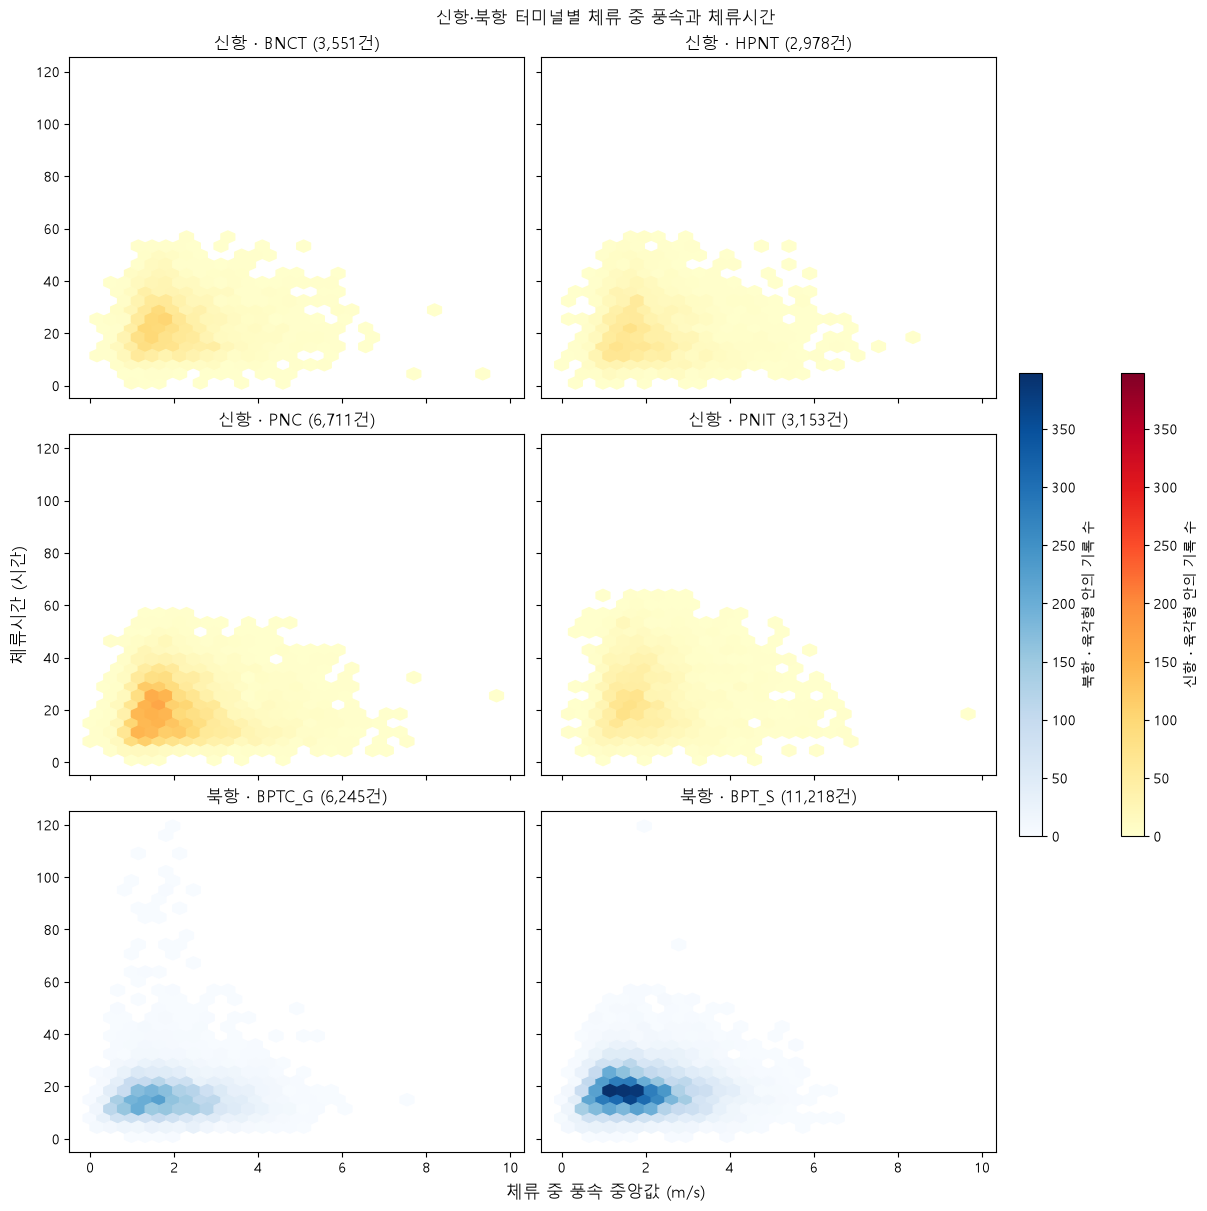

In [26]:
import matplotlib.pyplot as plt

# 앞의 분석 셀에서 만든 '비교', '풍속열', '터미널순서' 사용
공통범위 = (
    비교[풍속열].min(), 비교[풍속열].max(),
    비교["체류시간"].min(), 비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 12),
    sharex=True, sharey=True,
    layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 비교.loc[
        비교["항만구분"].eq(항만) & 비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if 자료.empty:
        continue

    그림 = ax.hexbin(
        자료[풍속열], 자료["체류시간"],
        gridsize=30, extent=공통범위,
        cmap=항만색[항만], mincnt=1,
    )
    항만그림[항만].append(그림)

# 두 항만의 색상 막대에 같은 건수 범위 적용
최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    if 목록:
        fig.colorbar(
            목록[0], ax=list(axes.flat),
            fraction=0.025, pad=0.025,
            label=f"{항만} · 육각형 안의 기록 수",
        )

fig.suptitle("신항·북항 터미널별 체류 중 풍속과 체류시간")
fig.supxlabel("체류 중 풍속 중앙값 (m/s)")
fig.supylabel("체류시간 (시간)")
그림표시()

신항과 북항 모두 **체류 중 풍속 중앙값 1-2 m/s, 체류시간 10-30시간** 구간에 기록이 주로 모였다.  
북항에서는 **BPTC_G를 중심으로 80시간을 넘는 체류**가 일부 관측됐으며, 이런 기록은 낮은 풍속 구간에서도 나타났다.  
고풍속 구간의 관측 건수는 적었고, 풍속이 높아질수록 체류시간이 길어지는 일관된 패턴은 보이지 않았다.

In [27]:
돌풍열 = "체류시간_최대순간풍속_최댓값_mps"

돌풍비교 = df1.loc[
    df1["터미널"].isin([터미널 for _, 터미널 in 터미널순서]),
    ["항만구분", "터미널", 돌풍열, "체류시간"],
].copy()

for 열 in [돌풍열, "체류시간"]:
    돌풍비교[열] = pd.to_numeric(
        돌풍비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

돌풍비교 = 돌풍비교.dropna(subset=[돌풍열, "체류시간"])
돌풍비교 = 돌풍비교.loc[돌풍비교[돌풍열].ge(0)].copy()

돌풍비교["돌풍구간"] = pd.cut(
    돌풍비교[돌풍열],
    bins=[0, 2, 4, 6, 8, 10, 12, float("inf")],
    labels=["0-2", "2-4", "4-6", "6-8", "8-10", "10-12", "12 이상"],
    right=False,
)

돌풍결과 = (
    돌풍비교.groupby(["항만구분", "터미널", "돌풍구간"], observed=True)
    ["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
    .round(2)
)

display(돌풍결과)

기록수  체류시간_중앙값
항만구분 터미널    돌풍구간                 
북항   BPTC_G 0-2     141       9.0
            2-4    1209      13.0
            4-6    2799     15.33
            6-8    1467     16.17
            8-10    303     17.33
            10-12    97      21.0
            12 이상    19      24.0
     BPT_S  0-2     166       9.0
            2-4    1913      15.0
            4-6    5070      18.0
            6-8    2825      19.0
            8-10    641      21.0
            10-12   196     21.75
            12 이상    32     24.58
신항   BNCT   0-2      32     11.77
            2-4     570     17.58
            4-6    1482      22.5
            6-8     906     24.53
            8-10    282     27.96
            10-12    83      26.6
            12 이상    48     28.98
     HPNT   0-2      45       8.0
            2-4     538      14.3
            4-6    1240     20.85
            6-8     709     22.03
            8-10    211      25.9
            10-12    68      26.5
            12 이상    34     20.05
     PNC    0-2     108      9.84
            2-4    1293     14.08
            4-6    2736      20.0
            6-8    1570     21.26
            8-10    515     22.97
            10-12   148      24.0
            12 이상    85     28.72
     PNIT   0-2      39      9.17
            2-4     490     16.75
            4-6    1281      23.0
            6-8     822     26.63
            8-10    266     32.17
            10-12    89     29.25
            12 이상    49     28.22

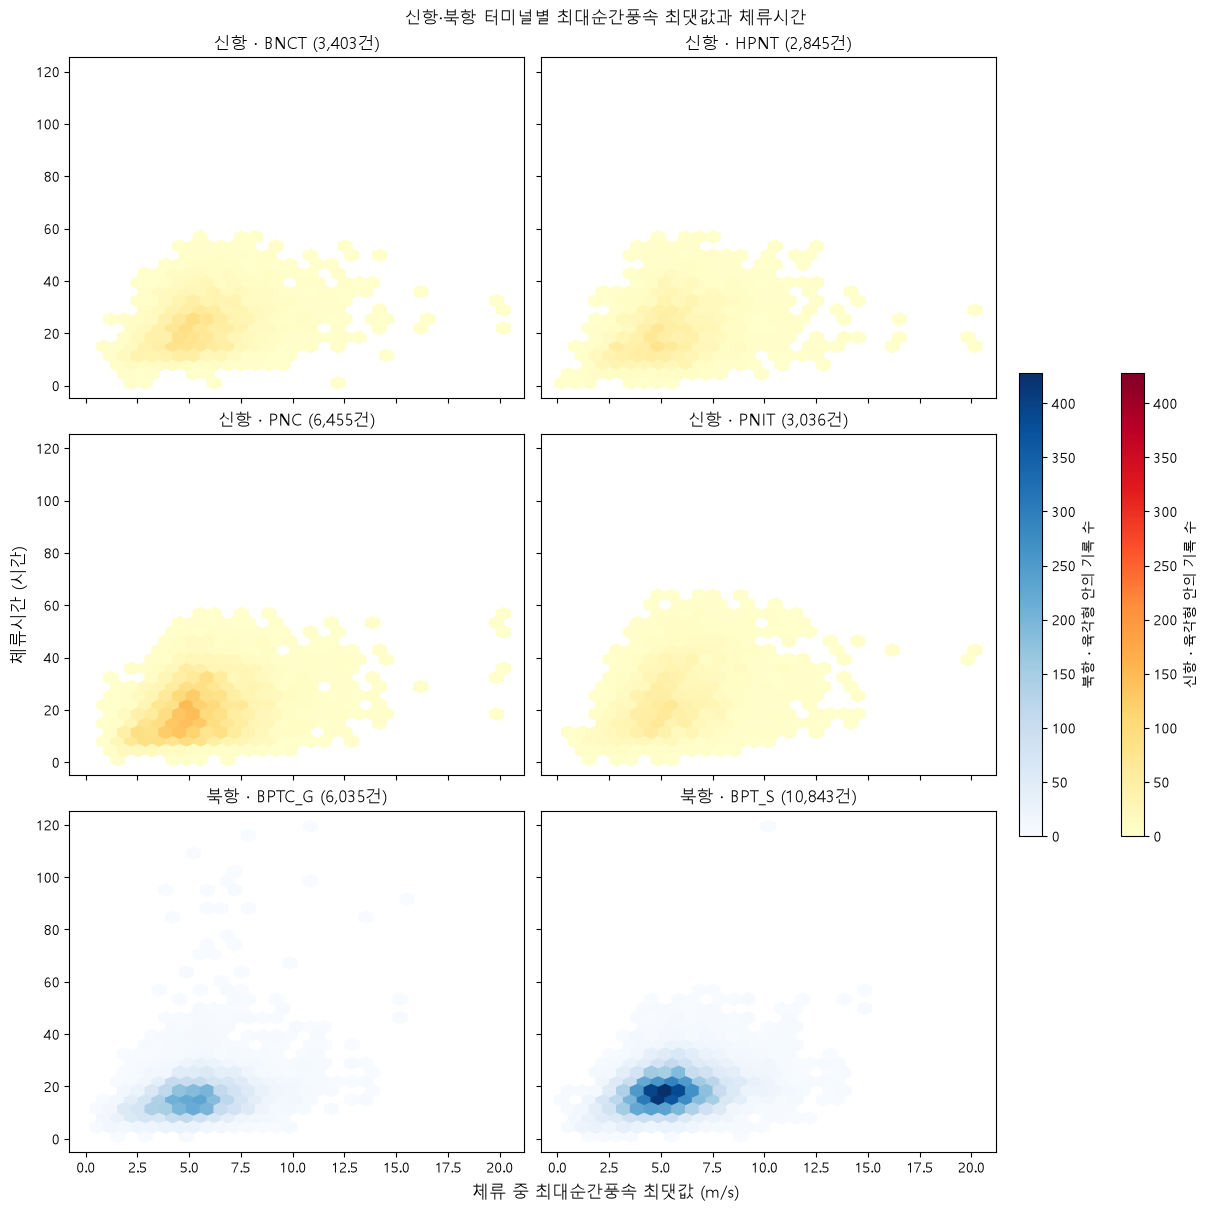

In [28]:
공통범위 = (
    돌풍비교[돌풍열].min(), 돌풍비교[돌풍열].max(),
    돌풍비교["체류시간"].min(), 돌풍비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True, sharey=True, layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 돌풍비교.loc[
        돌풍비교["항만구분"].eq(항만) & 돌풍비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if 자료.empty:
        continue

    그림 = ax.hexbin(
        자료[돌풍열], 자료["체류시간"],
        gridsize=30, extent=공통범위,
        cmap=항만색[항만], mincnt=1,
    )
    항만그림[항만].append(그림)

최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    if 목록:
        fig.colorbar(
            목록[0], ax=list(axes.flat),
            fraction=0.025, pad=0.025,
            label=f"{항만} · 육각형 안의 기록 수",
        )

fig.suptitle("신항·북항 터미널별 최대순간풍속 최댓값과 체류시간")
fig.supxlabel("체류 중 최대순간풍속 최댓값 (m/s)")
fig.supylabel("체류시간 (시간)")
그림표시()

신항과 북항 모두 **체류 중 최대순간풍속 최댓값 4-7 m/s, 체류시간 10-30시간** 구간에 기록이 주로 모였다.  
북항 **BPTC_G**에서는 80시간을 넘는 체류가 일부 관측됐으며, 이런 기록은 낮거나 중간 수준의 돌풍 구간에도 나타났다.  
고풍속 구간의 기록은 드물었고, 최대순간풍속이 높아질수록 체류시간이 길어지는 일관된 패턴은 보이지 않았다.

In [29]:
돌풍중앙열 = "체류시간_최대순간풍속_중앙값_mps"

돌풍중앙비교 = df1[
    ["항만구분", "터미널", 돌풍중앙열, "체류시간"]
].copy()

for 열 in [돌풍중앙열, "체류시간"]:
    돌풍중앙비교[열] = pd.to_numeric(
        돌풍중앙비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

돌풍중앙비교 = 돌풍중앙비교.dropna(subset=[돌풍중앙열, "체류시간"])
돌풍중앙비교 = 돌풍중앙비교.loc[
    돌풍중앙비교.set_index(["항만구분", "터미널"]).index.isin(터미널순서)
    & 돌풍중앙비교[돌풍중앙열].ge(0)
].copy()

돌풍중앙비교["돌풍구간"] = pd.cut(
    돌풍중앙비교[돌풍중앙열],
    bins=[0, 2, 4, 6, 8, 10, 12, float("inf")],
    labels=["0-2", "2-4", "4-6", "6-8", "8-10", "10-12", "12 이상"],
    right=False,
)

돌풍중앙결과 = (
    돌풍중앙비교.groupby(
        ["항만구분", "터미널", "돌풍구간"], observed=True
    )["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
    .round(2)
)

display(돌풍중앙결과)

기록수  체류시간_중앙값
항만구분 터미널    돌풍구간                 
북항   BPTC_G 0-2    1516     14.33
            2-4    2878     15.83
            4-6    1400      14.5
            6-8     226      15.0
            8-10     13     18.33
            10-12     2      15.0
     BPT_S  0-2    2651      17.0
            2-4    5407      18.0
            4-6    2408      17.5
            6-8     351     17.67
            8-10     26      19.0
신항   BNCT   0-2     942     21.07
            2-4    1876     23.37
            4-6     459     23.25
            6-8     111     22.75
            8-10     13      32.6
            10-12     2     15.68
     HPNT   0-2     764      18.3
            2-4    1562      21.0
            4-6     405      18.0
            6-8      95      16.9
            8-10     17      17.9
            10-12     2     26.55
     PNC    0-2    1860     18.58
            2-4    3416     20.45
            4-6     885     16.93
            6-8     259     17.43
            8-10     30     14.54
            10-12     5     19.97
     PNIT   0-2     818     21.82
            2-4    1701     23.92
            4-6     394     24.71
            6-8     101      21.7
            8-10     20     16.92
            10-12     2     14.51

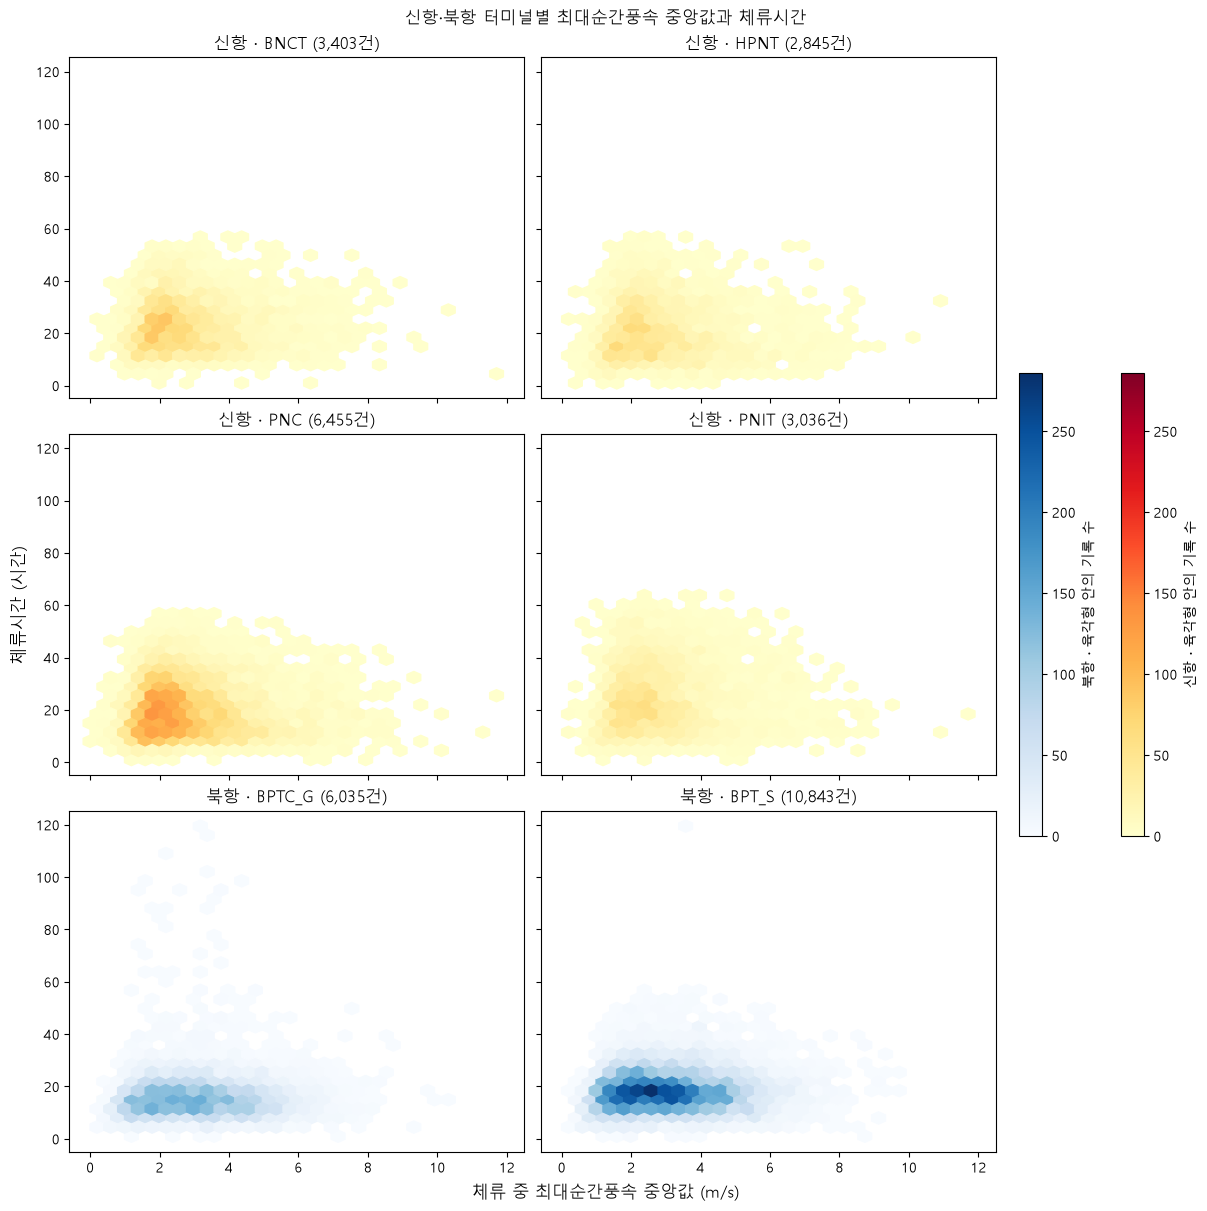

In [30]:
공통범위 = (
    돌풍중앙비교[돌풍중앙열].min(), 돌풍중앙비교[돌풍중앙열].max(),
    돌풍중앙비교["체류시간"].min(), 돌풍중앙비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True, sharey=True, layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 돌풍중앙비교.loc[
        돌풍중앙비교["항만구분"].eq(항만)
        & 돌풍중앙비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if 자료.empty:
        continue

    그림 = ax.hexbin(
        자료[돌풍중앙열], 자료["체류시간"],
        gridsize=30, extent=공통범위,
        cmap=항만색[항만], mincnt=1,
    )
    항만그림[항만].append(그림)

최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    if not 목록:
        continue

    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    fig.colorbar(
        목록[0], ax=list(axes.flat),
        fraction=0.025, pad=0.025,
        label=f"{항만} · 육각형 안의 기록 수",
    )

fig.suptitle("신항·북항 터미널별 최대순간풍속 중앙값과 체류시간")
fig.supxlabel("체류 중 최대순간풍속 중앙값 (m/s)")
fig.supylabel("체류시간 (시간)")
그림표시()

신항과 북항 모두 **체류 중 최대순간풍속 중앙값 1-4 m/s, 체류시간 10-30시간** 구간에 기록이 주로 모였다.  
북항 **BPTC_G**에서는 최대순간풍속 중앙값이 **1-4 m/s**인 구간에서도 **80시간을 넘는 체류**가 일부 나타났다.  
높은 풍속 구간의 기록은 드물었으며, 최대순간풍속 중앙값이 높아질수록 체류시간이 길어지는 일관된 패턴은 보이지 않았다.

In [31]:
파고열 = "체류시간_유의파고_중앙값_m"

파고비교 = df1[["항만구분", "터미널", 파고열, "체류시간"]].copy()

for 열 in [파고열, "체류시간"]:
    파고비교[열] = pd.to_numeric(
        파고비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

파고비교 = 파고비교.dropna(subset=[파고열, "체류시간"])
파고비교 = 파고비교.loc[
    파고비교.set_index(["항만구분", "터미널"]).index.isin(터미널순서)
    & 파고비교[파고열].ge(0)
].copy()

파고비교["파고구간"] = pd.cut(
    파고비교[파고열],
    bins=[0, 0.25, 0.5, 0.75, 1, 1.5, 2, float("inf")],
    labels=["0-0.25", "0.25-0.5", "0.5-0.75", "0.75-1", "1-1.5", "1.5-2", "2 이상"],
    right=False,
)

파고결과 = (
    파고비교.groupby(["항만구분", "터미널", "파고구간"], observed=True)
    ["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
    .round(2)
)

display(파고결과)

기록수  체류시간_중앙값
항만구분 터미널    파고구간                    
북항   BPTC_G 0-0.25     499      14.5
            0.25-0.5  2233      15.0
            0.5-0.75  1793     15.33
            0.75-1     671      15.0
            1-1.5      741      15.5
            1.5-2      180      15.0
            2 이상        26     16.33
     BPT_S  0-0.25     886      17.0
            0.25-0.5  3959     17.83
            0.5-0.75  3234     17.67
            0.75-1    1222      17.0
            1-1.5     1332     18.17
            1.5-2      319     18.67
            2 이상        52     22.62
신항   BNCT   0-0.25     789     21.22
            0.25-0.5  1670      22.9
            0.5-0.75   794     23.42
            0.75-1     179      23.0
            1-1.5       92     21.58
            1.5-2        4      19.9
     HPNT   0-0.25     639      19.8
            0.25-0.5  1393      19.9
            0.5-0.75   685      21.0
            0.75-1     168      18.0
            1-1.5       69      16.9
            1.5-2        3      19.8
     PNC    0-0.25    1419      18.7
            0.25-0.5  3201     19.92
            0.5-0.75  1522     19.42
            0.75-1     351      17.0
            1-1.5      176      19.0
            1.5-2        7     14.08
     PNIT   0-0.25     642      23.5
            0.25-0.5  1527     23.67
            0.5-0.75   758      23.5
            0.75-1     145      25.0
            1-1.5       68     21.52
            1.5-2        1      14.0

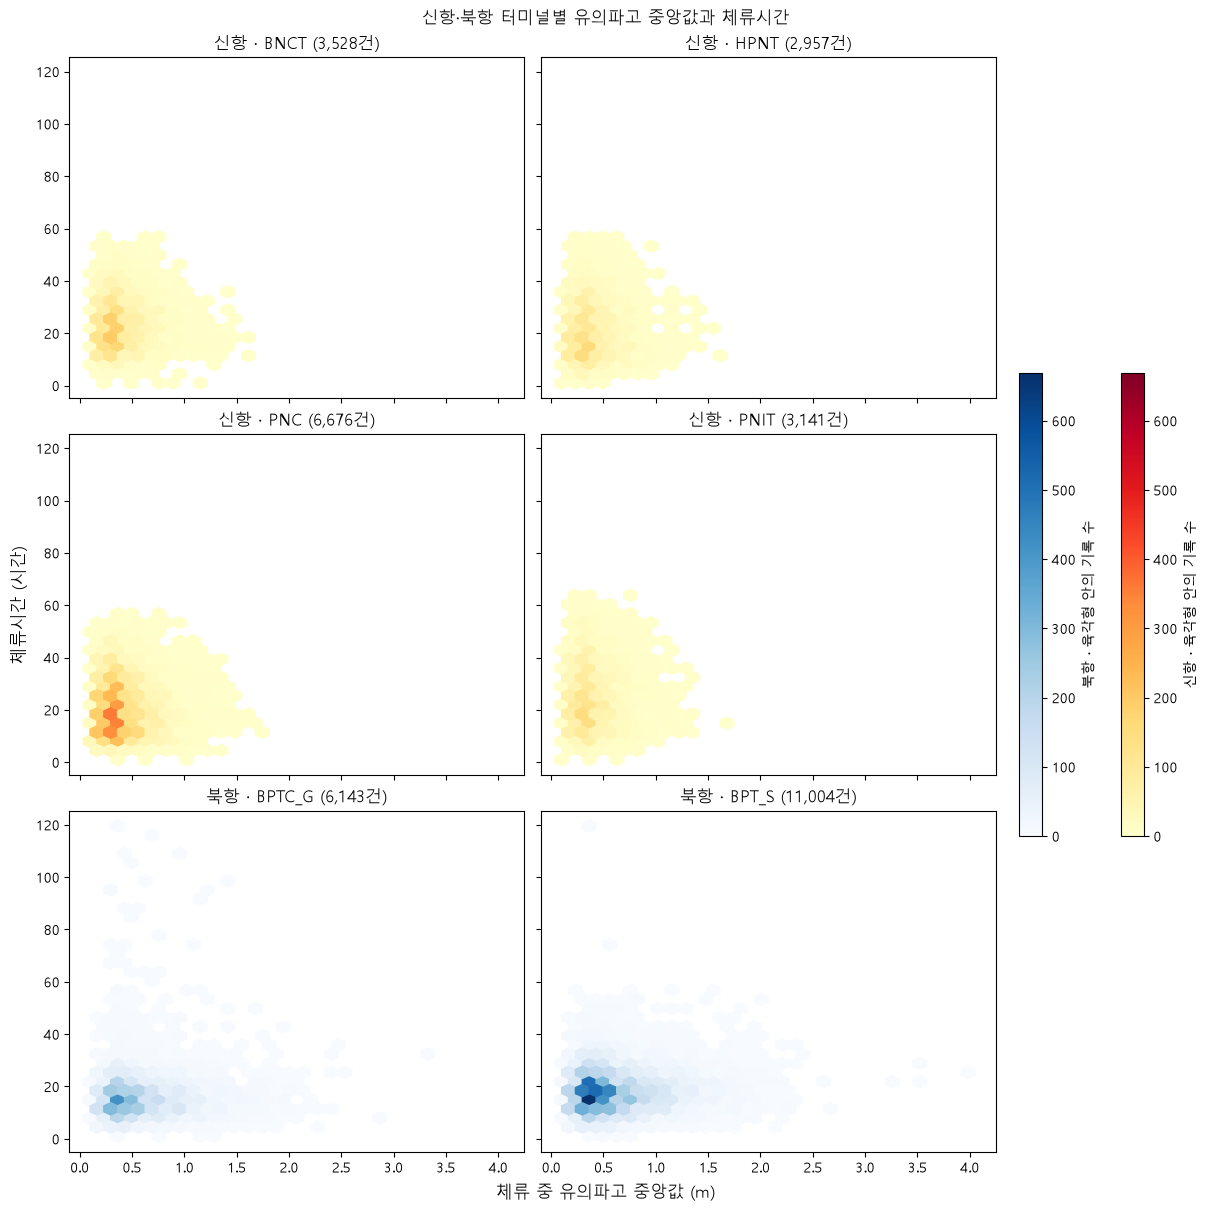

In [32]:
공통범위 = (
    파고비교[파고열].min(), 파고비교[파고열].max(),
    파고비교["체류시간"].min(), 파고비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True, sharey=True, layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 파고비교.loc[
        파고비교["항만구분"].eq(항만) & 파고비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if 자료.empty:
        continue

    그림 = ax.hexbin(
        자료[파고열], 자료["체류시간"],
        gridsize=30, extent=공통범위,
        cmap=항만색[항만], mincnt=1,
    )
    항만그림[항만].append(그림)

최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    if not 목록:
        continue

    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    fig.colorbar(
        목록[0], ax=list(axes.flat),
        fraction=0.025, pad=0.025,
        label=f"{항만} · 육각형 안의 기록 수",
    )

fig.suptitle("신항·북항 터미널별 유의파고 중앙값과 체류시간")
fig.supxlabel("체류 중 유의파고 중앙값 (m)")
fig.supylabel("체류시간 (시간)")
그림표시()

신항과 북항 모두 **체류 중 유의파고 중앙값 0.2-0.5 m, 체류시간 10-30시간** 구간에 기록이 주로 모였다.  
북항 **BPTC_G**에서는 유의파고 중앙값이 **1 m 미만**인 경우에도 **80시간을 넘는 체류**가 일부 나타났다.  
유의파고 중앙값이 **2 m 이상**인 기록은 드물었고, 파고가 높아질수록 체류시간이 길어지는 일관된 패턴은 보이지 않았다.

In [33]:
유의파고최대열 = "체류시간_유의파고_최댓값_m"

유의파고최대비교 = df1[
    ["항만구분", "터미널", 유의파고최대열, "체류시간"]
].copy()

for 열 in [유의파고최대열, "체류시간"]:
    유의파고최대비교[열] = pd.to_numeric(
        유의파고최대비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

유의파고최대비교 = 유의파고최대비교.dropna(
    subset=[유의파고최대열, "체류시간"]
)
유의파고최대비교 = 유의파고최대비교.loc[
    유의파고최대비교.set_index(["항만구분", "터미널"]).index.isin(터미널순서)
    & 유의파고최대비교[유의파고최대열].ge(0)
].copy()

유의파고최대비교["파고구간"] = pd.cut(
    유의파고최대비교[유의파고최대열],
    bins=[0, 0.25, 0.5, 0.75, 1, 1.5, 2, float("inf")],
    labels=["0-0.25", "0.25-0.5", "0.5-0.75", "0.75-1", "1-1.5", "1.5-2", "2 이상"],
    right=False,
)

유의파고최대결과 = (
    유의파고최대비교
    .groupby(["항만구분", "터미널", "파고구간"], observed=True)["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
)

display(유의파고최대결과.round(2))

기록수  체류시간_중앙값
항만구분 터미널    파고구간                    
북항   BPTC_G 0-0.25     122      12.0
            0.25-0.5  1052      14.0
            0.5-0.75  2118      15.0
            0.75-1     773     15.42
            1-1.5     1256      15.5
            1.5-2      498      17.0
            2 이상       324      17.5
     BPT_S  0-0.25     151     13.67
            0.25-0.5  1736      16.0
            0.5-0.75  3686     17.33
            0.75-1    1532     17.54
            1-1.5     2369      18.0
            1.5-2      904      19.0
            2 이상       629      21.0
신항   BNCT   0-0.25      99     16.17
            0.25-0.5  1245      20.5
            0.5-0.75  1218     23.74
            0.75-1     437      24.5
            1-1.5      423      25.4
            1.5-2       85     26.33
            2 이상        21     24.92
     HPNT   0-0.25      99      14.0
            0.25-0.5  1051      18.7
            0.5-0.75  1018      20.8
            0.75-1     364     22.95
            1-1.5      353      22.0
            1.5-2       53      19.8
            2 이상        19      28.5
     PNC    0-0.25     223     11.65
            0.25-0.5  2430     17.83
            0.5-0.75  2308      20.0
            0.75-1     795      20.9
            1-1.5      756     21.57
            1.5-2      127     23.95
            2 이상        39     31.53
     PNIT   0-0.25      64      17.0
            0.25-0.5  1053      21.5
            0.5-0.75  1147      23.5
            0.75-1     398     26.35
            1-1.5      383      28.5
            1.5-2       76     29.06
            2 이상        21     28.92

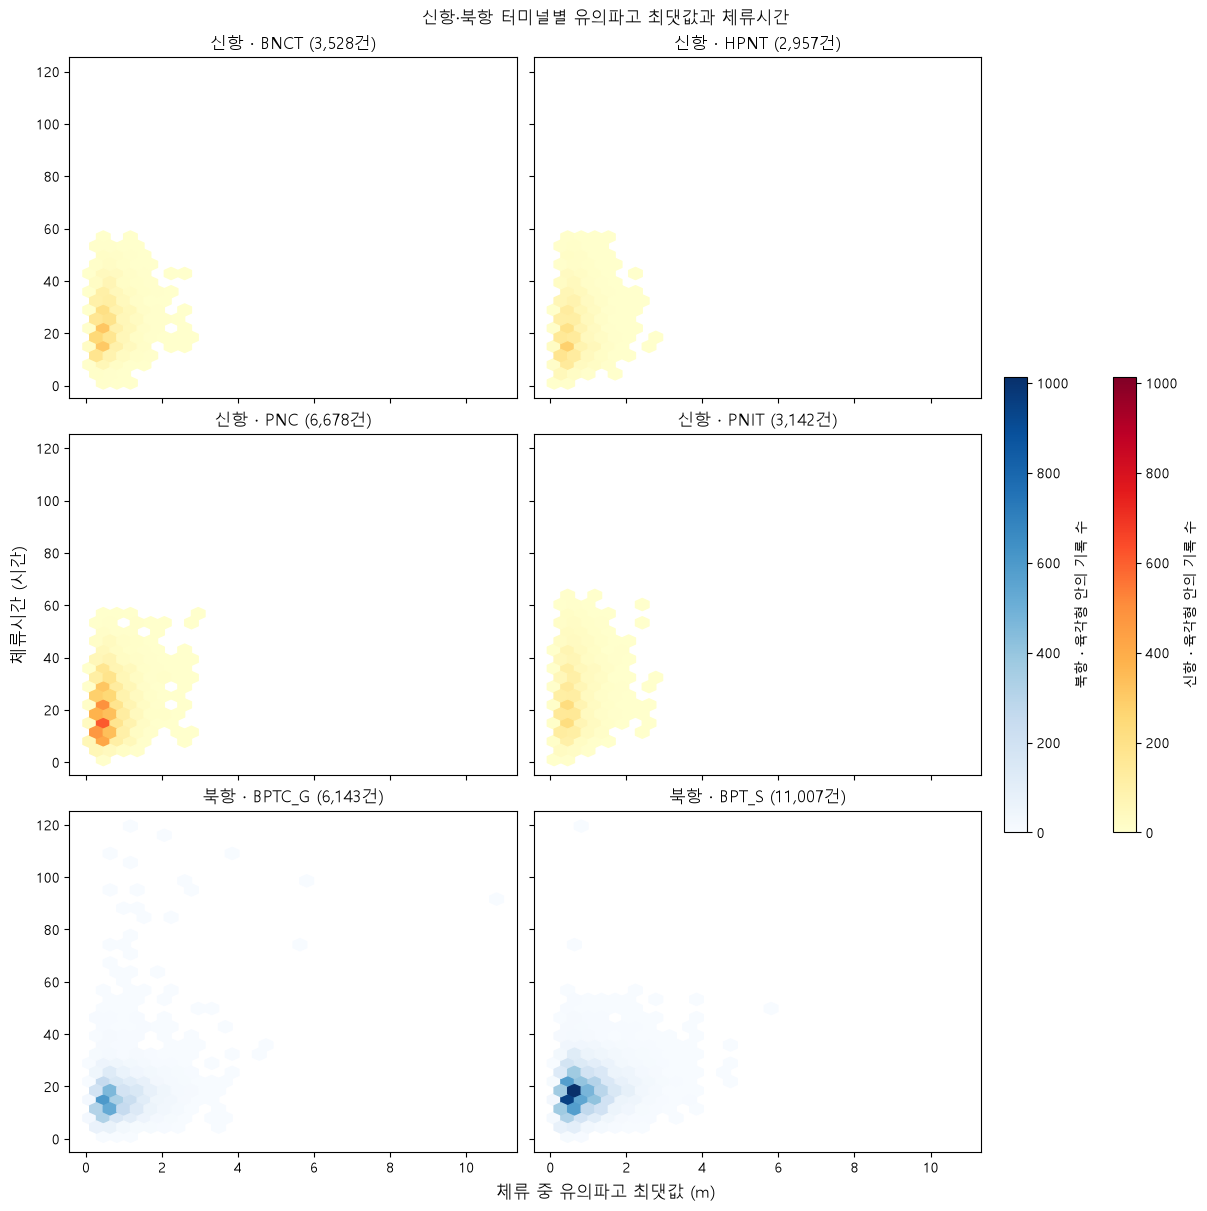

In [34]:
공통범위 = (
    유의파고최대비교[유의파고최대열].min(),
    유의파고최대비교[유의파고최대열].max(),
    유의파고최대비교["체류시간"].min(),
    유의파고최대비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True, sharey=True, layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 유의파고최대비교.loc[
        유의파고최대비교["항만구분"].eq(항만)
        & 유의파고최대비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if not 자료.empty:
        그림 = ax.hexbin(
            자료[유의파고최대열], 자료["체류시간"],
            gridsize=30, extent=공통범위,
            cmap=항만색[항만], mincnt=1,
        )
        항만그림[항만].append(그림)

최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    if not 목록:
        continue

    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    fig.colorbar(
        목록[0], ax=list(axes.flat),
        fraction=0.025, pad=0.025,
        label=f"{항만} · 육각형 안의 기록 수",
    )

fig.suptitle("신항·북항 터미널별 유의파고 최댓값과 체류시간")
fig.supxlabel("체류 중 유의파고 최댓값 (m)")
fig.supylabel("체류시간 (시간)")
그림표시()

신항과 북항 모두 **체류 중 유의파고 최댓값이 1 m 미만이고 체류시간이 10-30시간**인 구간에 기록이 가장 많이 모였다.  
**BPTC_G**에서는 파고가 낮은 구간에서도 80시간을 넘는 체류가 일부 관측됐다.  
높은 파고 구간의 기록은 드물었으며, 유의파고 최댓값이 높아질수록 체류시간이 길어지는 일관된 패턴은 보이지 않았다.

In [35]:
순간파고열 = "체류시간_순간최대파고_최댓값_m"

순간파고비교 = df1[["항만구분", "터미널", 순간파고열, "체류시간"]].copy()

for 열 in [순간파고열, "체류시간"]:
    순간파고비교[열] = pd.to_numeric(
        순간파고비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

순간파고비교 = 순간파고비교.dropna(subset=[순간파고열, "체류시간"])
순간파고비교 = 순간파고비교.loc[
    순간파고비교.set_index(["항만구분", "터미널"]).index.isin(터미널순서)
    & 순간파고비교[순간파고열].ge(0)
].copy()

순간파고비교["파고구간"] = pd.cut(
    순간파고비교[순간파고열],
    bins=[0, 0.5, 1, 1.5, 2, 3, 4, float("inf")],
    labels=["0-0.5", "0.5-1", "1-1.5", "1.5-2", "2-3", "3-4", "4 이상"],
    right=False,
)

순간파고결과 = (
    순간파고비교
    .groupby(["항만구분", "터미널", "파고구간"], observed=True)["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
)

display(순간파고결과.round(2))

기록수  체류시간_중앙값
항만구분 터미널    파고구간                 
북항   BPTC_G 0-0.5   442      13.0
            0.5-1  2560     14.83
            1-1.5  1455     15.17
            1.5-2   800     15.83
            2-3     660      17.0
            3-4     186     17.92
            4 이상     40     21.25
     BPT_S  0-0.5   628     14.88
            0.5-1  4458      17.0
            1-1.5  2693      18.0
            1.5-2  1562      18.0
            2-3    1220     19.29
            3-4     358     20.08
            4 이상     85     24.67
신항   BNCT   0-0.5   417     18.17
            0.5-1  1856     22.33
            1-1.5   816     23.92
            1.5-2   276     25.52
            2-3     142     26.67
            3-4      18     23.57
            4 이상      3      19.5
     HPNT   0-0.5   381      15.0
            0.5-1  1539      19.9
            1-1.5   673      21.9
            1.5-2   239      23.0
            2-3     111      21.0
            3-4      12      20.6
            4 이상      2      16.7
     PNC    0-0.5   898     14.32
            0.5-1  3496     19.04
            1-1.5  1503     21.18
            1.5-2   500     21.33
            2-3     245      24.0
            3-4      29     26.37
            4 이상      5     22.62
     PNIT   0-0.5   336      18.0
            0.5-1  1623      23.0
            1-1.5   766     25.52
            1.5-2   259      27.4
            2-3     140     28.79
            3-4      15      29.4
            4 이상      2     28.25

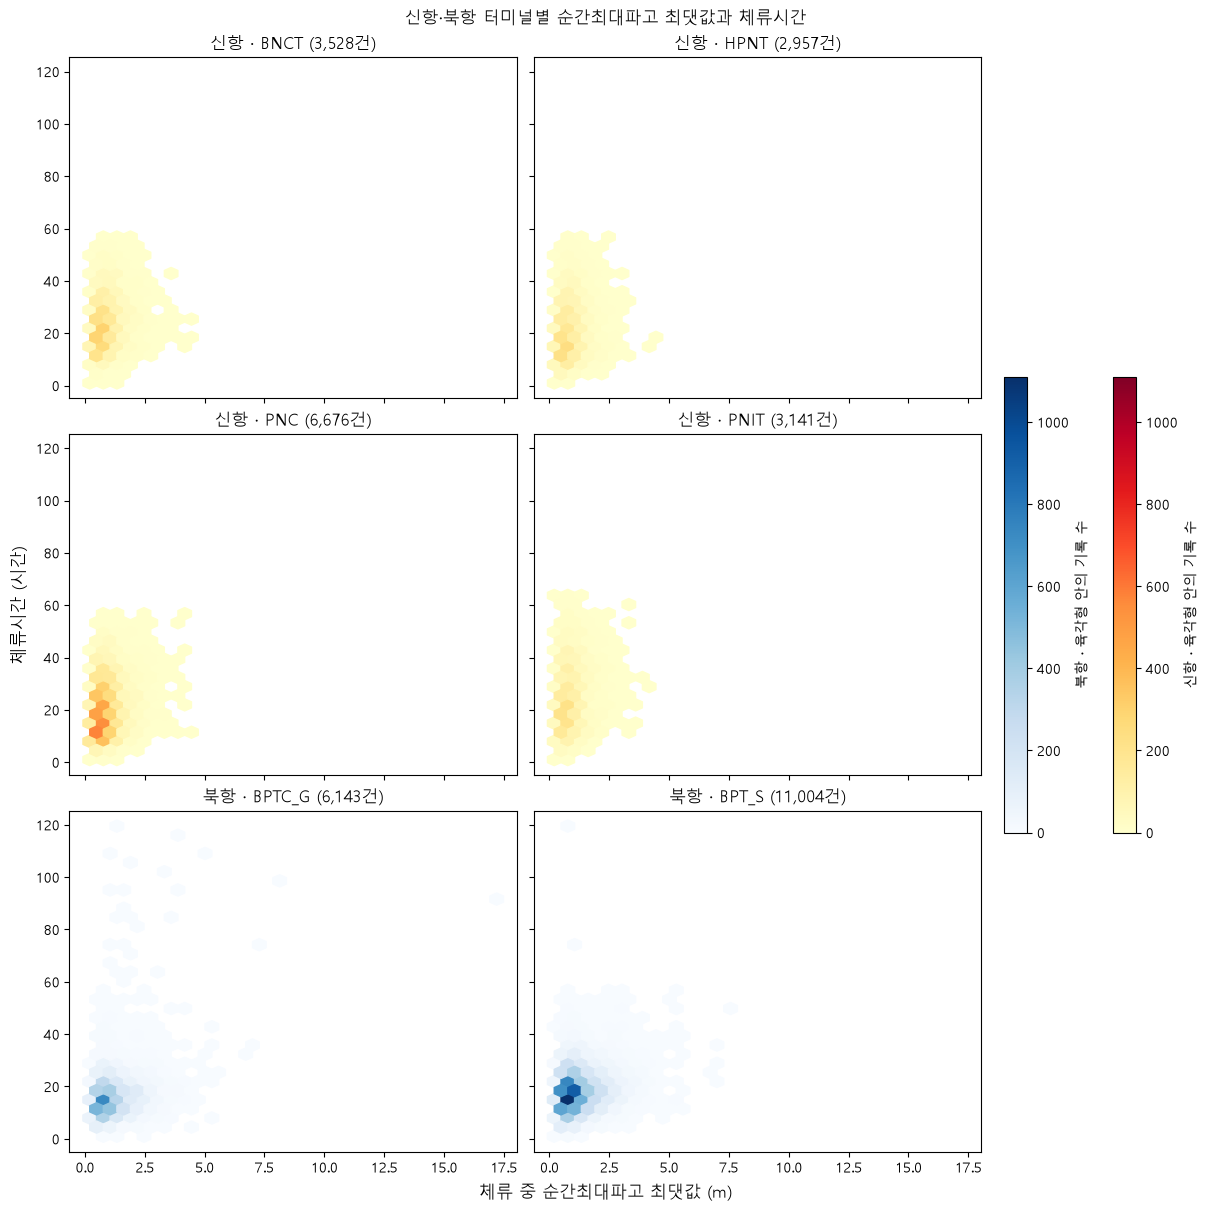

In [36]:
공통범위 = (
    순간파고비교[순간파고열].min(), 순간파고비교[순간파고열].max(),
    순간파고비교["체류시간"].min(), 순간파고비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True, sharey=True, layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 순간파고비교.loc[
        순간파고비교["항만구분"].eq(항만)
        & 순간파고비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if not 자료.empty:
        그림 = ax.hexbin(
            자료[순간파고열], 자료["체류시간"],
            gridsize=30, extent=공통범위,
            cmap=항만색[항만], mincnt=1,
        )
        항만그림[항만].append(그림)

최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    if not 목록:
        continue

    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    fig.colorbar(
        목록[0], ax=list(axes.flat),
        fraction=0.025, pad=0.025,
        label=f"{항만} · 육각형 안의 기록 수",
    )

fig.suptitle("신항·북항 터미널별 순간최대파고 최댓값과 체류시간")
fig.supxlabel("체류 중 순간최대파고 최댓값 (m)")
fig.supylabel("체류시간 (시간)")
그림표시()

신항과 북항 모두 **체류 중 순간최대파고 최댓값 0.5-1.5 m, 체류시간 10-30시간** 구간에 기록이 주로 모였다.  
북항 **BPTC_G**에서는 낮은 파고 구간에서도 80시간을 넘는 체류가 일부 나타났다.  
높은 파고 구간의 관측은 드물었으며, 파고가 높아질수록 체류시간이 길어지는 일관된 패턴은 보이지 않았다.

In [37]:
순간파고중앙열 = "체류시간_순간최대파고_중앙값_m"

순간파고중앙비교 = df1[
    ["항만구분", "터미널", 순간파고중앙열, "체류시간"]
].copy()

for 열 in [순간파고중앙열, "체류시간"]:
    순간파고중앙비교[열] = pd.to_numeric(
        순간파고중앙비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

순간파고중앙비교 = 순간파고중앙비교.dropna(
    subset=[순간파고중앙열, "체류시간"]
)
순간파고중앙비교 = 순간파고중앙비교.loc[
    순간파고중앙비교.set_index(["항만구분", "터미널"]).index.isin(터미널순서)
    & 순간파고중앙비교[순간파고중앙열].ge(0)
].copy()

순간파고중앙비교["파고구간"] = pd.cut(
    순간파고중앙비교[순간파고중앙열],
    bins=[0, 0.5, 1, 1.5, 2, 3, 4, float("inf")],
    labels=["0-0.5", "0.5-1", "1-1.5", "1.5-2", "2-3", "3-4", "4 이상"],
    right=False,
)

순간파고중앙결과 = (
    순간파고중앙비교
    .groupby(["항만구분", "터미널", "파고구간"], observed=True)["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
)

display(순간파고중앙결과.round(2))

기록수  체류시간_중앙값
항만구분 터미널    파고구간                 
북항   BPTC_G 0-0.5  1463      15.0
            0.5-1  2967     15.17
            1-1.5  1079     15.08
            1.5-2   434     15.46
            2-3     186     15.25
            3-4      13      15.0
            4 이상      1      31.0
     BPT_S  0-0.5  2581     17.17
            0.5-1  5345     17.67
            1-1.5  1957      17.5
            1.5-2   752     18.33
            2-3     343      19.0
            3-4      22      21.0
            4 이상      4     23.62
신항   BNCT   0-0.5  1662     21.88
            0.5-1  1532     23.47
            1-1.5   277     23.28
            1.5-2    50     20.98
            2-3       7     19.63
     HPNT   0-0.5  1320      20.0
            0.5-1  1328      20.0
            1-1.5   265      18.0
            1.5-2    37      17.1
            2-3       7      19.6
     PNC    0-0.5  3069     19.18
            0.5-1  2963     19.77
            1-1.5   541     18.13
            1.5-2    91      19.0
            2-3      12     14.48
     PNIT   0-0.5  1404     23.58
            0.5-1  1448     23.56
            1-1.5   246     23.21
            1.5-2    41     21.83
            2-3       2     13.12

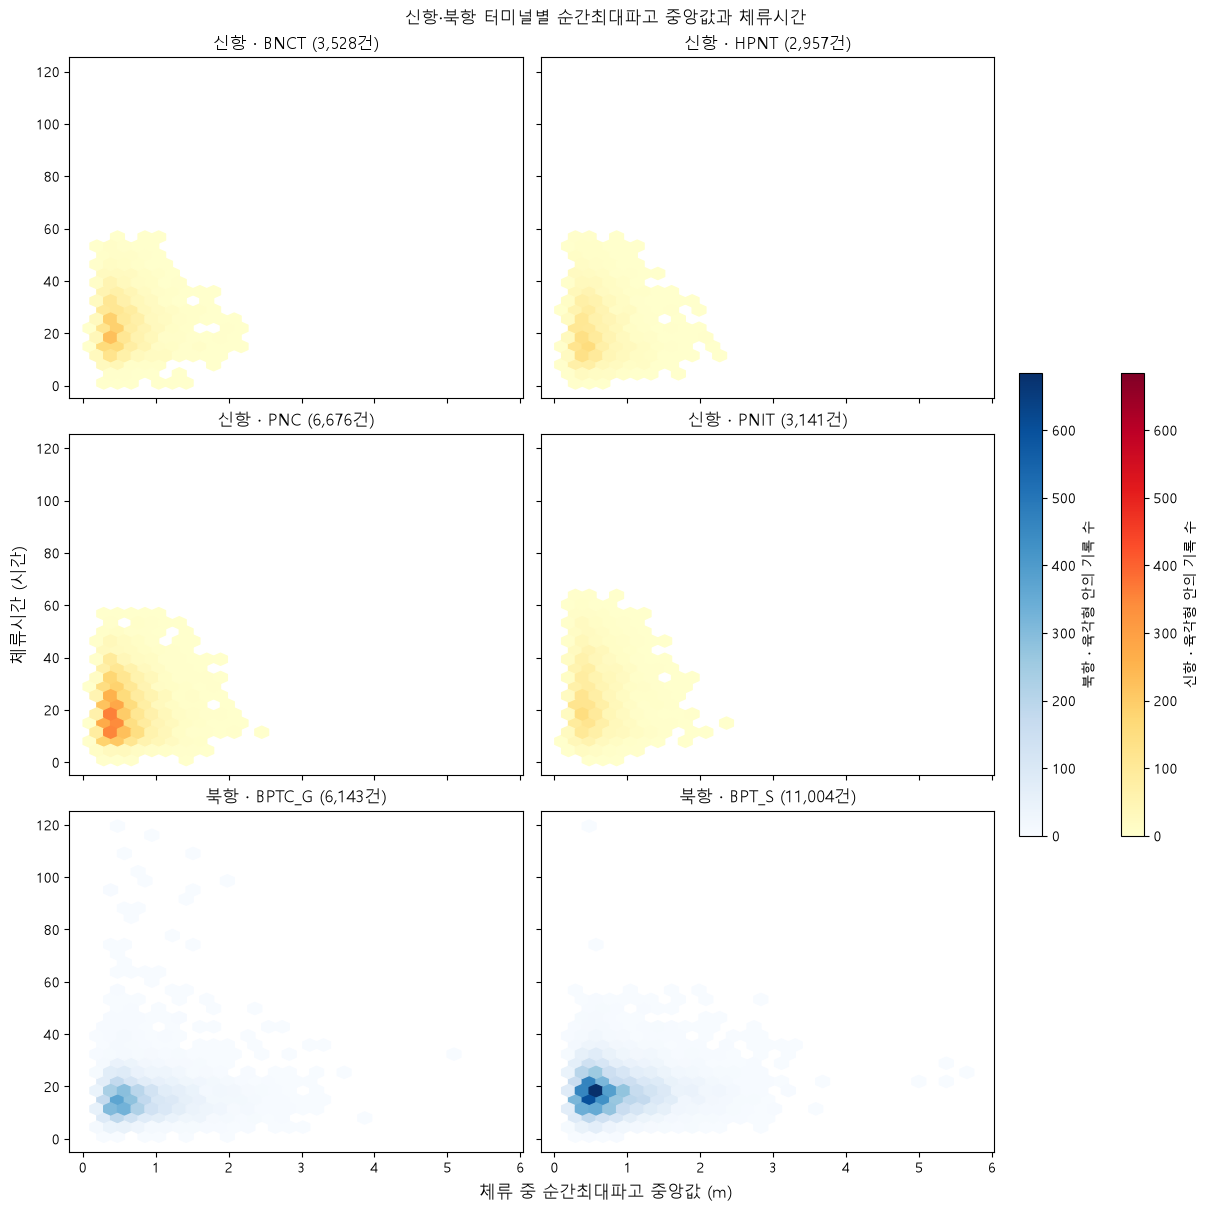

In [38]:
공통범위 = (
    순간파고중앙비교[순간파고중앙열].min(),
    순간파고중앙비교[순간파고중앙열].max(),
    순간파고중앙비교["체류시간"].min(),
    순간파고중앙비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True, sharey=True, layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 순간파고중앙비교.loc[
        순간파고중앙비교["항만구분"].eq(항만)
        & 순간파고중앙비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if not 자료.empty:
        그림 = ax.hexbin(
            자료[순간파고중앙열], 자료["체류시간"],
            gridsize=30, extent=공통범위,
            cmap=항만색[항만], mincnt=1,
        )
        항만그림[항만].append(그림)

최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    if not 목록:
        continue

    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    fig.colorbar(
        목록[0], ax=list(axes.flat),
        fraction=0.025, pad=0.025,
        label=f"{항만} · 육각형 안의 기록 수",
    )

fig.suptitle("신항·북항 터미널별 순간최대파고 중앙값과 체류시간")
fig.supxlabel("체류 중 순간최대파고 중앙값 (m)")
fig.supylabel("체류시간 (시간)")
그림표시()

신항과 북항 모두 **체류 중 순간최대파고 중앙값 0.3-0.8 m, 체류시간 10-30시간** 구간에 기록이 주로 모였다.  
북항 **BPTC_G**에서는 파고 중앙값이 **1 m 미만**인 경우에도 80시간을 넘는 체류가 일부 관측됐다.  
파고 중앙값이 **2 m 이상**인 기록은 드물었고, 파고가 높아질수록 체류시간이 길어지는 일관된 패턴은 보이지 않았다.

In [39]:
시정열 = "체류시간_시정_최솟값_10m"
시정비교 = df1[["항만구분", "터미널", 시정열, "체류시간"]].copy()

for 열 in [시정열, "체류시간"]:
    시정비교[열] = pd.to_numeric(
        시정비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

시정비교 = 시정비교.dropna(subset=[시정열, "체류시간"])
시정비교 = 시정비교.loc[
    시정비교.set_index(["항만구분", "터미널"]).index.isin(터미널순서)
    & 시정비교[시정열].ge(0)
].copy()

시정비교["시정구간"] = pd.cut(
    시정비교[시정열],
    bins=[0, 100, 200, 500, 1000, 2000, 5000, float("inf")],
    labels=["0-100", "100-200", "200-500", "500-1000",
            "1000-2000", "2000-5000", "5000 이상"],
    right=False,
)

시정결과 = (
    시정비교.groupby(["항만구분", "터미널", "시정구간"], observed=True)["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
)

display(시정결과.round(2))

기록수  체류시간_중앙값
항만구분 터미널    시정구간                     
북항   BPTC_G 0-100       141     18.25
            100-200     235     17.17
            200-500     505     16.33
            500-1000    636      16.0
            1000-2000  1434     15.33
            2000-5000  2694     14.83
            5000 이상     633      13.5
     BPT_S  0-100       300     20.92
            100-200     456     19.08
            200-500     959      19.5
            500-1000   1292     18.21
            1000-2000  2546     18.17
            2000-5000  4713      17.0
            5000 이상    1005      15.0
신항   BNCT   0-100       120     27.19
            100-200     152     27.25
            200-500     344     25.45
            500-1000    441      23.1
            1000-2000   841     22.78
            2000-5000  1417     21.83
            5000 이상     242     17.88
     HPNT   0-100        87      28.0
            100-200     136      24.7
            200-500     288      23.0
            500-1000    368      20.6
            1000-2000   682      20.9
            2000-5000  1175      19.0
            5000 이상     247     13.97
     PNC    0-100       198     25.71
            100-200     299     24.82
            200-500     590     22.06
            500-1000    764     21.87
            1000-2000  1522     20.22
            2000-5000  2724      18.0
            5000 이상     624     14.32
     PNIT   0-100       100     29.33
            100-200     157      29.0
            200-500     305     29.33
            500-1000    376      24.9
            1000-2000   766      24.0
            2000-5000  1234     21.96
            5000 이상     222      16.0

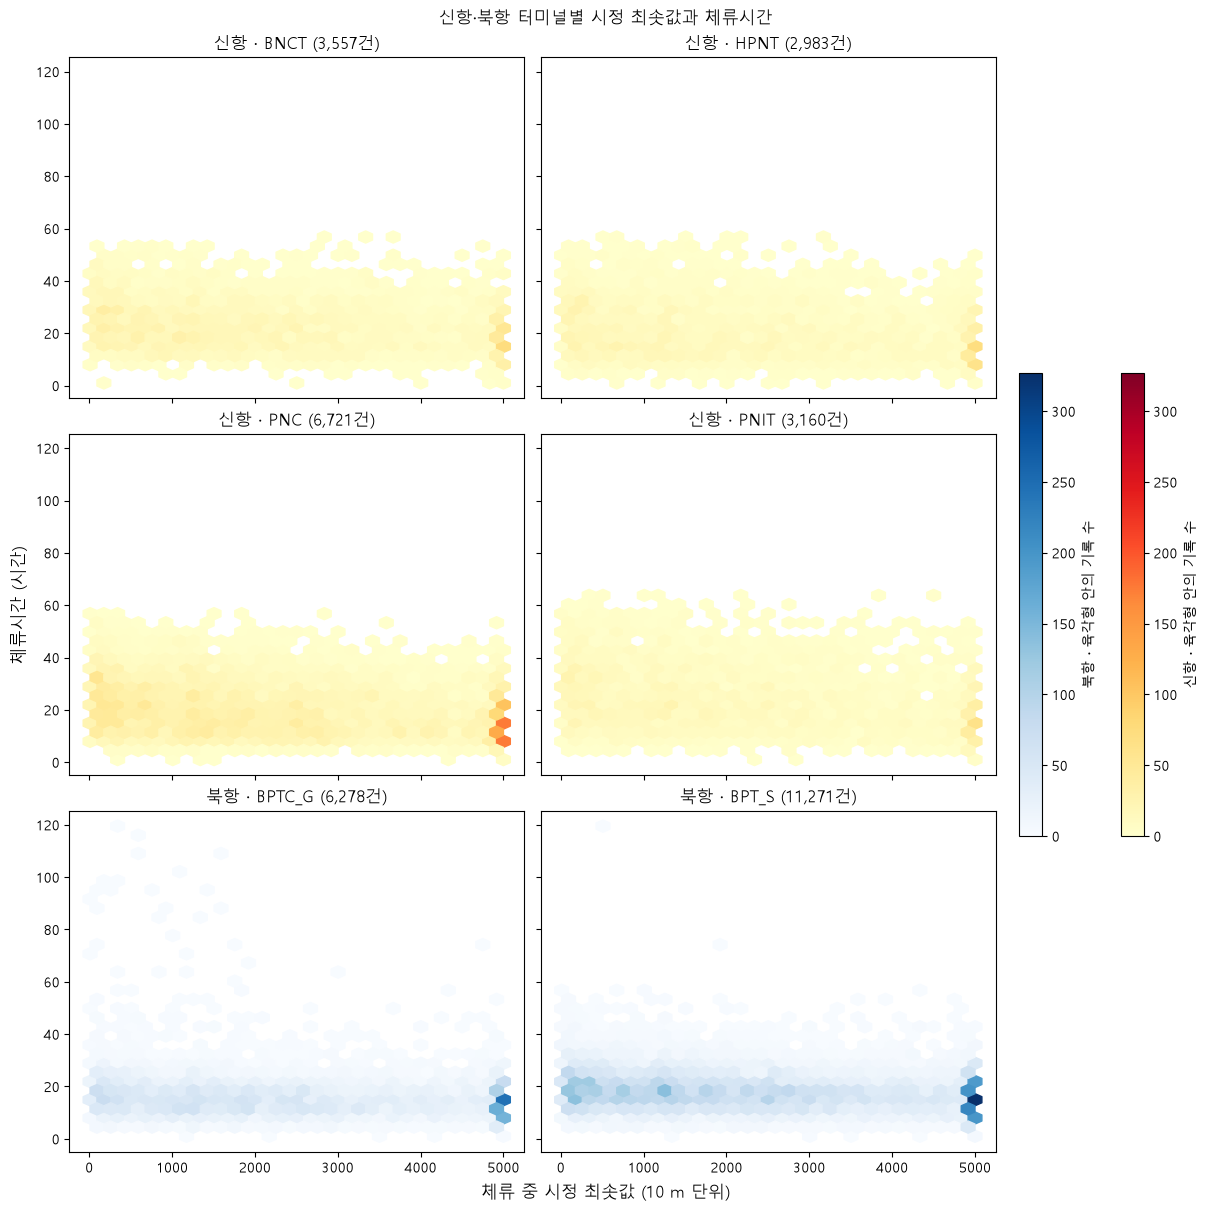

In [40]:
시정열 = "체류시간_시정_최솟값_10m"

공통범위 = (
    시정비교[시정열].min(), 시정비교[시정열].max(),
    시정비교["체류시간"].min(), 시정비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True, sharey=True, layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 시정비교.loc[
        시정비교["항만구분"].eq(항만)
        & 시정비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if not 자료.empty:
        그림 = ax.hexbin(
            자료[시정열], 자료["체류시간"],
            gridsize=30, extent=공통범위,
            cmap=항만색[항만], mincnt=1,
        )
        항만그림[항만].append(그림)

최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    if not 목록:
        continue

    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    fig.colorbar(
        목록[0], ax=list(axes.flat),
        fraction=0.025, pad=0.025,
        label=f"{항만} · 육각형 안의 기록 수",
    )

fig.suptitle("신항·북항 터미널별 시정 최솟값과 체류시간")
fig.supxlabel("체류 중 시정 최솟값 (10 m 단위)")
fig.supylabel("체류시간 (시간)")
그림표시()

신항과 북항 모두 **체류 중 시정 최솟값은 약 0-5,000(10 m 단위)**에 걸쳐 분포했고, 체류시간은 **10-30시간** 구간에 주로 모였다.  
**BPT_S와 PNC**에서는 시정 **5,000 부근**에 기록이 집중됐다.  
**BPTC_G**에서는 시정이 낮은 구간에서도 80시간을 넘는 체류가 일부 나타났으며, 시정이 낮아질수록 체류시간이 길어지는 일관된 패턴은 보이지 않았다.

In [41]:
시정중앙열 = "체류시간_시정_중앙값_10m"
시정중앙비교 = df1[
    ["항만구분", "터미널", 시정중앙열, "체류시간"]
].copy()

for 열 in [시정중앙열, "체류시간"]:
    시정중앙비교[열] = pd.to_numeric(
        시정중앙비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

시정중앙비교 = 시정중앙비교.dropna(subset=[시정중앙열, "체류시간"])
시정중앙비교 = 시정중앙비교.loc[
    시정중앙비교.set_index(["항만구분", "터미널"]).index.isin(터미널순서)
    & 시정중앙비교[시정중앙열].ge(0)
].copy()

시정중앙비교["시정구간"] = pd.cut(
    시정중앙비교[시정중앙열],
    bins=[0, 100, 200, 500, 1000, 2000, 5000, float("inf")],
    labels=["0-100", "100-200", "200-500", "500-1000",
            "1000-2000", "2000-5000", "5000 이상"],
    right=False,
)

시정중앙결과 = (
    시정중앙비교
    .groupby(["항만구분", "터미널", "시정구간"], observed=True)["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
)

display(시정중앙결과.round(2))

기록수  체류시간_중앙값
항만구분 터미널    시정구간                     
북항   BPTC_G 100-200      17      13.0
            200-500      98      14.0
            500-1000    285      15.0
            1000-2000   821     15.25
            2000-5000  3179      15.0
            5000 이상    1878      15.5
     BPT_S  100-200      17     14.17
            200-500     171      16.0
            500-1000    492     17.67
            1000-2000  1533      18.0
            2000-5000  5728      18.0
            5000 이상    3330     17.33
신항   BNCT   100-200       7      16.9
            200-500      47     19.65
            500-1000    142     23.62
            1000-2000   463     20.92
            2000-5000  1851     22.33
            5000 이상    1047     23.83
     HPNT   100-200       3      15.9
            200-500      42     17.55
            500-1000    135      19.8
            1000-2000   432      18.7
            2000-5000  1519      20.3
            5000 이상     852     19.83
     PNC    100-200       7      14.0
            200-500      85     14.97
            500-1000    296     18.95
            1000-2000   898     19.91
            2000-5000  3348      19.9
            5000 이상    2087     18.23
     PNIT   100-200       3     17.83
            200-500      33     15.92
            500-1000    144     22.31
            1000-2000   417      23.5
            2000-5000  1628     24.46
            5000 이상     935      22.5

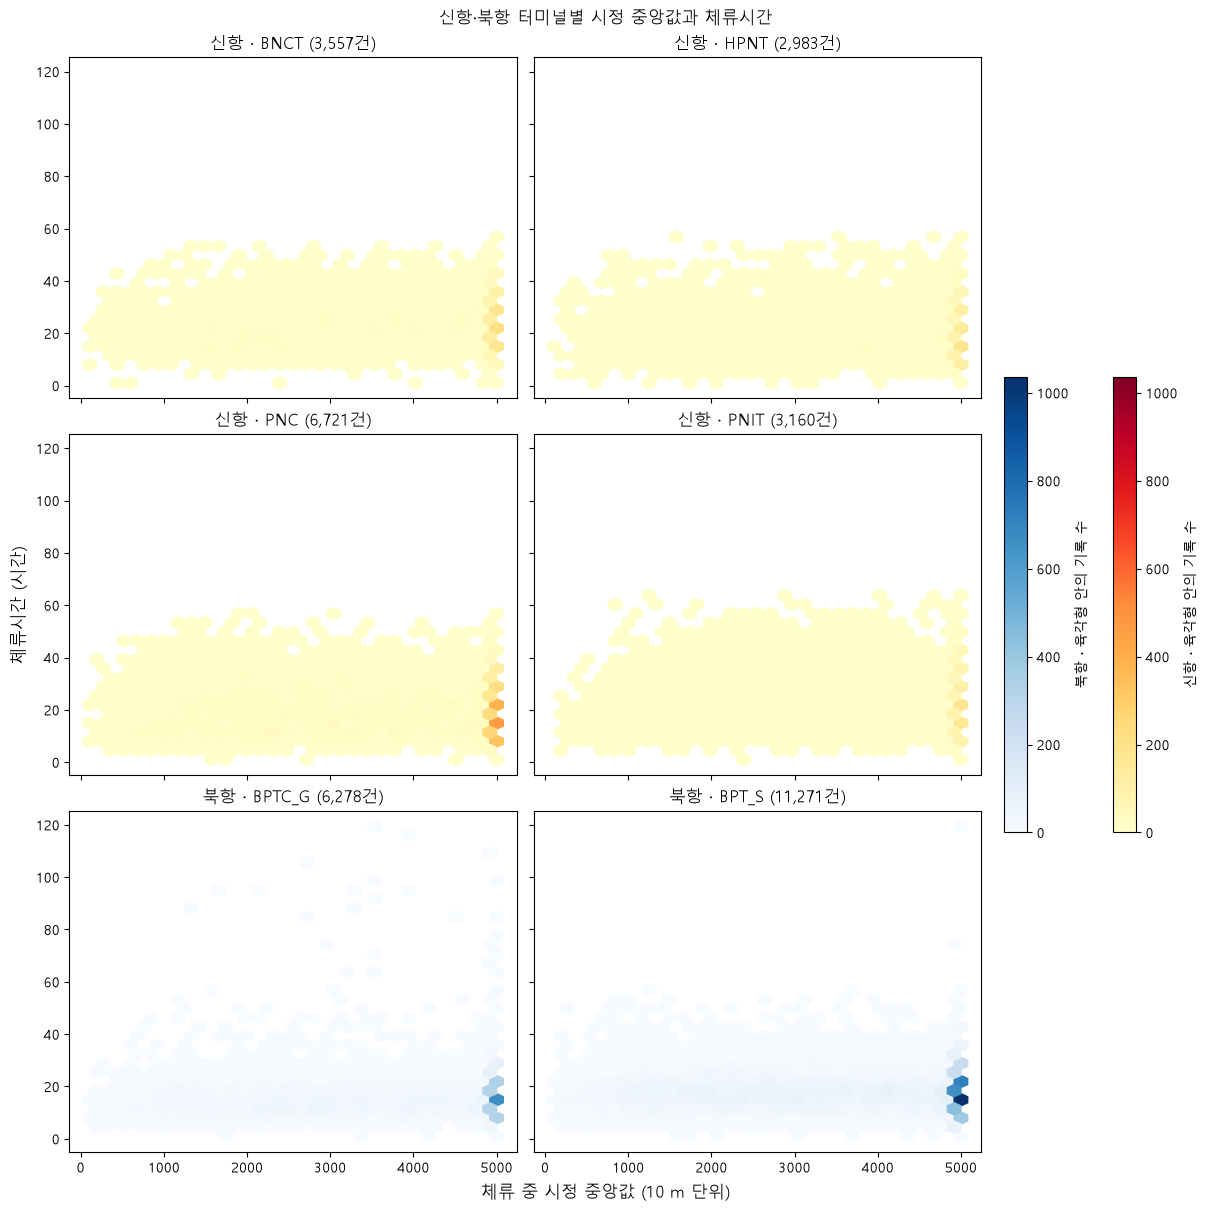

In [42]:
공통범위 = (
    시정중앙비교[시정중앙열].min(), 시정중앙비교[시정중앙열].max(),
    시정중앙비교["체류시간"].min(), 시정중앙비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True, sharey=True, layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 시정중앙비교.loc[
        시정중앙비교["항만구분"].eq(항만)
        & 시정중앙비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if not 자료.empty:
        그림 = ax.hexbin(
            자료[시정중앙열], 자료["체류시간"],
            gridsize=30, extent=공통범위,
            cmap=항만색[항만], mincnt=1,
        )
        항만그림[항만].append(그림)

최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    if not 목록:
        continue

    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    fig.colorbar(
        목록[0], ax=list(axes.flat),
        fraction=0.025, pad=0.025,
        label=f"{항만} · 육각형 안의 기록 수",
    )

fig.suptitle("신항·북항 터미널별 시정 중앙값과 체류시간")
fig.supxlabel("체류 중 시정 중앙값 (10 m 단위)")
fig.supylabel("체류시간 (시간)")
그림표시()

신항과 북항 모두 **체류 중 시정 중앙값이 5,000 부근(10 m 단위)**에 기록이 집중됐으며, 특히 BPT_S에서 두드러졌다.
이 구간의 체류시간은 주로 10-30시간이었고, BPTC_G에서는 여러 시정 구간에서 80시간을 넘는 체류가 일부 나타났다.
시정이 낮아질수록 체류시간이 길어지는 일관된 패턴은 보이지 않았다.

In [43]:
특보열 = "체류시간_특보노출시간(h)"
if 특보열 not in df1.columns:
    특보열 = "체류시간_특보노출시간"

특보비교 = df1[["항만구분", "터미널", 특보열, "체류시간"]].copy()

for 열 in [특보열, "체류시간"]:
    특보비교[열] = pd.to_numeric(
        특보비교[열].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    )

특보비교 = 특보비교.dropna(subset=[특보열, "체류시간"])
특보비교 = 특보비교.loc[
    특보비교.set_index(["항만구분", "터미널"]).index.isin(터미널순서)
    & 특보비교[특보열].gt(0)
].copy()

특보비교["노출구간"] = pd.cut(
    특보비교[특보열],
    bins=[0, 6, 12, 24, 48, float("inf")],
    labels=["0 초과-6", "6-12", "12-24", "24-48", "48 이상"],
    right=False,
)

특보결과 = (
    특보비교.groupby(["항만구분", "터미널", "노출구간"], observed=True)
    ["체류시간"]
    .agg(기록수="size", 체류시간_중앙값="median")
)

display(특보결과.round(2))

기록수  체류시간_중앙값
항만구분 터미널    노출구간                 
북항   BPTC_G 0 초과-6  204     14.54
            6-12    290      15.0
            12-24   278     18.71
            24-48    33      37.0
            48 이상     3     91.92
     BPT_S  0 초과-6  362     17.75
            6-12    440     17.58
            12-24   564     20.67
            24-48   130     31.42
신항   BNCT   0 초과-6  129     22.25
            6-12    128     23.46
            12-24   208     23.91
            24-48    79     33.22
     HPNT   0 초과-6  120      18.0
            6-12    131     20.73
            12-24   155      23.0
            24-48    44      32.8
     PNC    0 초과-6  253     19.83
            6-12    304     18.52
            12-24   344     23.25
            24-48    87     31.42
     PNIT   0 초과-6  107     23.67
            6-12    146      26.3
            12-24   186     29.29
            24-48    61     40.42
            48 이상     1     49.17

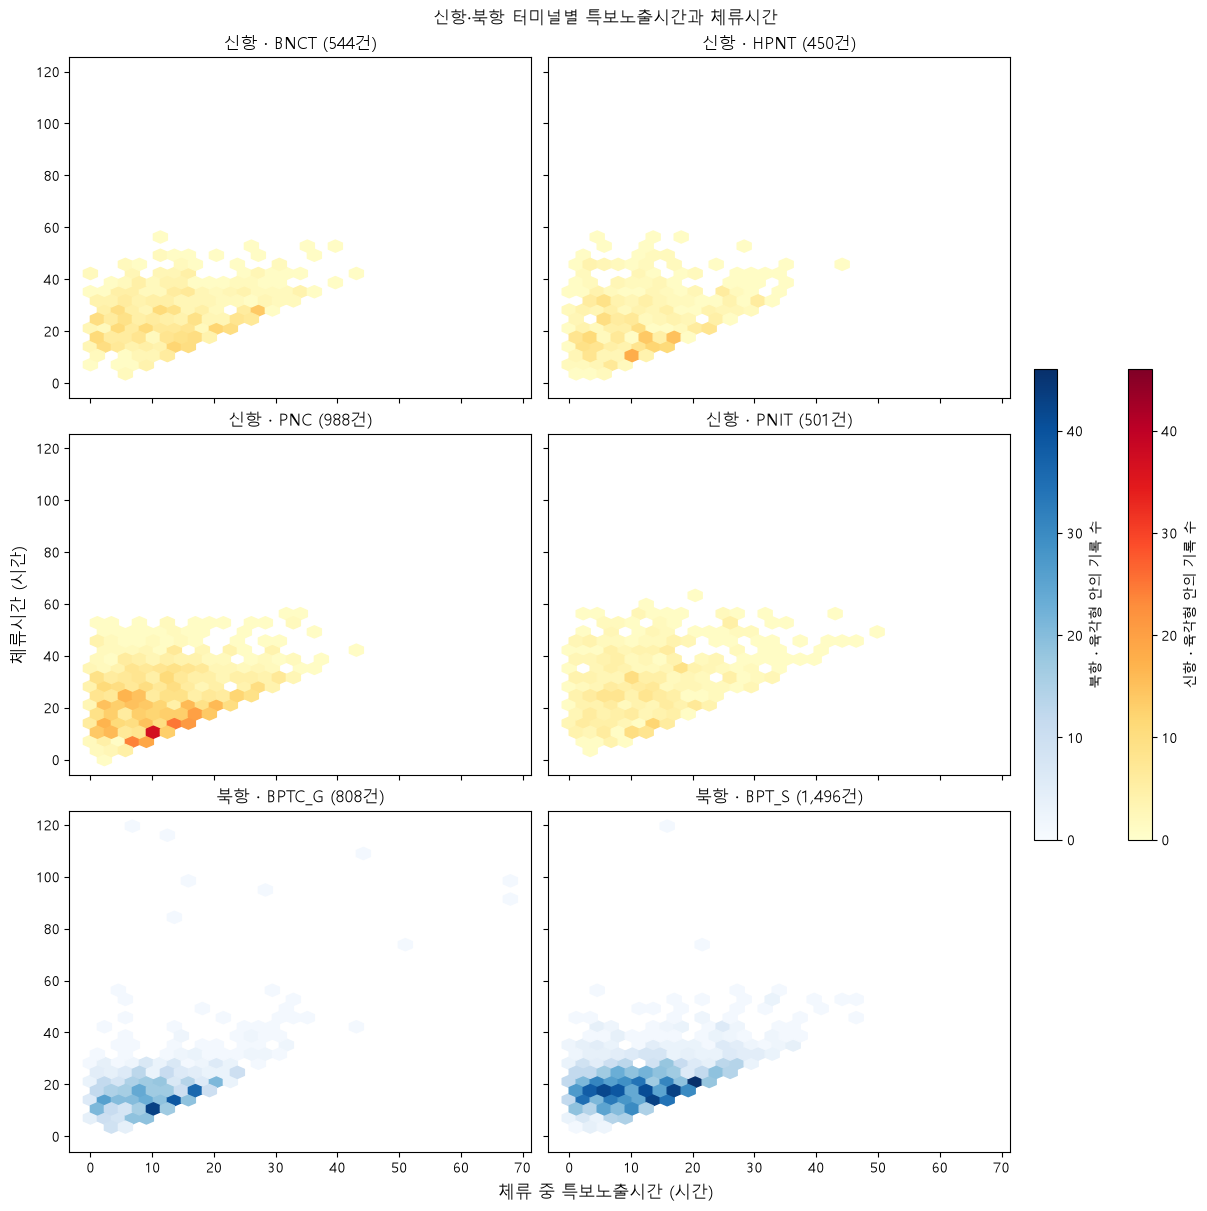

In [44]:
공통범위 = (
    0, 특보비교[특보열].max(),
    0, 특보비교["체류시간"].max(),
)

fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True, sharey=True, layout="constrained",
)

항만색 = {"신항": "YlOrRd", "북항": "Blues"}
항만그림 = {"신항": [], "북항": []}

for ax, (항만, 터미널) in zip(axes.flat, 터미널순서):
    자료 = 특보비교.loc[
        특보비교["항만구분"].eq(항만)
        & 특보비교["터미널"].eq(터미널)
    ]
    ax.set_title(f"{항만} · {터미널} ({len(자료):,}건)")

    if not 자료.empty:
        그림 = ax.hexbin(
            자료[특보열], 자료["체류시간"],
            gridsize=30, extent=공통범위,
            cmap=항만색[항만], mincnt=1,
        )
        항만그림[항만].append(그림)

최대건수 = max(
    (그림.get_array().max() for 목록 in 항만그림.values() for 그림 in 목록),
    default=1,
)

for 항만, 목록 in 항만그림.items():
    if not 목록:
        continue

    for 그림 in 목록:
        그림.set_clim(0, 최대건수)

    fig.colorbar(
        목록[0], ax=list(axes.flat),
        fraction=0.025, pad=0.025,
        label=f"{항만} · 육각형 안의 기록 수",
    )

fig.suptitle("신항·북항 터미널별 특보노출시간과 체류시간")
fig.supxlabel("체류 중 특보노출시간 (시간)")
fig.supylabel("체류시간 (시간)")
그림표시()

특보에 노출된 기록은 신항과 북항 모두 **노출시간 0-20시간, 체류시간 10-30시간** 구간에 주로 모였다.  
북항 **BPTC_G**에서는 **80시간을 넘는 체류**가 일부 나타났고, 그중에는 특보노출시간이 짧은 기록도 있었다.  
특보노출시간은 전체 체류시간의 일부이므로, **특보로 인한 체류 지연을 추정하려면** 작업량과 터미널 등 다른 조건을 함께 고려해야 한다.

## 터미널별 총톤수 및 작업량을 고려한 기상 분석 비교

In [45]:
# 터미널별 선박 규모의 분포를 기록 수와 비율로 확인한다.
톤수자료 = df1[["터미널", "총톤수"]].copy()
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]

구간 = pd.cut(
    톤수자료["총톤수"],
    bins=[0, 5000, 10000, 20000, 40000, 80000,
          100000, 150000, 200000, float("inf")],
    labels=["0-5천", "5천-1만", "1만-2만", "2만-4만", "4만-8만",
            "8만-10만", "10만-15만", "15만-20만", "20만 이상"],
    right=False,
)

건수 = pd.crosstab(구간, 톤수자료["터미널"], dropna=False)
건수 = 건수.reindex(columns=터미널목록, fill_value=0)

# 각 터미널에서 총톤수 구간에 집계된 기록을 기준으로 비율을 계산한다.
비율 = 건수.div(건수.sum().replace(0, float("nan"))).mul(100).round(1)

display(건수.astype(str) + " (" + 비율.astype(str) + "%)")

터미널,BNCT,HPNT,PNC,PNIT,BPTC_G,BPT_S
총톤수,,,,,,
0-5천,0 (0.0%),9 (0.3%),1 (0.0%),25 (0.8%),152 (2.4%),977 (8.7%)
5천-1만,185 (5.2%),410 (13.7%),894 (13.3%),129 (4.1%),4267 (67.9%),7811 (69.2%)
1만-2만,469 (13.2%),259 (8.7%),571 (8.5%),262 (8.3%),1370 (21.8%),1607 (14.2%)
2만-4만,214 (6.0%),701 (23.5%),961 (14.3%),531 (16.8%),322 (5.1%),729 (6.5%)
4만-8만,696 (19.6%),573 (19.2%),1784 (26.5%),589 (18.6%),171 (2.7%),155 (1.4%)
8만-10만,702 (19.7%),255 (8.5%),1244 (18.5%),558 (17.7%),1 (0.0%),0 (0.0%)
10만-15만,866 (24.3%),674 (22.6%),614 (9.1%),804 (25.4%),0 (0.0%),1 (0.0%)
15만-20만,370 (10.4%),95 (3.2%),440 (6.5%),252 (8.0%),0 (0.0%),0 (0.0%)
20만 이상,57 (1.6%),9 (0.3%),217 (3.2%),11 (0.3%),0 (0.0%),0 (0.0%)


- 모든 터미널에서 비교할 기록이 있는 총톤수 1만 이상 - 2만 미만을 살펴본 후, 비슷한 선박 규모에서도 작업량은 다를 수 있어 터미널별 작업량 분포 확인이 필요하다.

In [46]:
비교자료 = df1.loc[df1["총톤수"].between(10_000, 20_000, inclusive="left")].copy()
터미널별 = 비교자료.groupby("터미널")["총작업량"]

작업량표 = 터미널별.agg(
    전체건수="size",
    작업량0_건수=lambda s: s.eq(0).sum(),
    작업량_25=lambda s: s[s.gt(0)].quantile(0.25),
    작업량_중앙값=lambda s: s[s.gt(0)].median(),
    작업량_75=lambda s: s[s.gt(0)].quantile(0.75),
).reindex(터미널목록)

display(작업량표.round(1))

,전체건수,작업량0_건수,작업량_25,작업량_중앙값,작업량_75
터미널,,,,,
BNCT,469,1,471.8,635.0,840.2
HPNT,259,1,508.2,806.5,1098.5
PNC,571,0,390.0,615.0,859.5
PNIT,262,0,336.5,509.5,686.5
BPTC_G,1370,14,453.8,661.0,1051.0
BPT_S,1607,1,684.2,909.0,1139.0


- 총톤수 1만-2만 미만에서도 작업량 중앙값은 PNIT 509.5, BPT_S 909.0으로 약 1.8배 차이가 나타났다.
- 따라서 총톤수만 맞춰 체류시간을 비교하면 작업량 차이가 함께 반영되므로, 작업량도 유사한 조건으로 맞출 필요가 있다.
- 우선 총작업량 600-800을 비교 범위로 설정했으며, 터미널별로 47-280건이 확보되어 탐색적 비교에 활용하였다.

In [47]:
# 총톤수 1만 - 2만 미만 구간에서 총작업량이 600-800 기록을 대상으로 터미널별 기록 수와 작업량, 총톤수 중앙값을 확인한다.
후보 = 비교자료.loc[비교자료["총작업량"].between(600, 800)]

display(
    후보.groupby("터미널").agg(
        기록수=("체류시간", "size"),
        총작업량_중앙값=("총작업량", "median"),
        총톤수_중앙값=("총톤수", "median"),
    ).reindex(터미널목록).round(1)
)

,기록수,총작업량_중앙값,총톤수_중앙값
터미널,,,
BNCT,126,686.0,18485.0
HPNT,47,712.0,18123.0
PNC,130,700.5,18321.0
PNIT,54,686.0,18334.0
BPTC_G,250,675.0,17564.0
BPT_S,280,714.0,18051.0


- 총작업량 600-800으로 제한한 결과, 터미널별로 47-280건의 비교 자료가 확보되었다.
- 작업량 중앙값은 675-714, 총톤수 중앙값은 17,564-18,485로 나타나 비교대상의 작업량과 선박 규모가 이전보다 유사해졌다.

In [48]:
## 총톤수 1만 이상-2만 미만, 총작업량 600-800 조건에서 터미널별 체류시간을 비교

결과 = 후보.groupby("터미널").agg(
    기록수=("체류시간", "size"),
    작업량_중앙값=("총작업량", "median"),
    총톤수_중앙값=("총톤수", "median"),
    체류시간_25=("체류시간", lambda x: x.quantile(0.25)),
    체류시간_중앙값=("체류시간", "median"),
    체류시간_75=("체류시간", lambda x: x.quantile(0.75)),
).reindex(터미널목록)

display(결과.round(2))

,기록수,작업량_중앙값,총톤수_중앙값,체류시간_25,체류시간_중앙값,체류시간_75
터미널,,,,,,
BNCT,126,686.0,18485.0,14.54,17.85,20.95
HPNT,47,712.0,18123.0,11.15,13.00,15.00
PNC,130,700.5,18321.0,12.23,14.09,15.80
PNIT,54,686.0,18334.0,14.00,14.96,17.00
BPTC_G,250,675.0,17564.0,15.50,17.67,20.33
BPT_S,280,714.0,18051.0,17.00,19.75,23.04


- 체류시간 중앙값은 HPNT 13.00시간, PNC 14.09시간, PNIT 14.96시간, BPTC_G 17.67시간, BNCT 17.85시간, BPT_S 19.75시간 순으로 나타났다.
- 가운데 50%의 체류시간 범위는 PNIT가 14.00-17.00시간으로 가장 좁고, BNCT가 14.54-20.95시간으로 가장 넓었다.
- 유사한 선박 규모·작업량 조건에서도 터미널 간 차이가 나타났으나, 이를 작업 효율 차이로 단정하기 전에 기상·선사 등의 구성 차이를 확인해야 한다.

In [49]:
# 동일한 총톤수·작업량 조건에서 풍속구간에 따른 체류시간 차이를 터미널별로 풍속 중앙값 비교

풍속비교 = 후보.copy()

풍속비교["풍속구간"] = pd.cut(
    풍속비교["체류시간_풍속_중앙값_mps"],
    bins=[0, 2, 4, float("inf")],
    labels=["0-2 미만", "2-4 미만", "4 이상"],
    right=False,
)

풍속결과 = 풍속비교.groupby(
    ["터미널", "풍속구간"], observed=False
).agg(
    기록수=("체류시간", "count"),
    작업량_중앙값=("총작업량", "median"),
    총톤수_중앙값=("총톤수", "median"),
    체류시간_중앙값=("체류시간", "median"),
)

display(풍속결과.round(2))

기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    풍속구간                                   
BNCT   0-2 미만   70    704.0  18406.0     18.99
       2-4 미만   49    661.0  18485.0     15.62
       4 이상      6    661.5  18406.0     19.83
BPTC_G 0-2 미만  136    674.0  17230.0     17.21
       2-4 미만  101    675.0  18064.0     18.00
       4 이상     12    698.0  17363.0     21.58
BPT_S  0-2 미만  151    713.0  18064.0     19.00
       2-4 미만  116    718.5  18051.0     20.00
       4 이상     13    675.0  18064.0     20.00
HPNT   0-2 미만   28    726.5  18104.0     13.40
       2-4 미만   15    691.0  18812.0     11.80
       4 이상      4    751.0  15943.5     14.28
PNC    0-2 미만   68    698.5  18321.0     14.05
       2-4 미만   54    705.0  18190.0     14.22
       4 이상      7    702.0  18826.0     12.22
PNIT   0-2 미만   26    694.5  18334.0     15.00
       2-4 미만   25    674.0  18334.0     14.83
       4 이상      2    736.5  17568.5     18.15

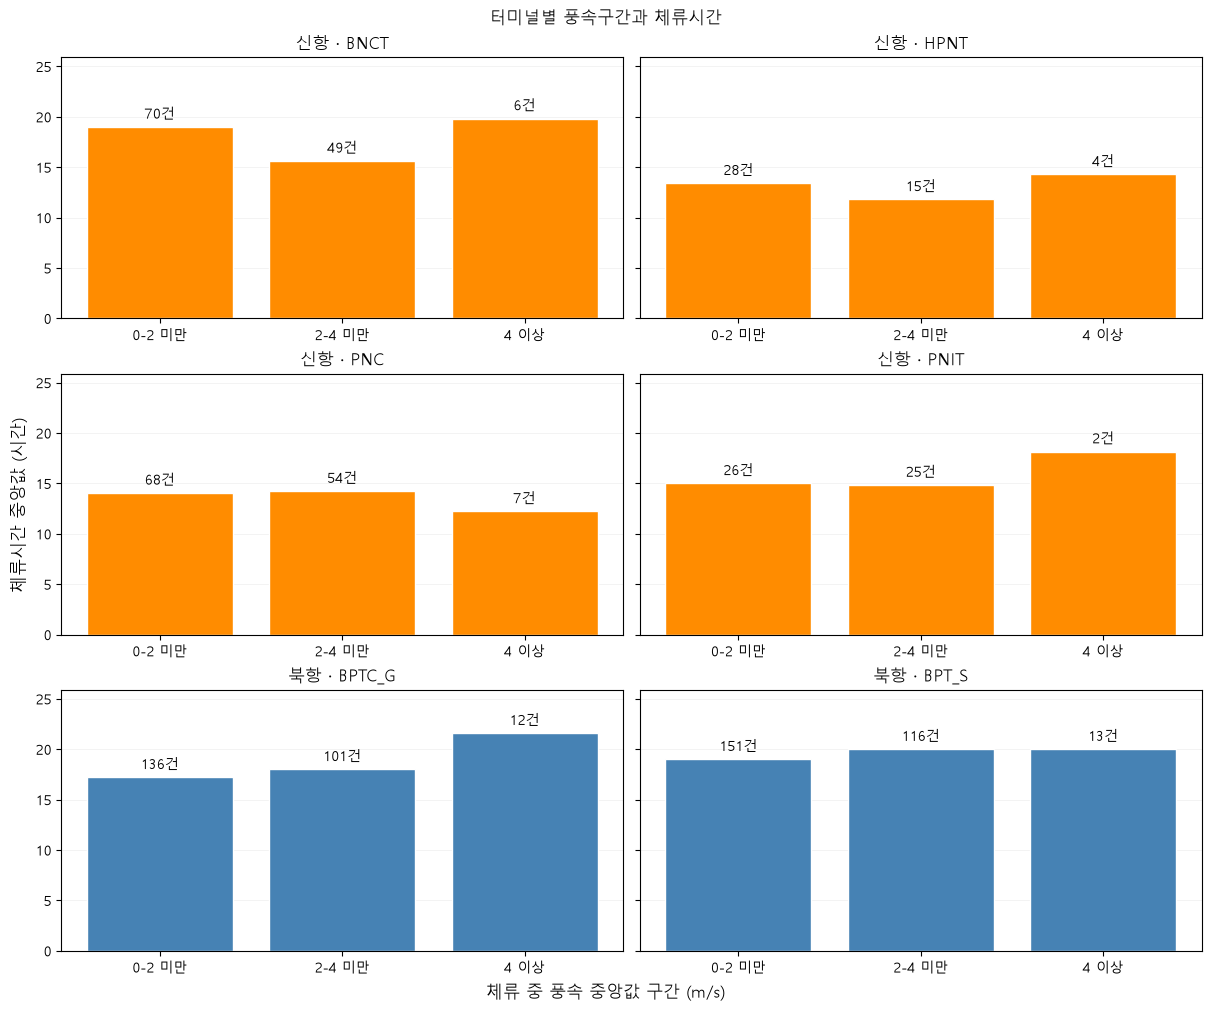

In [50]:
# 동일한 총톤수·작업량 조건에서 풍속구간별 체류시간 중앙값을 비교한다.
# 막대 위 기록 수를 함께 확인해 표본이 적은 구간의 해석에 주의한다.
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]
풍속순서 = ["0-2 미만", "2-4 미만", "4 이상"]

fig, axes = plt.subplots(
    3, 2, figsize=(12, 10),
    sharey=True, layout="constrained",
)

for ax, 터미널 in zip(axes.flat, 터미널목록):
    자료 = 풍속결과.xs(터미널, level="터미널").reindex(풍속순서)
    항만 = "북항" if 터미널 in ["BPTC_G", "BPT_S"] else "신항"
    색 = "steelblue" if 항만 == "북항" else "darkorange"

    막대 = ax.bar(
        풍속순서, 자료["체류시간_중앙값"],
        color=색, edgecolor="white",
    )

    ax.bar_label(
        막대,
        labels=[
            f"{int(n)}건" if pd.notna(n) else ""
            for n in 자료["기록수"]
        ],
        padding=4,
    )

    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

최댓값 = 풍속결과["체류시간_중앙값"].max()
axes[0, 0].set_ylim(0, 최댓값 * 1.2)

fig.suptitle("터미널별 풍속구간과 체류시간")
fig.supxlabel("체류 중 풍속 중앙값 구간 (m/s)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- BPTC_G는 풍속구간이 높아질수록 체류시간 중앙값이 17.21 → 18.00 → 21.58시간으로 증가했으며, BPT_S는 19.00 → 20.00 → 20.00시간으로 변화가 작았다.

- BNCT·HPNT·PNC·PNIT에서는 풍속 증가에 따른 체류시간의 일관된 증가 경향이 나타나지 않았다.


In [51]:
# 작업량 600-800 집단에서 누락된 최대순간풍속 두 변수의 분포를 확인한다.
# 이 결과를 보고 각 변수의 비교 구간을 정한다.
돌풍열 = [
    "체류시간_최대순간풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
]

돌풍요약 = 후보.groupby("터미널")[돌풍열].agg(
    ["count", "min", "median", "max"]
).reindex(터미널목록)

display(돌풍요약.round(2))

체류시간_최대순간풍속_중앙값_mps                    체류시간_최대순간풍속_최댓값_mps        \
                     count   min median   max               count   min   
터미널                                                                       
BNCT                   120  0.43   2.52  7.42                 120  1.20   
HPNT                    46  1.14   2.53  9.14                  46  2.49   
PNC                    121  0.46   2.53  8.35                 121  1.34   
PNIT                    53  1.15   2.78  8.87                  53  2.48   
BPTC_G                 244  0.46   3.07  8.15                 244  1.41   
BPT_S                  267  0.79   3.01  7.66                 267  2.00   

                      
       median    max  
터미널                   
BNCT     5.12  11.09  
HPNT     4.86  12.37  
PNC      4.73  14.36  
PNIT     4.87  12.48  
BPTC_G   5.33  15.68  
BPT_S    5.71  12.20

In [52]:
# 최대순간풍속 중앙값과 최댓값을 각각 구간화해 체류시간을 비교한다.
# 두 변수를 동시에 조합해 집단을 나누지는 않는다.
# 구간은 분포를 살펴보기 위한 기준이며 공식 강풍 기준은 아니다.
돌풍설정 = {
    "중앙값": (
        "체류시간_최대순간풍속_중앙값_mps",
        [0, 2, 4, float("inf")],
        ["0-2 미만", "2-4 미만", "4 이상"],
    ),
    "최댓값": (
        "체류시간_최대순간풍속_최댓값_mps",
        [0, 5, 8, float("inf")],
        ["0-5 미만", "5-8 미만", "8 이상"],
    ),
}

터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]
돌풍결과 = {}

for 종류, (열, 경계, 구간명) in 돌풍설정.items():
    자료 = 후보.copy()
    자료["풍속구간"] = pd.cut(
        자료[열], bins=경계, labels=구간명, right=False
    )

    돌풍결과[종류] = 자료.groupby(
        ["터미널", "풍속구간"], observed=False
    ).agg(
        기록수=("체류시간", "count"),
        작업량_중앙값=("총작업량", "median"),
        총톤수_중앙값=("총톤수", "median"),
        체류시간_중앙값=("체류시간", "median"),
    )

    print(f"최대순간풍속 {종류} 기준")
    display(돌풍결과[종류].round(2))

최대순간풍속 중앙값 기준


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    풍속구간                                   
BNCT   0-2 미만   33    697.0  17907.0     18.92
       2-4 미만   69    689.0  18485.0     17.97
       4 이상     18    655.5  18406.0     17.26
BPTC_G 0-2 미만   53    671.0  17853.0     17.50
       2-4 미만  128    679.5  17119.0     17.33
       4 이상     63    661.0  18051.0     18.17
BPT_S  0-2 미만   54    708.5  18057.5     19.00
       2-4 미만  137    719.0  18064.0     20.00
       4 이상     76    721.5  18051.0     20.00
HPNT   0-2 미만   12    744.5  18104.0     13.85
       2-4 미만   26    675.0  18709.0     12.95
       4 이상      8    711.0  17349.0     11.85
PNC    0-2 미만   42    726.5  18327.0     14.05
       2-4 미만   62    698.0  18257.0     13.69
       4 이상     17    702.0  18321.0     13.23
PNIT   0-2 미만   13    734.0  18334.0     14.75
       2-4 미만   29    683.0  18334.0     15.00
       4 이상     11    687.0  18334.0     14.83

최대순간풍속 최댓값 기준


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    풍속구간                                   
BNCT   0-5 미만   54    697.5  18406.0     16.98
       5-8 미만   55    672.0  18485.0     17.08
       8 이상     11    662.0  18485.0     20.67
BPTC_G 0-5 미만   96    674.0  17349.0     17.00
       5-8 미만  126    674.0  17853.0     18.00
       8 이상     22    676.0  17263.0     19.33
BPT_S  0-5 미만   86    714.0  18064.0     18.75
       5-8 미만  141    718.0  18051.0     20.00
       8 이상     40    703.0  17986.5     22.58
HPNT   0-5 미만   25    725.0  18085.0     12.90
       5-8 미만   18    639.0  18812.0     13.20
       8 이상      3    783.0  18123.0     14.87
PNC    0-5 미만   67    677.0  18321.0     13.33
       5-8 미만   45    724.0  18257.0     13.75
       8 이상      9    715.0  18326.0     18.00
PNIT   0-5 미만   29    706.0  18334.0     14.75
       5-8 미만   22    662.5  18334.0     15.00
       8 이상      2    670.5  17701.0     17.92

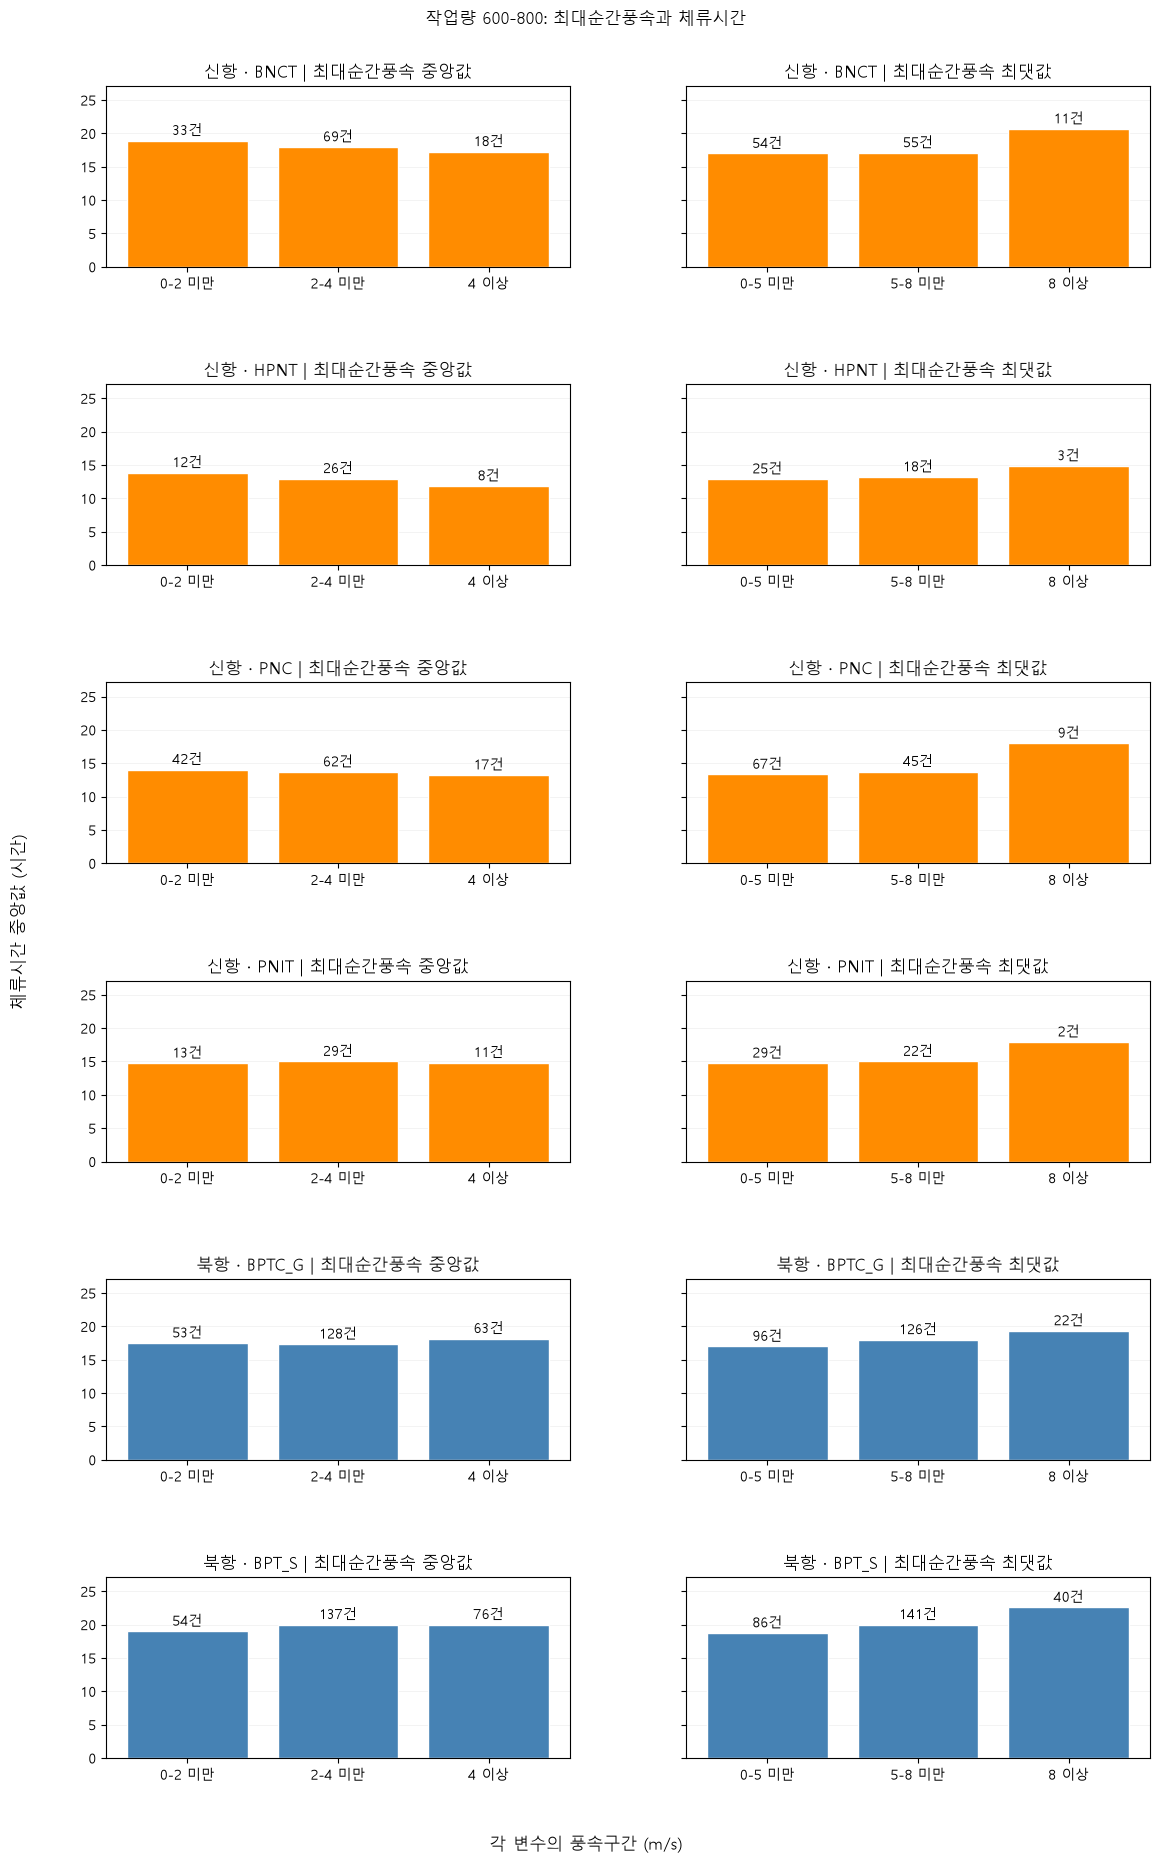

In [53]:
# 행은 터미널, 왼쪽은 최대순간풍속 중앙값, 오른쪽은 최댓값이다.
# 모든 그래프의 세로축을 통일하고 막대 위에 기록 수를 표시한다.
fig, axes = plt.subplots(
    6, 2, figsize=(12, 19),
    sharey=True, layout=None,
)

for 행, 터미널 in enumerate(터미널목록):
    항만 = "북항" if 터미널 in ["BPTC_G", "BPT_S"] else "신항"
    색 = "steelblue" if 항만 == "북항" else "darkorange"

    for 열번호, (종류, 설정) in enumerate(돌풍설정.items()):
        ax = axes[행, 열번호]
        구간명 = 설정[2]
        자료 = 돌풍결과[종류].xs(
            터미널, level="터미널"
        ).reindex(구간명)

        막대 = ax.bar(
            구간명, 자료["체류시간_중앙값"],
            color=색, edgecolor="white",
        )

        for 막대하나, 건수 in zip(막대, 자료["기록수"]):
            x = 막대하나.get_x() + 막대하나.get_width() / 2

            if pd.notna(건수) and 건수 > 0:
                ax.annotate(
                    f"{int(건수)}건", (x, 막대하나.get_height()),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center",
                )
            else:
                ax.text(x, 0.5, "자료 없음", ha="center", fontsize=9)

        ax.set_title(f"{항만} · {터미널} | 최대순간풍속 {종류}")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)

전체최대 = pd.concat(돌풍결과.values())["체류시간_중앙값"].max()
axes[0, 0].set_ylim(
    0, 전체최대 * 1.2 if pd.notna(전체최대) and 전체최대 > 0 else 1
)

fig.suptitle("작업량 600-800: 최대순간풍속과 체류시간")
fig.supxlabel("각 변수의 풍속구간 (m/s)")
fig.supylabel("체류시간 중앙값 (시간)")
fig.subplots_adjust(left=0.10, right=0.97, bottom=0.06, top=0.94, hspace=0.65, wspace=0.25)
그림표시()

In [54]:
# 작업량 600-800 집단에서 유의파고 중앙값·최댓값의 분포를 확인한다.
# 결측과 값이 집중된 범위를 확인한 뒤 비교 구간을 정한다.
파고열목록 = [
    "체류시간_유의파고_중앙값_m",
    "체류시간_유의파고_최댓값_m",
]

파고분포 = 후보.groupby("터미널")[파고열목록].agg(
    ["count", "min", "median", "max"]
).reindex(터미널목록)

파고분포 = 파고분포.rename(
    columns={
        "count": "유효건수",
        "min": "최솟값",
        "median": "중앙값",
        "max": "최댓값",
    },
    level=1,
)

display(파고분포.round(2))

# 두 변수의 결측 건수도 함께 확인한다.
display(
    후보.groupby("터미널")[파고열목록]
    .agg(lambda s: s.isna().sum())
    .reindex(터미널목록)
    .rename(columns=lambda 열: 열 + "_결측건수")
)

체류시간_유의파고_중앙값_m                 체류시간_유의파고_최댓값_m                
                  유효건수  최솟값  중앙값   최댓값            유효건수  최솟값  중앙값   최댓값
터미널                                                                   
BNCT               126  0.1  0.3  1.25             126  0.2  0.5   2.3
HPNT                47  0.1  0.3  1.10              47  0.2  0.5   1.5
PNC                126  0.1  0.3  1.45             126  0.2  0.5   1.8
PNIT                52  0.1  0.3  1.10              52  0.2  0.5   1.7
BPTC_G             245  0.1  0.5  2.40             245  0.2  0.7  10.8
BPT_S              272  0.2  0.5  1.80             272  0.2  0.8   3.2

,체류시간_유의파고_중앙값_m_결측건수,체류시간_유의파고_최댓값_m_결측건수
터미널,,
BNCT,0,0
HPNT,0,0
PNC,4,4
PNIT,2,2
BPTC_G,5,5
BPT_S,8,8


In [55]:
# 작업량 600-800 집단에서 유의파고를 1m 간격으로 나눠 비교한다.
파고설정 = {
    "중앙값": "체류시간_유의파고_중앙값_m",
    "최댓값": "체류시간_유의파고_최댓값_m",
}
파고순서 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]
유의파고결과 = {}

for 종류, 열 in 파고설정.items():
    자료 = 후보.copy()
    자료["파고구간"] = pd.cut(
        자료[열],
        bins=[0, 1, 2, 3, float("inf")],
        labels=파고순서,
        right=False,
    )

    유의파고결과[종류] = 자료.groupby(
        ["터미널", "파고구간"], observed=False
    ).agg(
        기록수=("체류시간", "count"),
        작업량_중앙값=("총작업량", "median"),
        총톤수_중앙값=("총톤수", "median"),
        체류시간_중앙값=("체류시간", "median"),
    )

    print(f"유의파고 {종류} 기준")
    display(유의파고결과[종류].round(2))

유의파고 중앙값 기준


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    파고구간                                   
BNCT   0-1 미만  121    686.0  18485.0     17.92
       1-2 미만    5    705.0  17907.0     15.62
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
BPTC_G 0-1 미만  212    674.5  17768.0     17.33
       1-2 미만   31    682.0  17119.0     19.00
       2-3 미만    2    689.5  17853.0     26.00
       3 이상      0      NaN      NaN       NaN
BPT_S  0-1 미만  238    714.5  18051.0     19.67
       1-2 미만   34    695.0  18045.5     19.58
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
HPNT   0-1 미만   44    702.0  18104.0     12.95
       1-2 미만    3    794.0  18606.0     13.70
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNC    0-1 미만  118    702.0  18257.0     13.75
       1-2 미만    8    677.5  18326.5     15.85
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNIT   0-1 미만   50    686.0  18334.0     14.88
       1-2 미만    2    736.0  18334.0     22.62
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN

유의파고 최댓값 기준


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    파고구간                                   
BNCT   0-1 미만  112    688.5  18485.0     18.15
       1-2 미만   13    645.0  17594.0     16.03
       2-3 미만    1    763.0  18491.0     18.92
       3 이상      0      NaN      NaN       NaN
BPTC_G 0-1 미만  153    674.0  17449.0     17.33
       1-2 미만   78    682.5  17819.0     17.50
       2-3 미만   12    666.0  17952.0     20.00
       3 이상      2    657.5  16879.5     63.04
BPT_S  0-1 미만  172    714.5  18051.0     19.17
       1-2 미만   86    708.5  18064.0     20.08
       2-3 미만   12    730.5  18064.0     19.08
       3 이상      2    628.5  13070.5     31.00
HPNT   0-1 미만   41    699.0  18085.0     12.90
       1-2 미만    6    771.5  18709.0     14.28
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNC    0-1 미만  108    702.0  18289.0     13.67
       1-2 미만   18    679.5  18291.5     15.29
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNIT   0-1 미만   45    685.0  18334.0     14.92
       1-2 미만    7    708.0  18334.0     15.00
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN

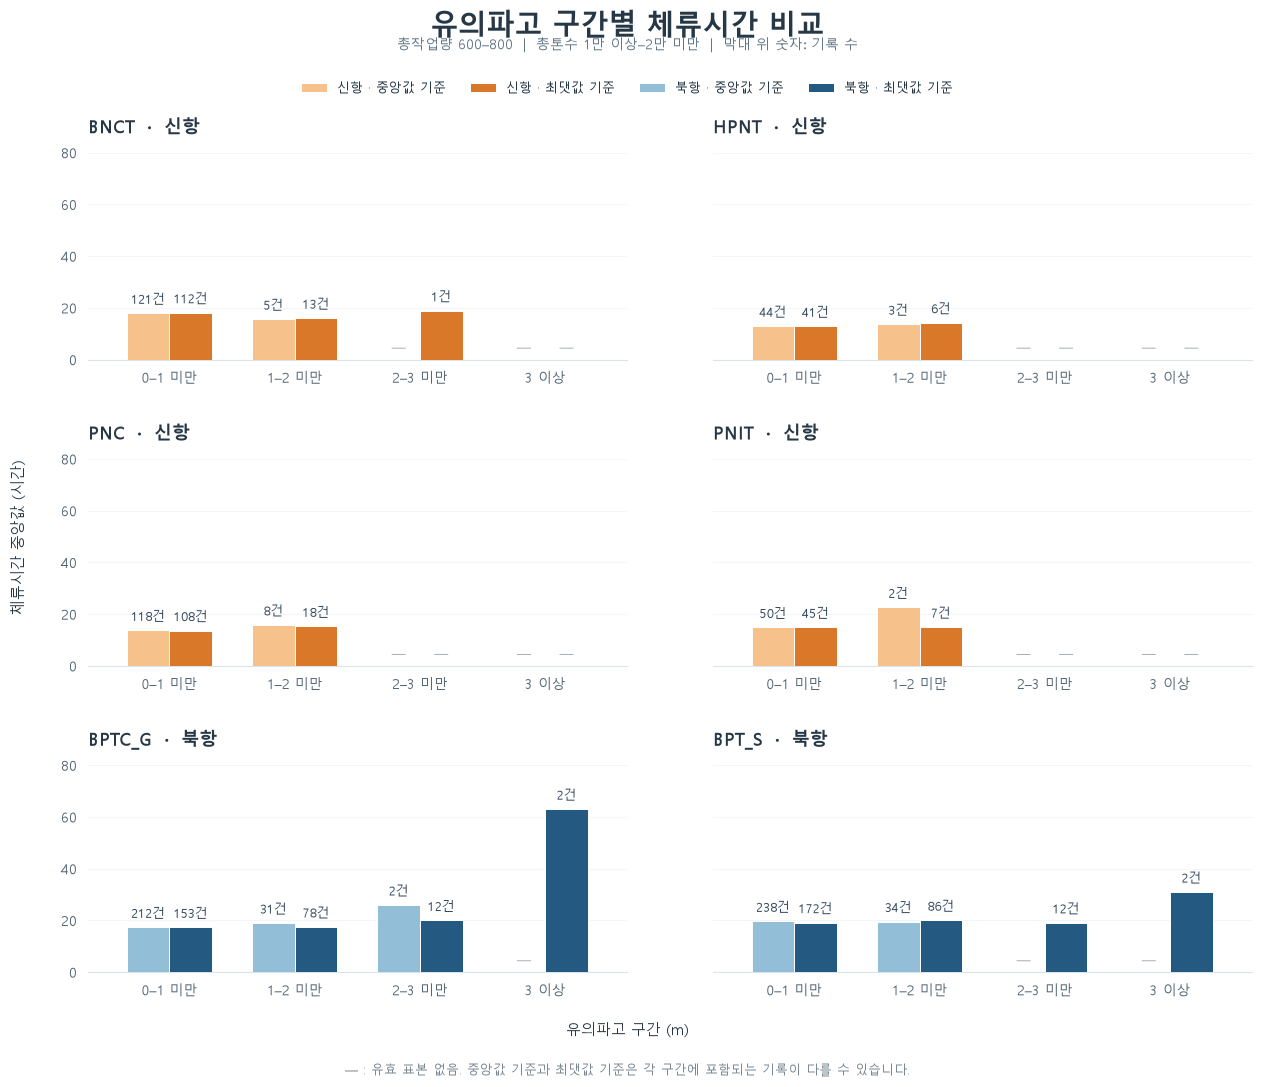

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]
파고순서 = ["0–1 미만", "1–2 미만", "2–3 미만", "3 이상"]
원래구간 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]

x = np.arange(4)
폭 = 0.34

전체최대 = pd.concat(
    유의파고결과.values()
)["체류시간_중앙값"].max()

상한 = (
    max(10, np.ceil(전체최대 * 1.25 / 10) * 10)
    if pd.notna(전체최대)
    else 10
)

with plt.rc_context({
    "font.size": 10,
    "text.color": "#263746",
    "axes.labelcolor": "#526575",
    "xtick.color": "#526575",
    "ytick.color": "#526575",
}):
    fig, axes = plt.subplots(
        3, 2,
        figsize=(13, 11),
        sharey=True,
        facecolor="white",
    )

    for ax, 터미널 in zip(axes.flat, 터미널목록):
        북항 = 터미널 in ["BPTC_G", "BPT_S"]
        항만 = "북항" if 북항 else "신항"

        색상 = (
            {"중앙값": "#92BED8", "최댓값": "#245A81"}
            if 북항
            else {"중앙값": "#F6C18B", "최댓값": "#D97828"}
        )

        ax.set_facecolor("white")

        for 종류, 이동 in [
            ("중앙값", -폭 / 2),
            ("최댓값", 폭 / 2),
        ]:
            표 = 유의파고결과[종류]

            if 터미널 in 표.index.get_level_values("터미널"):
                자료 = 표.xs(
                    터미널, level="터미널"
                ).reindex(원래구간)
            else:
                자료 = pd.DataFrame(
                    index=원래구간,
                    columns=표.columns,
                )

            값 = pd.to_numeric(
                자료["체류시간_중앙값"], errors="coerce"
            ).to_numpy(dtype=float)

            건수 = pd.to_numeric(
                자료["기록수"], errors="coerce"
            ).fillna(0).to_numpy(dtype=int)

            유효 = (건수 > 0) & np.isfinite(값)

            막대 = ax.bar(
                x[유효] + 이동,
                값[유효],
                width=폭,
                color=색상[종류],
                edgecolor="white",
                linewidth=0.7,
                zorder=3,
            )

            ax.bar_label(
                막대,
                labels=[f"{n:,}건" for n in 건수[유효]],
                padding=5,
                fontsize=9,
                color="#34495E",
            )

            # 빈 구간은 축 안에 대시로 표시합니다.
            for 위치 in x[~유효] + 이동:
                ax.text(
                    위치, 상한 * 0.025, "—",
                    ha="center",
                    va="bottom",
                    color="#A4AFB9",
                    fontsize=10,
                )

        ax.set_title(
            f"{터미널}  ·  {항만}",
            loc="left",
            fontsize=13,
            fontweight="bold",
            pad=14,
        )

        ax.set_xticks(x, 파고순서)
        ax.set_xlim(-0.65, 3.65)
        ax.set_ylim(0, 상한)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4))

        ax.set_axisbelow(True)
        ax.grid(False)
        ax.grid(
            axis="y",
            color="#E8EDF2",
            linewidth=0.8,
        )
        ax.tick_params(axis="both", length=0, pad=8)

        for 방향 in ["top", "right", "left"]:
            ax.spines[방향].set_visible(False)

        ax.spines["bottom"].set_color("#DCE4EB")

    fig.suptitle(
        "유의파고 구간별 체류시간 비교",
        fontsize=20,
        fontweight="bold",
        y=0.98,
    )

    fig.text(
        0.5, 0.944,
        "총작업량 600–800  |  총톤수 1만 이상–2만 미만"
        "  |  막대 위 숫자: 기록 수",
        ha="center",
        fontsize=10,
        color="#647787",
    )

    fig.legend(
        handles=[
            Patch(
                facecolor="#F6C18B",
                label="신항 · 중앙값 기준",
            ),
            Patch(
                facecolor="#D97828",
                label="신항 · 최댓값 기준",
            ),
            Patch(
                facecolor="#92BED8",
                label="북항 · 중앙값 기준",
            ),
            Patch(
                facecolor="#245A81",
                label="북항 · 최댓값 기준",
            ),
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, 0.925),
        ncol=4,
        frameon=False,
        fontsize=9,
    )

    fig.supxlabel(
        "유의파고 구간 (m)",
        y=0.045,
        fontsize=11,
    )
    fig.supylabel(
        "체류시간 중앙값 (시간)",
        x=0.025,
        fontsize=11,
    )

    fig.text(
        0.5, 0.012,
        "— : 유효 표본 없음. 중앙값 기준과 최댓값 기준은 "
        "각 구간에 포함되는 기록이 다를 수 있습니다.",
        ha="center",
        fontsize=9,
        color="#7B8995",
    )

    fig.subplots_adjust(
        left=0.085,
        right=0.98,
        bottom=0.105,
        top=0.85,
        hspace=0.48,
        wspace=0.16,
    )

    그림표시()

- 작업량 600-800 집단에서 유의파고 중앙값은 대부분 1m 미만에 집중됐으며, 2m 이상 기록은 BPTC_G의 2건뿐이었다. 중앙값 기준으로 모든 터미널에서 체류시간이 일관되게 증가하지는 않았다.
- 유의파고 최댓값 기준으로 BPTC_G의 체류시간 중앙값은 파고구간이 높아질수록 17.33 → 17.50 → 20.00 → 63.04시간으로 증가했다. 다만 3m 이상은 2건이며, 원자료 확인 대상인 10.8m 기록이 포함되어 있다.
- BPT_S도 최댓값 3m 이상에서 체류시간 중앙값이 31.00시간으로 나타났으나 2건에 불과하다.

In [57]:
# 같은 총톤수·작업량 조건에서 순간최대파고 두 변수의 분포를 확인한다.
# 값이 집중된 범위와 결측을 확인한 뒤 비교 구간을 정한다.
순간파고설정 = {
    "중앙값": "체류시간_순간최대파고_중앙값_m",
    "최댓값": "체류시간_순간최대파고_최댓값_m",
}

터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]

순간파고분포 = {}

for 종류, 열 in 순간파고설정.items():
    순간파고분포[종류] = 후보.groupby("터미널")[열].agg(
        유효건수="count",
        결측건수=lambda s: s.isna().sum(),
        최솟값="min",
        하위25퍼센트=lambda s: s.quantile(0.25),
        중앙값="median",
        상위25퍼센트_경계=lambda s: s.quantile(0.75),
        최댓값="max",
    ).reindex(터미널목록)

display(pd.concat(순간파고분포, axis=1).round(2))

중앙값                                           최댓값                    \
       유효건수 결측건수  최솟값 하위25퍼센트   중앙값 상위25퍼센트_경계   최댓값 유효건수 결측건수  최솟값 하위25퍼센트   
터미널                                                                           
BNCT    126    0  0.2    0.30  0.50       0.60  1.80  126    0  0.3     0.5   
HPNT     47    0  0.1    0.40  0.50       0.72  1.60   47    0  0.3     0.5   
PNC     126    4  0.2    0.30  0.50       0.70  1.95  126    4  0.2     0.5   
PNIT     52    2  0.2    0.34  0.45       0.76  1.60   52    2  0.3     0.5   
BPTC_G  245    5  0.2    0.50  0.65       1.00  3.30  245    5  0.2     0.7   
BPT_S   272    8  0.2    0.50  0.60       0.95  2.45  272    8  0.3     0.7   

                               
         중앙값 상위25퍼센트_경계   최댓값  
터미널                            
BNCT    0.70       0.98   3.2  
HPNT    0.70       1.10   2.3  
PNC     0.70       1.08   2.6  
PNIT    0.80       1.10   2.7  
BPTC_G  1.00       1.50  17.2  
BPT_S   1.05       1.50   4.3

In [58]:
# 작업량 600-800 집단에서 순간최대파고 중앙값·최댓값을 각각 비교한다.
# 구간은 탐색적 비교용이며 공식적인 위험 기준은 아니다.
순간파고설정 = {
    "중앙값": "체류시간_순간최대파고_중앙값_m",
    "최댓값": "체류시간_순간최대파고_최댓값_m",
}
순간파고순서 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]
순간파고결과 = {}

for 종류, 열 in 순간파고설정.items():
    자료 = 후보.copy()
    자료["파고구간"] = pd.cut(
        자료[열],
        bins=[0, 1, 2, 3, float("inf")],
        labels=순간파고순서,
        right=False,
    )

    순간파고결과[종류] = 자료.groupby(
        ["터미널", "파고구간"], observed=False
    ).agg(
        기록수=("체류시간", "count"),
        작업량_중앙값=("총작업량", "median"),
        총톤수_중앙값=("총톤수", "median"),
        체류시간_중앙값=("체류시간", "median"),
    )

    print(f"순간최대파고 {종류} 기준")
    display(순간파고결과[종류].round(2))

순간최대파고 중앙값 기준


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    파고구간                                   
BNCT   0-1 미만  114    687.0  18485.0     17.94
       1-2 미만   12    662.0  17411.5     16.64
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
BPTC_G 0-1 미만  182    674.0  17682.0     17.33
       1-2 미만   55    684.0  17515.0     18.17
       2-3 미만    7    654.0  17449.0     20.00
       3 이상      1    625.0  17853.0     34.17
BPT_S  0-1 미만  207    714.0  18051.0     19.67
       1-2 미만   58    709.0  18064.0     19.58
       2-3 미만    7    641.0  17933.0     20.00
       3 이상      0      NaN      NaN       NaN
HPNT   0-1 미만   42    701.0  18085.0     12.95
       1-2 미만    5    754.0  18606.0     13.70
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNC    0-1 미만  113    702.0  18321.0     13.75
       1-2 미만   13    686.0  18257.0     15.23
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNIT   0-1 미만   46    686.0  18334.0     14.88
       1-2 미만    6    697.5  18334.0     15.12
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN

순간최대파고 최댓값 기준


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    파고구간                                   
BNCT   0-1 미만   94    691.5  18485.0     17.88
       1-2 미만   27    660.0  17594.0     17.87
       2-3 미만    4    692.0  18196.0     15.56
       3 이상      1    763.0  18491.0     18.92
BPTC_G 0-1 미만  114    676.5  17564.0     17.33
       1-2 미만   94    673.5  17853.0     17.04
       2-3 미만   29    697.0  16659.0     20.00
       3 이상      8    659.0  17853.0     20.75
BPT_S  0-1 미만  116    711.5  17952.0     19.83
       1-2 미만  121    719.0  18051.0     19.17
       2-3 미만   26    699.5  18072.0     21.83
       3 이상      9    681.0  17933.0     19.00
HPNT   0-1 미만   31    703.0  18085.0     12.40
       1-2 미만   13    719.0  18123.0     14.87
       2-3 미만    3    794.0  18606.0     13.00
       3 이상      0      NaN      NaN       NaN
PNC    0-1 미만   90    707.5  18257.0     13.58
       1-2 미만   26    692.0  18321.0     14.05
       2-3 미만   10    677.5  18224.5     15.85
       3 이상      0      NaN      NaN       NaN
PNIT   0-1 미만   34    693.5  18334.0     15.00
       1-2 미만   15    665.0  18480.0     14.00
       2-3 미만    3    687.0  18334.0     21.00
       3 이상      0      NaN      NaN       NaN

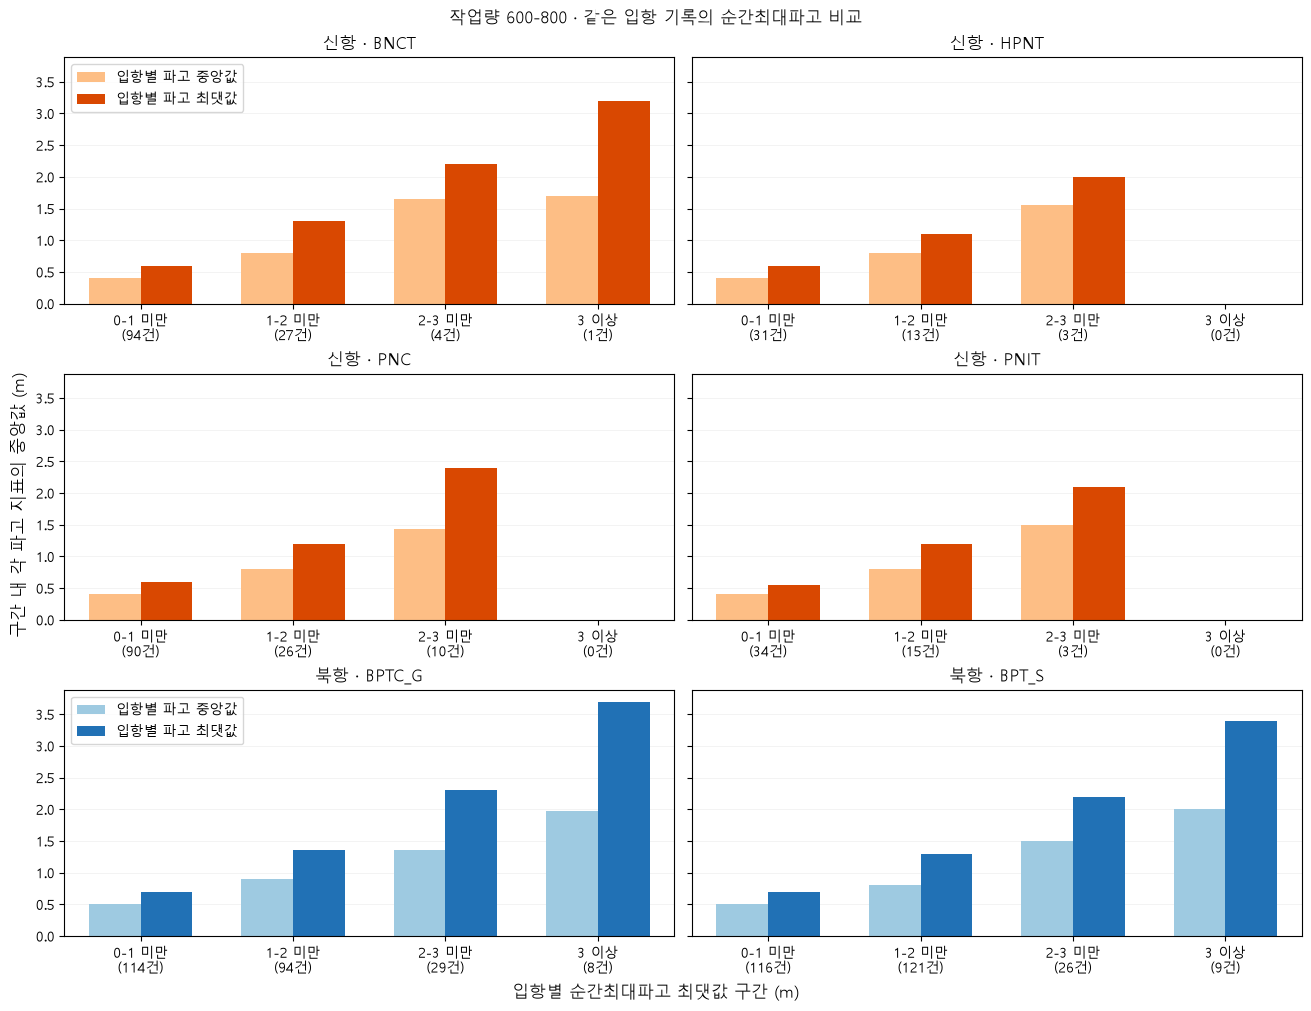

In [59]:
중앙열 = "체류시간_순간최대파고_중앙값_m"
최대열 = "체류시간_순간최대파고_최댓값_m"
구간명 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]

# 두 값이 모두 있는 입항 기록을 최댓값 기준으로 한 번만 구간화한다.
비교 = 후보.dropna(subset=[중앙열, 최대열]).copy()
비교["최댓값구간"] = pd.cut(
    비교[최대열],
    bins=[0, 1, 2, 3, float("inf")],
    labels=구간명,
    right=False,
)

# 각 구간의 동일한 입항 기록에서 두 파고 지표를 각각 중앙값으로 요약한다.
비교표 = 비교.groupby(["터미널", "최댓값구간"], observed=True).agg(
    기록수=(최대열, "size"),
    중앙값_대표=(중앙열, "median"),
    최댓값_대표=(최대열, "median"),
)

fig, axes = plt.subplots(
    3, 2, figsize=(13, 10), sharey=True, layout="constrained"
)
x = np.arange(len(구간명))
폭 = 0.34

for ax, 터미널 in zip(axes.flat, 터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    중앙색, 최대색 = (
        ("#9ECAE1", "#2171B5") if 북항
        else ("#FDBE85", "#D94801")
    )

    인덱스 = pd.MultiIndex.from_product(
        [[터미널], 구간명], names=비교표.index.names
    )
    자료 = 비교표.reindex(인덱스)
    건수 = 자료["기록수"].fillna(0).astype(int)
    유효 = 건수.to_numpy() > 0

    ax.bar(
        x[유효] - 폭 / 2, 자료.loc[유효, "중앙값_대표"],
        width=폭, color=중앙색, label="입항별 파고 중앙값",
    )
    ax.bar(
        x[유효] + 폭 / 2, 자료.loc[유효, "최댓값_대표"],
        width=폭, color=최대색, label="입항별 파고 최댓값",
    )

    ax.set_xticks(x, [f"{구간}\n({n}건)" for 구간, n in zip(구간명, 건수)])
    ax.set_xlim(-0.5, len(구간명) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

axes[0, 0].legend()  # 신항
axes[2, 0].legend()  # 북항

fig.suptitle("작업량 600-800 · 같은 입항 기록의 순간최대파고 비교")
fig.supxlabel("입항별 순간최대파고 최댓값 구간 (m)")
fig.supylabel("구간 내 각 파고 지표의 중앙값 (m)")
그림표시()

- 작업량 600-800 집단에서 입항별 순간최대파고 최댓값을 기준으로 구간을 나누고, 각 구간의 동일한 입항 기록에서 파고 중앙값과 최댓값을 비교했다.
- 최댓값이 2-3m인 구간에서도 파고 중앙값은 2m 미만일 수 있다. 두 막대의 차이는 같은 입항 기록에서 체류 중 전반적인 파고 수준과 가장 높았던 파고 수준이 얼마나 달랐는지 보여준다.
- 가로축 아래 건수는 두 막대에 공통으로 사용된 입항 기록 수다. 세로축은 파고(m)이므로, 이 그래프는 체류시간과의 관계를 비교하기에 앞서 두 파고 지표의 차이를 확인하는 데 사용했다.

In [60]:
중앙열 = "체류시간_시정_중앙값_10m"
최소열 = "체류시간_시정_최솟값_10m"
숫자열 = [중앙열, 최소열, "체류시간"]

시정비교 = 후보.copy()

# 쉼표가 포함된 문자열을 숫자로 바꾼다. 시정 단위는 10m 그대로다.
for 열 in 숫자열:
    시정비교[열] = pd.to_numeric(
        시정비교[열].astype("string").str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )

시정비교 = 시정비교.dropna(subset=숫자열).copy()
시정구간명 = ["0-100 미만", "100-500 미만", "500-1,000 미만", "1,000 이상"]

시정비교["최저시정구간"] = pd.cut(
    시정비교[최소열],
    bins=[0, 100, 500, 1000, float("inf")],
    labels=시정구간명,
    right=False,
)

시정결과 = 시정비교.groupby(
    ["터미널", "최저시정구간"], observed=False
).agg(
    기록수=("체류시간", "size"),
    시정최솟값_대표_10m=(최소열, "median"),
    시정중앙값_대표_10m=(중앙열, "median"),
    체류시간_중앙값=("체류시간", "median"),
)

display(시정결과.round(2))

기록수  시정최솟값_대표_10m  시정중앙값_대표_10m  체류시간_중앙값
터미널    최저시정구간                                                 
BNCT   0-100 미만        2          53.0        2675.5     24.79
       100-500 미만     18         282.5        2024.0      20.5
       500-1,000 미만   16         724.0        1684.0      18.0
       1,000 이상       90        2965.5        4554.5     16.39
BPTC_G 0-100 미만       12          47.0         478.5     17.46
       100-500 미만     37         280.0        2162.5     19.33
       500-1,000 미만   26         662.5        1738.5     18.17
       1,000 이상      175        2950.0        4778.0     17.33
BPT_S  0-100 미만        8          43.0         853.0     23.08
       100-500 미만     37         299.0        1112.0     20.33
       500-1,000 미만   34         745.0        1798.0     19.67
       1,000 이상      201        2655.0        4580.0      19.5
HPNT   0-100 미만        0          <NA>          <NA>      <NA>
       100-500 미만      7         215.0         706.0      12.9
       500-1,000 미만    4         717.5       2062.25     15.93
       1,000 이상       36        2470.5       3397.75      13.0
PNC    0-100 미만        5          91.0         254.5     15.23
       100-500 미만     15         216.0        1637.0     15.48
       500-1,000 미만   13         680.0        2340.0     17.03
       1,000 이상       97        2669.0        4623.5      13.3
PNIT   0-100 미만        1          53.0        1749.0     10.42
       100-500 미만      9         338.0         846.0     15.75
       500-1,000 미만    5         942.0        1837.5     17.08
       1,000 이상       39        3237.0        4787.0     14.83

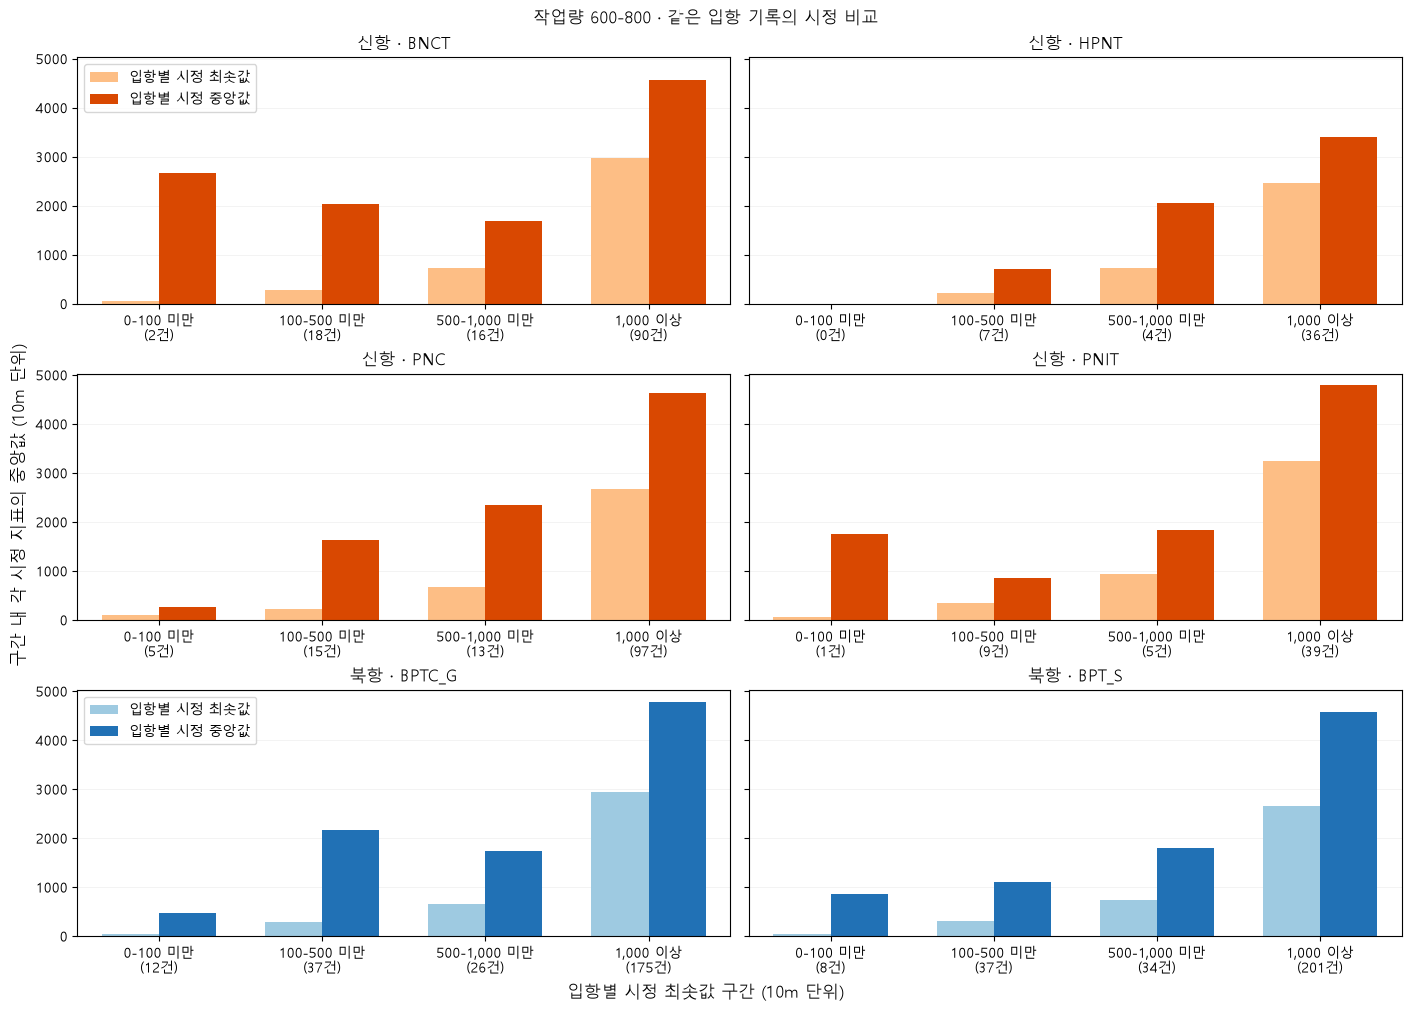

In [61]:
# 최저시정구간마다 같은 입항 기록의 시정 최솟값·중앙값을 비교한다.
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]
x = np.arange(len(시정구간명))
폭 = 0.35

fig, axes = plt.subplots(
    3, 2, figsize=(14, 10), sharey=True, layout="constrained"
)

for ax, 터미널 in zip(axes.flat, 터미널목록):
    인덱스 = pd.MultiIndex.from_product(
        [[터미널], 시정구간명], names=시정결과.index.names
    )
    자료 = 시정결과.reindex(인덱스)
    건수 = 자료["기록수"].fillna(0).astype(int).to_numpy()
    유효 = 건수 > 0

    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    최소색, 중앙색 = (
        ("#9ECAE1", "#2171B5") if 북항 else ("#FDBE85", "#D94801")
    )

    ax.bar(
        x[유효] - 폭 / 2, 자료.loc[유효, "시정최솟값_대표_10m"],
        width=폭, color=최소색, label="입항별 시정 최솟값",
    )
    ax.bar(
        x[유효] + 폭 / 2, 자료.loc[유효, "시정중앙값_대표_10m"],
        width=폭, color=중앙색, label="입항별 시정 중앙값",
    )

    ax.set_xticks(
        x, [f"{구간}\n({n}건)" for 구간, n in zip(시정구간명, 건수)]
    )
    ax.set_xlim(-0.5, len(x) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

axes[0, 0].legend()
axes[2, 0].legend()
fig.suptitle("작업량 600-800 · 같은 입항 기록의 시정 비교")
fig.supxlabel("입항별 시정 최솟값 구간 (10m 단위)")
fig.supylabel("구간 내 각 시정 지표의 중앙값 (10m 단위)")
그림표시()

- 작업량 600-800 집단에서 시정 최솟값이 1,000 이상인 구간에 638건(71.9%)이 집중됐으며, 6개 터미널 모두 이 구간의 기록이 가장 많았다. 시정 수치는 원자료의 10m 단위다.
- 최솟값 100 미만 구간에서 입항별 시정 중앙값을 다시 중앙값으로 요약하면, BNCT는 2,675.5(2건), PNC는 254.5(5건)였다. 가장 낮았던 시정이 같은 구간에 속해도 체류 중 전반적인 시정은 달랐으며, 해당 구간은 터미널별 0-12건으로 적었다.
- 결과표에서 BNCT와 BPT_S는 시정 최솟값 구간이 높아질수록 체류시간 중앙값이 각각 24.79 → 16.39시간, 23.08 → 19.50시간으로 줄었다. 다른 터미널에서는 같은 경향이 반복되지 않았다.

## 작업량 800 초과-1,000 이하 집단의 기상 분석

In [62]:
후보2 = 비교자료.loc[
    비교자료["총작업량"].between(800, 1000, inclusive="right")
].copy()

결과2 = 후보2.groupby("터미널").agg(
    기록수=("체류시간", "size"),
    작업량_중앙값=("총작업량", "median"),
    총톤수_중앙값=("총톤수", "median"),
    체류시간_중앙값=("체류시간", "median"),
).reindex(터미널목록)

display(결과2.round(2))

,기록수,작업량_중앙값,총톤수_중앙값,체류시간_중앙값
터미널,,,,
BNCT,66,885.5,17594.0,21.33
HPNT,52,893.0,18017.0,14.95
PNC,65,881.0,18327.0,15.98
PNIT,28,921.5,18334.0,20.80
BPTC_G,150,907.0,16712.5,20.00
BPT_S,359,890.0,17933.0,24.00


In [63]:
# 터미널별로 풍속 구간에 따른 체류시간과 기록 수를 확인한다.
풍속순서2 = ["0-2 미만", "2-4 미만", "4 이상"]
풍속비교2 = 후보2.copy()

풍속비교2["풍속구간"] = pd.cut(
    풍속비교2["체류시간_풍속_중앙값_mps"],
    bins=[0, 2, 4, float("inf")],
    labels=풍속순서2,
    right=False,
)

풍속결과2 = 풍속비교2.groupby(
    ["터미널", "풍속구간"], observed=False
).agg(
    기록수=("체류시간", "count"),
    작업량_중앙값=("총작업량", "median"),
    총톤수_중앙값=("총톤수", "median"),
    체류시간_중앙값=("체류시간", "median"),
)

display(풍속결과2.reindex(터미널목록, level="터미널").round(2))

기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    풍속구간                                   
BNCT   0-2 미만   44    888.0  17594.0     21.72
       2-4 미만   19    909.0  17594.0     19.80
       4 이상      3    827.0  16738.0     29.00
HPNT   0-2 미만   27    884.0  18017.0     14.00
       2-4 미만   22    896.0  18342.5     15.12
       4 이상      3    956.0  16575.0     16.70
PNC    0-2 미만   42    878.5  18324.0     15.57
       2-4 미만   20    900.5  18331.0     16.31
       4 이상      3    856.0  18327.0     14.32
PNIT   0-2 미만   19    930.0  18334.0     21.00
       2-4 미만    8    894.5  18334.0     17.82
       4 이상      1    998.0  18334.0     25.00
BPTC_G 0-2 미만   86    909.5  17093.5     19.46
       2-4 미만   62    886.0  15906.0     21.00
       4 이상      2    959.5  16695.5     24.50
BPT_S  0-2 미만  227    886.0  18051.0     24.00
       2-4 미만  124    902.0  17791.0     25.08
       4 이상      8    891.0  17385.5     22.50

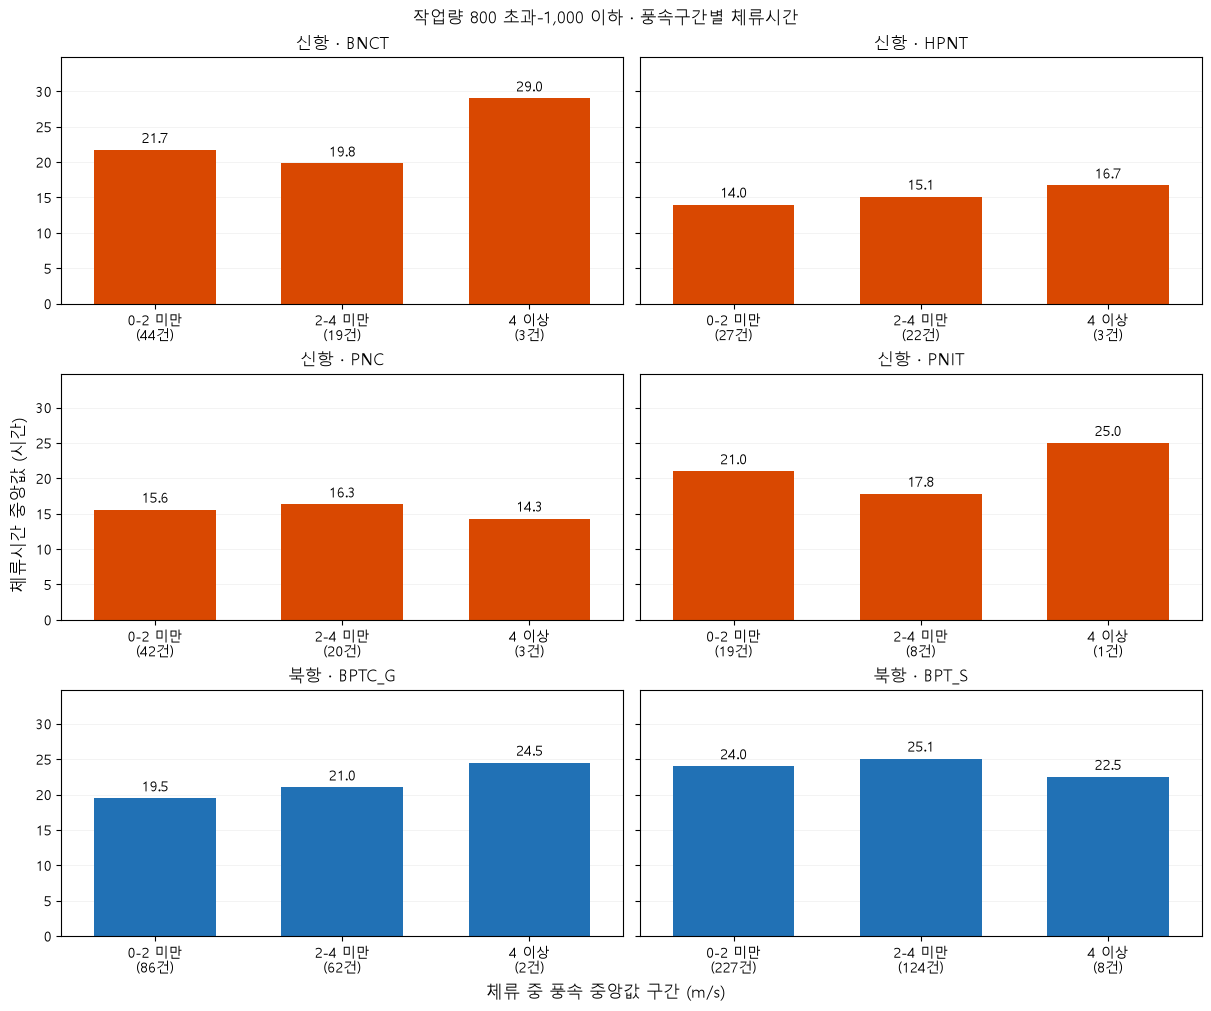

In [64]:
# 작업량 800 초과-1,000 이하의 풍속구간별 체류시간을 비교한다.
fig, axes = plt.subplots(
    3, 2, figsize=(12, 10), sharey=True, layout="constrained"
)
위치 = np.arange(len(풍속순서2))

for ax, 터미널 in zip(axes.flat, 터미널목록):
    인덱스 = pd.MultiIndex.from_product(
        [[터미널], 풍속순서2], names=풍속결과2.index.names
    )
    자료 = 풍속결과2.reindex(인덱스)
    건수 = 자료["기록수"].fillna(0).astype(int).to_numpy()
    유효 = 건수 > 0
    북항 = 터미널 in ["BPTC_G", "BPT_S"]

    막대 = ax.bar(
        위치[유효],
        자료.loc[유효, "체류시간_중앙값"].to_numpy(dtype=float),
        width=0.65,
        color="#2171B5" if 북항 else "#D94801",
    )
    ax.bar_label(막대, fmt="%.1f", padding=3)
    ax.set_xticks(
        위치, [f"{구간}\n({n}건)" for 구간, n in zip(풍속순서2, 건수)]
    )
    ax.set_xlim(-0.5, len(위치) - 0.5)
    ax.set_title(f"{'북항' if 북항 else '신항'} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

최대시간 = 풍속결과2["체류시간_중앙값"].max()
if pd.notna(최대시간) and 최대시간 > 0:
    axes[0, 0].set_ylim(0, 최대시간 * 1.2)

fig.suptitle("작업량 800 초과-1,000 이하 · 풍속구간별 체류시간")
fig.supxlabel("체류 중 풍속 중앙값 구간 (m/s)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- 작업량 800 초과-1,000 이하 집단에서 BPTC_G의 체류시간 중앙값은 풍속 구간이 높아질수록 19.46 → 21.00 → 24.50시간으로 증가했다. 작업량 600-800 집단에서도 같은 증가 방향이 나타났다.
- HPNT도 14.00 → 15.12 → 16.70시간으로 증가했지만, 나머지 4개 터미널에서는 일관된 증가 경향이 없었다.
- 풍속 4m/s 이상은 터미널별 1-8건이며 BPTC_G도 2건이었다. 높은 풍속 구간의 차이를 일반화하기는 어렵다.

In [65]:
# 작업량 800 초과-1,000 이하에서 최대순간풍속 두 지표의 분포를 확인한다.
돌풍열2 = [
    "체류시간_최대순간풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
]

돌풍분포2 = (
    후보2.groupby("터미널")[돌풍열2]
    .agg(["count", "min", "median", "max"])
    .reindex(터미널목록)
    .rename(columns={
        "count": "유효건수",
        "min": "최솟값",
        "median": "중앙값",
        "max": "최댓값",
    }, level=1)
)

display(돌풍분포2.round(2))

체류시간_최대순간풍속_중앙값_mps                    체류시간_최대순간풍속_최댓값_mps              \
                      유효건수   최솟값   중앙값    최댓값                유효건수   최솟값   중앙값   
터미널                                                                             
BNCT                    64  1.18  2.26   6.16                  64  3.26  5.29   
HPNT                    51  0.80  2.57  10.14                  51  1.82  5.51   
PNC                     61  0.85  2.46   8.85                  61  1.95  5.17   
PNIT                    28  0.98  2.22   5.85                  28  2.10  4.64   
BPTC_G                 148  0.63  3.12   6.54                 148  2.14  5.82   
BPT_S                  345  0.27  2.89   8.79                 345  0.36  5.54   

               
          최댓값  
터미널            
BNCT    10.26  
HPNT    13.93  
PNC     16.19  
PNIT    14.36  
BPTC_G  11.27  
BPT_S   12.84

In [66]:
# 각 풍속 지표별로 구간을 나누고 기록 수와 체류시간을 집계한다.
돌풍설정2 = {
    "중앙값": (
        "체류시간_최대순간풍속_중앙값_mps",
        [0, 2, 4, float("inf")],
        ["0-2 미만", "2-4 미만", "4 이상"],
    ),
    "최댓값": (
        "체류시간_최대순간풍속_최댓값_mps",
        [0, 5, 8, float("inf")],
        ["0-5 미만", "5-8 미만", "8 이상"],
    ),
}

돌풍결과2 = {}

for 종류, (열, 경계, 구간명) in 돌풍설정2.items():
    자료 = 후보2.copy()
    자료["돌풍구간"] = pd.cut(
        자료[열], bins=경계, labels=구간명, right=False
    )

    돌풍결과2[종류] = 자료.groupby(
        ["터미널", "돌풍구간"], observed=False
    ).agg(
        기록수=("체류시간", "count"),
        작업량_중앙값=("총작업량", "median"),
        총톤수_중앙값=("총톤수", "median"),
        체류시간_중앙값=("체류시간", "median"),
    ).reindex(터미널목록, level="터미널")

    print(f"최대순간풍속 {종류} 기준")
    display(돌풍결과2[종류].round(2))

최대순간풍속 중앙값 기준


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    돌풍구간                                   
BNCT   0-2 미만   26    874.0  18403.0     20.33
       2-4 미만   33    905.0  17594.0     21.03
       4 이상      5    888.0  16738.0     22.10
HPNT   0-2 미만    9    883.0  17068.0     12.00
       2-4 미만   29    889.0  18017.0     14.60
       4 이상     13    915.0  18358.0     16.70
PNC    0-2 미만   20    889.0  18324.0     15.39
       2-4 미만   31    867.0  18327.0     16.17
       4 이상     10    865.5  18407.5     15.50
PNIT   0-2 미만   13    912.0  18334.0     21.60
       2-4 미만   14    933.0  18334.0     18.00
       4 이상      1    998.0  18334.0     25.00
BPTC_G 0-2 미만   33    912.0  15906.0     20.42
       2-4 미만   73    906.0  15906.0     20.00
       4 이상     42    908.0  17921.0     20.00
BPT_S  0-2 미만   87    872.0  18051.0     24.00
       2-4 미만  192    899.0  18040.0     24.58
       4 이상     66    887.0  17862.0     25.08

최대순간풍속 최댓값 기준


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    돌풍구간                                   
BNCT   0-5 미만   23    850.0  18485.0     19.57
       5-8 미만   37    909.0  17594.0     22.10
       8 이상      4    834.0  17611.5     20.72
HPNT   0-5 미만   19    883.0  17954.0     13.50
       5-8 미만   28    901.0  18339.5     15.12
       8 이상      4    915.0  17393.5     17.40
PNC    0-5 미만   28    872.5  18324.0     15.05
       5-8 미만   23    886.0  18334.0     16.32
       8 이상     10    879.5  18331.0     15.60
PNIT   0-5 미만   15    927.0  18334.0     21.00
       5-8 미만   12    933.0  18334.0     19.72
       8 이상      1    804.0  18334.0     14.17
BPTC_G 0-5 미만   37    931.0  17613.0     19.67
       5-8 미만   99    899.0  15906.0     20.00
       8 이상     12    926.0  17921.0     21.50
BPT_S  0-5 미만  126    879.5  18051.0     23.33
       5-8 미만  186    894.0  17853.0     24.83
       8 이상     33    916.0  17791.0     27.00

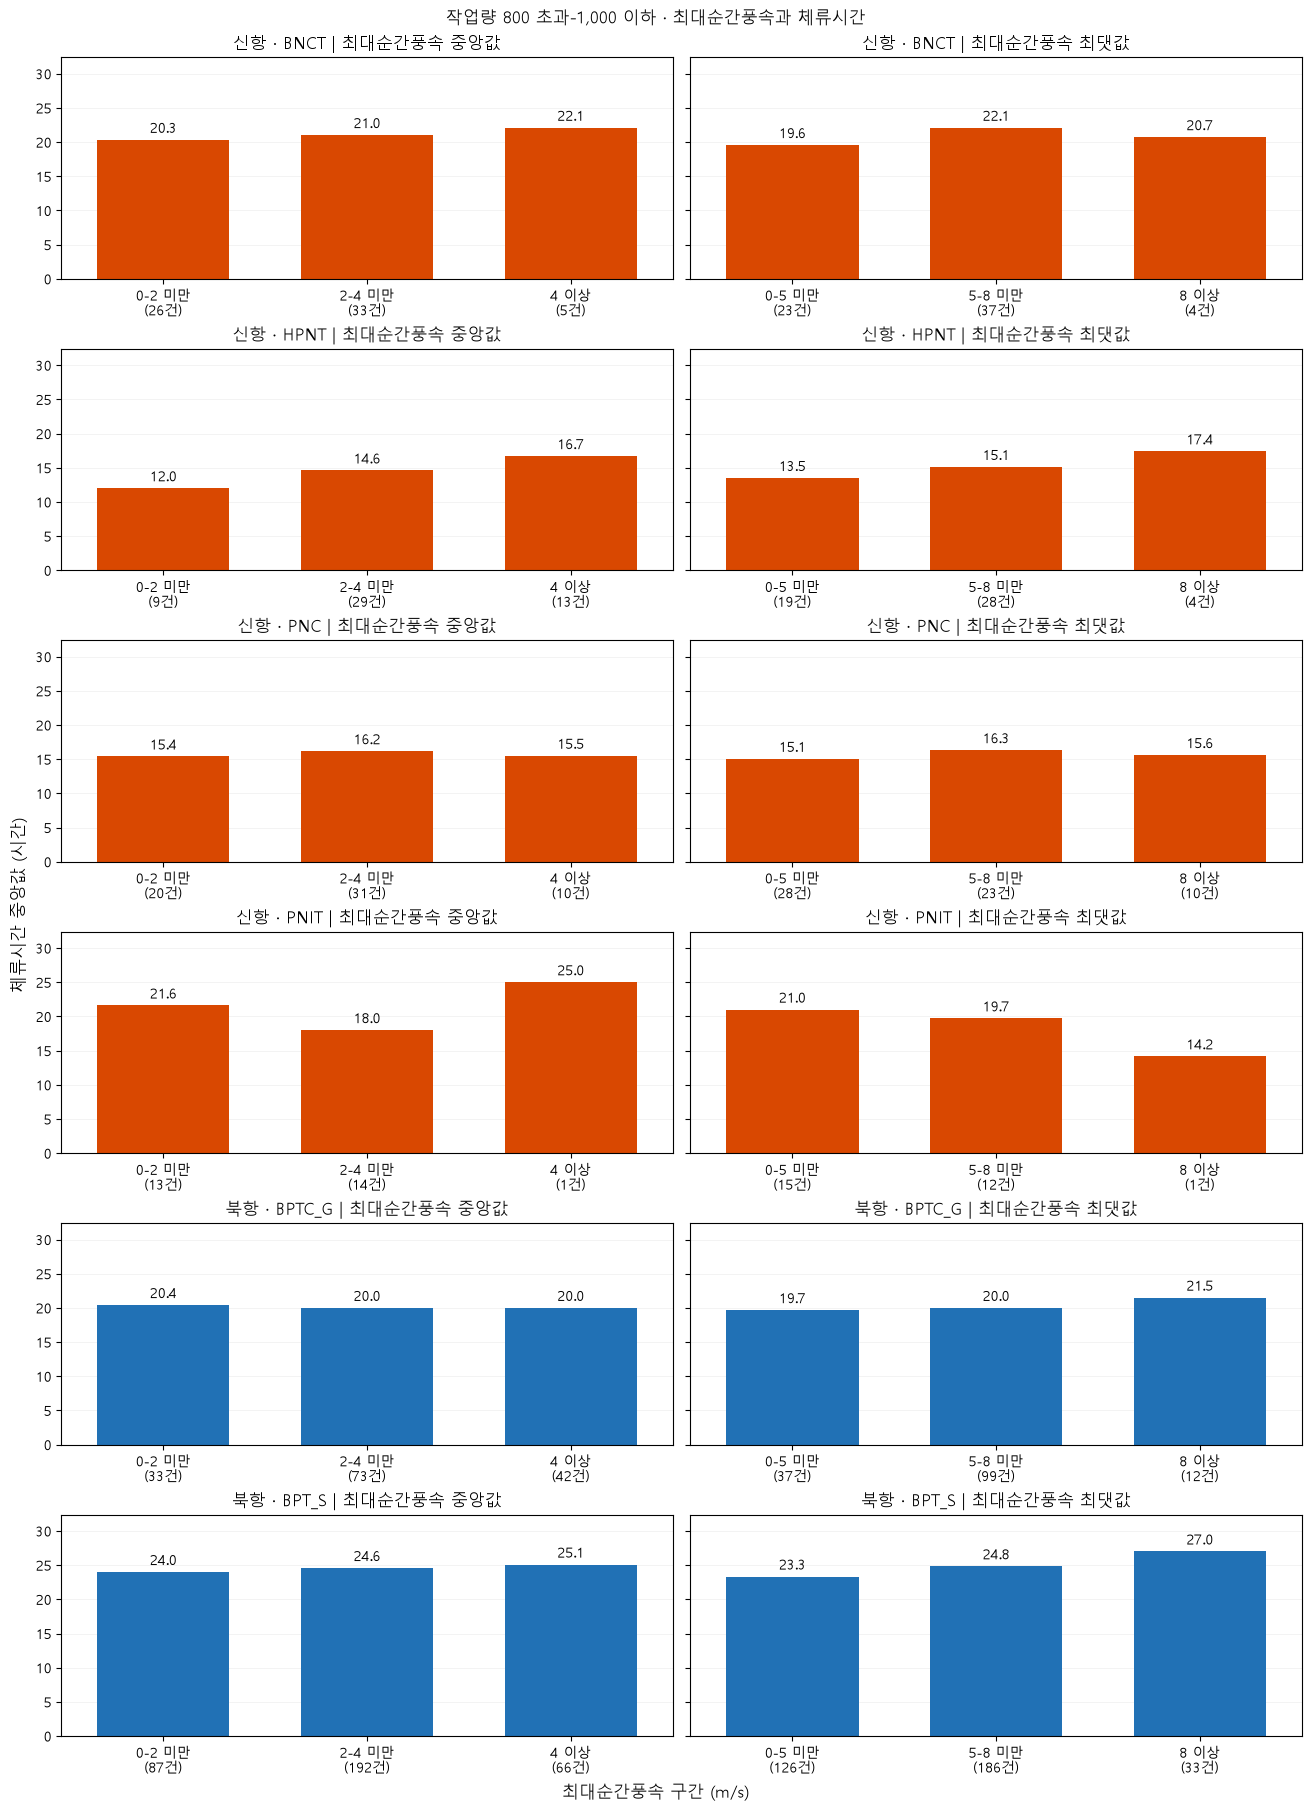

In [67]:
# 모든 패널의 세로축을 통일해 체류시간을 비교한다.
fig, axes = plt.subplots(
    len(터미널목록), 2, figsize=(13, 18),
    sharey=True, layout="constrained",
)

for 행, 터미널 in enumerate(터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    색 = "#2171B5" if 북항 else "#D94801"

    for 열번호, (종류, (_, _, 구간명)) in enumerate(돌풍설정2.items()):
        ax = axes[행, 열번호]
        결과표 = 돌풍결과2[종류]
        인덱스 = pd.MultiIndex.from_product(
            [[터미널], 구간명], names=결과표.index.names
        )
        자료 = 결과표.reindex(인덱스)
        건수 = 자료["기록수"].fillna(0).astype(int).to_numpy()
        위치 = np.arange(len(구간명))
        유효 = 건수 > 0

        막대 = ax.bar(
            위치[유효], 자료.loc[유효, "체류시간_중앙값"].to_numpy(dtype=float),
            width=0.65, color=색,
        )
        ax.bar_label(막대, fmt="%.1f", padding=3)
        ax.set_xticks(
            위치, [f"{구간}\n({n}건)" for 구간, n in zip(구간명, 건수)]
        )
        ax.set_xlim(-0.5, len(구간명) - 0.5)
        ax.set_title(f"{항만} · {터미널} | 최대순간풍속 {종류}")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)

최대시간 = pd.concat(돌풍결과2.values())["체류시간_중앙값"].max()
axes[0, 0].set_ylim(0, 최대시간 * 1.2 if pd.notna(최대시간) and 최대시간 > 0 else 1)

fig.suptitle("작업량 800 초과-1,000 이하 · 최대순간풍속과 체류시간")
fig.supxlabel("최대순간풍속 구간 (m/s)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

작업량 800 초과-1,000 이하 집단에서 최대순간풍속 중앙값 구간이 높아질수록 BNCT·HPNT·BPT_S의 체류시간 중앙값이 증가했다. BPTC_G는 20.42 → 20.00 → 20.00시간으로 변화가 작았다.

최대순간풍속 최댓값 기준으로는 BPTC_G(19.67 → 20.00 → 21.50시간), BPT_S(23.33 → 24.83 → 27.00시간), HPNT(13.50 → 15.12 → 17.40시간)에서 체류시간 중앙값이 증가했다. 세 터미널 모두 작업량 600-800 집단에서도 같은 증가 방향을 보였다.

In [68]:
유의파고열2 = [
    "체류시간_유의파고_중앙값_m",
    "체류시간_유의파고_최댓값_m",
]

for 열 in 유의파고열2:
    분포 = 후보2.groupby("터미널")[열].agg(
        유효건수="count",
        결측건수=lambda s: s.isna().sum(),
        최솟값="min",
        중앙값="median",
        상위25퍼센트_경계=lambda s: s.quantile(0.75),
        최댓값="max",
    ).reindex(터미널목록)

    print(열)
    display(분포.round(2))

체류시간_유의파고_중앙값_m


,유효건수,결측건수,최솟값,중앙값,상위25퍼센트_경계,최댓값
터미널,,,,,,
BNCT,66,0,0.1,0.30,0.50,1.40
HPNT,52,0,0.2,0.35,0.56,1.55
PNC,64,1,0.1,0.40,0.50,1.10
PNIT,28,0,0.2,0.38,0.56,1.35
BPTC_G,149,1,0.1,0.50,0.75,2.00
BPT_S,354,5,0.2,0.50,0.80,2.25


체류시간_유의파고_최댓값_m


,유효건수,결측건수,최솟값,중앙값,상위25퍼센트_경계,최댓값
터미널,,,,,,
BNCT,66,0,0.2,0.50,0.78,1.9
HPNT,52,0,0.3,0.50,0.80,1.9
PNC,64,1,0.2,0.50,0.80,1.8
PNIT,28,0,0.2,0.45,0.80,1.7
BPTC_G,149,1,0.2,0.70,1.20,2.8
BPT_S,354,5,0.3,0.80,1.20,3.7


In [69]:
유의파고설정2 = {
    "중앙값": "체류시간_유의파고_중앙값_m",
    "최댓값": "체류시간_유의파고_최댓값_m",
}
유의파고순서2 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]
유의파고결과2 = {}

for 종류, 열 in 유의파고설정2.items():
    자료 = 후보2.copy()
    자료["파고구간"] = pd.cut(
        자료[열],
        bins=[0, 1, 2, 3, float("inf")],
        labels=유의파고순서2,
        right=False,
    )

    유의파고결과2[종류] = (
        자료.groupby(["터미널", "파고구간"], observed=False)
        .agg(
            기록수=("체류시간", "count"),
            작업량_중앙값=("총작업량", "median"),
            총톤수_중앙값=("총톤수", "median"),
            체류시간_중앙값=("체류시간", "median"),
        )
        .reindex(터미널목록, level="터미널")
    )

    print(f"유의파고 {종류} 기준 (m)")
    display(유의파고결과2[종류].round(2))

유의파고 중앙값 기준 (m)


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    파고구간                                   
BNCT   0-1 미만   64    885.5  17594.0     21.33
       1-2 미만    2    875.0  18485.0     19.50
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
HPNT   0-1 미만   48    889.0  18017.0     14.83
       1-2 미만    4    928.5  18678.0     17.42
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNC    0-1 미만   63    884.0  18327.0     15.97
       1-2 미만    1    842.0  18826.0     17.08
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNIT   0-1 미만   27    927.0  18334.0     21.00
       1-2 미만    1    804.0  18334.0     14.17
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
BPTC_G 0-1 미만  127    902.0  15906.0     20.00
       1-2 미만   21    925.0  18326.0     19.00
       2-3 미만    1    943.0  18502.0     15.00
       3 이상      0      NaN      NaN       NaN
BPT_S  0-1 미만  301    891.0  18040.0     24.00
       1-2 미만   50    887.5  18051.0     25.00
       2-3 미만    3    837.0  13199.0     30.00
       3 이상      0      NaN      NaN       NaN

유의파고 최댓값 기준 (m)


기록수  작업량_중앙값  총톤수_중앙값  체류시간_중앙값
터미널    파고구간                                   
BNCT   0-1 미만   58    888.0  17594.0     21.72
       1-2 미만    8    876.5  17166.0     20.71
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
HPNT   0-1 미만   41    889.0  18017.0     14.60
       1-2 미만   11    897.0  18017.0     17.00
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNC    0-1 미만   57    886.0  18327.0     15.62
       1-2 미만    7    842.0  18680.0     17.75
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
PNIT   0-1 미만   25    927.0  18334.0     21.00
       1-2 미만    3    869.0  18334.0     17.17
       2-3 미만    0      NaN      NaN       NaN
       3 이상      0      NaN      NaN       NaN
BPTC_G 0-1 미만   98    899.0  15597.0     21.00
       1-2 미만   41    916.0  18051.0     19.00
       2-3 미만   10    920.5  18502.0     18.17
       3 이상      0      NaN      NaN       NaN
BPT_S  0-1 미만  213    887.0  17933.0     24.00
       1-2 미만  117    892.0  18051.0     24.00
       2-3 미만   20    916.0  17921.0     25.50
       3 이상      4    890.5  15495.0     31.00

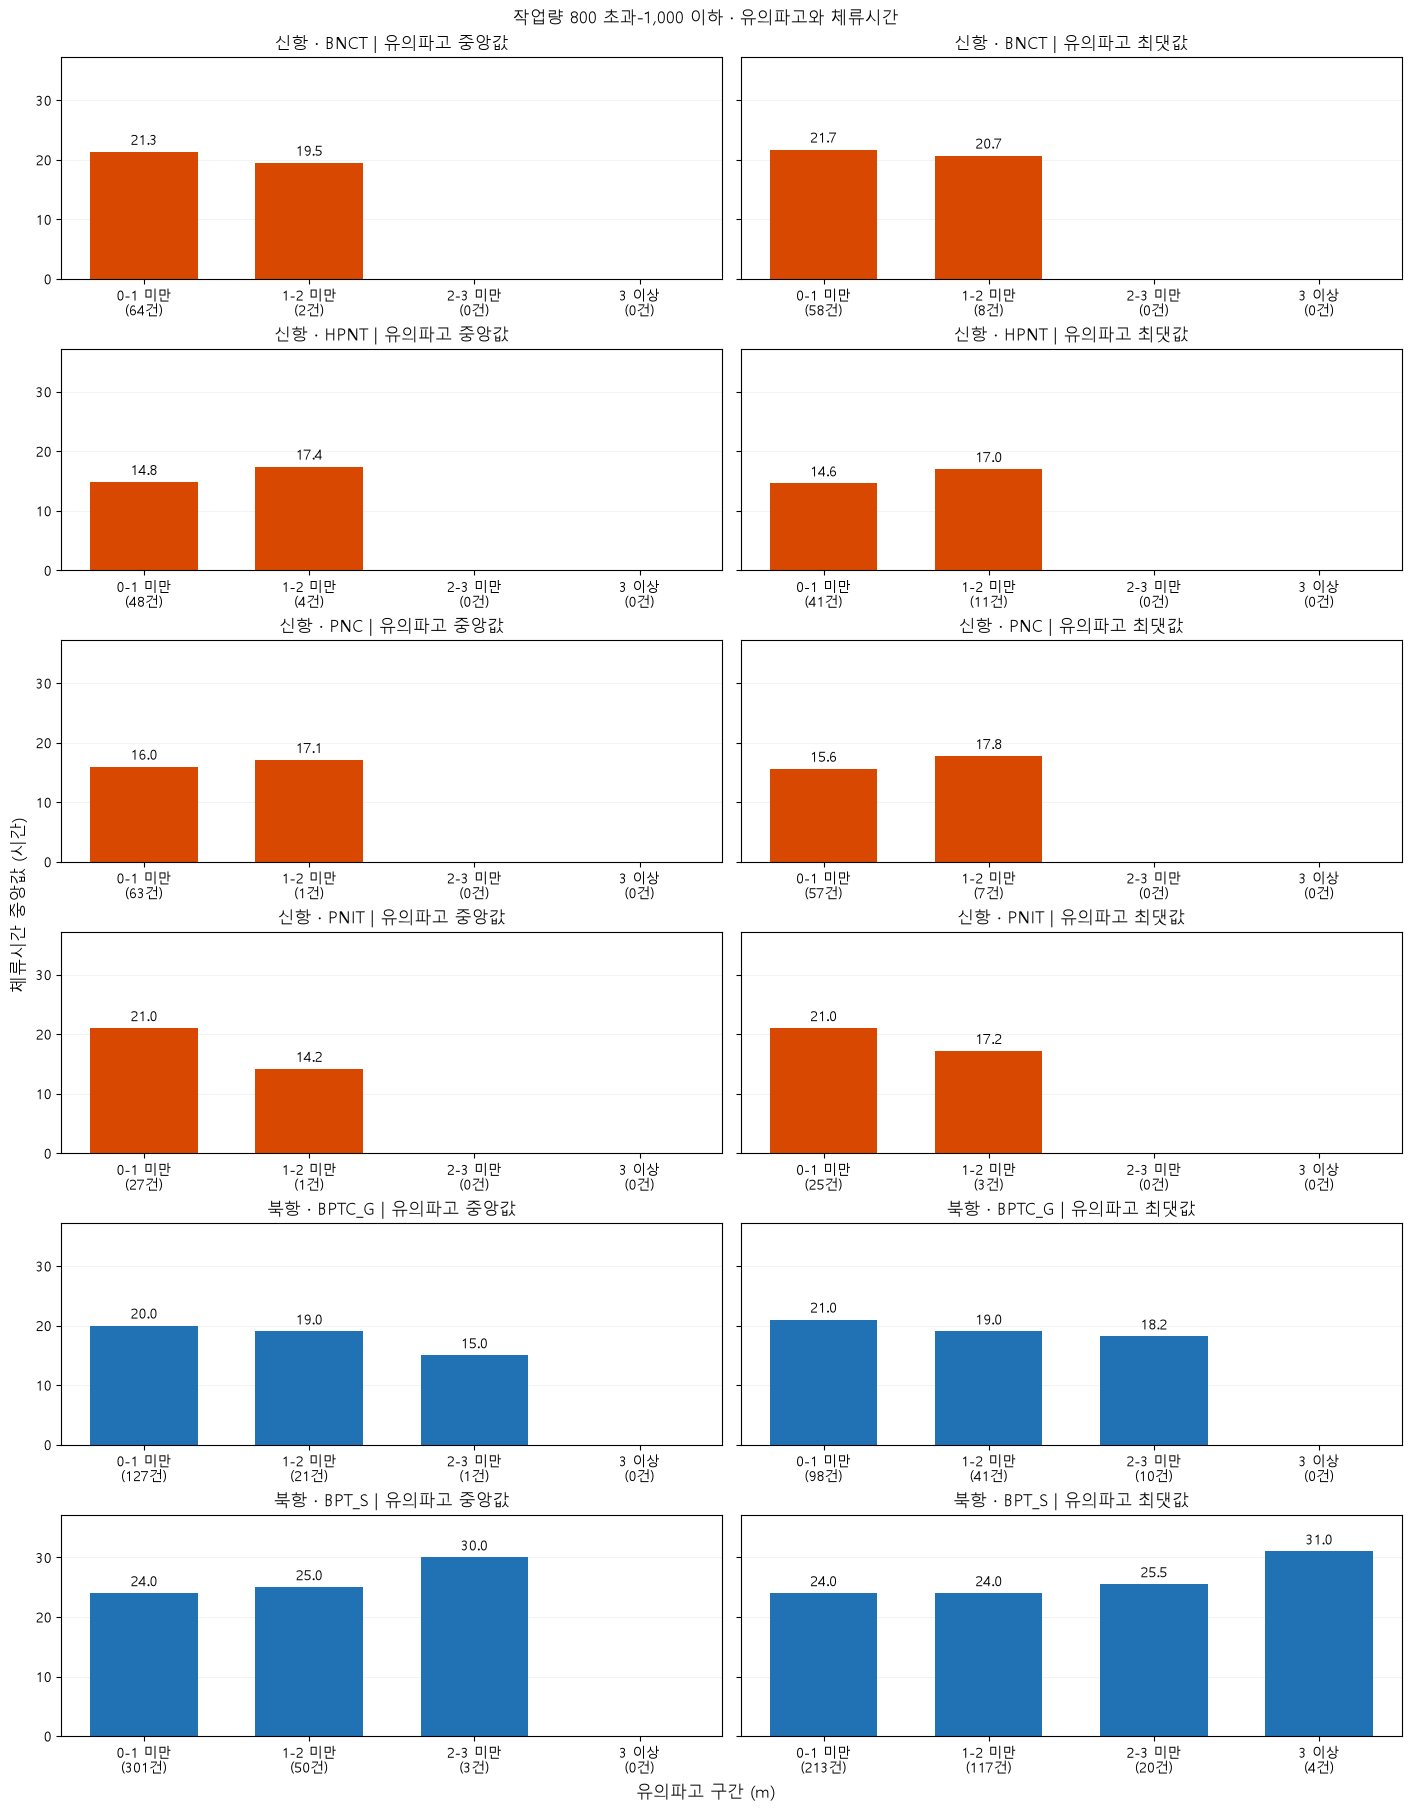

In [70]:
# 터미널별로 두 유의파고 지표의 체류시간을 같은 세로축에서 비교한다.
fig, axes = plt.subplots(
    len(터미널목록), 2, figsize=(14, 18),
    sharey=True, layout="constrained",
)
위치 = np.arange(len(유의파고순서2))

for 행, 터미널 in enumerate(터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    색 = "#2171B5" if 북항 else "#D94801"

    for 열번호, 종류 in enumerate(["중앙값", "최댓값"]):
        ax = axes[행, 열번호]
        표 = 유의파고결과2[종류]
        인덱스 = pd.MultiIndex.from_product(
            [[터미널], 유의파고순서2], names=표.index.names
        )
        자료 = 표.reindex(인덱스)
        건수 = 자료["기록수"].fillna(0).astype(int).to_numpy()
        유효 = 건수 > 0

        막대 = ax.bar(
            위치[유효],
            자료.loc[유효, "체류시간_중앙값"].to_numpy(dtype=float),
            width=0.65, color=색,
        )
        ax.bar_label(막대, fmt="%.1f", padding=3)
        ax.set_xticks(
            위치, [f"{구간}\n({n}건)" for 구간, n in zip(유의파고순서2, 건수)]
        )
        ax.set_xlim(-0.5, len(위치) - 0.5)
        ax.set_title(f"{항만} · {터미널} | 유의파고 {종류}")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)

최대시간 = pd.concat(유의파고결과2.values())["체류시간_중앙값"].max()
if pd.notna(최대시간) and 최대시간 > 0:
    axes[0, 0].set_ylim(0, 최대시간 * 1.2)

fig.suptitle("작업량 800 초과-1,000 이하 · 유의파고와 체류시간")
fig.supxlabel("유의파고 구간 (m)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- 작업량 800 초과-1,000 이하 집단에서 유의파고 중앙값은 6개 터미널 모두 1m 미만에 집중됐다. 2m 이상은 북항의 4건뿐이었다.
- 유의파고 최댓값 구간이 높아질수록 BPT_S의 체류시간 중앙값은 24.00 → 24.00 → 25.50 → 31.00시간으로 늘었지만, BPTC_G는 21.00 → 19.00 → 18.17시간으로 줄었다.
- 최댓값 2m 이상인 기록은 북항에서만 관측됐고, BPT_S의 3m 이상은 4건이었다. 파고가 높을수록 체류시간이 길어지는 경향은 터미널 전반에서 일관되게 나타나지 않았다.

In [71]:
# 터미널별로 순간최대파고가 어느 범위에 분포하는지 확인한다.
순간파고설정2 = {
    "중앙값": "체류시간_순간최대파고_중앙값_m",
    "최댓값": "체류시간_순간최대파고_최댓값_m",
}

for 종류, 열 in 순간파고설정2.items():
    분포 = 후보2.groupby("터미널")[열].agg(
        유효건수="count",
        결측건수=lambda s: s.isna().sum(),
        최솟값="min",
        중앙값="median",
        상위25퍼센트_경계=lambda s: s.quantile(0.75),
        최댓값="max",
    ).reindex(터미널목록)

    print(f"순간최대파고 {종류} 분포 (m)")
    display(분포.round(2))

순간최대파고 중앙값 분포 (m)


,유효건수,결측건수,최솟값,중앙값,상위25퍼센트_경계,최댓값
터미널,,,,,,
BNCT,66,0,0.1,0.40,0.6,1.90
HPNT,52,0,0.2,0.50,0.8,2.10
PNC,64,1,0.2,0.50,0.7,1.60
PNIT,28,0,0.2,0.48,0.7,1.75
BPTC_G,149,1,0.2,0.70,1.0,2.90
BPT_S,354,5,0.2,0.68,1.0,3.30


순간최대파고 최댓값 분포 (m)


,유효건수,결측건수,최솟값,중앙값,상위25퍼센트_경계,최댓값
터미널,,,,,,
BNCT,66,0,0.3,0.70,1.08,2.5
HPNT,52,0,0.4,0.65,1.15,2.6
PNC,64,1,0.2,0.80,1.10,2.6
PNIT,28,0,0.3,0.70,1.10,2.2
BPTC_G,149,1,0.2,1.00,1.60,4.1
BPT_S,354,5,0.4,1.10,1.60,5.1


In [72]:
중앙열2 = 순간파고설정2["중앙값"]
최대열2 = 순간파고설정2["최댓값"]
순간파고순서2 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]

순간파고비교2 = 후보2.dropna(subset=[중앙열2, 최대열2]).copy()
순간파고비교2["최댓값구간"] = pd.cut(
    순간파고비교2[최대열2],
    bins=[0, 1, 2, 3, float("inf")],
    labels=순간파고순서2,
    right=False,
)

# 두 파고 지표를 같은 입항 기록에서 각각 중앙값으로 요약한다.
순간파고비교표2 = 순간파고비교2.groupby(
    ["터미널", "최댓값구간"], observed=True
).agg(
    기록수=(최대열2, "size"),
    파고중앙값_대표_m=(중앙열2, "median"),
    파고최댓값_대표_m=(최대열2, "median"),
)

전체구간2 = pd.MultiIndex.from_product(
    [터미널목록, 순간파고순서2],
    names=["터미널", "최댓값구간"],
)
순간파고비교표2 = 순간파고비교표2.reindex(전체구간2)
순간파고비교표2["기록수"] = 순간파고비교표2["기록수"].fillna(0).astype(int)

display(순간파고비교표2.round(2))

기록수  파고중앙값_대표_m  파고최댓값_대표_m
터미널    최댓값구간                              
BNCT   0-1 미만   46        0.40        0.55
       1-2 미만   18        0.72        1.30
       2-3 미만    2        1.60        2.40
       3 이상      0         NaN         NaN
HPNT   0-1 미만   34        0.40        0.60
       1-2 미만   14        0.80        1.35
       2-3 미만    4        1.45        2.45
       3 이상      0         NaN         NaN
PNC    0-1 미만   43        0.40        0.60
       1-2 미만   18        0.80        1.10
       2-3 미만    3        1.20        2.30
       3 이상      0         NaN         NaN
PNIT   0-1 미만   17        0.30        0.50
       1-2 미만   10        0.75        1.15
       2-3 미만    1        1.75        2.20
       3 이상      0         NaN         NaN
BPTC_G 0-1 미만   66        0.50        0.70
       1-2 미만   60        0.80        1.25
       2-3 미만   15        1.50        2.40
       3 이상      8        2.02        3.65
BPT_S  0-1 미만  144        0.50        0.70
       1-2 미만  145        0.80        1.30
       2-3 미만   46        1.40        2.25
       3 이상     19        2.15        3.30

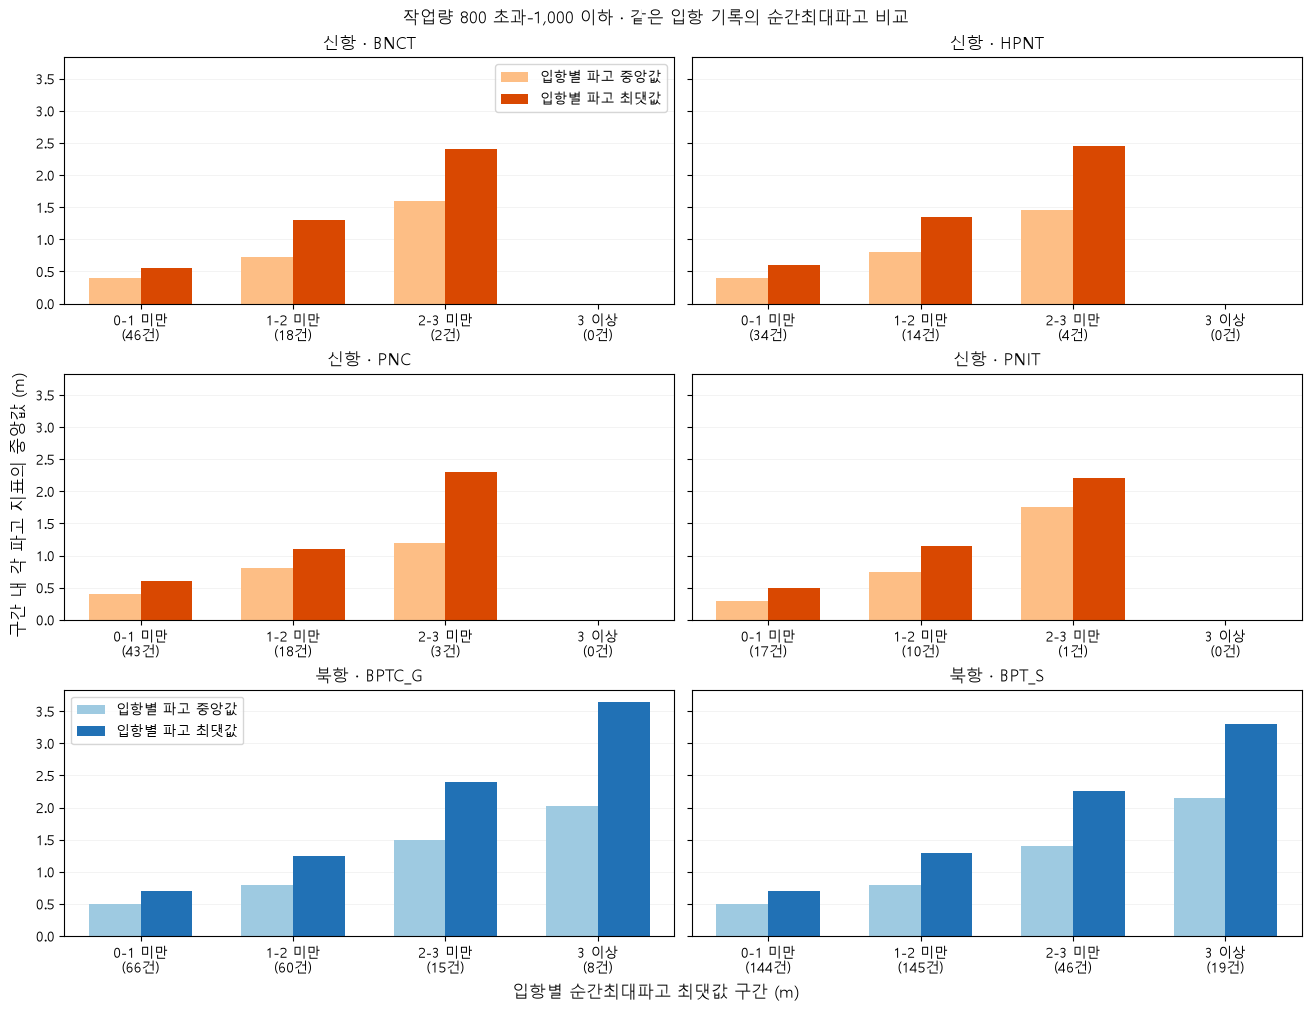

In [73]:
# 같은 입항 기록의 두 파고 지표를 최댓값 구간별로 나란히 그린다.
fig, axes = plt.subplots(
    3, 2, figsize=(13, 10), sharey=True, layout="constrained"
)
위치 = np.arange(len(순간파고순서2))
폭 = 0.34

for ax, 터미널 in zip(axes.flat, 터미널목록):
    자료 = 순간파고비교표2.xs(터미널, level="터미널").reindex(순간파고순서2)
    건수 = 자료["기록수"].to_numpy()
    유효 = 건수 > 0

    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    중앙색, 최대색 = (
        ("#9ECAE1", "#2171B5") if 북항 else ("#FDBE85", "#D94801")
    )

    ax.bar(
        위치[유효] - 폭 / 2,
        자료.loc[유효, "파고중앙값_대표_m"].to_numpy(dtype=float),
        width=폭, color=중앙색, label="입항별 파고 중앙값",
    )
    ax.bar(
        위치[유효] + 폭 / 2,
        자료.loc[유효, "파고최댓값_대표_m"].to_numpy(dtype=float),
        width=폭, color=최대색, label="입항별 파고 최댓값",
    )

    ax.set_xticks(
        위치, [f"{구간}\n({n}건)" for 구간, n in zip(순간파고순서2, 건수)]
    )
    ax.set_xlim(-0.5, len(위치) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

axes[0, 0].legend()  # 신항
axes[2, 0].legend()  # 북항

fig.suptitle("작업량 800 초과-1,000 이하 · 같은 입항 기록의 순간최대파고 비교")
fig.supxlabel("입항별 순간최대파고 최댓값 구간 (m)")
fig.supylabel("구간 내 각 파고 지표의 중앙값 (m)")
그림표시()

- 작업량 800 초과-1,000 이하 집단에서 신항 4개 터미널은 모두 순간최대파고 최댓값 1m 미만에 기록이 가장 많았다. 북항 BPT_S는 1m 미만 144건, 1-2m 미만 145건으로 두 구간의 건수가 비슷했다.
- 최댓값 3m 이상인 기록은 북항에서만 관측됐다. BPTC_G는 8건으로 두 막대가 각각 2.02m와 3.65m였고, BPT_S는 19건으로 2.15m와 3.30m였다.
- 두 막대는 같은 입항 기록을 요약한다. 북항의 3m 이상 구간에서도 체류 중 전반적인 파고 수준을 보여주는 중앙값 막대는 두 터미널 모두 약 2m였다.

In [74]:
시정설정2 = {
    "최솟값": "체류시간_시정_최솟값_10m",
    "중앙값": "체류시간_시정_중앙값_10m",
}
시정자료2 = 후보2.copy()

for 종류, 열 in 시정설정2.items():
    # "1,000"처럼 쉼표가 포함된 값도 숫자로 변환한다.
    시정자료2[열] = pd.to_numeric(
        시정자료2[열].astype("string").str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )

    분포 = 시정자료2.groupby("터미널")[열].agg(
        유효건수="count",
        결측건수=lambda s: s.isna().sum(),
        최솟값="min",
        중앙값="median",
        최댓값="max",
    ).reindex(터미널목록)

    print(f"시정 {종류} 분포 (10m 단위)")
    display(분포.round(2))

시정 최솟값 분포 (10m 단위)


,유효건수,결측건수,최솟값,중앙값,최댓값
터미널,,,,,
BNCT,66,0,43.0,1832.5,5000.0
HPNT,52,0,55.0,2356.0,5000.0
PNC,65,0,60.0,2265.0,5000.0
PNIT,28,0,21.0,1105.0,5000.0
BPTC_G,150,0,21.0,2010.0,5000.0
BPT_S,359,0,16.0,1880.0,5000.0


시정 중앙값 분포 (10m 단위)


,유효건수,결측건수,최솟값,중앙값,최댓값
터미널,,,,,
BNCT,66,0,175.0,3784.5,5000.0
HPNT,52,0,382.0,3638.5,5000.0
PNC,65,0,228.0,4040.0,5000.0
PNIT,28,0,332.5,1887.5,5000.0
BPTC_G,150,0,247.0,4156.75,5000.0
BPT_S,359,0,152.5,4018.0,5000.0


In [75]:
시정최소열2 = 시정설정2["최솟값"]
시정중앙열2 = 시정설정2["중앙값"]
시정구간명2 = ["0-100 미만", "100-500 미만", "500-1,000 미만", "1,000 이상"]

# 앞 셀에서 숫자로 변환한 자료를 사용한다.
시정비교2 = 시정자료2.dropna(
    subset=[시정최소열2, 시정중앙열2, "체류시간"]
).copy()

시정비교2["최저시정구간"] = pd.cut(
    시정비교2[시정최소열2],
    bins=[0, 100, 500, 1_000, float("inf")],
    labels=시정구간명2,
    right=False,
)

시정결과2 = 시정비교2.groupby(
    ["터미널", "최저시정구간"], observed=True
).agg(
    기록수=("체류시간", "size"),
    시정최솟값_대표_10m=(시정최소열2, "median"),
    시정중앙값_대표_10m=(시정중앙열2, "median"),
    체류시간_중앙값=("체류시간", "median"),
)

시정전체구간2 = pd.MultiIndex.from_product(
    [터미널목록, 시정구간명2],
    names=["터미널", "최저시정구간"],
)
시정결과2 = 시정결과2.reindex(시정전체구간2)
시정결과2["기록수"] = 시정결과2["기록수"].fillna(0).astype(int)

display(시정결과2.round(2))

기록수  시정최솟값_대표_10m  시정중앙값_대표_10m  체류시간_중앙값
터미널    최저시정구간                                                 
BNCT   0-100 미만        4          65.5        926.25     20.11
       100-500 미만      8         301.5        3253.0     22.77
       500-1,000 미만   11         834.0        2525.0     22.10
       1,000 이상       43        2574.0        4608.0     20.88
HPNT   0-100 미만        2          60.5        1007.0     14.02
       100-500 미만      4         244.5        943.25     16.00
       500-1,000 미만    7         723.0        2077.0     18.80
       1,000 이상       39        2802.0        3922.0     14.60
PNC    0-100 미만        2          63.0        1477.5     16.03
       100-500 미만     11         240.0        1316.0     17.75
       500-1,000 미만    4         759.0        1159.5     15.99
       1,000 이상       48        2727.0        4541.0     15.34
PNIT   0-100 미만        1          21.0         792.0     22.80
       100-500 미만      6         269.0        888.75     22.80
       500-1,000 미만    6         821.0        1462.5     21.55
       1,000 이상       15        2713.0        3827.0     16.80
BPTC_G 0-100 미만        6          56.0         955.0     22.17
       100-500 미만     22         254.5        1467.5     19.04
       500-1,000 미만   18         687.0        1522.5     18.75
       1,000 이상      104        2903.0       4895.75     20.75
BPT_S  0-100 미만       11          68.0         808.0     24.83
       100-500 미만     57         307.0        1861.5     25.00
       500-1,000 미만   32         758.0       2516.25     25.00
       1,000 이상      259        2544.0        4571.5     24.00

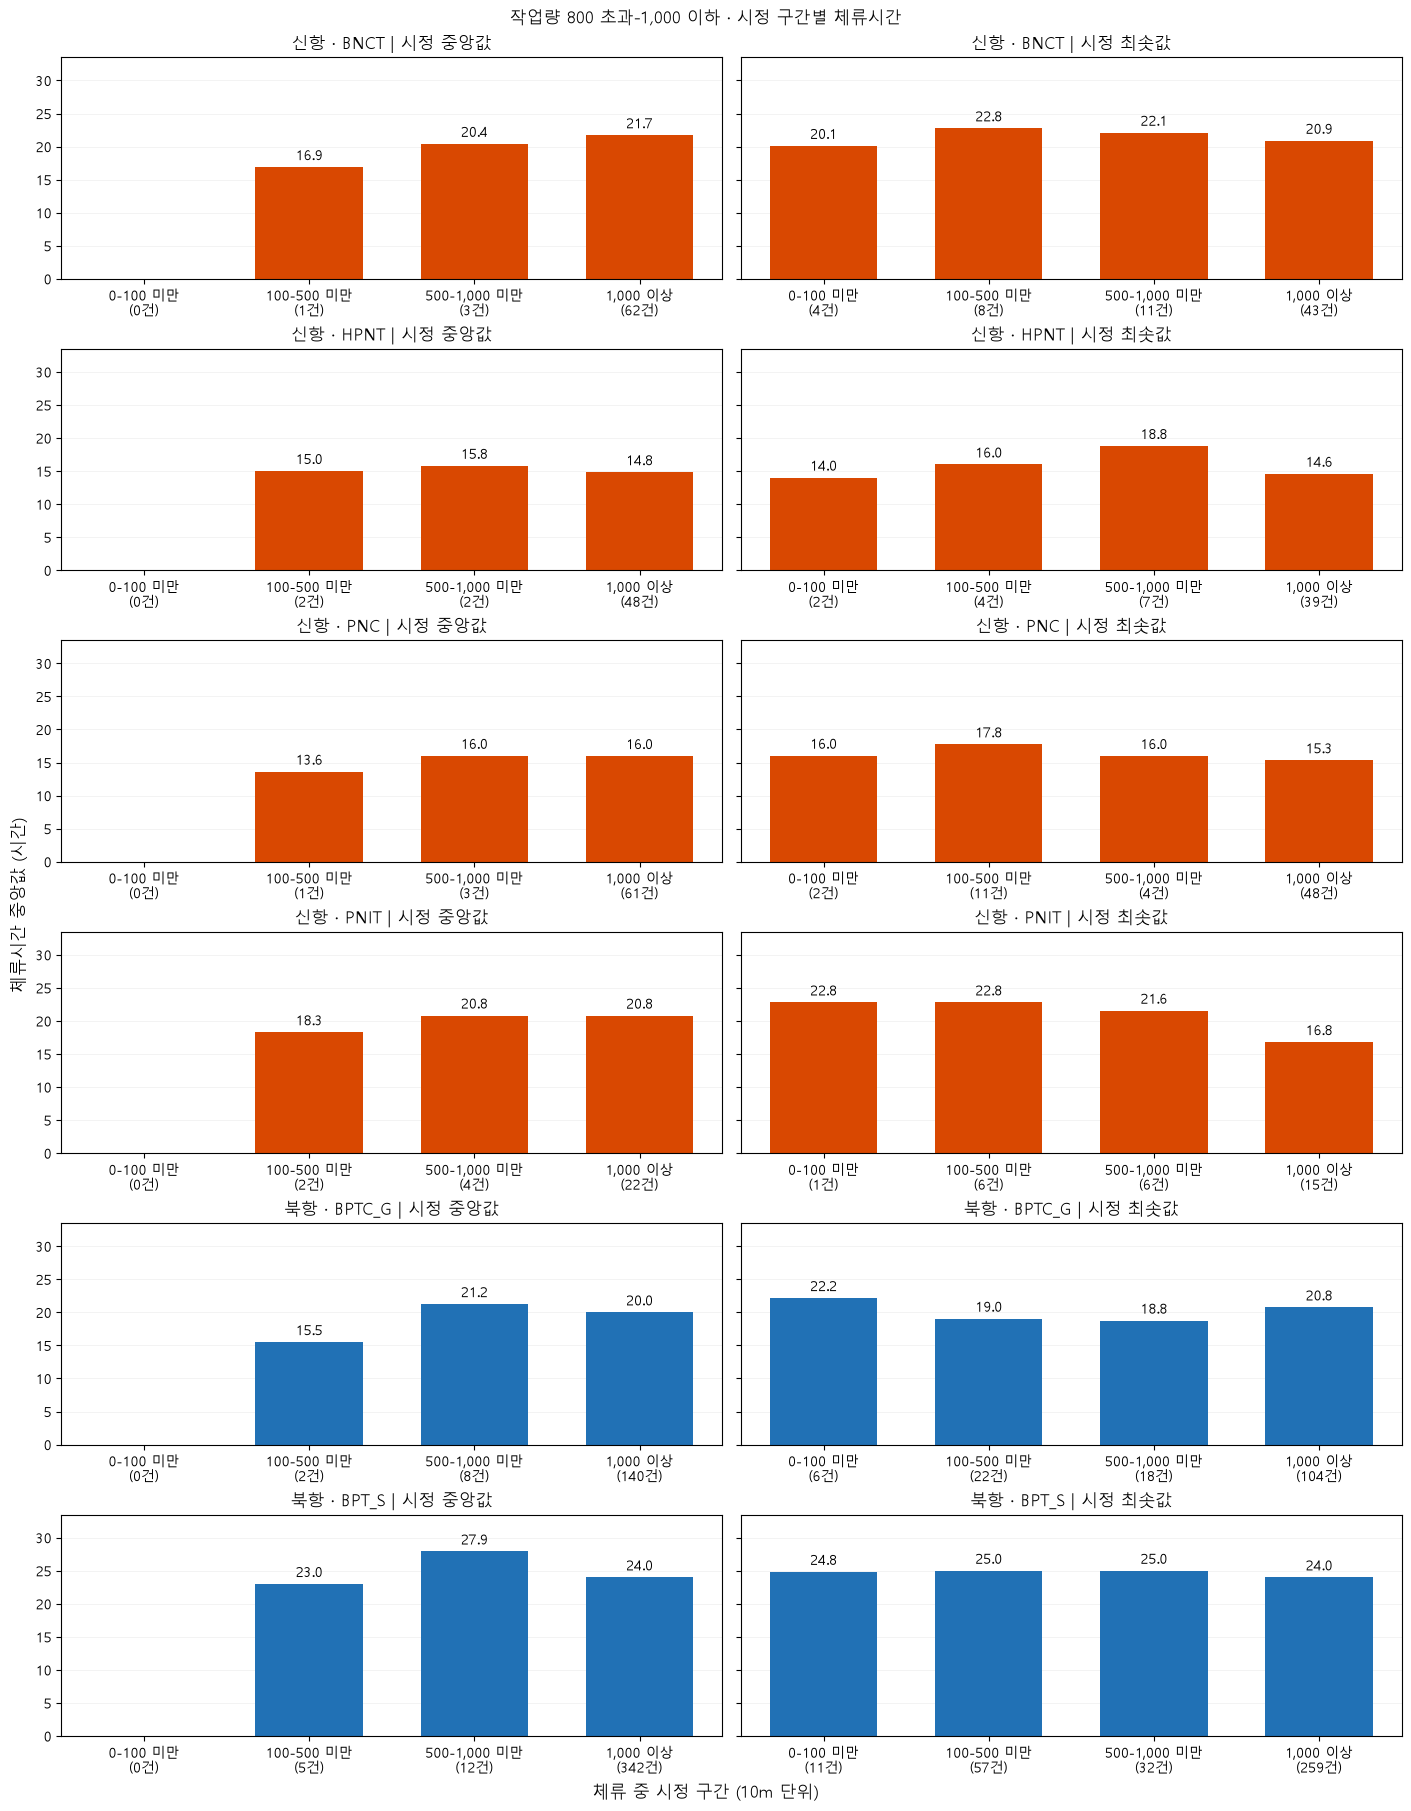

In [76]:
# 같은 입항 기록을 시정 중앙값과 최솟값 기준으로 각각 구간화한다.
시정체류결과2 = {}

for 종류 in ["중앙값", "최솟값"]:
    열 = 시정설정2[종류]
    자료 = 시정비교2.copy()
    자료["시정구간"] = pd.cut(
        자료[열],
        bins=[0, 100, 500, 1_000, float("inf")],
        labels=시정구간명2,
        right=False,
    )

    시정체류결과2[종류] = 자료.groupby(
        ["터미널", "시정구간"], observed=True
    ).agg(
        기록수=("체류시간", "count"),
        체류시간_중앙값=("체류시간", "median"),
    )

fig, axes = plt.subplots(
    len(터미널목록), 2, figsize=(14, 18),
    sharey=True, layout="constrained",
)
위치 = np.arange(len(시정구간명2))

for 행, 터미널 in enumerate(터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    색 = "#2171B5" if 북항 else "#D94801"

    for 열번호, 종류 in enumerate(["중앙값", "최솟값"]):
        ax = axes[행, 열번호]
        인덱스 = pd.MultiIndex.from_product(
            [[터미널], 시정구간명2], names=["터미널", "시정구간"]
        )
        표 = 시정체류결과2[종류].reindex(인덱스)
        건수 = 표["기록수"].fillna(0).astype(int).to_numpy()
        유효 = 건수 > 0

        막대 = ax.bar(
            위치[유효],
            표.loc[유효, "체류시간_중앙값"].to_numpy(dtype=float),
            width=0.65,
            color=색,
        )
        ax.bar_label(막대, fmt="%.1f", padding=3)
        ax.set_xticks(
            위치, [f"{구간}\n({n}건)" for 구간, n in zip(시정구간명2, 건수)]
        )
        ax.set_xlim(-0.5, len(위치) - 0.5)
        ax.set_title(f"{항만} · {터미널} | 시정 {종류}")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)

최대시간 = pd.concat(시정체류결과2.values())["체류시간_중앙값"].max()
if pd.notna(최대시간) and 최대시간 > 0:
    axes[0, 0].set_ylim(0, 최대시간 * 1.2)

fig.suptitle("작업량 800 초과-1,000 이하 · 시정 구간별 체류시간")
fig.supxlabel("체류 중 시정 구간 (10m 단위)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- 시정 최솟값 기준으로 1,000 이상 구간(원자료 10m 단위)에 508건(70.6%)이 집중됐으며, 6개 터미널 모두 이 구간의 기록이 가장 많았다.
- PNIT는 시정 최솟값 100-500 미만에서 체류시간 중앙값이 22.80시간, 1,000 이상에서 16.80시간이었다. 반면 BPT_S는 네 구간 모두 24.00-25.00시간으로 차이가 작았다.
- 시정 최솟값이 낮을수록 체류시간이 길어지는 경향은 터미널 전반에서 일관되게 나타나지 않았다. 특히 100 미만 구간은 터미널별 1-11건이어서 해석에 주의가 필요하다.

In [77]:
# 체류 중 특보 노출이 0시간인 기록과 0시간을 초과한 기록을 비교한다.
특보열2 = "체류시간_특보노출시간"
특보순서2 = ["특보 노출 없음", "특보 노출 있음"]

특보비교2 = 후보2.copy()
특보비교2[특보열2] = pd.to_numeric(특보비교2[특보열2], errors="coerce")
특보비교2 = 특보비교2.loc[특보비교2[특보열2].ge(0)].copy()

특보비교2["특보여부"] = np.where(
    특보비교2[특보열2].gt(0), "특보 노출 있음", "특보 노출 없음"
)

특보결과2 = 특보비교2.groupby(["터미널", "특보여부"]).agg(
    기록수=("체류시간", "count"),
    체류시간_중앙값=("체류시간", "median"),
).reindex(pd.MultiIndex.from_product(
    [터미널목록, 특보순서2], names=["터미널", "특보여부"]
))

특보결과2["기록수"] = 특보결과2["기록수"].fillna(0).astype(int)
display(특보결과2.round(2))

기록수  체류시간_중앙값
터미널    특보여부                   
BNCT   특보 노출 없음   59     21.80
       특보 노출 있음    7     20.42
HPNT   특보 노출 없음   42     14.30
       특보 노출 있음   10     16.10
PNC    특보 노출 없음   58     15.79
       특보 노출 있음    7     17.00
PNIT   특보 노출 없음   26     20.80
       특보 노출 있음    2     18.88
BPTC_G 특보 노출 없음  127     20.00
       특보 노출 있음   23     20.00
BPT_S  특보 노출 없음  295     24.00
       특보 노출 있음   64     25.00

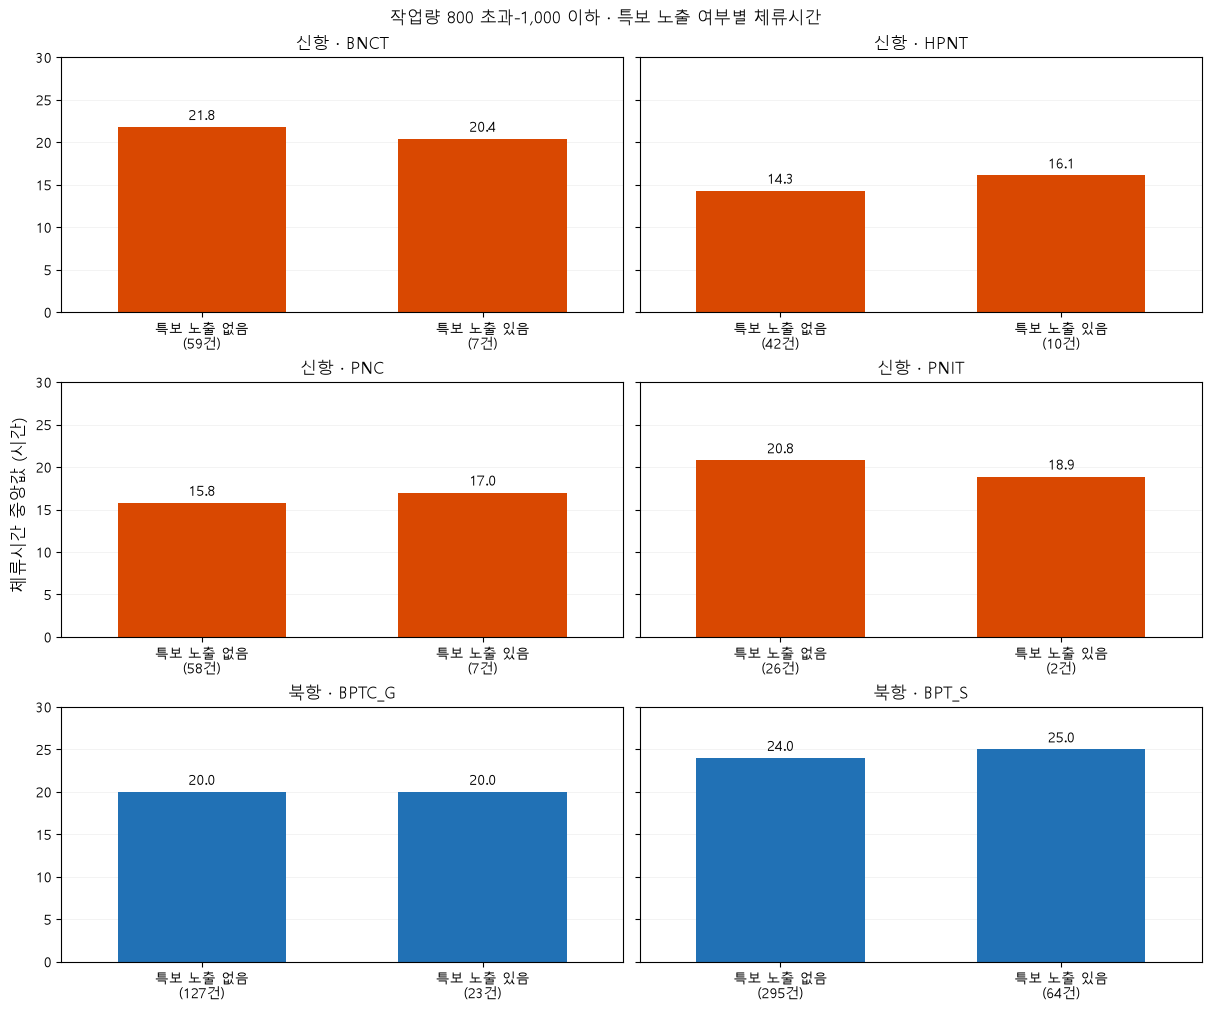

In [78]:
# 특보 노출 여부에 따른 체류시간을 터미널별로 비교한다.
fig, axes = plt.subplots(
    3, 2, figsize=(12, 10), sharey=True, layout="constrained"
)
위치 = np.arange(len(특보순서2))

for ax, 터미널 in zip(axes.flat, 터미널목록):
    자료 = 특보결과2.xs(터미널, level="터미널").reindex(특보순서2)
    건수 = 자료["기록수"].to_numpy()
    유효 = 건수 > 0

    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"

    막대 = ax.bar(
        위치[유효],
        자료.loc[유효, "체류시간_중앙값"].to_numpy(dtype=float),
        width=0.6,
        color="#2171B5" if 북항 else "#D94801",
    )
    ax.bar_label(막대, fmt="%.1f", padding=3)
    ax.set_xticks(
        위치, [f"{구분}\n({n}건)" for 구분, n in zip(특보순서2, 건수)]
    )
    ax.set_xlim(-0.5, len(위치) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

최대시간 = 특보결과2["체류시간_중앙값"].max()
if pd.notna(최대시간) and 최대시간 > 0:
    axes[0, 0].set_ylim(0, 최대시간 * 1.2)

fig.suptitle("작업량 800 초과-1,000 이하 · 특보 노출 여부별 체류시간")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- 작업량 800 초과-1,000 이하 집단에서 특보 노출 기록의 체류시간 중앙값은 미노출 기록보다 HPNT에서 1.80시간, PNC에서 1.21시간, BPT_S에서 1.00시간 길었다.

- BPTC_G는 노출 여부와 관계없이 20.00시간이었다. BNCT와 PNIT는 노출 기록의 체류시간 중앙값이 각각 1.38시간, 1.92시간 짧았으나, 노출 기록은 각각 7건과 2건이었다.

In [79]:
# 양수면 8m/s 이상 구간의 체류시간 중앙값이 더 길었다는 뜻이다.
돌풍집단비교 = {}

for 집단, 결과표 in {
    "600-800": 돌풍결과["최댓값"],
    "800 초과-1,000 이하": 돌풍결과2["최댓값"],
}.items():
    낮은구간 = 결과표.xs("0-5 미만", level=1).reindex(터미널목록)
    높은구간 = 결과표.xs("8 이상", level=1).reindex(터미널목록)

    돌풍집단비교[집단] = pd.DataFrame({
        "5m/s 미만 건수": 낮은구간["기록수"],
        "8m/s 이상 건수": 높은구간["기록수"],
        "체류시간 차이(h)": (
            높은구간["체류시간_중앙값"] - 낮은구간["체류시간_중앙값"]
        ),
    })

display(pd.concat(돌풍집단비교, axis=1).round(2))

600-800                       800 초과-1,000 이하                      
       5m/s 미만 건수 8m/s 이상 건수 체류시간 차이(h)      5m/s 미만 건수 8m/s 이상 건수 체류시간 차이(h)
터미널                                                                          
BNCT           54         11       3.68              23          4       1.16
HPNT           25          3       1.97              19          4       3.90
PNC            67          9       4.67              28         10       0.55
PNIT           29          2       3.17              15          1      -6.83
BPTC_G         96         22       2.33              37         12       1.83
BPT_S          86         40       3.83             126         33       3.67

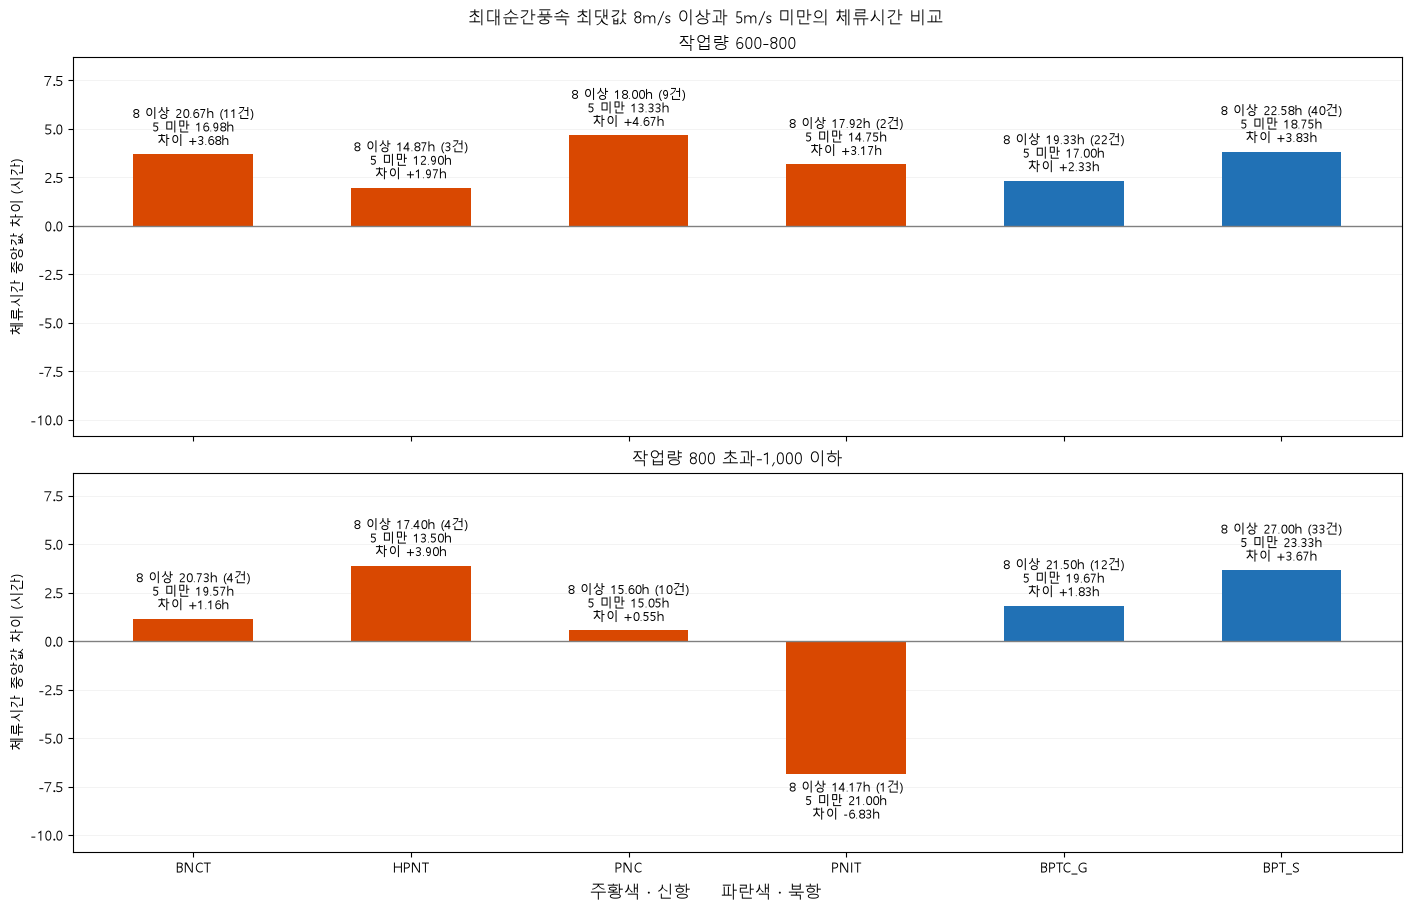

In [80]:
# 작업량 집단을 위아래로 배치해 막대 위 라벨이 겹치지 않게 한다.
집단별표 = {
    "600-800": 돌풍결과["최댓값"],
    "800 초과-1,000 이하": 돌풍결과2["최댓값"],
}

fig, axes = plt.subplots(
    2, 1, figsize=(14, 9),
    sharex=True, sharey=True, layout="constrained",
)
위치 = np.arange(len(터미널목록))

for ax, (집단, 결과표) in zip(axes, 집단별표.items()):
    낮은구간 = 결과표.xs("0-5 미만", level=1).reindex(터미널목록)
    높은구간 = 결과표.xs("8 이상", level=1).reindex(터미널목록)

    낮은시간 = 낮은구간["체류시간_중앙값"]
    높은시간 = 높은구간["체류시간_중앙값"]
    차이 = 높은시간 - 낮은시간
    유효 = 차이.notna().to_numpy()

    색상 = np.array([
        "#2171B5" if 터미널 in ["BPTC_G", "BPT_S"] else "#D94801"
        for 터미널 in 터미널목록
    ])

    막대 = ax.bar(
        위치[유효], 차이[유효].to_numpy(dtype=float),
        width=0.55, color=색상[유효],
    )
    ax.bar_label(
        막대,
        labels=[
            f"8 이상 {높음:.2f}h ({int(건수)}건)\n"
            f"5 미만 {낮음:.2f}h\n"
            f"차이 {차이값:+.2f}h"
            for 높음, 낮음, 건수, 차이값 in zip(
                높은시간[유효], 낮은시간[유효],
                높은구간.loc[유효, "기록수"], 차이[유효],
            )
        ],
        padding=5, fontsize=9,
    )

    ax.axhline(0, color="gray", linewidth=1)
    ax.set_title(f"작업량 {집단}")
    ax.set_ylabel("체류시간 중앙값 차이 (시간)")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.margins(y=0.35)

axes[-1].set_xticks(위치, 터미널목록)
fig.suptitle("최대순간풍속 최댓값 8m/s 이상과 5m/s 미만의 체류시간 비교")
fig.supxlabel("주황색 · 신항     파란색 · 북항")
그림표시()

- 최대순간풍속 최댓값이 8m/s 이상인 기록은 5m/s 미만인 기록보다 체류시간 중앙값이 대체로 길었다. 작업량 600-800에서는 6개 터미널 모두, 800 초과-1,000 이하에서는 6개 중 5개 터미널에서 같은 방향이 나타났다.
- BPT_S에서는 작업량 600-800의 체류시간 중앙값이 18.75시간에서 22.58시간으로, 800 초과-1,000 이하에서는 23.33시간에서 27.00시간으로 높았다. 두 집단의 차이는 각각 3.83시간과 3.67시간이었으며, 8m/s 이상 기록은 각각 40건과 33건이었다.
- PNIT는 작업량 800 초과-1,000 이하에서 8m/s 이상 구간의 체류시간이 6.83시간 짧았지만, 해당 구간은 1건이었다. 그래프의 차이는 관측된 체류시간 중앙값 차이로, 돌풍에 따른 지연 시간을 추정한 값은 아니다.

In [81]:
파고구간순서 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]

전체구간 = pd.MultiIndex.from_product(
    [터미널목록, 파고구간순서],
    names=["터미널", "파고구간"],
)

유의파고집단비교 = {}

for 집단, 표 in {
    "600-800": 유의파고결과["최댓값"],
    "800 초과-1,000 이하": 유의파고결과2["최댓값"],
}.items():
    자료 = 표.reindex(전체구간)

    유의파고집단비교[집단] = 자료[
        ["기록수", "체류시간_중앙값"]
    ].copy()

    유의파고집단비교[집단]["기록수"] = (
        자료["기록수"].fillna(0).astype(int)
    )

display(pd.concat(유의파고집단비교, axis=1).round(2))

600-800          800 초과-1,000 이하         
                  기록수 체류시간_중앙값             기록수 체류시간_중앙값
터미널    파고구간                                            
BNCT   0-1 미만     112    18.15              58    21.72
       1-2 미만      13    16.03               8    20.71
       2-3 미만       1    18.92               0      NaN
       3 이상         0      NaN               0      NaN
HPNT   0-1 미만      41    12.90              41    14.60
       1-2 미만       6    14.28              11    17.00
       2-3 미만       0      NaN               0      NaN
       3 이상         0      NaN               0      NaN
PNC    0-1 미만     108    13.67              57    15.62
       1-2 미만      18    15.29               7    17.75
       2-3 미만       0      NaN               0      NaN
       3 이상         0      NaN               0      NaN
PNIT   0-1 미만      45    14.92              25    21.00
       1-2 미만       7    15.00               3    17.17
       2-3 미만       0      NaN               0      NaN
       3 이상         0      NaN               0      NaN
BPTC_G 0-1 미만     153    17.33              98    21.00
       1-2 미만      78    17.50              41    19.00
       2-3 미만      12    20.00              10    18.17
       3 이상         2    63.04               0      NaN
BPT_S  0-1 미만     172    19.17             213    24.00
       1-2 미만      86    20.08             117    24.00
       2-3 미만      12    19.08              20    25.50
       3 이상         2    31.00               4    31.00

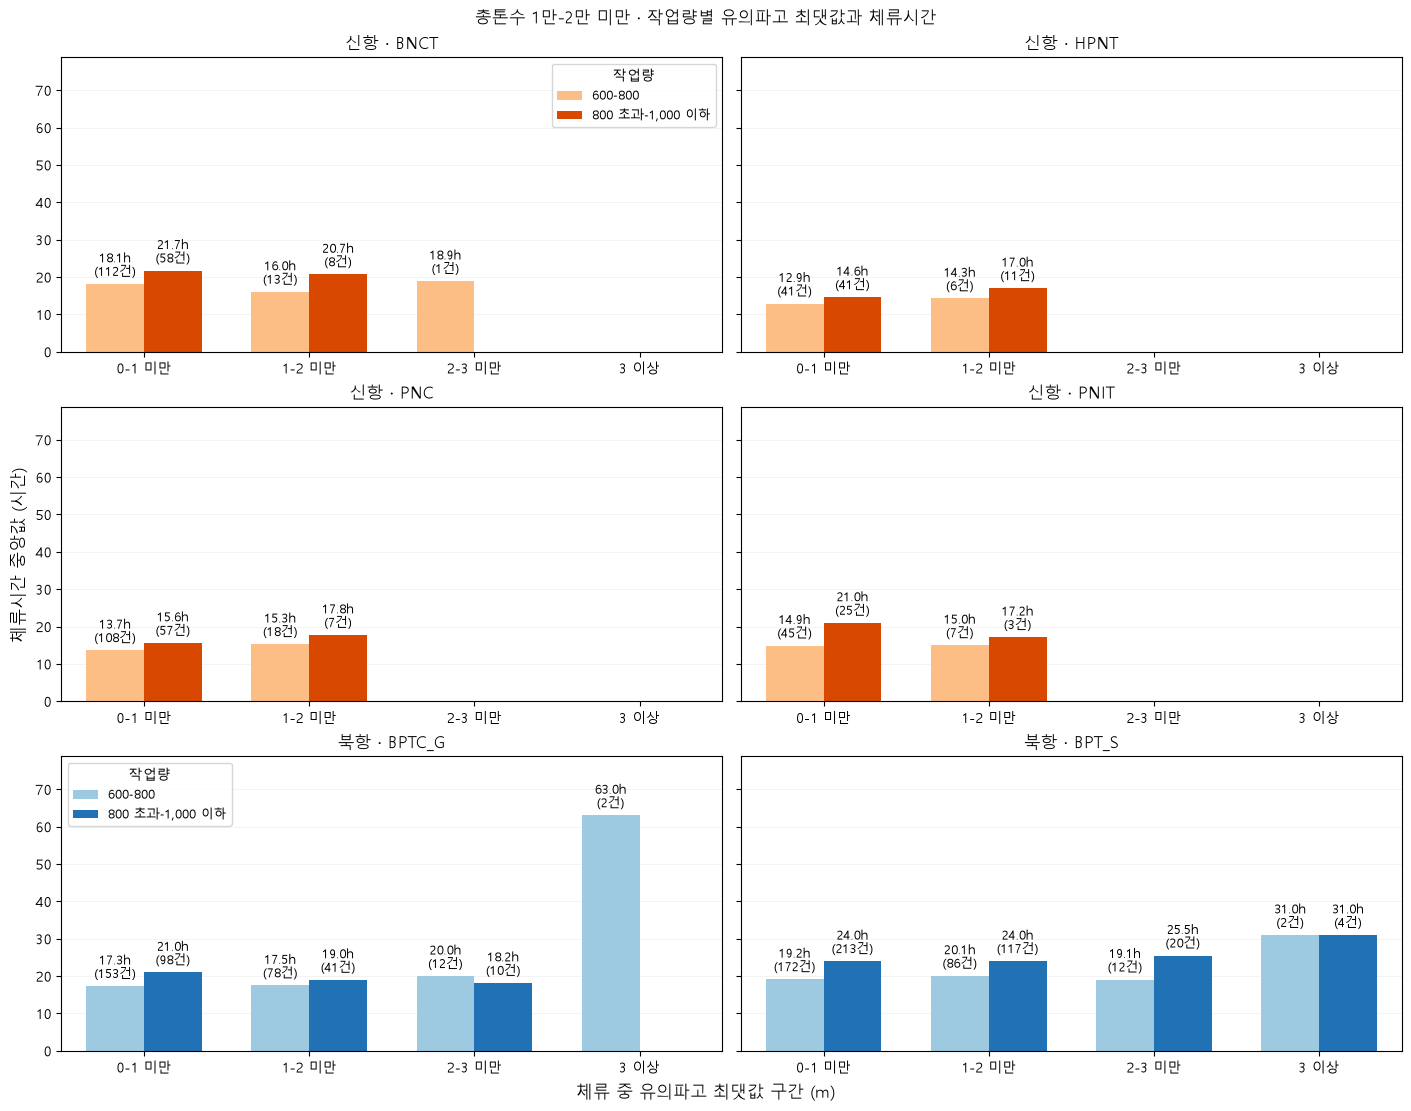

In [82]:
fig, axes = plt.subplots(
    3, 2, figsize=(14, 11),
    sharey=True, layout="constrained",
)
위치 = np.arange(len(파고구간순서))
폭 = 0.35

for ax, 터미널 in zip(axes.flat, 터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    색상 = ["#9ECAE1", "#2171B5"] if 북항 else ["#FDBE85", "#D94801"]

    for 번호, (집단, 표) in enumerate(유의파고집단비교.items()):
        자료 = 표.xs(터미널, level="터미널").reindex(파고구간순서)
        건수 = 자료["기록수"].fillna(0).astype(int).to_numpy()
        시간 = 자료["체류시간_중앙값"]
        유효 = (건수 > 0) & 시간.notna().to_numpy()
        막대위치 = 위치 + (번호 - 0.5) * 폭

        막대 = ax.bar(
            막대위치[유효],
            시간[유효].to_numpy(dtype=float),
            width=폭, color=색상[번호], label=집단,
        )
        ax.bar_label(
            막대,
            labels=[
                f"{값:.1f}h\n({n}건)"
                for 값, n in zip(시간[유효], 건수[유효])
            ],
            padding=4, fontsize=9,
        )

    ax.set_xticks(위치, 파고구간순서)
    ax.set_xlim(-0.5, len(위치) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

전체최대 = pd.concat(유의파고집단비교.values())["체류시간_중앙값"].max()
if pd.notna(전체최대) and 전체최대 > 0:
    axes[0, 0].set_ylim(0, 전체최대 * 1.25)

axes[0, 0].legend(title="작업량", fontsize=9)
axes[2, 0].legend(title="작업량", fontsize=9)

fig.suptitle("총톤수 1만-2만 미만 · 작업량별 유의파고 최댓값과 체류시간")
fig.supxlabel("체류 중 유의파고 최댓값 구간 (m)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

－ 유의파고 최댓값 2m 이상 기록은 두 작업량 집단 모두 북항에서만 관측됐다. 신항 4개 터미널은 해당 구간의 기록이 0건이었다.

－ BPTC_G의 체류시간 중앙값은 작업량 600-800에서 2-3m 미만 20.00시간(12건), 3m 이상 63.04시간(2건)이었다. 작업량 800 초과-1,000 이하에서는 2-3m 미만 18.17시간(10건)이었고, 3m 이상 기록은 없었다.

－ BPT_S는 작업량 600-800에서 2-3m 미만 19.08시간(12건), 3m 이상 31.00시간(2건)이었다. 작업량 800 초과-1,000 이하에서도 각각 25.50시간(20건), 31.00시간(4건)으로 3m 이상 구간의 체류시간이 더 길었다.

In [83]:
# 순간최대파고 최댓값을 기준으로 기존 네 구간을 유지한다.
순간파고최대열 = "체류시간_순간최대파고_최댓값_m"
순간파고구간순서 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]
순간파고집단비교 = {}

전체구간 = pd.MultiIndex.from_product(
    [터미널목록, 순간파고구간순서],
    names=["터미널", "파고구간"],
)

for 집단, 원자료 in {
    "600-800": 후보,
    "800 초과-1,000 이하": 후보2,
}.items():
    자료 = 원자료.copy()
    자료["파고구간"] = pd.cut(
        자료[순간파고최대열],
        bins=[0, 1, 2, 3, float("inf")],
        labels=순간파고구간순서,
        right=False,
    )

    표 = 자료.groupby(
        ["터미널", "파고구간"], observed=True
    ).agg(
        기록수=("체류시간", "count"),
        체류시간_중앙값=("체류시간", "median"),
    ).reindex(전체구간)

    표["기록수"] = 표["기록수"].fillna(0).astype(int)
    순간파고집단비교[집단] = 표

display(pd.concat(순간파고집단비교, axis=1).round(2))

600-800          800 초과-1,000 이하         
                  기록수 체류시간_중앙값             기록수 체류시간_중앙값
터미널    파고구간                                            
BNCT   0-1 미만      94    17.88              46    21.73
       1-2 미만      27    17.87              18    20.71
       2-3 미만       4    15.56               2    26.66
       3 이상         1    18.92               0      NaN
HPNT   0-1 미만      31    12.40              34    14.30
       1-2 미만      13    14.87              14    15.50
       2-3 미만       3    13.00               4    17.42
       3 이상         0      NaN               0      NaN
PNC    0-1 미만      90    13.58              43    15.97
       1-2 미만      26    14.05              18    14.98
       2-3 미만      10    15.85               3    17.80
       3 이상         0      NaN               0      NaN
PNIT   0-1 미만      34    15.00              17    21.00
       1-2 미만      15    14.00              10    21.47
       2-3 미만       3    21.00               1    14.17
       3 이상         0      NaN               0      NaN
BPTC_G 0-1 미만     114    17.33              66    21.00
       1-2 미만      94    17.04              60    19.00
       2-3 미만      29    20.00              15    20.50
       3 이상         8    20.75               8    18.17
BPT_S  0-1 미만     116    19.83             144    23.92
       1-2 미만     121    19.17             145    24.00
       2-3 미만      26    21.83              46    25.83
       3 이상         9    19.00              19    26.00

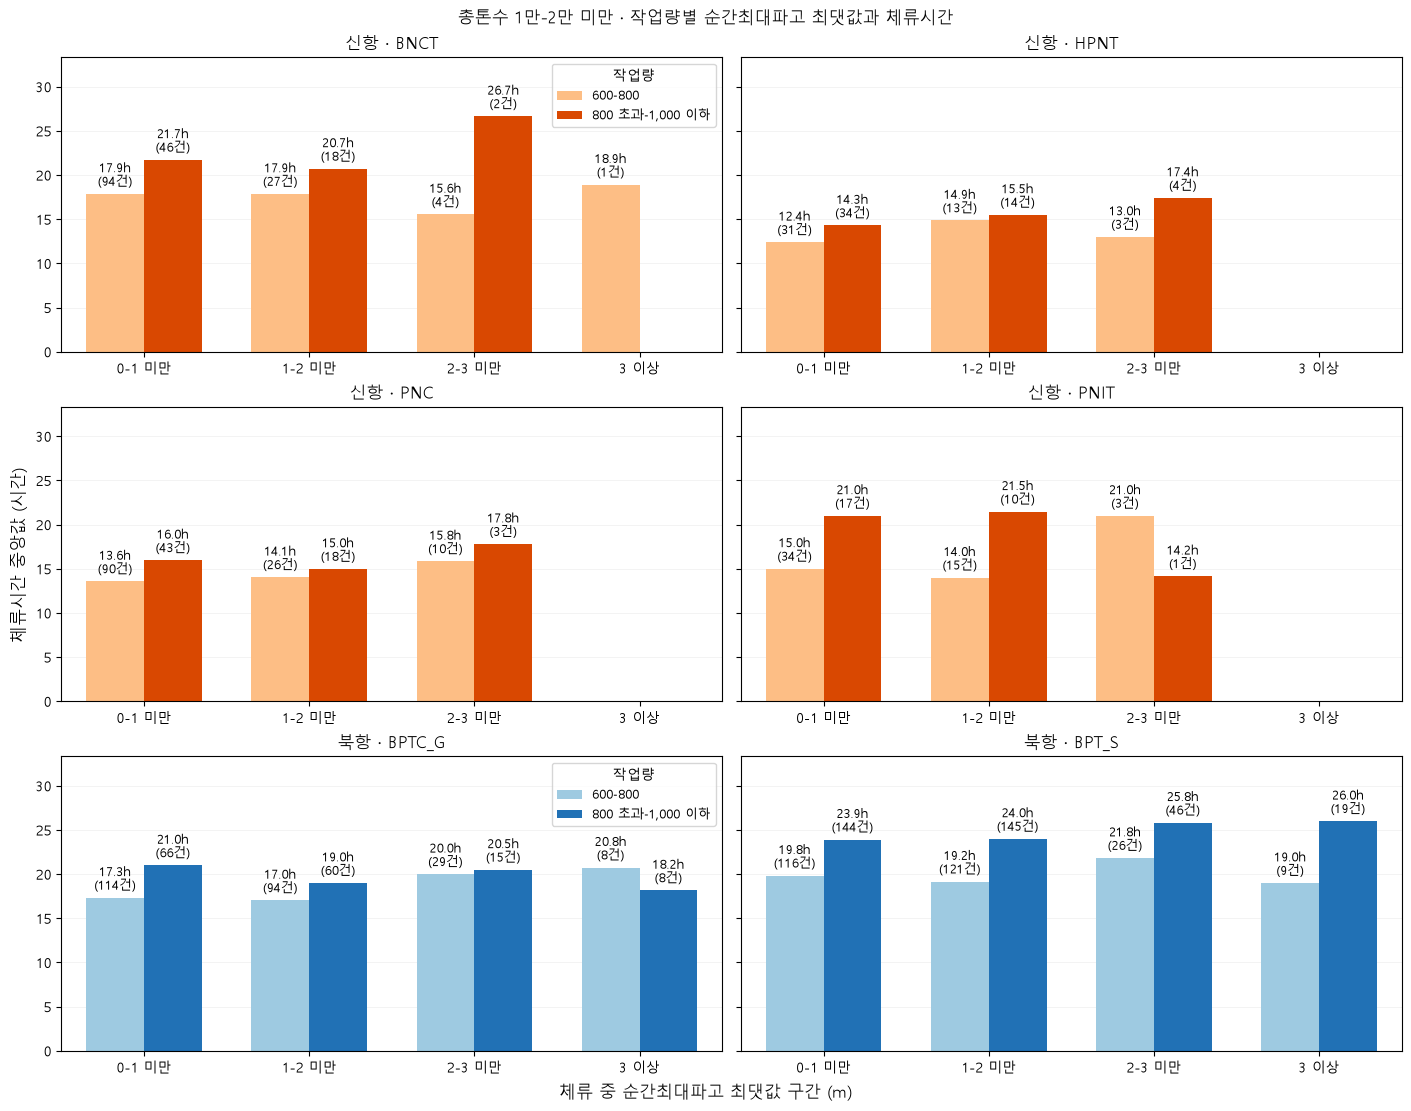

In [84]:
fig, axes = plt.subplots(
    3, 2, figsize=(14, 11),
    sharey=True, layout="constrained",
)
위치 = np.arange(len(순간파고구간순서))
폭 = 0.35

for ax, 터미널 in zip(axes.flat, 터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    색상 = ["#9ECAE1", "#2171B5"] if 북항 else ["#FDBE85", "#D94801"]

    for 번호, (집단, 표) in enumerate(순간파고집단비교.items()):
        자료 = 표.xs(터미널, level="터미널").reindex(순간파고구간순서)
        건수 = 자료["기록수"].fillna(0).astype(int).to_numpy()
        시간 = 자료["체류시간_중앙값"]
        유효 = (건수 > 0) & 시간.notna().to_numpy()

        막대 = ax.bar(
            위치[유효] + (번호 - 0.5) * 폭,
            시간[유효].to_numpy(dtype=float),
            width=폭, color=색상[번호], label=집단,
        )
        ax.bar_label(
            막대,
            labels=[
                f"{값:.1f}h\n({n}건)"
                for 값, n in zip(시간[유효], 건수[유효])
            ],
            padding=4, fontsize=9,
        )

    ax.set_xticks(위치, 순간파고구간순서)
    ax.set_xlim(-0.5, len(위치) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

전체최대 = pd.concat(순간파고집단비교.values())["체류시간_중앙값"].max()
if pd.notna(전체최대) and 전체최대 > 0:
    axes[0, 0].set_ylim(0, 전체최대 * 1.25)

axes[0, 0].legend(title="작업량", fontsize=9)
axes[2, 0].legend(title="작업량", fontsize=9)

fig.suptitle("총톤수 1만-2만 미만 · 작업량별 순간최대파고 최댓값과 체류시간")
fig.supxlabel("체류 중 순간최대파고 최댓값 구간 (m)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

－ 순간최대파고 최댓값 2-3m 미만 구간에서 BPTC_G의 체류시간 중앙값은 작업량 600-800에서 20.00시간(29건), 800 초과-1,000 이하에서 20.50시간(15건)이었다. BPT_S는 각각 21.83시간(26건), 25.83시간(46건)이었다.

－ 3m 이상 구간에서 BPTC_G는 각각 20.75시간(8건), 18.17시간(8건)이었고, BPT_S는 19.00시간(9건), 26.00시간(19건)이었다. 높은 파고 구간에서도 작업량 집단과 터미널에 따라 체류시간 양상이 달랐다.

In [85]:
# 같은 시정 구간에서 두 작업량 집단의 기록 수와 체류시간을 비교한다.
시정최소열 = "체류시간_시정_최솟값_10m"
시정구간순서 = [
    "0-100 미만", "100-500 미만", "500-1,000 미만", "1,000 이상"
]
시정집단비교 = {}

전체구간 = pd.MultiIndex.from_product(
    [터미널목록, 시정구간순서],
    names=["터미널", "시정구간"],
)

for 집단, 원자료 in {
    "600-800": 후보,
    "800 초과-1,000 이하": 후보2,
}.items():
    자료 = 원자료.copy()

    for 열 in [시정최소열, "체류시간"]:
        자료[열] = pd.to_numeric(
            자료[열].astype("string")
            .str.replace(",", "", regex=False).str.strip(),
            errors="coerce",
        )

    자료["시정구간"] = pd.cut(
        자료[시정최소열],
        bins=[0, 100, 500, 1_000, float("inf")],
        labels=시정구간순서,
        right=False,
    )

    표 = 자료.groupby(
        ["터미널", "시정구간"], observed=True
    ).agg(
        기록수=("체류시간", "count"),
        체류시간_중앙값=("체류시간", "median"),
    ).reindex(전체구간)

    표["기록수"] = 표["기록수"].fillna(0).astype(int)
    시정집단비교[집단] = 표

display(pd.concat(시정집단비교, axis=1).round(2))

600-800          800 초과-1,000 이하         
                        기록수 체류시간_중앙값             기록수 체류시간_중앙값
터미널    시정구간                                                  
BNCT   0-100 미만           2    24.79               4    20.11
       100-500 미만        18     20.5               8    22.77
       500-1,000 미만      16     18.0              11     22.1
       1,000 이상          90    16.39              43    20.88
HPNT   0-100 미만           0     <NA>               2    14.02
       100-500 미만         7     12.9               4     16.0
       500-1,000 미만       4    15.93               7     18.8
       1,000 이상          36     13.0              39     14.6
PNC    0-100 미만           5    15.23               2    16.03
       100-500 미만        15    15.48              11    17.75
       500-1,000 미만      13    17.03               4    15.99
       1,000 이상          97     13.3              48    15.34
PNIT   0-100 미만           1    10.42               1     22.8
       100-500 미만         9    15.75               6     22.8
       500-1,000 미만       5    17.08               6    21.55
       1,000 이상          39    14.83              15     16.8
BPTC_G 0-100 미만          12    17.46               6    22.17
       100-500 미만        37    19.33              22    19.04
       500-1,000 미만      26    18.17              18    18.75
       1,000 이상         175    17.33             104    20.75
BPT_S  0-100 미만           8    23.08              11    24.83
       100-500 미만        37    20.33              57     25.0
       500-1,000 미만      34    19.67              32     25.0
       1,000 이상         201     19.5             259     24.0

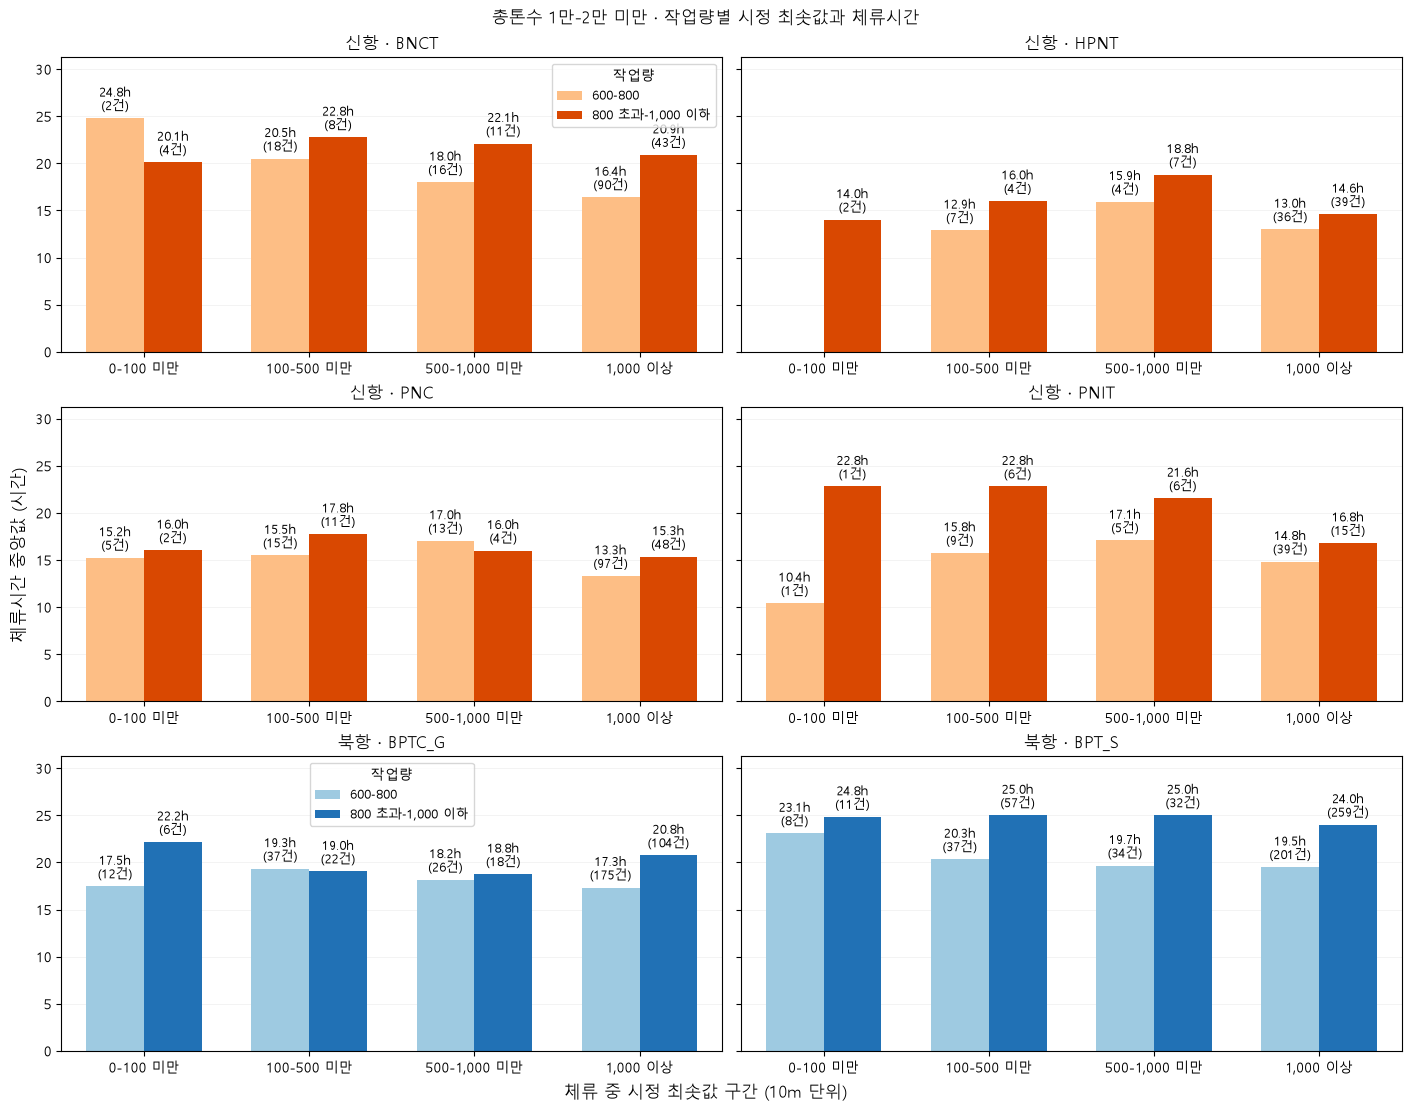

In [86]:
fig, axes = plt.subplots(
    3, 2, figsize=(14, 11),
    sharey=True, layout="constrained",
)
위치 = np.arange(len(시정구간순서))
폭 = 0.35

for ax, 터미널 in zip(axes.flat, 터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    색상 = ["#9ECAE1", "#2171B5"] if 북항 else ["#FDBE85", "#D94801"]

    for 번호, (집단, 표) in enumerate(시정집단비교.items()):
        자료 = 표.xs(터미널, level="터미널").reindex(시정구간순서)
        건수 = 자료["기록수"].fillna(0).astype(int).to_numpy()
        시간 = 자료["체류시간_중앙값"]
        유효 = (건수 > 0) & 시간.notna().to_numpy()

        막대 = ax.bar(
            위치[유효] + (번호 - 0.5) * 폭,
            시간[유효].to_numpy(dtype=float),
            width=폭, color=색상[번호], label=집단,
        )
        ax.bar_label(
            막대,
            labels=[
                f"{값:.1f}h\n({n}건)"
                for 값, n in zip(시간[유효], 건수[유효])
            ],
            padding=4, fontsize=9,
        )

    ax.set_xticks(위치, 시정구간순서)
    ax.set_xlim(-0.5, len(위치) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

전체최대 = pd.concat(시정집단비교.values())["체류시간_중앙값"].max()
if pd.notna(전체최대) and 전체최대 > 0:
    axes[0, 0].set_ylim(0, 전체최대 * 1.25)

axes[0, 0].legend(title="작업량", fontsize=9)
axes[2, 0].legend(title="작업량", fontsize=9)

fig.suptitle("총톤수 1만-2만 미만 · 작업량별 시정 최솟값과 체류시간")
fig.supxlabel("체류 중 시정 최솟값 구간 (10m 단위)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- BPT_S는 두 작업량 집단 모두 시정 최솟값이 1,000 미만인 구간의 체류시간 중앙값이 1,000 이상 구간보다 길었다. 다만 작업량 600-800에서는 구간별 차이가 0.17-3.58시간이었고, 800 초과-1,000 이하에서는 0.83-1.00시간이었다. 시정 단위는 원자료와 같은 10m다.
- BNCT는 작업량 600-800에서 시정 구간이 높아질수록 체류시간 중앙값이 24.79 → 20.50 → 18.00 → 16.39시간으로 줄었지만, 800 초과-1,000 이하에서는 같은 경향이 반복되지 않았다.
- 시정 100 미만 구간은 터미널·작업량 집단별 0-12건으로 적었다. 낮은 시정과 긴 체류시간의 관계는 일부 터미널에서 나타났으며, 두 작업량 집단과 모든 터미널에 걸쳐 일관되지는 않았다.

In [87]:
# 기존 특보 비교 결과를 두 작업량 집단별로 나란히 정리한다.
특보열 = "체류시간_특보노출시간"
특보구분순서 = ["특보 없음", "특보 있음"]
특보집단비교 = {}

전체구간 = pd.MultiIndex.from_product(
    [터미널목록, 특보구분순서],
    names=["터미널", "특보여부"],
)

for 집단, 원자료 in {
    "600-800": 후보,
    "800 초과-1,000 이하": 후보2,
}.items():
    자료 = 원자료.copy()
    자료[특보열] = pd.to_numeric(자료[특보열], errors="coerce")

    # 결측과 음수는 제외하고, 0시간과 0시간 초과로 구분한다.
    자료 = 자료.loc[자료[특보열].ge(0)].copy()
    자료["특보여부"] = np.where(
        자료[특보열].gt(0), "특보 있음", "특보 없음"
    )

    표 = 자료.groupby(["터미널", "특보여부"]).agg(
        기록수=("체류시간", "count"),
        체류시간_중앙값=("체류시간", "median"),
    ).reindex(전체구간)

    표["기록수"] = 표["기록수"].fillna(0).astype(int)
    특보집단비교[집단] = 표

display(pd.concat(특보집단비교, axis=1).round(2))

600-800          800 초과-1,000 이하         
                 기록수 체류시간_중앙값             기록수 체류시간_중앙값
터미널    특보여부                                           
BNCT   특보 없음     109    17.83              59    21.80
       특보 있음      17    17.87               7    20.42
HPNT   특보 없음      40    13.40              42    14.30
       특보 있음       7    13.00              10    16.10
PNC    특보 없음     110    13.67              58    15.79
       특보 있음      20    15.36               7    17.00
PNIT   특보 없음      48    14.88              26    20.80
       특보 있음       6    15.00               2    18.88
BPTC_G 특보 없음     219    17.33             127    20.00
       특보 있음      31    20.00              23    20.00
BPT_S  특보 없음     239    19.50             295    24.00
       특보 있음      41    21.00              64    25.00

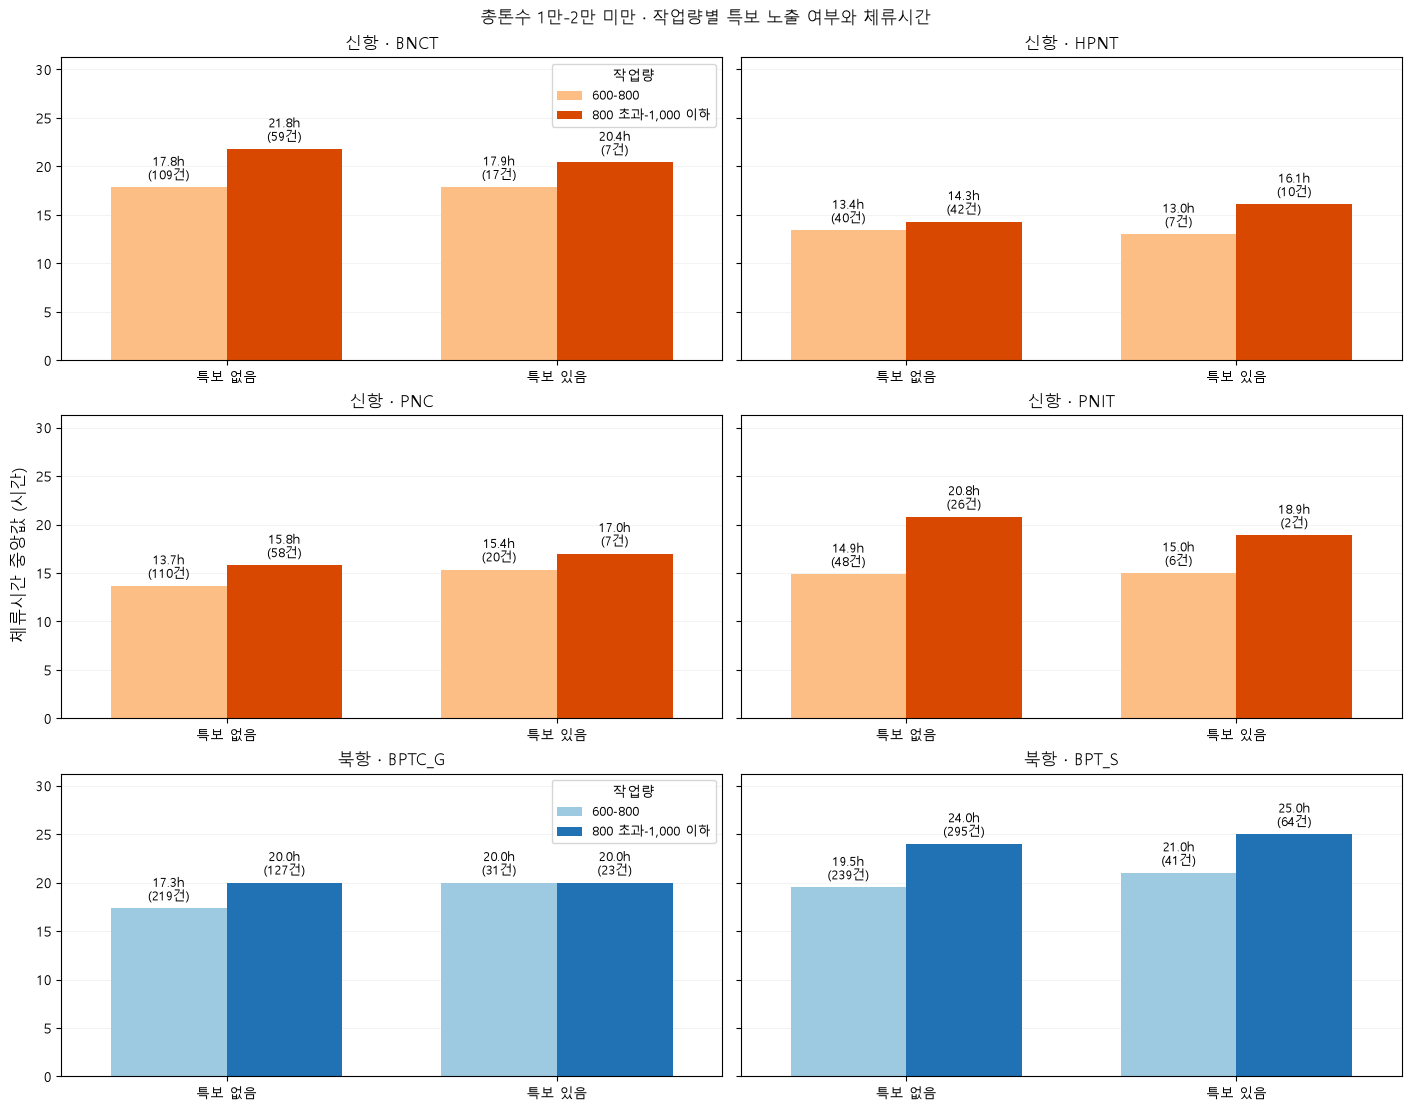

In [88]:
fig, axes = plt.subplots(
    3, 2, figsize=(14, 11),
    sharey=True, layout="constrained",
)
위치 = np.arange(len(특보구분순서))
폭 = 0.35

for ax, 터미널 in zip(axes.flat, 터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    색상 = ["#9ECAE1", "#2171B5"] if 북항 else ["#FDBE85", "#D94801"]

    for 번호, (집단, 표) in enumerate(특보집단비교.items()):
        자료 = 표.xs(터미널, level="터미널").reindex(특보구분순서)
        건수 = 자료["기록수"].fillna(0).astype(int).to_numpy()
        시간 = 자료["체류시간_중앙값"]
        유효 = (건수 > 0) & 시간.notna().to_numpy()

        막대 = ax.bar(
            위치[유효] + (번호 - 0.5) * 폭,
            시간[유효].to_numpy(dtype=float),
            width=폭, color=색상[번호], label=집단,
        )
        ax.bar_label(
            막대,
            labels=[
                f"{값:.1f}h\n({n}건)"
                for 값, n in zip(시간[유효], 건수[유효])
            ],
            padding=4, fontsize=9,
        )

    ax.set_xticks(위치, 특보구분순서)
    ax.set_xlim(-0.5, len(위치) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

전체최대 = pd.concat(특보집단비교.values())["체류시간_중앙값"].max()
if pd.notna(전체최대) and 전체최대 > 0:
    axes[0, 0].set_ylim(0, 전체최대 * 1.25)

axes[0, 0].legend(title="작업량", fontsize=9)
axes[2, 0].legend(title="작업량", fontsize=9)

fig.suptitle("총톤수 1만-2만 미만 · 작업량별 특보 노출 여부와 체류시간")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- PNC와 BPT_S는 두 작업량 집단 모두 특보 노출 기록의 체류시간 중앙값이 미노출 기록보다 길었다. PNC의 차이는 작업량 600-800에서 1.69시간, 800 초과-1,000 이하에서 1.21시간이었고, BPT_S는 각각 1.50시간과 1.00시간이었다.
- BPTC_G는 작업량 600-800에서 특보 노출 기록이 2.67시간 길었지만, 800 초과-1,000 이하에서는 두 집단 모두 20.00시간이었다. BNCT·HPNT·PNIT는 작업량 집단에 따라 차이의 방향이 달랐다.

In [89]:
# 두 기상변수의 기존 구간을 교차해 기록 수를 확인한다.
돌풍열 = "체류시간_최대순간풍속_최댓값_mps"
파고열 = "체류시간_유의파고_최댓값_m"

돌풍순서 = ["0-5 미만", "5-8 미만", "8 이상"]
파고순서 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]
복합기상자료 = {}

행순서 = pd.MultiIndex.from_product(
    [터미널목록, 돌풍순서],
    names=["터미널", "돌풍구간"],
)

for 집단, 원자료 in {
    "600-800": 후보,
    "800 초과-1,000 이하": 후보2,
}.items():
    자료 = 원자료.dropna(subset=[돌풍열, 파고열]).copy()

    자료["돌풍구간"] = pd.cut(
        자료[돌풍열],
        bins=[0, 5, 8, float("inf")],
        labels=돌풍순서,
        right=False,
    )
    자료["파고구간"] = pd.cut(
        자료[파고열],
        bins=[0, 1, 2, 3, float("inf")],
        labels=파고순서,
        right=False,
    )
    복합기상자료[집단] = 자료

    건수표 = (
        자료.groupby(["터미널", "돌풍구간", "파고구간"], observed=True)
        .size()
        .unstack("파고구간")
        .reindex(index=행순서, columns=파고순서)
        .fillna(0)
        .astype(int)
    )

    print(f"작업량 {집단} · 돌풍(m/s) × 유의파고(m) 기록 수")
    display(건수표)

작업량 600-800 · 돌풍(m/s) × 유의파고(m) 기록 수


파고구간           0-1 미만  1-2 미만  2-3 미만  3 이상
터미널    돌풍구간                                
BNCT   0-5 미만      50       4       0     0
       5-8 미만      49       6       0     0
       8 이상         9       1       1     0
HPNT   0-5 미만      22       3       0     0
       5-8 미만      17       1       0     0
       8 이상         1       2       0     0
PNC    0-5 미만      59       6       0     0
       5-8 미만      37       8       0     0
       8 이상         3       4       0     0
PNIT   0-5 미만      27       1       0     0
       5-8 미만      16       5       0     0
       8 이상         1       1       0     0
BPTC_G 0-5 미만      68      24       1     0
       5-8 미만      68      48       7     1
       8 이상        12       5       4     1
BPT_S  0-5 미만      58      23       3     0
       5-8 미만      83      50       3     0
       8 이상        19      13       5     2

작업량 800 초과-1,000 이하 · 돌풍(m/s) × 유의파고(m) 기록 수


파고구간           0-1 미만  1-2 미만  2-3 미만  3 이상
터미널    돌풍구간                                
BNCT   0-5 미만      23       0       0     0
       5-8 미만      31       6       0     0
       8 이상         3       1       0     0
HPNT   0-5 미만      18       1       0     0
       5-8 미만      21       7       0     0
       8 이상         1       3       0     0
PNC    0-5 미만      26       1       0     0
       5-8 미만      20       3       0     0
       8 이상         7       3       0     0
PNIT   0-5 미만      15       0       0     0
       5-8 미만      10       2       0     0
       8 이상         0       1       0     0
BPTC_G 0-5 미만      28       8       0     0
       5-8 미만      63      29       7     0
       8 이상         6       4       2     0
BPT_S  0-5 미만      74      48       4     0
       5-8 미만     112      56      12     2
       8 이상        15      13       4     1

In [90]:
# 셀마다 체류시간 중앙값과 체류시간이 있는 기록 수를 표시한다.
복합기상결과 = {}

for 집단, 자료 in 복합기상자료.items():
    요약 = 자료.groupby(
        ["터미널", "돌풍구간", "파고구간"], observed=True
    )["체류시간"].agg(기록수="count", 체류시간_중앙값="median")

    건수 = (
        요약["기록수"].unstack("파고구간")
        .reindex(index=행순서, columns=파고순서)
        .fillna(0).astype(int)
    )
    시간 = (
        요약["체류시간_중앙값"].unstack("파고구간")
        .reindex(index=행순서, columns=파고순서)
    )

    표시표 = 시간.map(lambda 값: f"{값:.2f}h" if pd.notna(값) else "")
    표시표 = 표시표 + " (" + 건수.astype(str) + "건)"
    표시표 = 표시표.mask(건수.eq(0), "0건")

    복합기상결과[집단] = 요약

    print(f"작업량 {집단} · 체류시간 중앙값 (기록 수)")
    display(표시표)

작업량 600-800 · 체류시간 중앙값 (기록 수)


파고구간                 0-1 미만        1-2 미만       2-3 미만         3 이상
터미널    돌풍구간                                                        
BNCT   0-5 미만  16.98h (50건)   17.98h (4건)           0건           0건
       5-8 미만  18.33h (49건)   16.34h (6건)           0건           0건
       8 이상     21.87h (9건)   15.62h (1건)  18.92h (1건)           0건
HPNT   0-5 미만  12.90h (22건)   13.00h (3건)           0건           0건
       5-8 미만  12.40h (17건)   15.30h (1건)           0건           0건
       8 이상     15.00h (1건)   14.28h (2건)           0건           0건
PNC    0-5 미만  13.52h (59건)   13.46h (6건)           0건           0건
       5-8 미만  13.23h (37건)   15.36h (8건)           0건           0건
       8 이상     14.27h (3건)   18.94h (4건)           0건           0건
PNIT   0-5 미만  14.75h (27건)   19.00h (1건)           0건           0건
       5-8 미만  15.15h (16건)   12.75h (5건)           0건           0건
       8 이상     14.83h (1건)   21.00h (1건)           0건           0건
BPTC_G 0-5 미만  17.29h (68건)  15.58h (24건)  20.75h (1건)           0건
       5-8 미만  17.79h (68건)  18.33h (48건)  18.17h (7건)  34.17h (1건)
       8 이상    17.17h (12건)   22.00h (5건)  20.00h (4건)  91.92h (1건)
BPT_S  0-5 미만  18.00h (58건)  19.00h (23건)  19.17h (3건)           0건
       5-8 미만  20.00h (83건)  20.83h (50건)  19.00h (3건)           0건
       8 이상    23.00h (19건)  21.33h (13건)  22.50h (5건)  31.00h (2건)

작업량 800 초과-1,000 이하 · 체류시간 중앙값 (기록 수)


파고구간                  0-1 미만        1-2 미만        2-3 미만         3 이상
터미널    돌풍구간                                                          
BNCT   0-5 미만   19.57h (23건)            0건            0건           0건
       5-8 미만   23.55h (31건)   20.40h (6건)            0건           0건
       8 이상      21.03h (3건)   20.42h (1건)            0건           0건
HPNT   0-5 미만   13.20h (18건)   17.00h (1건)            0건           0건
       5-8 미만   14.90h (21건)   17.00h (7건)            0건           0건
       8 이상      20.40h (1건)   15.00h (3건)            0건           0건
PNC    0-5 미만   15.00h (26건)   17.80h (1건)            0건           0건
       5-8 미만   16.20h (20건)   17.08h (3건)            0건           0건
       8 이상      15.03h (7건)   22.33h (3건)            0건           0건
PNIT   0-5 미만   21.00h (15건)            0건            0건           0건
       5-8 미만   19.72h (10건)   21.08h (2건)            0건           0건
       8 이상               0건   14.17h (1건)            0건           0건
BPTC_G 0-5 미만   19.50h (28건)   19.92h (8건)            0건           0건
       5-8 미만   21.00h (63건)  19.00h (29건)   17.00h (7건)           0건
       8 이상      22.25h (6건)   18.58h (4건)   29.50h (2건)           0건
BPT_S  0-5 미만   23.04h (74건)  24.42h (48건)   25.83h (4건)           0건
       5-8 미만  25.00h (112건)  23.58h (56건)  25.50h (12건)  28.00h (2건)
       8 이상     27.00h (15건)  26.50h (13건)   33.50h (4건)  32.00h (1건)

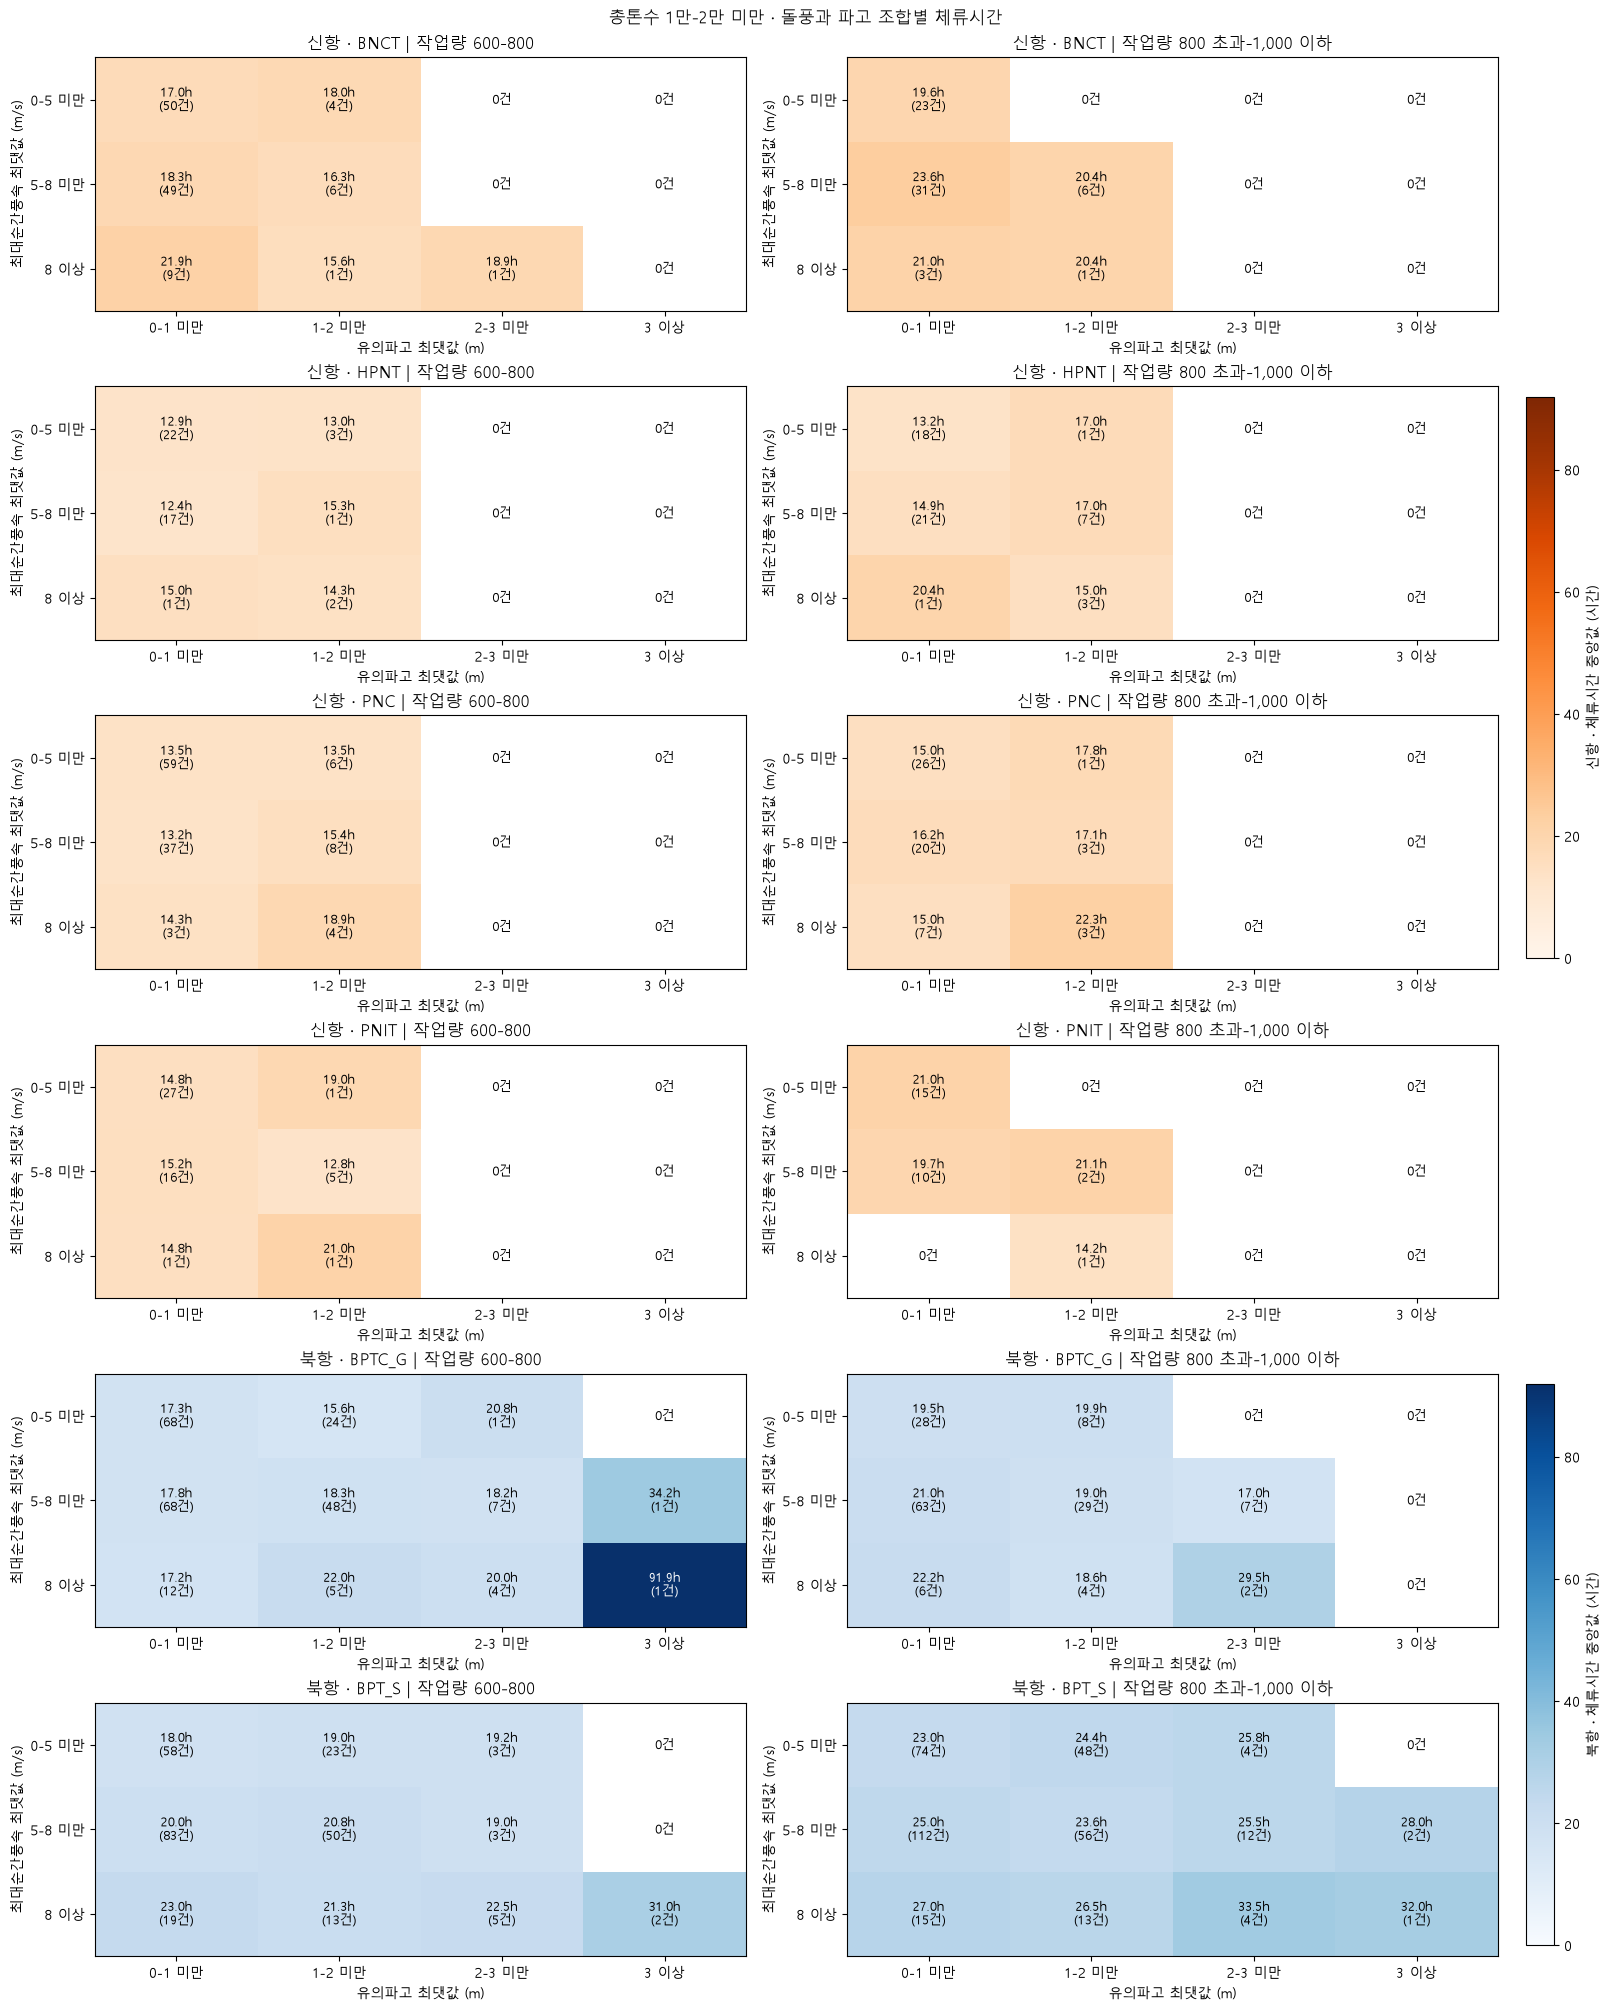

In [91]:
# 돌풍·파고 구간과 두 작업량 집단을 같은 색상 범위로 비교한다.
최대시간 = max(
    (표["체류시간_중앙값"].max() for 표 in 복합기상결과.values()),
    default=1,
)
if pd.isna(최대시간) or 최대시간 <= 0:
    최대시간 = 1

fig, axes = plt.subplots(
    len(터미널목록), 2, figsize=(16, 20),
    layout="constrained",
)
항만그림 = {}

for 행, 터미널 in enumerate(터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    색 = "Blues" if 북항 else "Oranges"

    for 열번호, (집단, 표) in enumerate(복합기상결과.items()):
        ax = axes[행, 열번호]
        인덱스 = pd.MultiIndex.from_product(
            [[터미널], 돌풍순서, 파고순서],
            names=["터미널", "돌풍구간", "파고구간"],
        )
        자료 = 표.reindex(인덱스).droplevel("터미널")

        시간 = 자료["체류시간_중앙값"].unstack("파고구간").reindex(
            index=돌풍순서, columns=파고순서
        )
        건수 = 자료["기록수"].unstack("파고구간").reindex(
            index=돌풍순서, columns=파고순서
        ).fillna(0).astype(int)

        # 결측 구간은 색칠하지 않고 0건으로 표시한다.
        값 = 시간.to_numpy(dtype=float, na_value=np.nan)
        그림 = ax.imshow(
            np.ma.masked_invalid(값),
            cmap=색, vmin=0, vmax=최대시간, aspect="auto",
        )
        항만그림[항만] = 그림

        for i in range(len(돌풍순서)):
            for j in range(len(파고순서)):
                n = 건수.iloc[i, j]
                시간값 = 값[i, j]
                문구 = f"{시간값:.1f}h\n({n}건)" if n > 0 else "0건"
                글자색 = "white" if pd.notna(시간값) and 시간값 > 최대시간 * 0.6 else "black"
                ax.text(j, i, 문구, ha="center", va="center",
                        fontsize=9, color=글자색)

        ax.set_xticks(range(len(파고순서)), 파고순서)
        ax.set_yticks(range(len(돌풍순서)), 돌풍순서)
        ax.set_title(f"{항만} · {터미널} | 작업량 {집단}")
        ax.set_xlabel("유의파고 최댓값 (m)")
        ax.set_ylabel("최대순간풍속 최댓값 (m/s)")

for 항만, 그림 in 항만그림.items():
    해당축 = [
        ax for 행, 터미널 in enumerate(터미널목록)
        if ("북항" if 터미널 in ["BPTC_G", "BPT_S"] else "신항") == 항만
        for ax in axes[행]
    ]
    fig.colorbar(그림, ax=해당축, fraction=0.02, pad=0.02,
                 label=f"{항만} · 체류시간 중앙값 (시간)")

fig.suptitle("총톤수 1만-2만 미만 · 돌풍과 파고 조합별 체류시간")
그림표시()

- 돌풍 8m/s 이상·유의파고 2-3m 미만 구간에서 체류시간 중앙값은 BPTC_G가 작업량 600-800에서 20.00시간(4건), 800 초과-1,000 이하에서 29.50시간(2건)이었다. BPT_S는 각각 22.50시간(5건), 33.50시간(4건)이었다.
- 돌풍 8m/s 이상·유의파고 3m 이상 구간에서 BPT_S는 두 작업량 집단이 각각 31.00시간(2건), 32.00시간(1건)이었다. BPTC_G의 작업량 600-800에서는 91.92시간이 나타났지만, 이는 원자료 확인 대상인 파고 10.8m 기록 1건의 체류시간이다.
- 높은 돌풍·파고가 함께 나타난 기록은 주로 북항에 있었다. 신항에서는 작업량 600-800의 BNCT에 돌풍 8m/s 이상·파고 2-3m 미만 기록이 1건 있었으며, 체류시간은 18.92시간이었다.

In [92]:
확인기록 = []

for 집단, 자료 in 복합기상자료.items():
    선택 = 자료.loc[
        자료["돌풍구간"].eq("8 이상")
        & 자료["파고구간"].isin(["2-3 미만", "3 이상"])
    ].copy()

    선택["작업량집단"] = 집단
    확인기록.append(선택)

높은기상기록 = pd.concat(확인기록, ignore_index=True)

display(
    높은기상기록[[
        "작업량집단", "터미널", "선박명",
        "접안일시", "출항일시", "총톤수", "총작업량",
        "체류시간",
        "체류시간_최대순간풍속_최댓값_mps",
        "체류시간_유의파고_최댓값_m",
    ]]
    .sort_values(["터미널", "작업량집단", "체류시간"],
                 ascending=[True, True, False])
    .reset_index(drop=True)
    .round({열: 2 for 열 in 높은기상기록.select_dtypes(include="number").columns})
)

,작업량집단,터미널,선박명,접안일시,출항일시,총톤수,총작업량,체류시간,체류시간_최대순간풍속_최댓값_mps,체류시간_유의파고_최댓값_m
0,600-800,BNCT,PANAY,2023-09-20 18:20:00,2023-09-21 13:15:00,18491,763.0,18.92,10.63,2.3
1,600-800,BPTC_G,XIUMEI SHANGHAI,2022-09-03 21:05:00,2022-09-07 17:00:00,15906,690.0,91.92,15.68,10.8
2,600-800,BPTC_G,TS BANGKOK,2024-06-29 21:35:00,2024-07-01 05:00:00,17449,677.0,31.42,11.27,2.2
3,600-800,BPTC_G,SAWASDEE SIRIUS,2022-09-13 15:00:00,2022-09-14 11:00:00,18051,654.0,20.00,8.42,2.4
4,600-800,BPTC_G,XIUMEI SHANGHAI,2022-09-14 14:00:00,2022-09-15 10:00:00,15906,650.0,20.00,8.00,2.0
5,600-800,BPTC_G,YM INITIATIVE,2021-03-19 05:30:00,2021-03-19 23:00:00,16488,611.0,17.50,8.40,2.0
6,"800 초과-1,000 이하",BPTC_G,EASLINE OSAKA,2024-06-29 20:00:00,2024-07-01 09:00:00,18502,946.0,37.00,11.27,2.2
7,"800 초과-1,000 이하",BPTC_G,INFERRO,2023-09-20 18:00:00,2023-09-21 16:00:00,19035,926.0,22.00,9.60,2.6
8,600-800,BPT_S,ORIENTAL BRIGHT,2022-03-18 05:00:00,2022-03-19 15:00:00,13596,641.0,34.00,9.41,3.2
9,600-800,BPT_S,KHARIS HERITAGE,2022-03-25 22:00:00,2022-03-27 02:00:00,12545,616.0,28.00,9.55,3.0


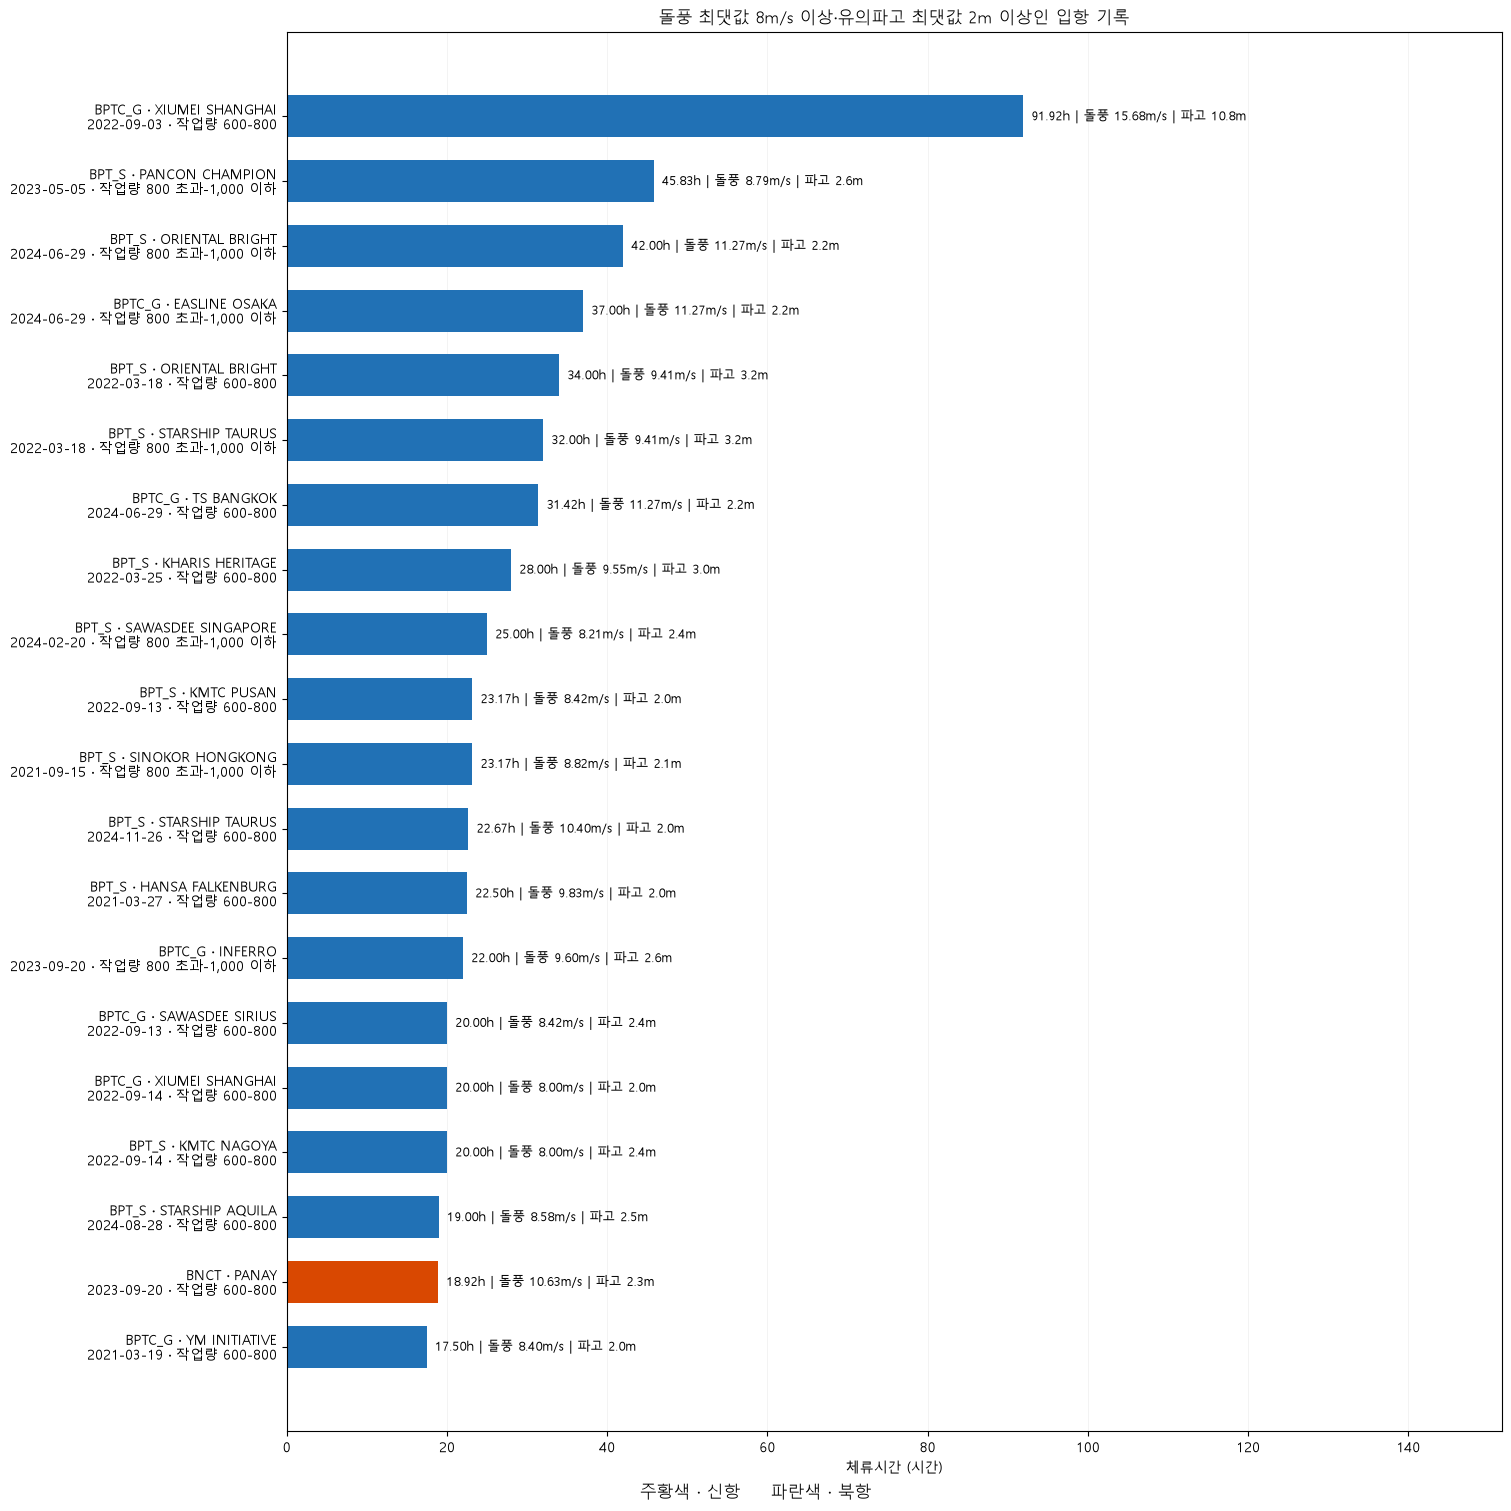

In [93]:
# 높은 돌풍·파고가 기록된 입항을 건별로 비교한다.
# 긴 선박명과 기상값을 읽기 쉽도록 가로 막대로 표시한다.
그래프자료 = 높은기상기록.sort_values(
    "체류시간", ascending=False
).copy()

접안날짜 = pd.to_datetime(그래프자료["접안일시"]).dt.strftime("%Y-%m-%d")
라벨 = (
    그래프자료["터미널"] + " · " + 그래프자료["선박명"]
    + "\n" + 접안날짜 + " · 작업량 " + 그래프자료["작업량집단"]
)
색상 = [
    "#2171B5" if 터미널 in ["BPTC_G", "BPT_S"] else "#D94801"
    for 터미널 in 그래프자료["터미널"]
]

fig, ax = plt.subplots(
    figsize=(15, 0.65 * len(그래프자료) + 2),
    layout="constrained",
)
위치 = np.arange(len(그래프자료))

ax.barh(
    위치, 그래프자료["체류시간"].to_numpy(dtype=float),
    color=색상, height=0.65,
)

for i, (_, 기록) in enumerate(그래프자료.iterrows()):
    ax.annotate(
        f'{기록["체류시간"]:.2f}h'
        f' | 돌풍 {기록["체류시간_최대순간풍속_최댓값_mps"]:.2f}m/s'
        f' | 파고 {기록["체류시간_유의파고_최댓값_m"]:.1f}m',
        (기록["체류시간"], i),
        xytext=(6, 0), textcoords="offset points",
        va="center", fontsize=9,
    )

ax.set_yticks(위치, 라벨)
ax.invert_yaxis()
ax.set_xlim(0, 그래프자료["체류시간"].max() * 1.65)
ax.set_xlabel("체류시간 (시간)")
ax.set_title("돌풍 최댓값 8m/s 이상·유의파고 최댓값 2m 이상인 입항 기록")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
fig.supxlabel("주황색 · 신항     파란색 · 북항")
그림표시()

In [94]:
# 높은 돌풍·파고 기록에 특보 노출시간과 체류시간 대비 비율을 추가한다.
특보확인 = 높은기상기록.copy()
특보열 = "체류시간_특보노출시간"

특보확인[특보열] = pd.to_numeric(
    특보확인[특보열], errors="coerce"
)

특보확인["특보여부"] = "확인 필요"
특보확인.loc[특보확인[특보열].eq(0), "특보여부"] = "특보 없음"
특보확인.loc[특보확인[특보열].gt(0), "특보여부"] = "특보 있음"

특보확인["특보노출비율(%)"] = (
    특보확인[특보열]
    / 특보확인["체류시간"].where(특보확인["체류시간"].gt(0))
    * 100
)

display(
    특보확인[[
        "작업량집단", "터미널", "선박명", "접안일시",
        "체류시간",
        "체류시간_최대순간풍속_최댓값_mps",
        "체류시간_유의파고_최댓값_m",
        "특보여부", 특보열, "특보노출비율(%)",
    ]]
    .sort_values("체류시간", ascending=False)
    .reset_index(drop=True)
    .round({열: 2 for 열 in 특보확인.select_dtypes(include="number").columns})
)

,작업량집단,터미널,선박명,접안일시,체류시간,체류시간_최대순간풍속_최댓값_mps,체류시간_유의파고_최댓값_m,특보여부,체류시간_특보노출시간,특보노출비율(%)
0,600-800,BPTC_G,XIUMEI SHANGHAI,2022-09-03 21:05:00,91.92,15.68,10.8,특보 있음,67.92,73.89
1,"800 초과-1,000 이하",BPT_S,PANCON CHAMPION,2023-05-05 09:10:00,45.83,8.79,2.6,특보 있음,45.83,100.00
2,"800 초과-1,000 이하",BPT_S,ORIENTAL BRIGHT,2024-06-29 11:00:00,42.00,11.27,2.2,특보 있음,24.00,57.14
3,"800 초과-1,000 이하",BPTC_G,EASLINE OSAKA,2024-06-29 20:00:00,37.00,11.27,2.2,특보 있음,24.00,64.86
4,600-800,BPT_S,ORIENTAL BRIGHT,2022-03-18 05:00:00,34.00,9.41,3.2,특보 있음,25.00,73.53
5,"800 초과-1,000 이하",BPT_S,STARSHIP TAURUS,2022-03-18 03:00:00,32.00,9.41,3.2,특보 있음,27.00,84.38
6,600-800,BPTC_G,TS BANGKOK,2024-06-29 21:35:00,31.42,11.27,2.2,특보 있음,24.00,76.39
7,600-800,BPT_S,KHARIS HERITAGE,2022-03-25 22:00:00,28.00,9.55,3.0,특보 있음,15.00,53.57
8,"800 초과-1,000 이하",BPT_S,SAWASDEE SINGAPORE,2024-02-20 19:00:00,25.00,8.21,2.4,특보 있음,25.00,100.00
9,600-800,BPT_S,KMTC PUSAN,2022-09-13 03:50:00,23.17,8.42,2.0,특보 있음,8.00,34.53


결측·시간 범위 확인이 필요한 기록: 0건


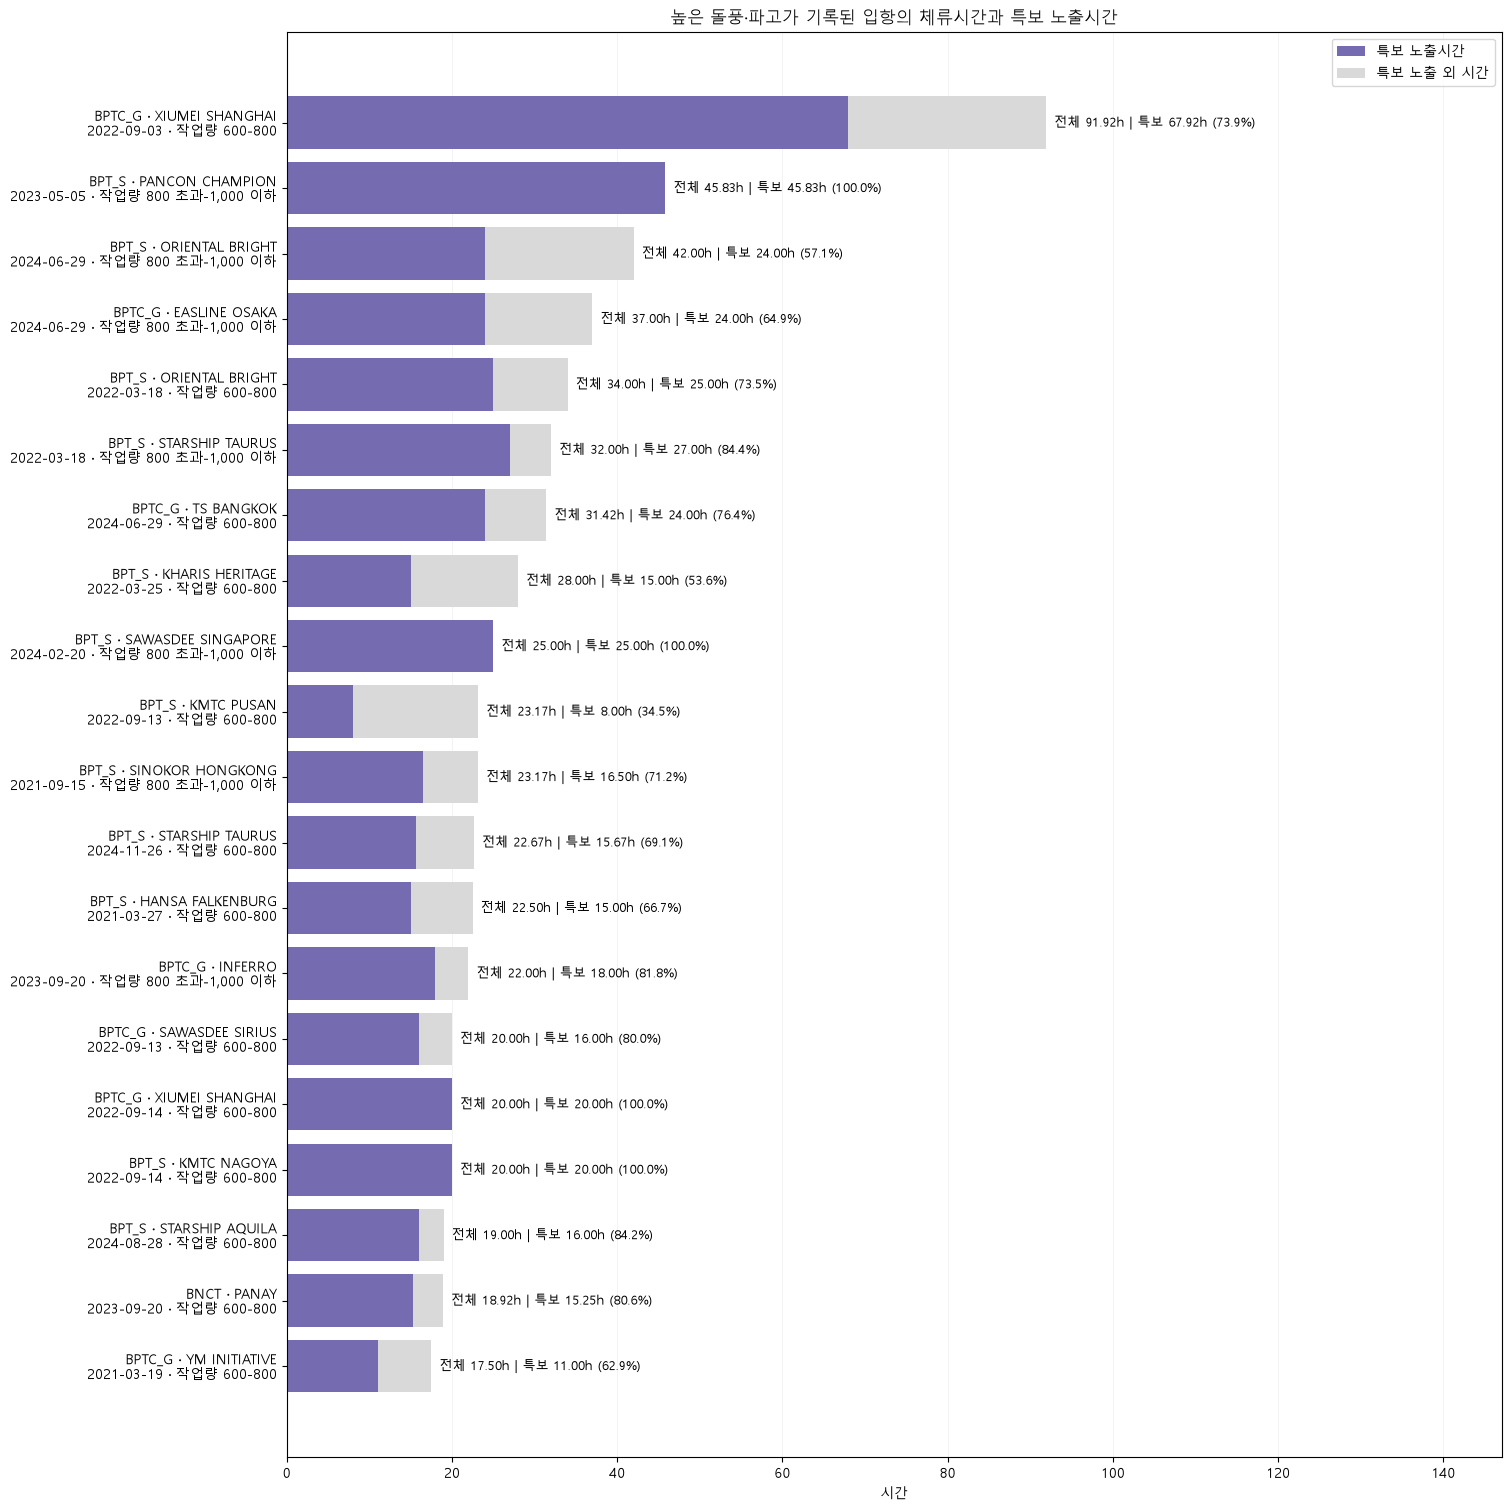

In [95]:
# 같은 입항의 체류시간 중 특보 기간과 겹친 시간을 표시한다.
자료 = 특보확인.dropna(subset=["체류시간", 특보열]).copy()
유효 = (
    자료["체류시간"].gt(0)
    & 자료[특보열].ge(0)
    & 자료[특보열].le(자료["체류시간"] + 0.01)
)
print(f"결측·시간 범위 확인이 필요한 기록: {len(특보확인) - 유효.sum()}건")

자료 = 자료.loc[유효].sort_values("체류시간", ascending=False).copy()

# 소수점 반올림으로 특보시간이 체류시간을 아주 조금 넘는 경우를 맞춘다.
자료["표시특보시간"] = np.minimum(자료[특보열], 자료["체류시간"])
자료["특보외시간"] = 자료["체류시간"] - 자료["표시특보시간"]

위치 = np.arange(len(자료))
라벨 = (
    자료["터미널"] + " · " + 자료["선박명"]
    + "\n" + pd.to_datetime(자료["접안일시"]).dt.strftime("%Y-%m-%d")
    + " · 작업량 " + 자료["작업량집단"]
)

fig, ax = plt.subplots(
    figsize=(15, 0.65 * len(자료) + 2), layout="constrained"
)

ax.barh(
    위치, 자료["표시특보시간"],
    color="#756BB1", label="특보 노출시간",
)
ax.barh(
    위치, 자료["특보외시간"],
    left=자료["표시특보시간"],
    color="#D9D9D9", label="특보 노출 외 시간",
)

for i, (_, 기록) in enumerate(자료.iterrows()):
    ax.annotate(
        f'전체 {기록["체류시간"]:.2f}h'
        f' | 특보 {기록[특보열]:.2f}h'
        f' ({기록["특보노출비율(%)"]:.1f}%)',
        (기록["체류시간"], i),
        xytext=(6, 0), textcoords="offset points",
        va="center", fontsize=9,
    )

ax.set_yticks(위치, 라벨)
ax.invert_yaxis()
ax.set_xlim(0, 자료["체류시간"].max() * 1.6)
ax.set_xlabel("시간")
ax.set_title("높은 돌풍·파고가 기록된 입항의 체류시간과 특보 노출시간")
ax.legend()
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
그림표시()

- 높은 돌풍·파고가 기록된 입항 중 체류기간 전체가 특보 기간과 겹친 사례가 있었다. SAWASDEE SINGAPORE는 25시간, XIUMEI SHANGHAI의 2022년 9월 14일 입항과 KMTC NAGOYA는 각각 20시간으로 특보 노출비율이 100%였다.
- TS BANGKOK은 체류 31.42시간 중 24시간(76.4%), STARSHIP TAURUS의 2022년 3월 18일 입항은 32시간 중 27시간(84.4%)이 특보 기간과 겹쳤다. 반면 KMTC PUSAN은 23.17시간 중 8시간(34.5%)으로 기록별 차이가 컸다.


In [96]:
# 기존 총톤수·작업량 조건을 유지해 연도-월별 통계를 만든다.
월별자료 = pd.concat([
    후보.assign(작업량집단="600-800"),
    후보2.assign(작업량집단="800 초과-1,000 이하"),
], ignore_index=True)

월별자료["연월"] = (
    pd.to_datetime(월별자료["접안일시"]).dt.to_period("M")
)

월별통계 = 월별자료.groupby(
    ["터미널", "작업량집단", "연월"]
).agg(
    기록수=("체류시간", "size"),
    체류시간_중앙값=("체류시간", "median"),
    풍속_대표값=("체류시간_풍속_중앙값_mps", "median"),
    돌풍최댓값_대표값=("체류시간_최대순간풍속_최댓값_mps", "median"),
    유의파고최댓값_대표값=("체류시간_유의파고_최댓값_m", "median"),
)

display(월별통계.round(2))

기록수  체류시간_중앙값  풍속_대표값  돌풍최댓값_대표값  유의파고최댓값_대표값
터미널    작업량집단           연월                                                    
BNCT   600-800         2021-01    1     17.83    1.21        NaN         0.40
                       2021-02    4     16.07    2.26        NaN         0.95
                       2021-03    5     14.90    1.65       4.03         0.70
                       2021-04    4     20.17    2.42       5.78         0.70
                       2021-05    1     24.17    1.98       5.80         0.90
                       2021-06    2     22.52    1.82       4.53         0.55
                       2021-10    2     13.61    1.98       4.54         0.60
                       2021-11    1     17.92    4.48      11.09         0.50
                       2021-12    1     20.80    1.41       4.62         0.30
                       2022-01    1     24.83    3.42      10.19         0.50
                       2022-02    4     21.81    2.40       5.82         0.40
                       2022-03    5     20.12    1.68       4.98         0.40
                       2022-04    2     17.40    1.81       6.84         0.40
                       2022-05    1     28.88    1.61       3.95         0.20
                       2022-07    4     20.69    1.81       5.58         0.45
                       2022-08    4     22.25    3.03       6.64         0.65
                       2022-09    1     19.78    1.64       5.15         0.40
                       2022-10    3     21.53    1.84       4.60         0.30
                       2022-11    2     18.66    1.42       3.81         0.35
                       2022-12    3     16.07    1.99       4.68         0.30
                       2023-01    3     20.67    1.70       5.91         0.60
                       2023-02    4     17.26    1.65       4.82         0.55
                       2023-03    4     17.23    1.46       4.22         0.55
                       2023-04    4     14.12    1.63       5.12         0.75
                       2023-05    2     15.95    1.23       2.95         0.25
                       2023-06    4     17.48    2.90       5.57         0.75
                       2023-07    4     19.12    1.66       4.17         0.40
                       2023-08    3     13.83    2.74       5.46         0.30
                       2023-09    5     19.58    1.99       5.35         1.10
                       2023-11    2     13.68    2.23       4.10         0.40
                       2023-12    4     13.73    1.92       6.38         0.65
                       2024-01    3     13.95    1.15       2.54         0.30
                       2024-02    1     20.97    2.20       6.49         0.60
                       2024-03    3     16.83    1.41       4.32         1.40
                       2024-04    4     20.31    1.37       3.72         0.40
                       2024-05    6     14.13    1.81       4.19         0.45
                       2024-06    3     13.68    1.68       5.22         0.30
                       2024-07    5     13.93    2.64       5.02         0.50
                       2024-08    4     19.12    2.54       5.62         0.55
                       2024-10    3     16.75    1.78       5.63         0.60
                       2024-11    1     15.07    2.91       6.73         0.40
                       2024-12    3     13.85    4.17       8.33         0.40
       800 초과-1,000 이하 2021-01    2     29.96    2.39        NaN         1.10
                       2021-03    3     15.83    1.58       6.76         0.90
                       2021-04    2     18.81    2.35       5.94         0.80
                       2021-05    2     27.88    2.92       6.65         0.45
                       2021-06    6     25.06    1.81       5.56         0.55
                       2021-07    2     24.83    3.45       7.74         1.00
                       2021-09    3     24.17    1.46       5.14         0.50
                       2022-01    1     23.13    1.00 

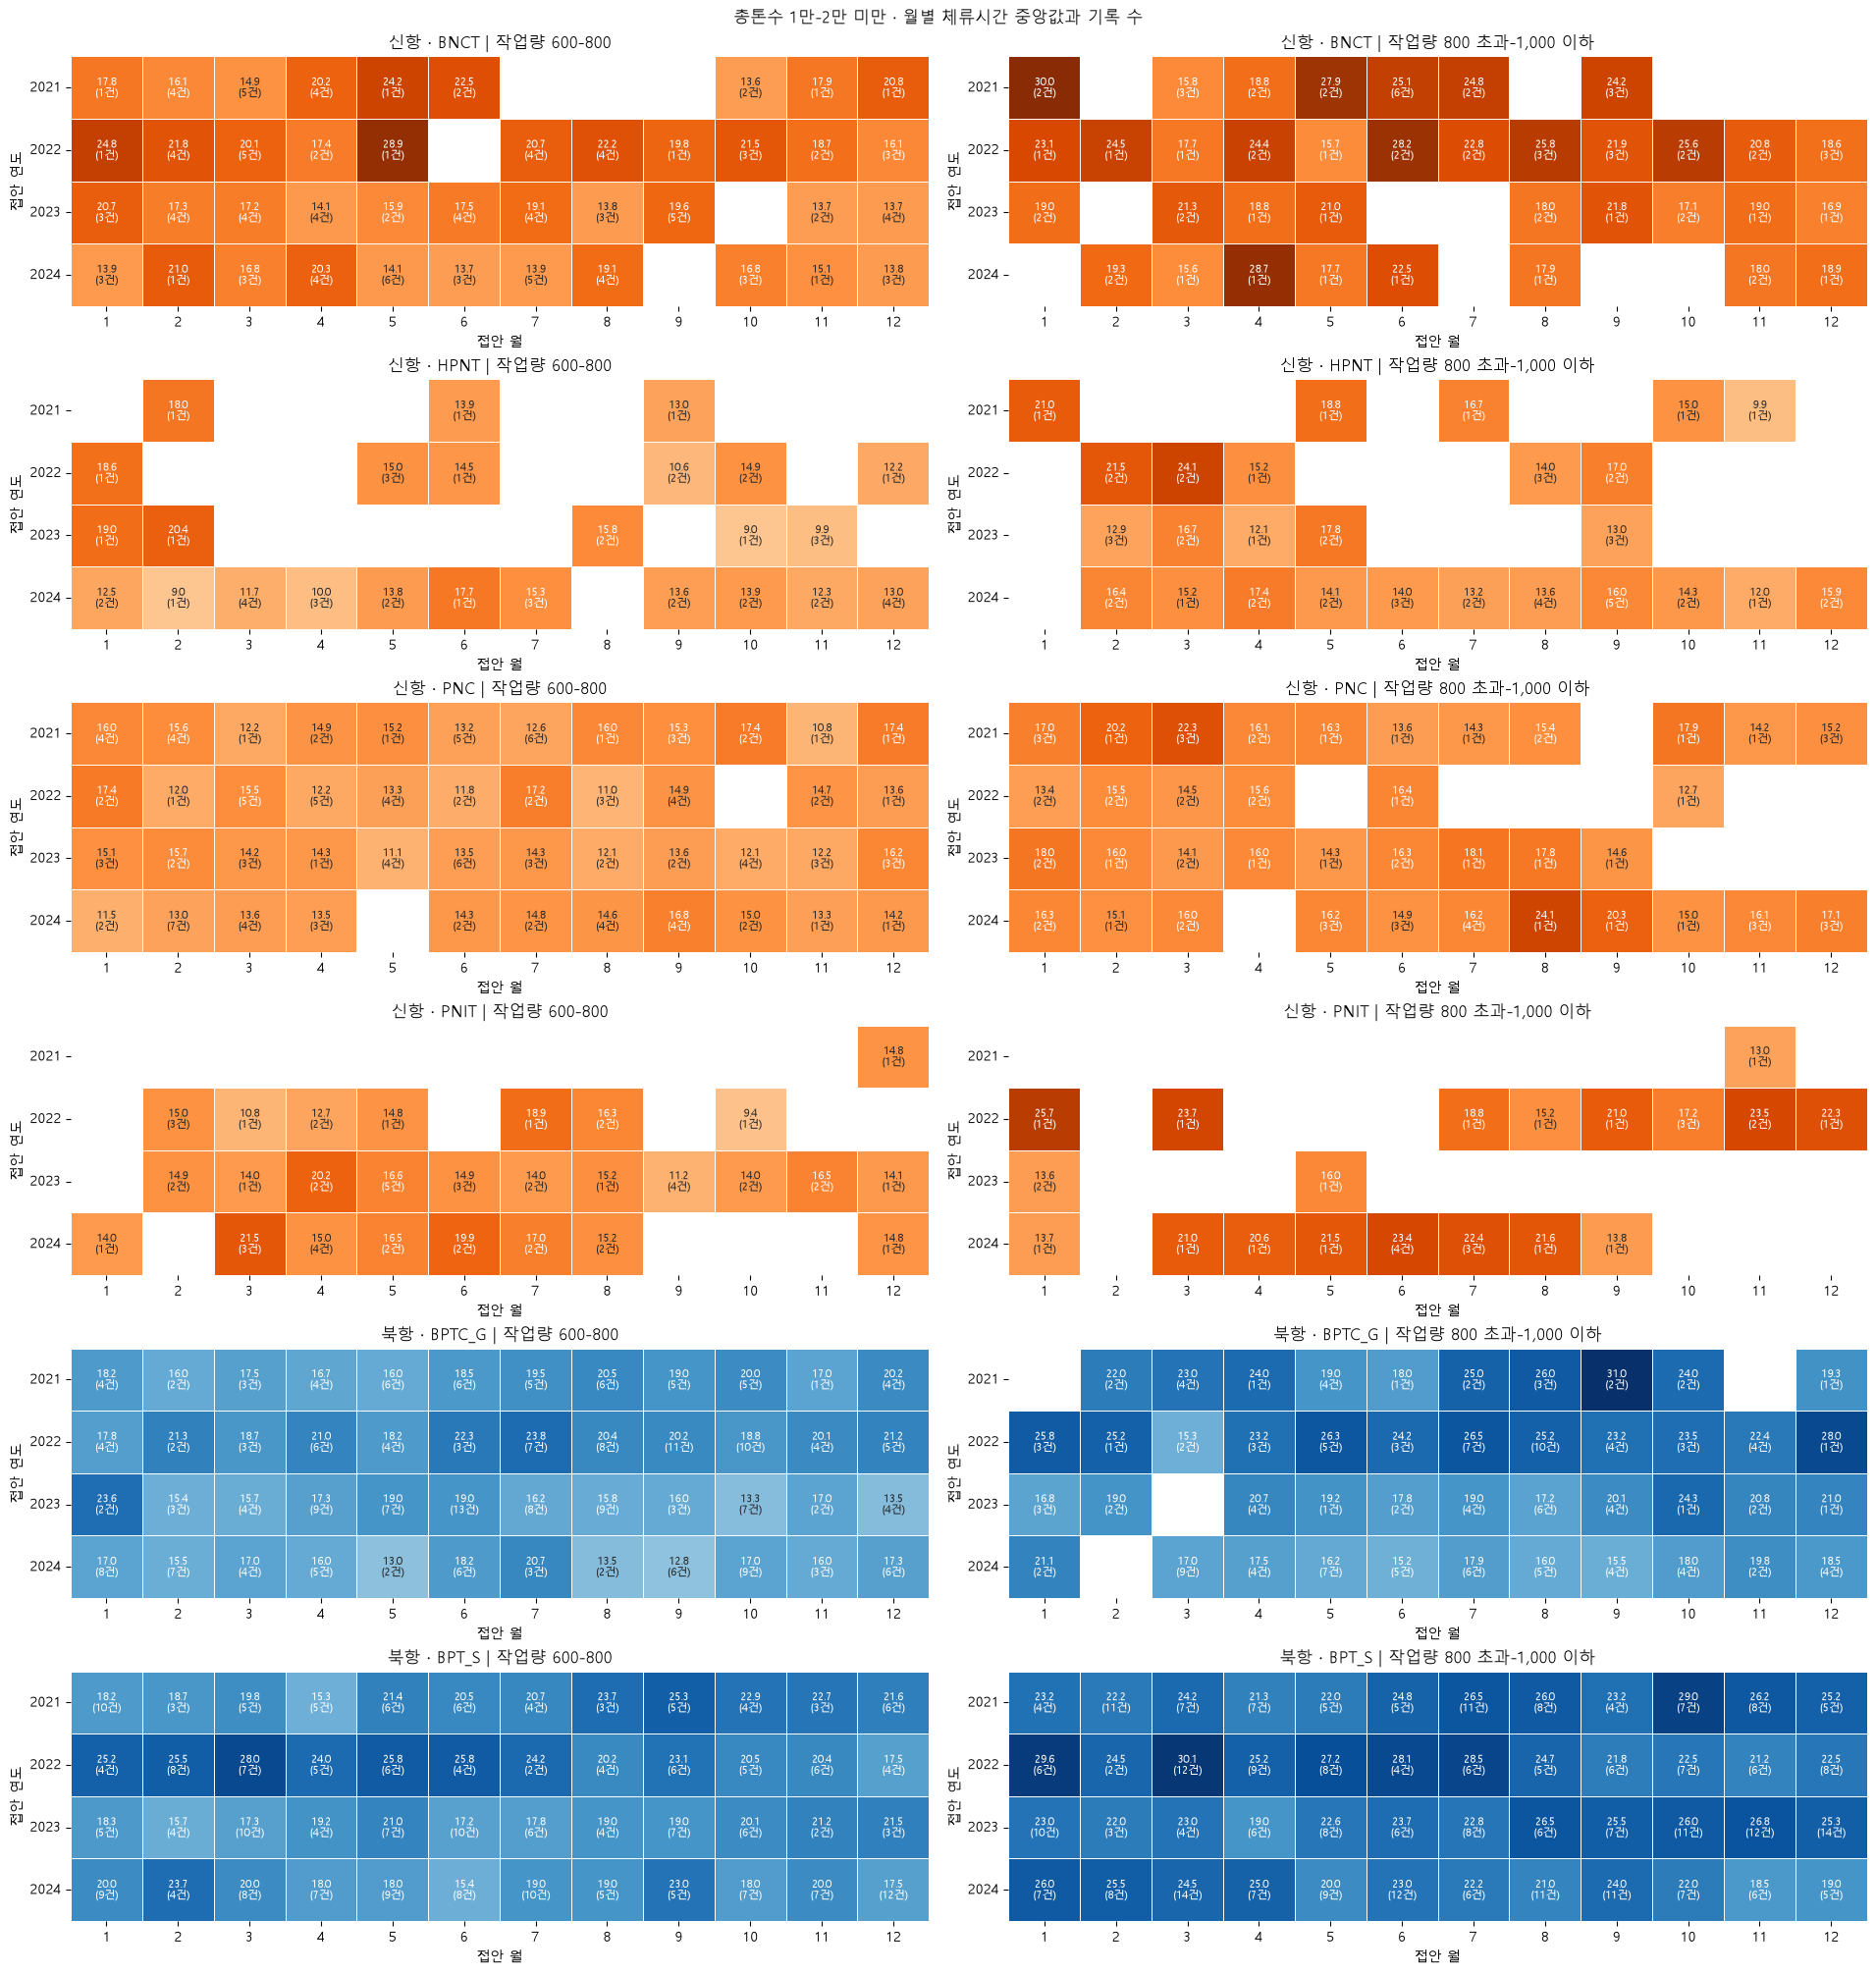

In [97]:
# 접안한 연도·월을 기준으로 체류시간을 표시한다.
월별표 = 월별통계.reset_index()
월별표["연도"] = 월별표["연월"].dt.year
월별표["월"] = 월별표["연월"].dt.month

연도순서 = sorted(월별표["연도"].unique())
월순서 = list(range(1, 13))
작업량순서 = ["600-800", "800 초과-1,000 이하"]

최대시간 = 월별표["체류시간_중앙값"].max()

fig, axes = plt.subplots(
    len(터미널목록), 2, figsize=(19, 20),
    layout="constrained",
)

for 행, 터미널 in enumerate(터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"

    for 열번호, 집단 in enumerate(작업량순서):
        ax = axes[행, 열번호]
        자료 = 월별표.loc[
            월별표["터미널"].eq(터미널)
            & 월별표["작업량집단"].eq(집단)
        ]

        시간 = 자료.pivot(
            index="연도", columns="월", values="체류시간_중앙값"
        ).reindex(index=연도순서, columns=월순서)

        건수 = 자료.pivot(
            index="연도", columns="월", values="기록수"
        ).reindex(index=연도순서, columns=월순서).fillna(0).astype(int)

        표시 = pd.DataFrame("", index=연도순서, columns=월순서)
        for 연도 in 연도순서:
            for 월 in 월순서:
                if 건수.loc[연도, 월] > 0:
                    표시.loc[연도, 월] = (
                        f"{시간.loc[연도, 월]:.1f}\n"
                        f"({건수.loc[연도, 월]}건)"
                    )

        sns.heatmap(
            시간.astype(float),
            annot=표시, fmt="",
            cmap="Blues" if 북항 else "Oranges",
            vmin=0, vmax=최대시간,
            linewidths=0.5, linecolor="white",
            cbar=False, annot_kws={"fontsize": 8},
            ax=ax,
        )
        ax.set_title(f"{항만} · {터미널} | 작업량 {집단}")
        ax.set_xlabel("접안 월")
        ax.set_ylabel("접안 연도")
        ax.tick_params(axis="y", rotation=0)

fig.suptitle("총톤수 1만-2만 미만 · 월별 체류시간 중앙값과 기록 수")
그림표시()

- BPT_S는 2022년 3월에 두 작업량 집단 모두 체류시간이 길었다. 중앙값은 작업량 600-800에서 28.00시간(7건), 800 초과-1,000 이하에서 30.08시간(12건)이었다. 2024년 6월에는 각각 15.42시간(8건), 23.00시간(12건)으로 낮아졌다.
- BPTC_G도 2022년 7월의 체류시간 중앙값이 각각 23.75시간(7건), 26.50시간(7건)이었던 반면, 2024년 9월에는 12.79시간(6건), 15.50시간(4건)이었다. 두 작업량 집단에서 월별 변화가 비슷하게 나타난 사례다.
- 체류시간이 긴 달이 반드시 월별 기상 대표값도 높은 달은 아니었다. BPT_S의 작업량 800 초과-1,000 이하 집단은 2022년 3월 체류시간이 30.08시간이었지만, 돌풍 최댓값 대표값은 5.48m/s, 유의파고 최댓값 대표값은 0.80m였다.
- HPNT·PNIT는 월별 기록이 1-3건인 경우가 많았다. 특히 1건인 칸은 입항 한 건의 체류시간을 나타내므로, 진한 칸 하나만으로 특정 월이나 계절의 일반적인 특성을 판단하기 어렵다.

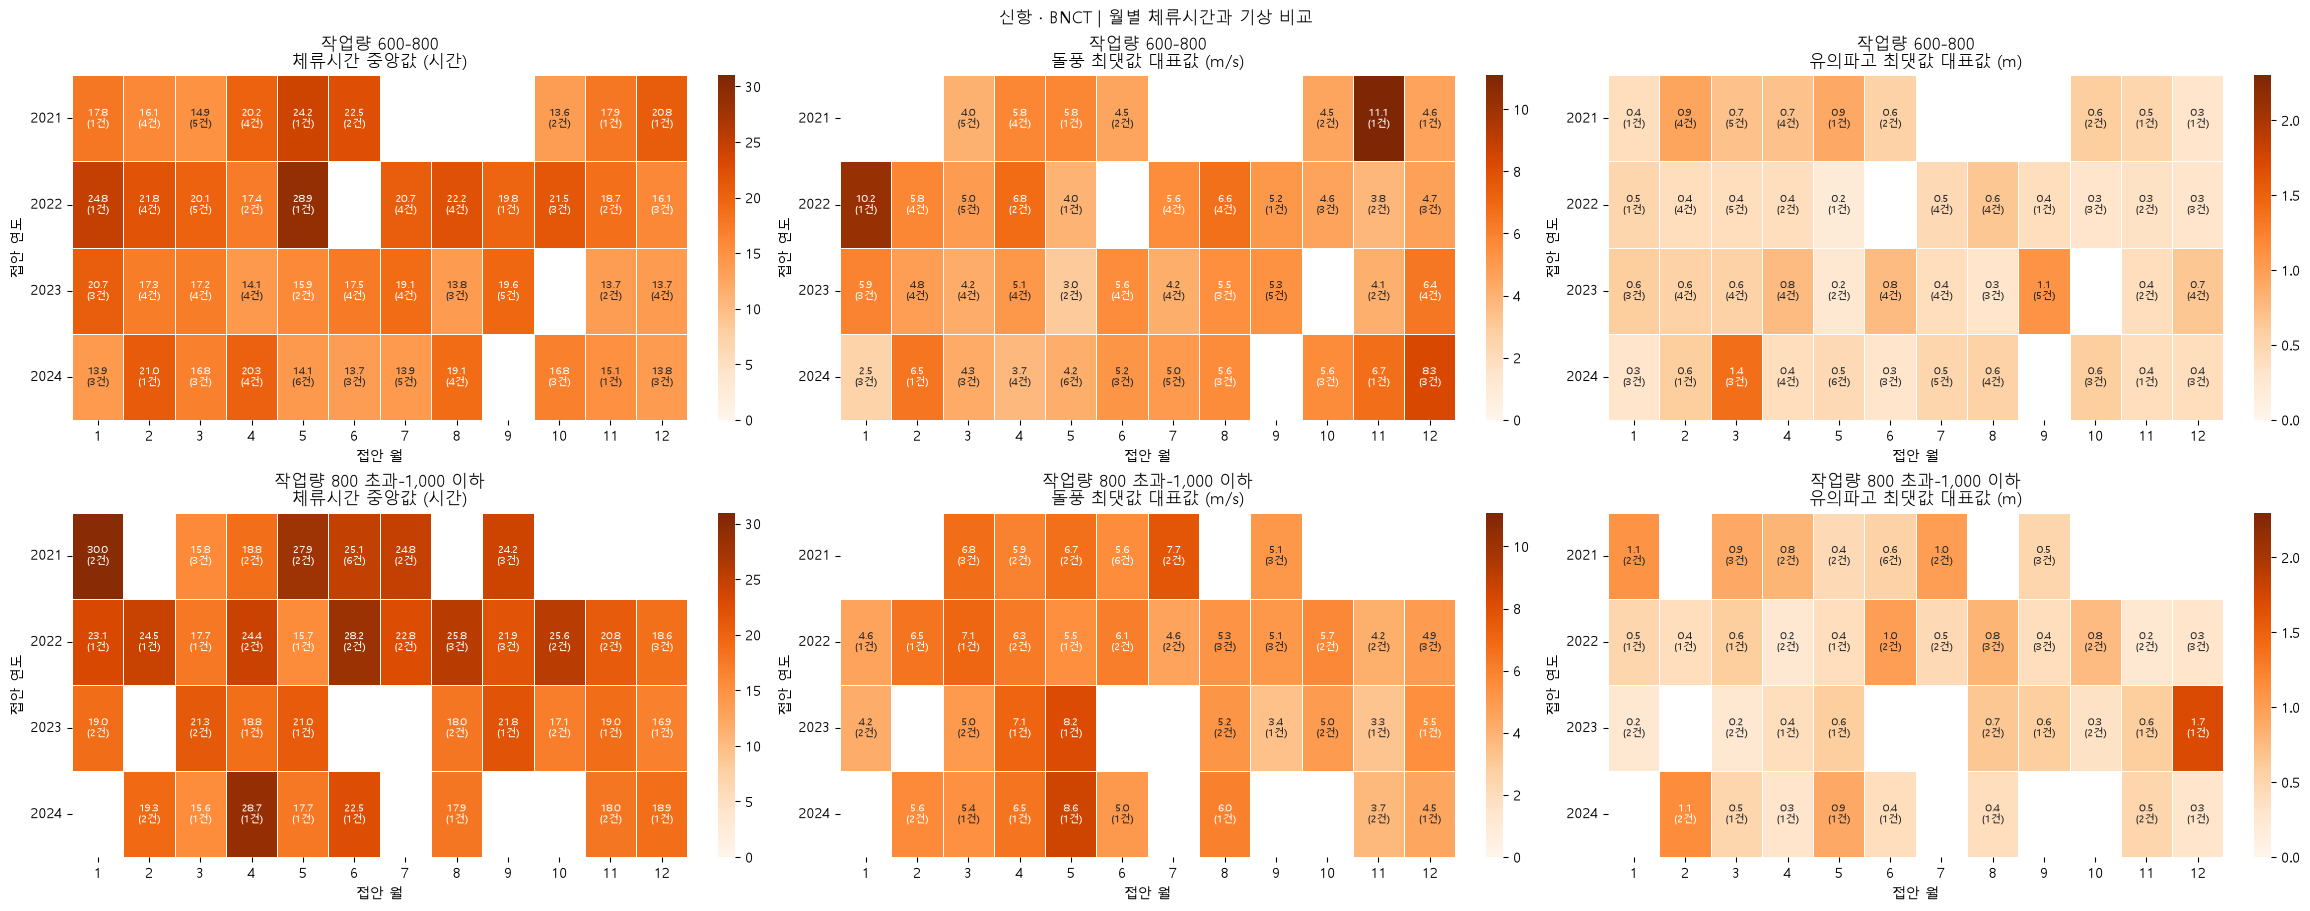

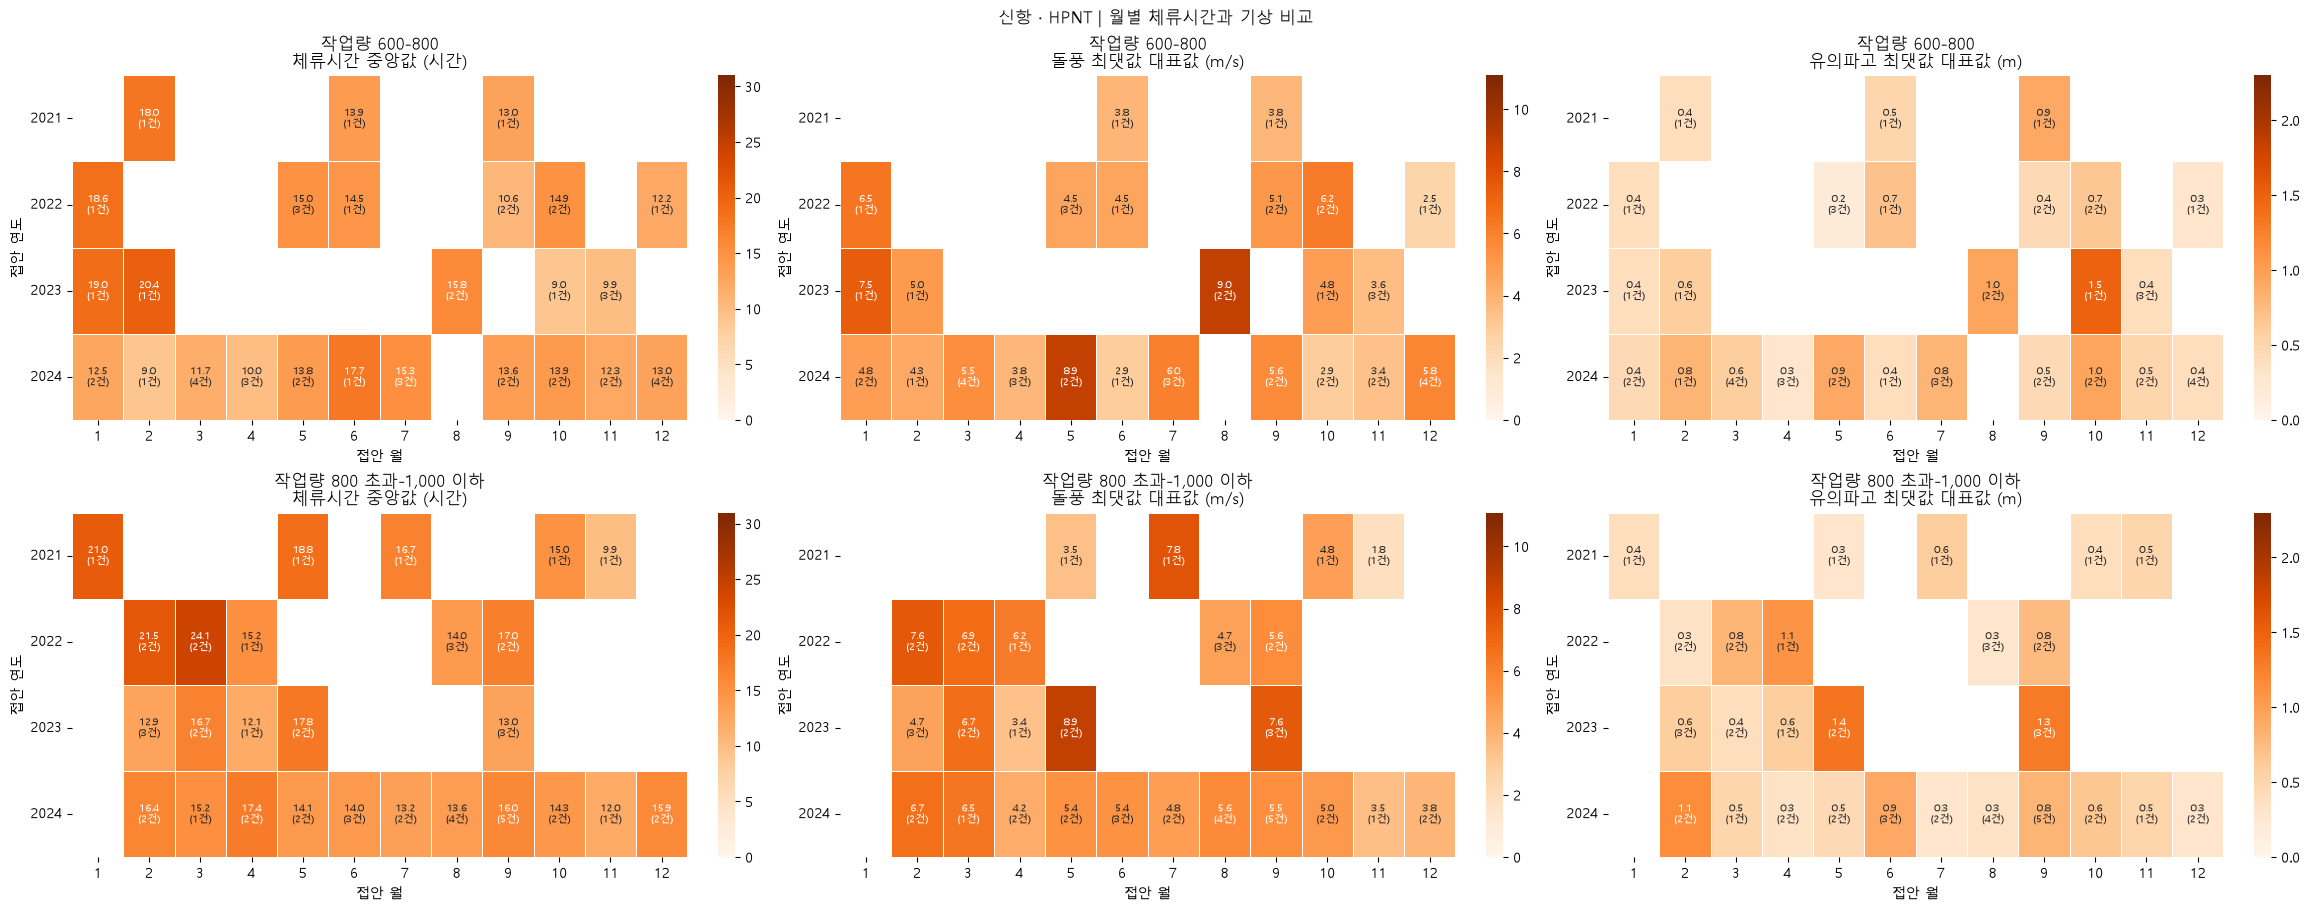

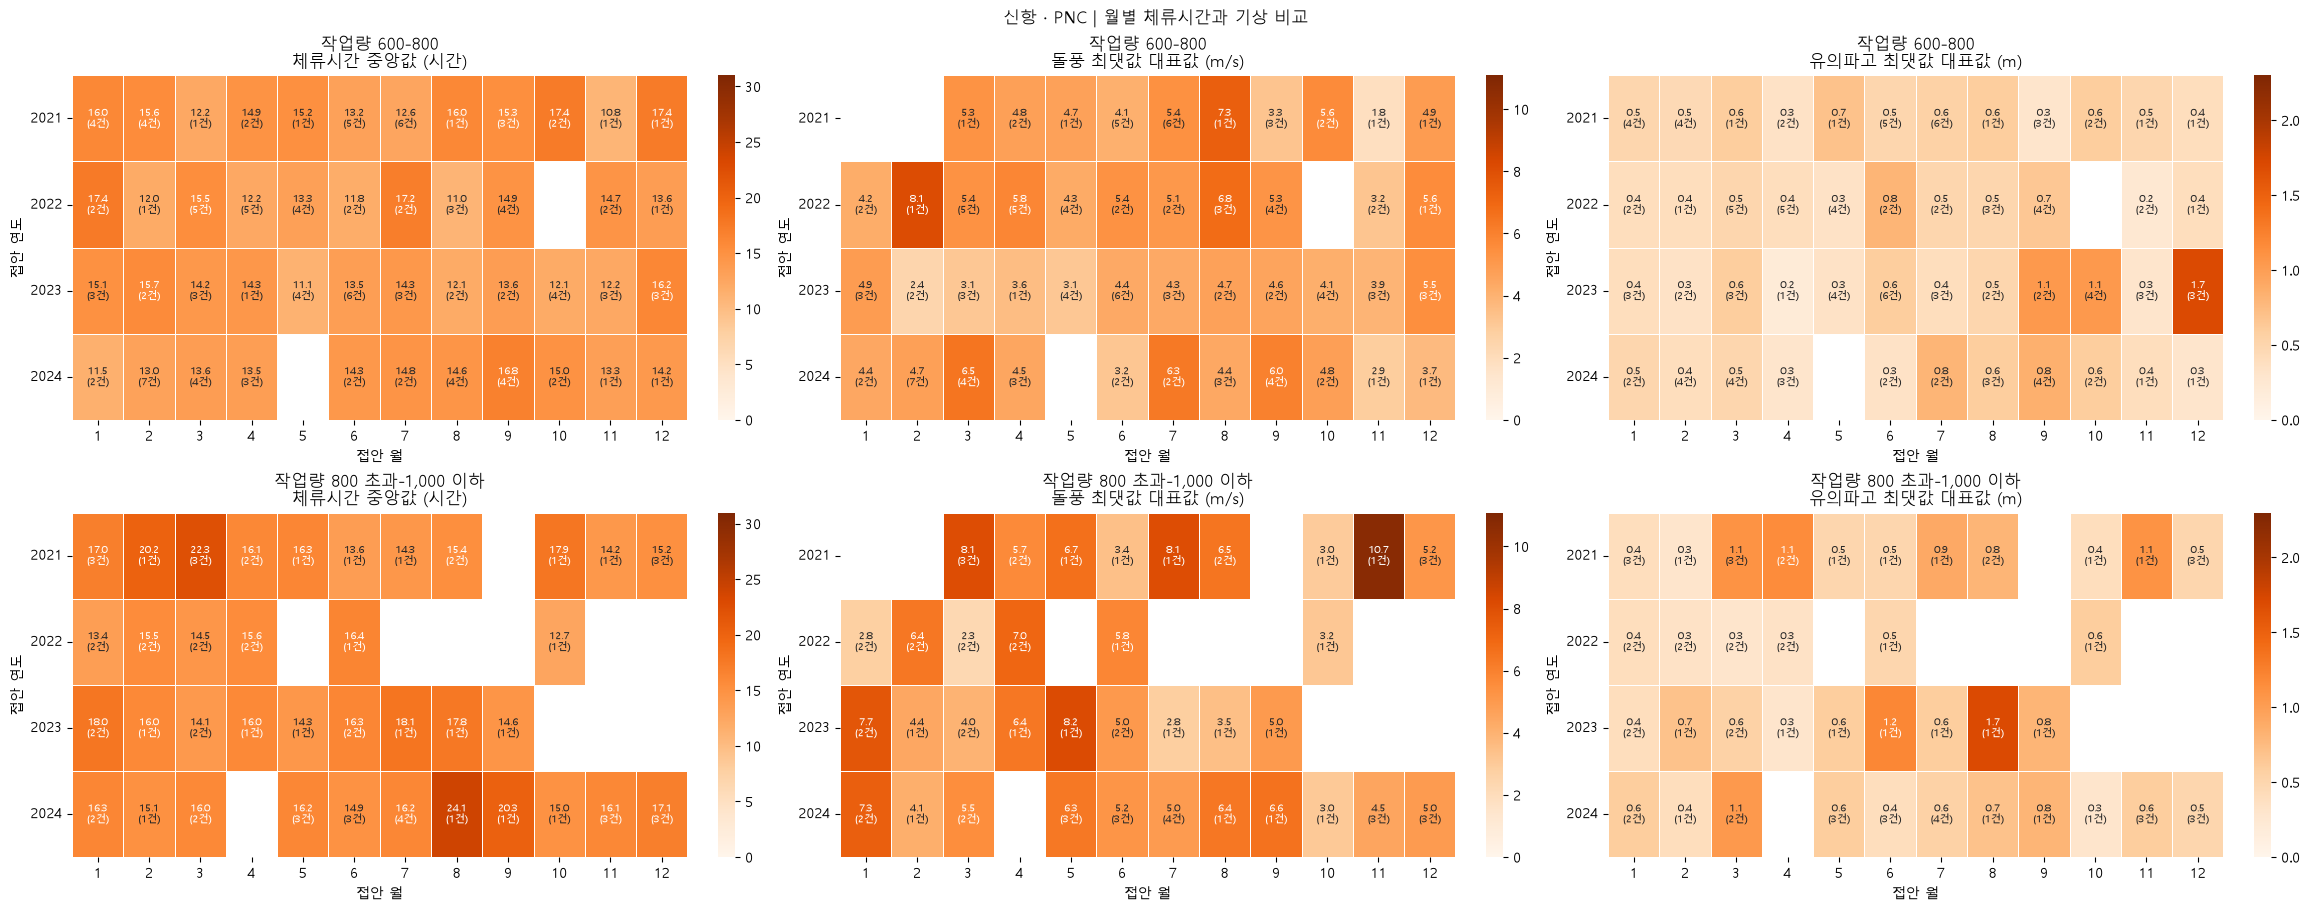

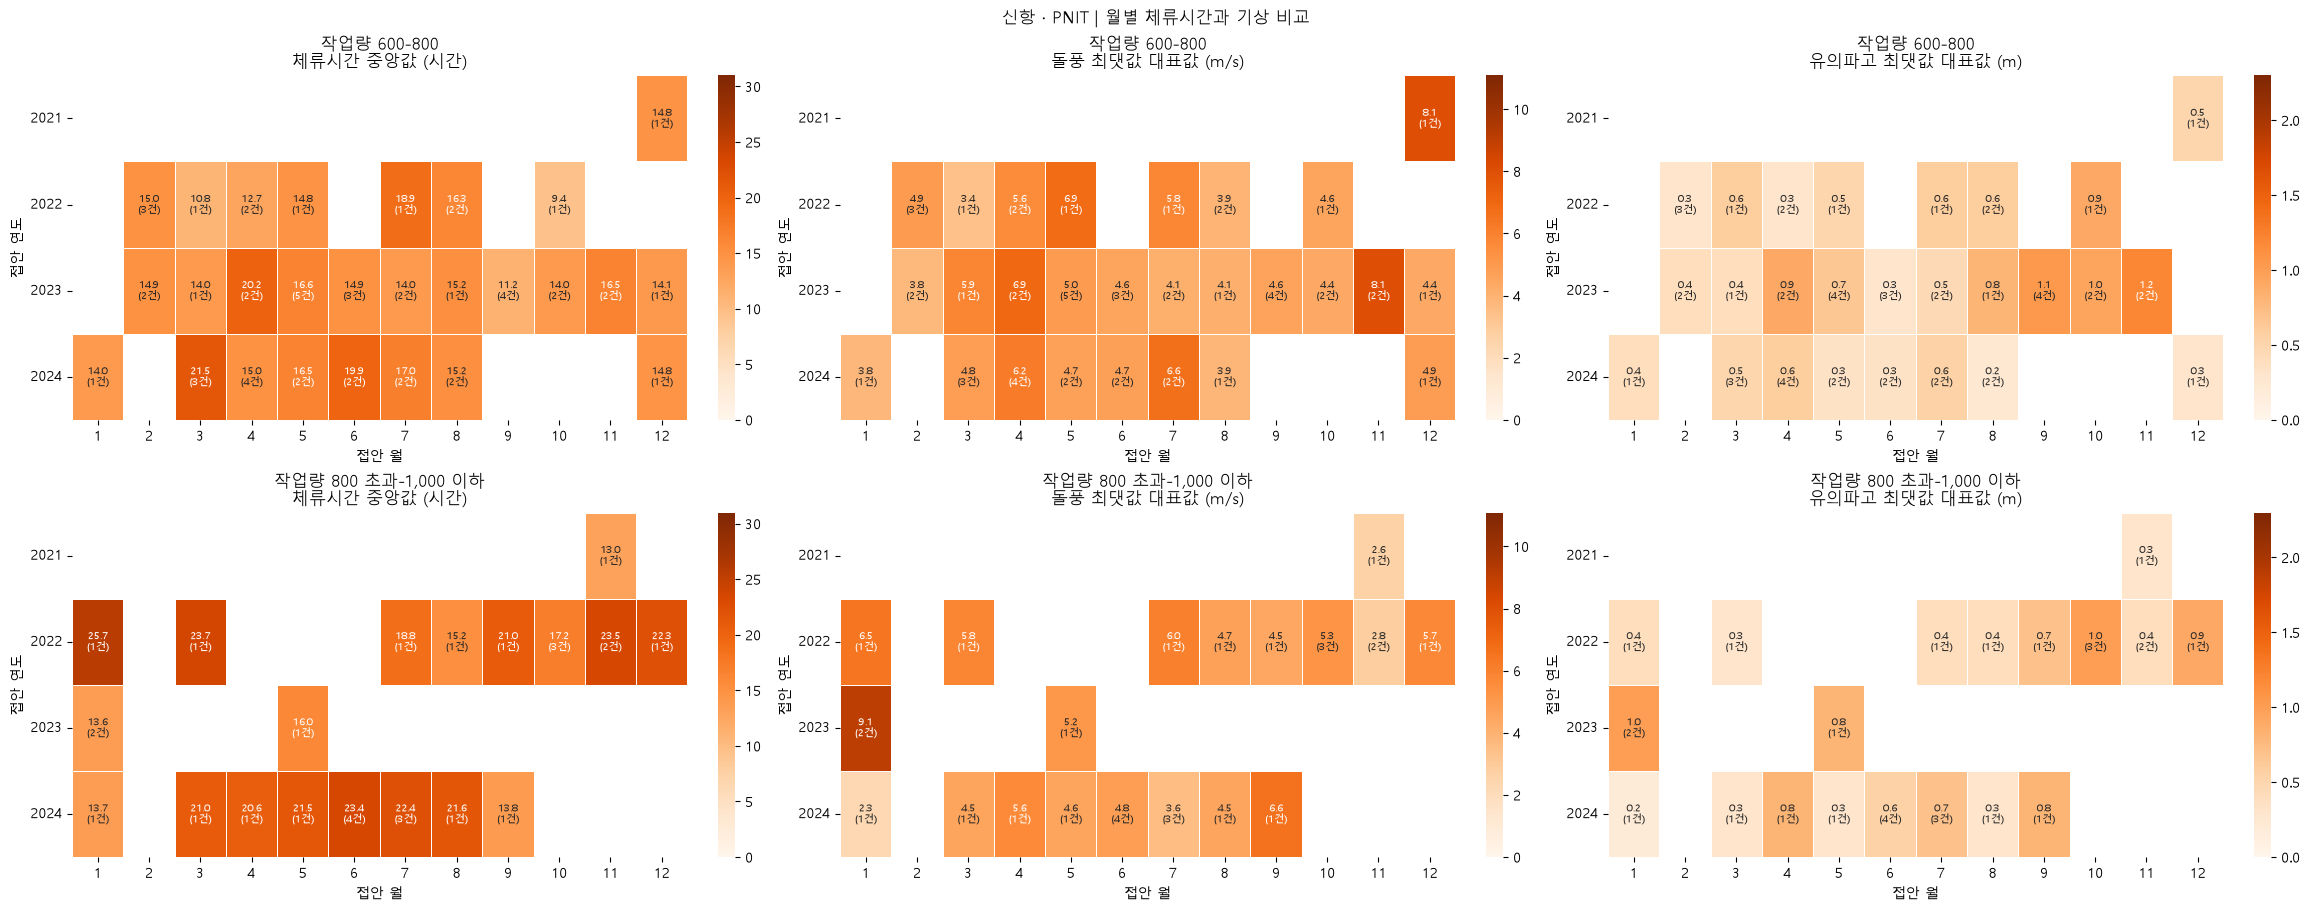

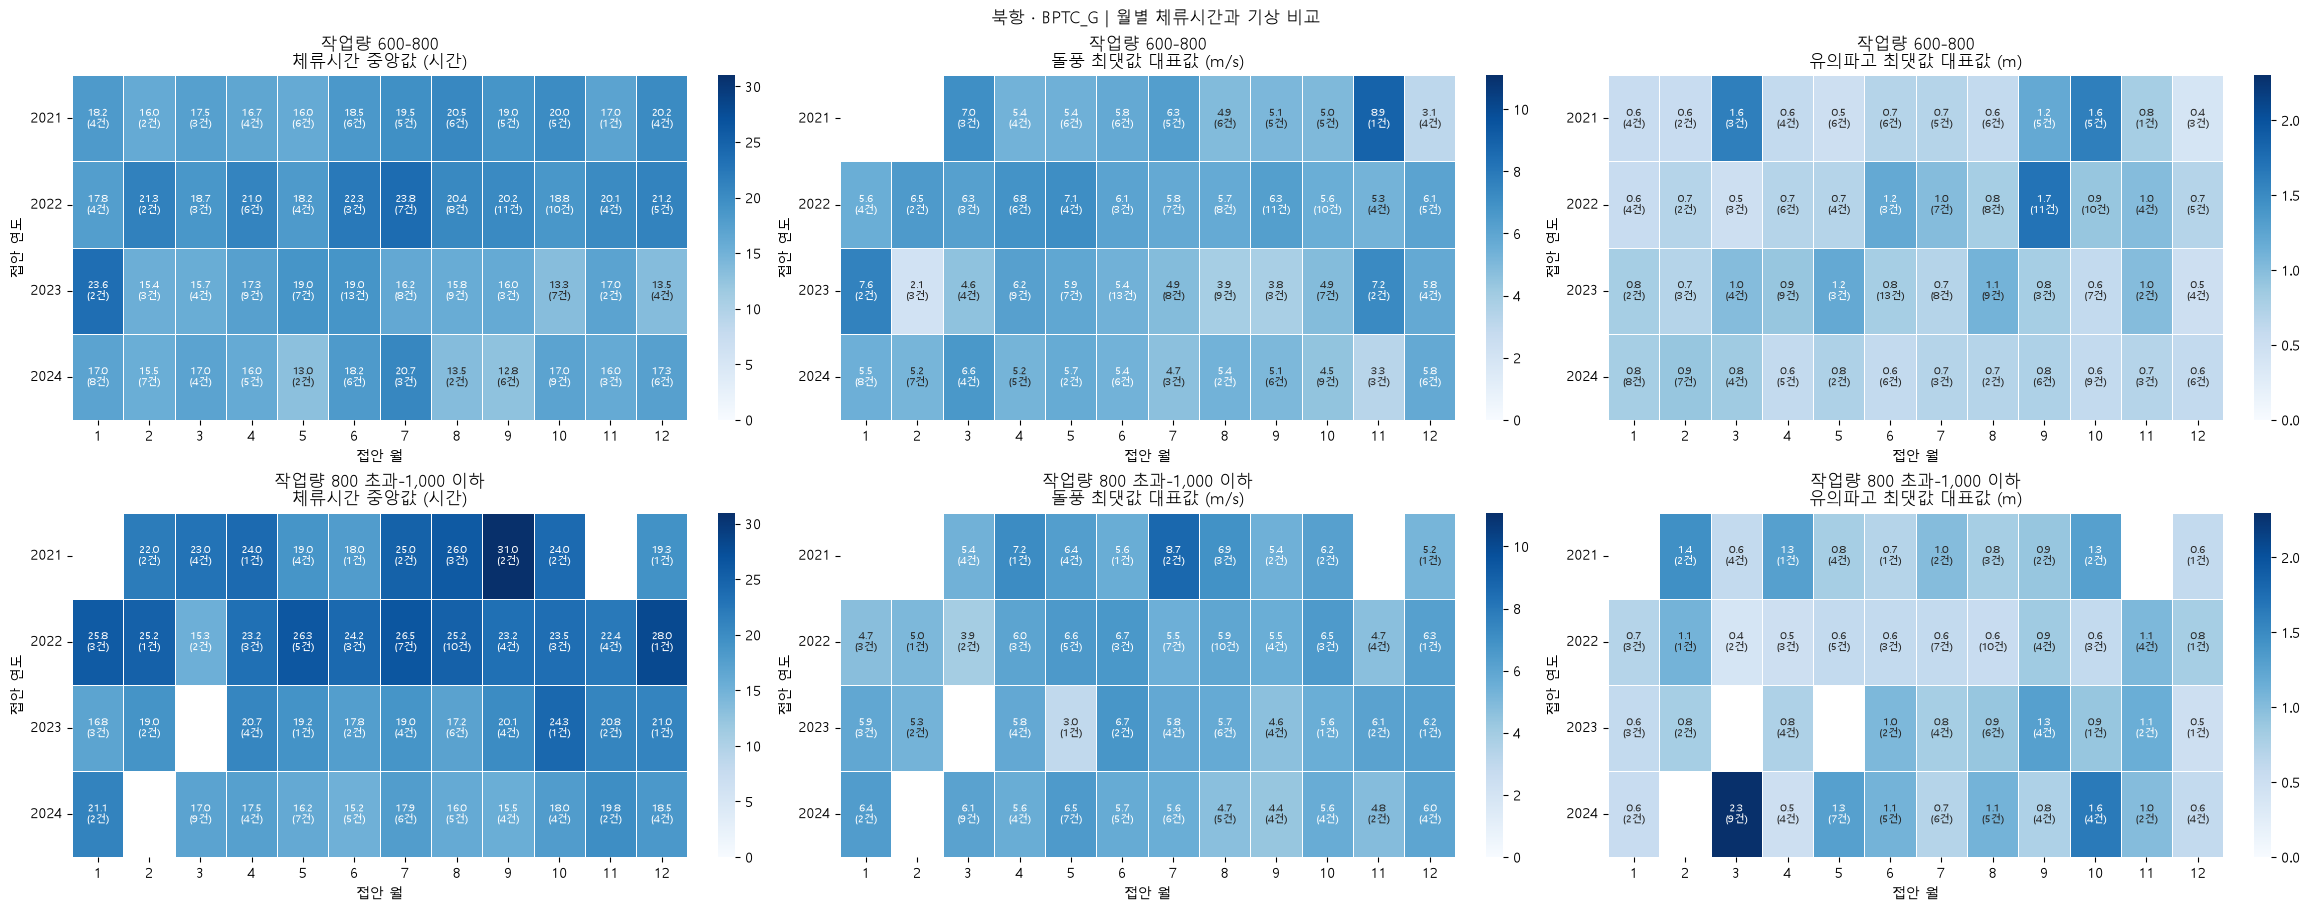

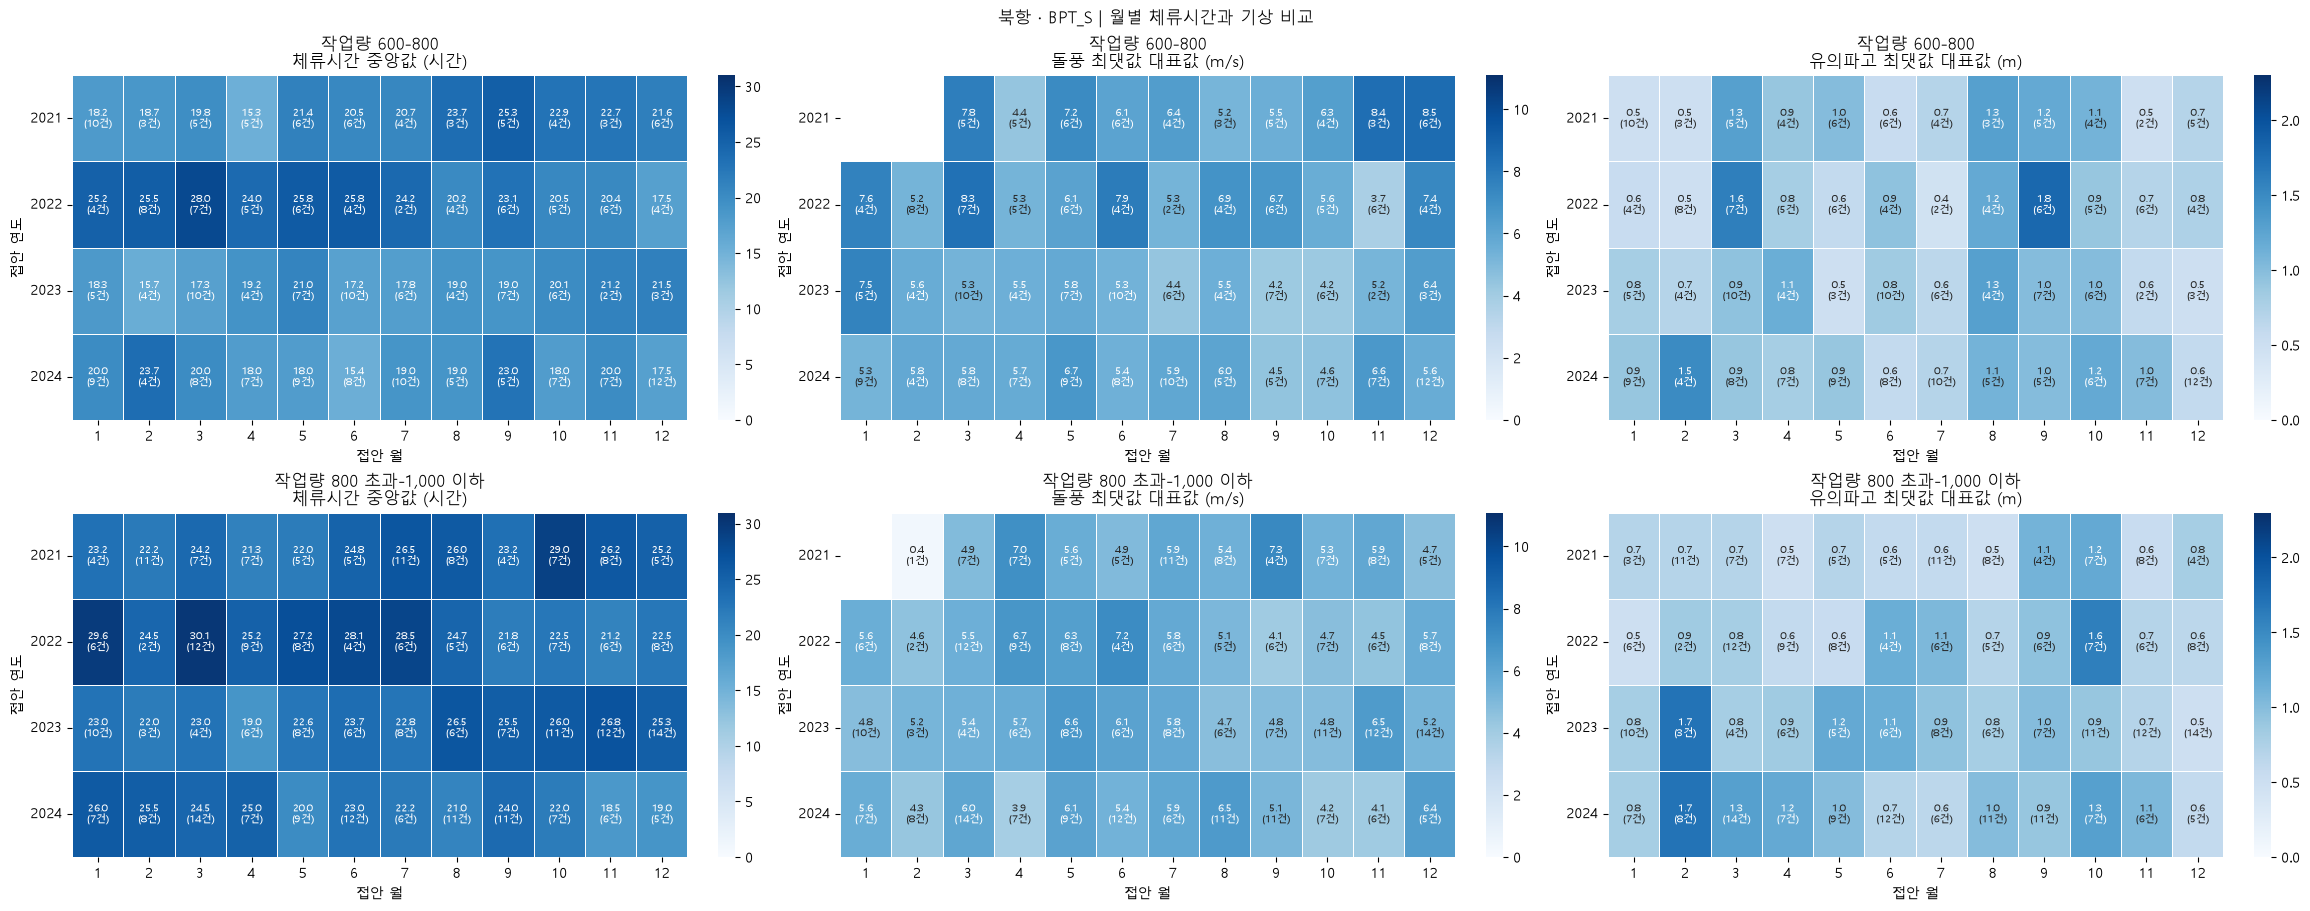

In [98]:
# 모든 터미널에서 월별 체류시간과 기상의 변화가 겹치는지 비교한다.
# 기존 총톤수 1만-2만 미만과 두 작업량 집단을 유지한다.
작업량순서 = ["600-800", "800 초과-1,000 이하"]

지표설정 = [
    ("체류시간_중앙값", "체류시간", "체류시간 중앙값 (시간)"),
    (
        "돌풍최댓값_대표값",
        "체류시간_최대순간풍속_최댓값_mps",
        "돌풍 최댓값 대표값 (m/s)",
    ),
    (
        "유의파고최댓값_대표값",
        "체류시간_유의파고_최댓값_m",
        "유의파고 최댓값 대표값 (m)",
    ),
]

월별표 = 월별통계.reset_index()
월별표["연도"] = 월별표["연월"].dt.year
월별표["월"] = 월별표["연월"].dt.month
연도순서 = sorted(월별표["연도"].unique())
월순서 = list(range(1, 13))

# 월별 전체 기록 수와 기상변수의 유효 기록 수는 다를 수 있다.
# 각 지표의 결측을 제외한 건수를 따로 계산한다.
유효건수표 = 월별자료.groupby(
    ["터미널", "작업량집단", "연월"]
)[[설정[1] for 설정 in 지표설정]].count().reset_index()
유효건수표["연도"] = 유효건수표["연월"].dt.year
유효건수표["월"] = 유효건수표["연월"].dt.month

# 같은 지표의 색상 범위를 모든 터미널·작업량 집단에서 통일한다.
지표상한 = {
    지표: 월별표[지표].max()
    for 지표, _, _ in 지표설정
}

for 터미널 in 터미널목록:
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    색 = "Blues" if 북항 else "Oranges"

    fig, axes = plt.subplots(
        2, 3, figsize=(23, 9), layout="constrained"
    )

    for 행, 집단 in enumerate(작업량순서):
        자료 = 월별표.loc[
            월별표["터미널"].eq(터미널)
            & 월별표["작업량집단"].eq(집단)
        ]
        건수자료 = 유효건수표.loc[
            유효건수표["터미널"].eq(터미널)
            & 유효건수표["작업량집단"].eq(집단)
        ]

        for 열번호, (지표, 원본열, 제목) in enumerate(지표설정):
            값 = 자료.pivot(
                index="연도", columns="월", values=지표
            ).reindex(index=연도순서, columns=월순서)

            건수 = 건수자료.pivot(
                index="연도", columns="월", values=원본열
            ).reindex(
                index=연도순서, columns=월순서
            ).fillna(0).astype(int)

            표시 = pd.DataFrame("", index=연도순서, columns=월순서)
            for 연도 in 연도순서:
                for 월 in 월순서:
                    if pd.notna(값.loc[연도, 월]):
                        표시.loc[연도, 월] = (
                            f"{값.loc[연도, 월]:.1f}\n"
                            f"({건수.loc[연도, 월]}건)"
                        )

            상한 = 지표상한[지표]
            ax = axes[행, 열번호]
            sns.heatmap(
                값.astype(float),
                annot=표시, fmt="",
                cmap=색, vmin=0,
                vmax=상한 if pd.notna(상한) and 상한 > 0 else 1,
                linewidths=0.5, linecolor="white",
                cbar=True, annot_kws={"fontsize": 7},
                ax=ax,
            )
            ax.set_title(f"작업량 {집단}\n{제목}")
            ax.set_xlabel("접안 월")
            ax.set_ylabel("접안 연도")
            ax.tick_params(axis="y", rotation=0)

    # 기상 대표값은 입항별 최댓값들의 월별 중앙값이다.
    fig.suptitle(f"{항만} · {터미널} | 월별 체류시간과 기상 비교")
    그림표시()

- **BPT_S**는 2022년 3월에 두 작업량 집단 모두 체류시간 중앙값이 길었다. 작업량 600-800은 28.00시간(7건), 800 초과-1,000 이하는 30.08시간(12건)이었지만, 돌풍 대표값은 각각 8.28·5.48m/s로 달랐다.
- **BPTC_G**의 작업량 800 초과-1,000 이하 집단은 2022년 7월 체류시간 중앙값이 26.50시간(7건)이었고 유의파고 대표값은 0.60m였다. 반면 2024년 3월은 파고 대표값이 2.30m였지만 체류시간은 17.00시간(9건)이었다.
- **BNCT·PNC**에서도 체류시간이 긴 달이 반드시 기상 대표값이 가장 높은 달은 아니었다. BNCT의 작업량 800 초과-1,000 이하 집단은 2021년 6월 25.06시간(6건)이었지만, 돌풍·파고 대표값은 5.56m/s·0.55m였다. PNC는 2021년 3월 22.33시간(3건), 8.10m/s·1.10m였다.
- **HPNT·PNIT**는 월별 기록이 적어 특정 입항의 영향이 크게 나타났다. 예를 들어 PNIT의 작업량 800 초과-1,000 이하 집단에서 2022년 1월의 25.67시간은 입항 1건의 체류시간이다.
- 월별로 체류시간과 기상값이 함께 높아진 사례는 있었으나, 모든 터미널과 두 작업량 집단에서 같은 경향이 반복되지는 않았다. 기상 대표값은 입항별 최댓값을 다시 월별 중앙값으로 요약한 수치이므로, 짧게 발생한 악천후와 개별 장기 체류 기록이 가려질 수 있다.

## 종합결론

- 총톤수 1만 이상-2만 미만에서 작업량 600-800과 800 초과-1,000 이하를 구분해 6개 터미널의 기상조건별 체류시간을 비교하였다.
- 돌풍 최댓값 8m/s 이상과 5m/s 미만을 비교하면, BPT_S는 두 작업량 집단에서 체류시간 중앙값이 각각 3.83시간·3.67시간 길었다. BPTC_G도 각각 2.33시간·1.83시간 길어 두 집단에서 비슷한 방향이 나타났다.
- 높은 파고와 강한 돌풍이 함께 기록된 입항은 주로 북항에 있었으며, 일부 긴 체류 기록은 특보 기간과 상당 부분 겹쳤다. 다만 높은 기상 구간의 건수가 적고 기록별 체류시간 차이도 컸다.
- 월별로도 체류시간과 기상 대표값이 함께 높아진 사례가 있었지만, 모든 터미널·작업량 집단에서 같은 경향이 반복되지는 않았다.
- 이번 분석은 정해진 선박 규모·작업량 범위에서 관측된 관계를 보여준다. 기상·특보 노출이 체류 지연을 얼마나 발생시켰는지 판단하려면 시간별 기상과 실제 작업·중단 기록을 연결한 추가 검토가 필요하다.

# 북항과 신항으로 더 기준을 세분화

In [99]:
# 북항·신항을 나눠 터미널별 선박 규모의 분포를 기록 수와 비율로 확인한다.
항만별터미널 = {
    "북항": ["BPTC_G", "BPT_S"],
    "신항": ["BNCT", "HPNT", "PNC", "PNIT"],
}

톤수구간 = [0, 5000, 10000, 20000, 40000, 80000,
        100000, 150000, 200000, float("inf")]
구간명 = ["0-5천", "5천-1만", "1만-2만", "2만-4만", "4만-8만",
       "8만-10만", "10만-15만", "15만-20만", "20만 이상"]

톤수자료 = df1[["항만구분", "터미널", "총톤수"]].copy()
톤수자료["톤수구간"] = pd.cut(
    톤수자료["총톤수"], bins=톤수구간, labels=구간명, right=False
)

for 항만, 터미널들 in 항만별터미널.items():
    자료 = 톤수자료.loc[톤수자료["항만구분"].eq(항만)]

    건수 = pd.crosstab(자료["톤수구간"], 자료["터미널"], dropna=False)
    건수 = 건수.reindex(index=구간명, columns=터미널들, fill_value=0)
    건수[f"{항만} 전체"] = 건수.sum(axis=1)

    # 각 열의 합계를 기준으로 비율을 계산한다.
    비율 = 건수.div(건수.sum()).mul(100).round(1)

    print(f"{항만} 터미널별 총톤수 분포")
    display(건수.astype(str) + " (" + 비율.astype(str) + "%)")

북항 터미널별 총톤수 분포


터미널,BPTC_G,BPT_S,북항 전체
톤수구간,,,
0-5천,152 (2.4%),977 (8.7%),1129 (6.4%)
5천-1만,4267 (67.9%),7811 (69.2%),12078 (68.8%)
1만-2만,1370 (21.8%),1607 (14.2%),2977 (17.0%)
2만-4만,322 (5.1%),729 (6.5%),1051 (6.0%)
4만-8만,171 (2.7%),155 (1.4%),326 (1.9%)
8만-10만,1 (0.0%),0 (0.0%),1 (0.0%)
10만-15만,0 (0.0%),1 (0.0%),1 (0.0%)
15만-20만,0 (0.0%),0 (0.0%),0 (0.0%)
20만 이상,0 (0.0%),0 (0.0%),0 (0.0%)


신항 터미널별 총톤수 분포


터미널,BNCT,HPNT,PNC,PNIT,신항 전체
톤수구간,,,,,
0-5천,0 (0.0%),9 (0.3%),1 (0.0%),25 (0.8%),35 (0.2%)
5천-1만,185 (5.2%),410 (13.7%),894 (13.3%),129 (4.1%),1618 (9.8%)
1만-2만,469 (13.2%),259 (8.7%),571 (8.5%),262 (8.3%),1561 (9.5%)
2만-4만,214 (6.0%),701 (23.5%),961 (14.3%),531 (16.8%),2407 (14.6%)
4만-8만,696 (19.6%),573 (19.2%),1784 (26.5%),589 (18.6%),3642 (22.2%)
8만-10만,702 (19.7%),255 (8.5%),1244 (18.5%),558 (17.7%),2759 (16.8%)
10만-15만,866 (24.3%),674 (22.6%),614 (9.1%),804 (25.4%),2958 (18.0%)
15만-20만,370 (10.4%),95 (3.2%),440 (6.5%),252 (8.0%),1157 (7.0%)
20만 이상,57 (1.6%),9 (0.3%),217 (3.2%),11 (0.3%),294 (1.8%)


- 터미널별 선박 규모는 항만에 따라 차이가 커서, 북항과 신항을 나눠 터미널별 총톤수 분포를 확인했다.
- 북항은 총톤수 1만 미만이 75.2%로 소형 선박에 치우쳐 있고, 신항은 10만 이상이 26.8%로 대형 선박의 비중이 높다.
- 이러한 차이를 뚜렷하게 보여주기 위해 항만별로 대표적인 소형·대형 구간을 나눠 확인하기로 했다.
- 북항은 BPTC_G 4,267건(67.9%), BPT_S 7,811건(69.2%)으로 두 터미널 모두 기록이 가장 많은 총톤수 5천 이상 - 1만 미만 구간을 확인한다.
- 신항은 BNCT 866건(24.3%), HPNT 674건(22.6%), PNC 614건(9.1%), PNIT 804건(25.4%)이 포함된 총톤수 10만 이상 - 15만 미만 구간을 확인한다.
- 4만 이상 - 8만 미만 구간은 신항의 기록이 많지만 북항과의 선박 규모 차이를 드러내기 어려워 이번 비교에서는 제외했다.
- 두 구간의 선박 규모가 다르므로, 비교는 항만 안의 터미널끼리 진행한다.

In [100]:
# 작업량 분포 확인 (북항/신항)
# 북항·신항의 비교 구간에서 터미널별 작업량 분포를 확인한다.
항만설정 = {
    "북항": {
        "터미널": ["BPTC_G", "BPT_S"],
        "톤수범위": (5_000, 10_000),
    },
    "신항": {
        "터미널": ["BNCT", "HPNT", "PNC", "PNIT"],
        "톤수범위": (100_000, 150_000),
    },
}

항만별비교자료 = {}

for 항만, 설정 in 항만설정.items():
    하한, 상한 = 설정["톤수범위"]
    비교자료 = df1.loc[
        df1["항만구분"].eq(항만)
        & df1["총톤수"].between(하한, 상한, inclusive="left")
    ].copy()
    항만별비교자료[항만] = 비교자료

    작업량표 = 비교자료.groupby("터미널")["총작업량"].agg(
        전체건수="size",
        작업량0_건수=lambda s: s.eq(0).sum(),
        작업량_25=lambda s: s[s.gt(0)].quantile(0.25),
        작업량_중앙값=lambda s: s[s.gt(0)].median(),
        작업량_75=lambda s: s[s.gt(0)].quantile(0.75),
    ).reindex(설정["터미널"])

    print(f"{항만} 총톤수 {하한:,}-{상한:,} 미만")
    display(작업량표.round(1))

북항 총톤수 5,000-10,000 미만


,전체건수,작업량0_건수,작업량_25,작업량_중앙값,작업량_75
터미널,,,,,
BPTC_G,4267,65,335.0,475.0,624.0
BPT_S,7811,18,391.0,511.0,629.0


신항 총톤수 100,000-150,000 미만


,전체건수,작업량0_건수,작업량_25,작업량_중앙값,작업량_75
터미널,,,,,
BNCT,866,3,1338.0,1882.0,2430.5
HPNT,674,1,2173.0,2808.0,3490.0
PNC,614,5,1991.0,2673.0,3227.0
PNIT,804,0,2240.0,3176.5,4009.5


- 앞서 확인한 터미널별 작업량 분포를 바탕으로, 터미널 간 작업량이 겹치고 비교할 기록이 충분한 범위를 항만별 총작업량 기준으로 설정했다.
- 북항은 총작업량 400-600으로 설정했다. 두 터미널의 작업량 25-75% 구간이 391-624에서 겹치고, 해당 범위의 기록이 터미널별 1,478-3,421건 확보되며, 작업량 중앙값 차이도 11.5에 그쳤다.
- 신항은 총작업량 2,000-2,500으로 설정했다. 네 터미널의 작업량 25-75% 구간이 겹치는 범위는 2,240-2,430으로 좁았고, 2,200-2,400으로 제한하면 터미널별 기록이 34-75건으로 적었다. 반면 2,000-2,500은 93-176건이 확보되고 작업량 중앙값도 2,217.5-2,267.0으로 비슷했다.


In [101]:
# 북항은 총작업량 400~600 기준으로, 신항은 2,000~2,500 기준으로
# 항만별 총작업량 기준을 적용해 비교 후보를 만들고 터미널별 기록 수를 확인한다.
작업량범위 = {"북항": (400, 600), "신항": (2_000, 2_500)}
항만별후보 = {}

for 항만, (하한, 상한) in 작업량범위.items():
    후보 = 항만별비교자료[항만].loc[
        lambda 자료: 자료["총작업량"].between(하한, 상한)
    ].copy()
    항만별후보[항만] = 후보

    print(f"{항만} 총작업량 {하한:,}-{상한:,}")
    display(
        후보.groupby("터미널").agg(
            기록수=("체류시간", "size"),
            총작업량_중앙값=("총작업량", "median"),
            총톤수_중앙값=("총톤수", "median"),
        ).reindex(항만설정[항만]["터미널"]).round(1)
    )

북항 총작업량 400-600


,기록수,총작업량_중앙값,총톤수_중앙값
터미널,,,
BPTC_G,1478,491.5,9587.0
BPT_S,3421,503.0,9520.0


신항 총작업량 2,000-2,500


,기록수,총작업량_중앙값,총톤수_중앙값
터미널,,,
BNCT,176,2231.5,128600.0
HPNT,119,2267.0,115761.0
PNC,108,2217.5,114044.0
PNIT,93,2238.0,113976.0


# 동일한 총톤수와 작업량 기준을 가졌을 때, 기상변수와 체류시간의 관계확인 (북항/신항)

In [102]:
# 항만별 동일 총톤수·작업량 조건에서 풍속구간에 따른 체류시간 차이를 터미널별로 비교한다.
풍속비교 = pd.concat(
    [자료.assign(항만=항만) for 항만, 자료 in 항만별후보.items()]
)

풍속비교["풍속구간"] = pd.cut(
    풍속비교["체류시간_풍속_중앙값_mps"],
    bins=[0, 2, 4, float("inf")],
    labels=["0-2 미만", "2-4 미만", "4 이상"],
    right=False,
)

풍속결과 = 풍속비교.groupby(
    ["항만", "터미널", "풍속구간"], observed=False
).agg(
    기록수=("체류시간", "count"),
    작업량_중앙값=("총작업량", "median"),
    총톤수_중앙값=("총톤수", "median"),
    체류시간_중앙값=("체류시간", "median"),
)

# 조합이 없는 항만·터미널 행은 표에서 제외한다.
풍속결과 = 풍속결과.loc[풍속결과["기록수"].gt(0)]

display(풍속결과.round(2))

기록수  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    풍속구간                                     
북항 BPTC_G 0-2 미만   831    493.0    9587.0     14.67
          2-4 미만   594    490.0    9549.0     14.50
          4 이상      45    488.0    9587.0     14.67
   BPT_S  0-2 미만  2003    503.0    9520.0     17.00
          2-4 미만  1303    504.0    9141.0     17.00
          4 이상      98    495.5    9521.0     18.00
신항 BNCT   0-2 미만   101   2236.0  116295.0     29.57
          2-4 미만    62   2222.0  128764.5     29.08
          4 이상      13   2289.0  128600.0     33.12
   HPNT   0-2 미만    73   2267.0  115761.0     26.00
          2-4 미만    42   2236.5  115761.0     27.30
          4 이상       4   2382.0  117142.0     25.60
   PNC    0-2 미만    64   2217.5  114044.0     24.92
          2-4 미만    36   2236.0  114343.5     24.35
          4 이상       8   2144.5  140096.0     29.87
   PNIT   0-2 미만    57   2237.0  113828.0     24.83
          2-4 미만    33   2279.0  113976.0     24.67
          4 이상       3   2232.0  113976.0     31.00

# 항만별 동일 총톤수·작업량 조건에서 풍속구간별 체류시간 중앙값을 비교한다.
# 막대 위 기록 수를 함께 확인해 표본이 적은 구간의 해석에 주의한다.
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]
풍속순서 = ["0-2 미만", "2-4 미만", "4 이상"]
x = np.arange(len(풍속순서))

fig, axes = plt.subplots(
    3, 2, figsize=(12, 10),
    sharey=True, layout="constrained",
)

for ax, 터미널 in zip(axes.flat, 터미널목록):
    항만 = "북항" if 터미널 in ["BPTC_G", "BPT_S"] else "신항"
    색 = "steelblue" if 항만 == "북항" else "darkorange"
    자료 = 풍속결과.xs(
        (항만, 터미널), level=("항만", "터미널")
    ).reindex(풍속순서)

    막대 = ax.bar(
        x, 자료["체류시간_중앙값"],
        color=색, edgecolor="white",
    )

    ax.bar_label(
        막대,
        labels=[
            f"{int(n)}건" if pd.notna(n) and n > 0 else ""
            for n in 자료["기록수"]
        ],
        padding=4,
    )

    조건 = (
        "총톤수 5천-1만, 작업량 400-600" if 항만 == "북항"
        else "총톤수 10만-15만, 작업량 2,000-2,500"
    )
    ax.set_xticks(x, 풍속순서)
    ax.set_xlim(-0.5, len(풍속순서) - 0.5)
    ax.set_title(f"{항만} · {터미널} ({조건})")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

최댓값 = 풍속결과["체류시간_중앙값"].max()
axes[0, 0].set_ylim(0, 최댓값 * 1.2)

fig.suptitle("항만별 동일 조건에서 풍속구간과 체류시간")
fig.supxlabel("체류 중 풍속 중앙값 구간 (m/s)")
fig.supylabel("체류시간 중앙값 (시간)")
plt.show()

- 북항에서 BPTC_G의 체류시간 중앙값은 풍속구간이 높아져도 14.67 → 14.50 → 14.67시간으로 변화가 거의 없었고, BPT_S는 17.00 → 17.00 → 18.00시간으로 4 m/s 이상 구간에서 1시간 증가했다.

- 신항은 BNCT 29.57 → 29.08 → 33.12시간, HPNT 26.00 → 27.30 → 25.60시간, PNC 24.92 → 24.35 → 29.87시간, PNIT 24.83 → 24.67 → 31.00시간으로 나타났다. 0-2 미만과 2-4 미만 구간의 차이는 1.3시간 이내로 작았다.


In [103]:
# 항만별 동일 총톤수·작업량 조건에서 최대순간풍속 중앙값·최댓값의 분포를 확인한다.
# 이 결과를 보고 각 변수의 비교 구간을 정한다.
돌풍열 = [
    "체류시간_최대순간풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
]
터미널순서 = [
    (항만, 터미널)
    for 항만, 설정 in 항만설정.items()
    for 터미널 in 설정["터미널"]
]

후보전체 = pd.concat(
    [자료.assign(항만=항만) for 항만, 자료 in 항만별후보.items()]
)

돌풍요약 = 후보전체.groupby(["항만", "터미널"])[돌풍열].agg(
    ["count", "min", lambda s: s.quantile(0.25), "median",
     lambda s: s.quantile(0.75), "max"]
).reindex(pd.MultiIndex.from_tuples(터미널순서, names=["항만", "터미널"]))
돌풍요약.columns = pd.MultiIndex.from_product(
    [["중앙값", "최댓값"], ["유효건수", "최솟값", "25%", "중앙값", "75%", "최댓값"]]
)

display(돌풍요약.round(2))

중앙값                                  최댓값                          \
           유효건수   최솟값   25%   중앙값   75%    최댓값  유효건수   최솟값   25%   중앙값   75%   
항만 터미널                                                                         
북항 BPTC_G  1394  0.44  2.00  3.04  4.09  10.22  1394  1.05  4.22  5.29  6.26   
   BPT_S   3285  0.27  2.03  2.98  4.06   9.53  3285  0.36  4.38  5.32  6.47   
신항 BNCT     172  0.70  2.06  2.49  3.38   7.55   172  2.20  4.69  5.54  7.13   
   HPNT     116  1.10  2.02  2.52  3.12   7.56   116  2.74  4.73  5.56  6.76   
   PNC      102  0.64  2.02  2.58  3.39   9.22   102  1.92  4.71  5.47  7.38   
   PNIT      91  1.22  1.93  2.50  3.06   7.14    91  2.56  4.65  5.36  6.36   

                  
             최댓값  
항만 터미널            
북항 BPTC_G  14.92  
   BPT_S   14.92  
신항 BNCT    14.00  
   HPNT    11.00  
   PNC     13.93  
   PNIT    12.36

In [104]:
# 최대순간풍속 중앙값과 최댓값을 각각 구간화해 체류시간을 비교한다.
# 구간은 분포를 살펴보기 위한 기준이며 공식 강풍 기준은 아니다.
돌풍설정 = {
    "중앙값": (
        "체류시간_최대순간풍속_중앙값_mps",
        [0, 2, 4, float("inf")],
        ["0-2 미만", "2-4 미만", "4 이상"],
    ),
    "최댓값": (
        "체류시간_최대순간풍속_최댓값_mps",
        [0, 5, 8, float("inf")],
        ["0-5 미만", "5-8 미만", "8 이상"],
    ),
}

돌풍결과 = {}

for 종류, (열, 경계, 구간명) in 돌풍설정.items():
    자료 = 후보전체.copy()
    자료["풍속구간"] = pd.cut(
        자료[열], bins=경계, labels=구간명, right=False
    )

    결과 = 자료.groupby(
        ["항만", "터미널", "풍속구간"], observed=False
    ).agg(
        기록수=("체류시간", "count"),
        작업량_중앙값=("총작업량", "median"),
        총톤수_중앙값=("총톤수", "median"),
        체류시간_중앙값=("체류시간", "median"),
    )

    # 조합이 없는 항만·터미널 행은 표에서 제외한다.
    돌풍결과[종류] = 결과.loc[
        결과.index.droplevel("풍속구간").isin(터미널순서)
    ]

    print(f"최대순간풍속 {종류} 기준")
    display(돌풍결과[종류].round(2))

최대순간풍속 중앙값 기준


기록수  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    풍속구간                                     
북항 BPTC_G 0-2 미만   347    495.0    9563.0     14.67
          2-4 미만   665    491.0    9587.0     14.92
          4 이상     382    490.0    9563.0     14.17
   BPT_S  0-2 미만   788    500.0    9520.0     17.00
          2-4 미만  1643    505.0    9191.0     17.00
          4 이상     854    504.0    9520.0     17.00
신항 BNCT   0-2 미만    38   2199.0  128600.0     28.54
          2-4 미만   107   2236.0  113735.0     29.50
          4 이상      27   2232.0  131332.0     32.47
   HPNT   0-2 미만    27   2299.0  118523.0     25.00
          2-4 미만    76   2266.0  115761.0     27.20
          4 이상      13   2228.0  115761.0     26.50
   PNC    0-2 미만    25   2187.0  114044.0     25.92
          2-4 미만    63   2229.0  114044.0     24.95
          4 이상      14   2194.5  127369.5     24.50
   PNIT   0-2 미만    24   2284.5  113042.0     24.48
          2-4 미만    57   2199.0  114044.0     24.83
          4 이상      10   2369.5  113902.0     29.08

최대순간풍속 최댓값 기준


기록수  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    풍속구간                                     
북항 BPTC_G 0-5 미만   591    488.0    9587.0     14.33
          5-8 미만   715    493.0    9587.0     14.50
          8 이상      88    513.5    9563.0     16.00
   BPT_S  0-5 미만  1330    496.5    9287.0     16.67
          5-8 미만  1703    506.0    9520.0     17.00
          8 이상     252    514.0    9520.0     19.00
신항 BNCT   0-5 미만    58   2225.0  128600.0     29.25
          5-8 미만    89   2240.0  113735.0     29.27
          8 이상      25   2229.0  128600.0     32.47
   HPNT   0-5 미만    41   2295.0  115761.0     25.43
          5-8 미만    58   2211.0  114892.0     27.00
          8 이상      17   2237.0  115761.0     26.80
   PNC    0-5 미만    35   2189.0  114044.0     24.07
          5-8 미만    45   2222.0  114044.0     25.05
          8 이상      22   2194.5  114643.0     26.04
   PNIT   0-5 미만    33   2224.0  113042.0     24.83
          5-8 미만    49   2240.0  114044.0     24.50
          8 이상       9   2323.0  114044.0     31.00

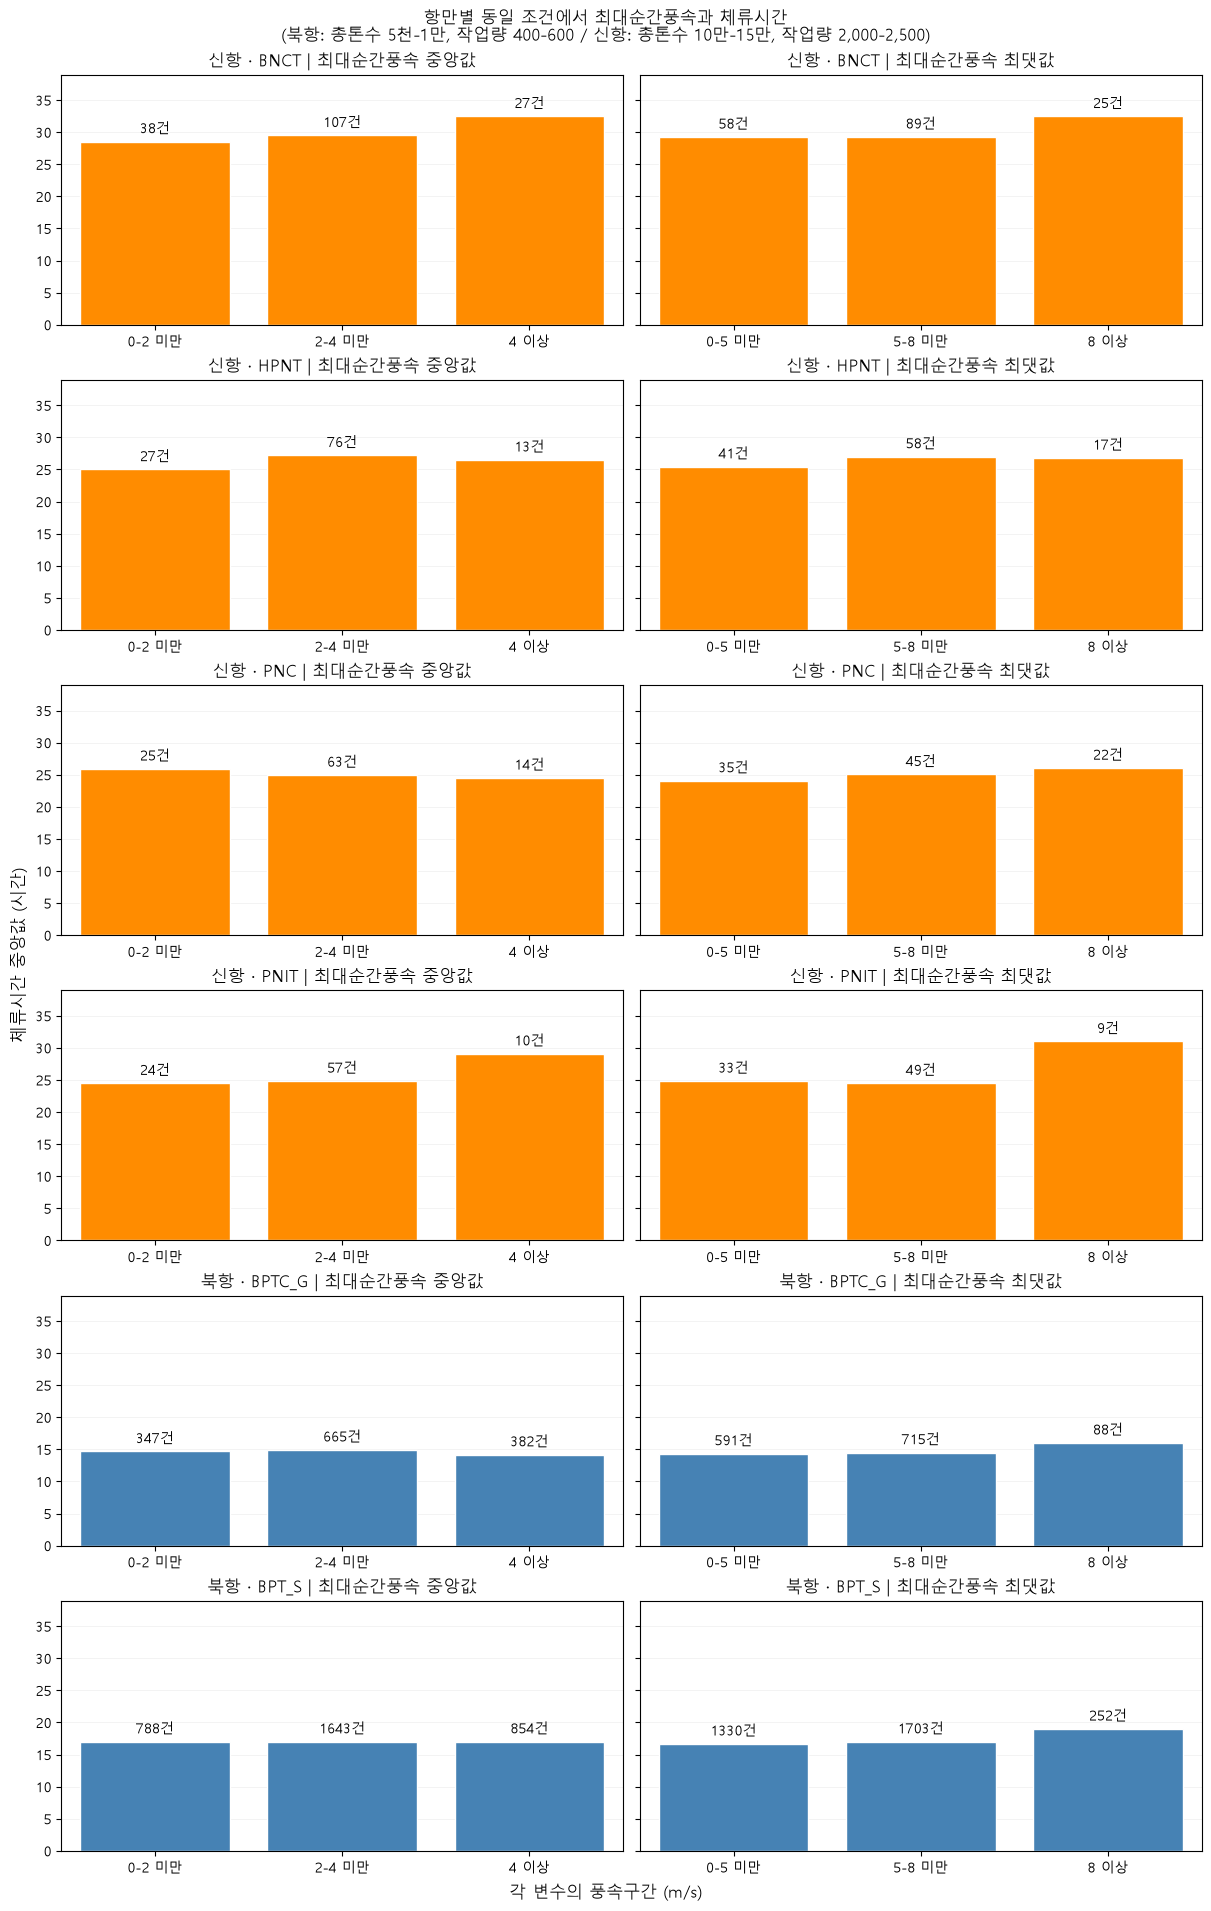

In [105]:
# 행은 터미널, 왼쪽은 최대순간풍속 중앙값, 오른쪽은 최댓값이다.
# 모든 그래프의 세로축을 통일하고 막대 위에 기록 수를 표시한다.
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]

fig, axes = plt.subplots(
    6, 2, figsize=(12, 19),
    sharey=True, layout="constrained",
)

for 행, 터미널 in enumerate(터미널목록):
    항만 = "북항" if 터미널 in ["BPTC_G", "BPT_S"] else "신항"
    색 = "steelblue" if 항만 == "북항" else "darkorange"

    for 열번호, (종류, 설정) in enumerate(돌풍설정.items()):
        ax = axes[행, 열번호]
        구간명 = 설정[2]
        x = np.arange(len(구간명))
        자료 = 돌풍결과[종류].xs(
            (항만, 터미널), level=("항만", "터미널")
        ).reindex(구간명)

        막대 = ax.bar(
            x, 자료["체류시간_중앙값"],
            color=색, edgecolor="white",
        )

        ax.bar_label(
            막대,
            labels=[
                f"{int(n)}건" if pd.notna(n) and n > 0 else ""
                for n in 자료["기록수"]
            ],
            padding=4,
        )

        ax.set_xticks(x, 구간명)
        ax.set_xlim(-0.5, len(구간명) - 0.5)
        ax.set_title(f"{항만} · {터미널} | 최대순간풍속 {종류}")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)

전체최대 = pd.concat(돌풍결과.values())["체류시간_중앙값"].max()
axes[0, 0].set_ylim(0, 전체최대 * 1.2)

fig.suptitle(
    "항만별 동일 조건에서 최대순간풍속과 체류시간\n"
    "(북항: 총톤수 5천-1만, 작업량 400-600 / 신항: 총톤수 10만-15만, 작업량 2,000-2,500)"
)
fig.supxlabel("각 변수의 풍속구간 (m/s)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- 최대순간풍속 최댓값이 8 m/s 이상인 구간에서 북항의 체류시간 중앙값은 BPTC_G 14.33 → 16.00시간(88건), BPT_S 16.67 → 19.00시간(252건)으로 증가했다.
- 신항도 0-5 미만 구간보다 8 m/s 이상 구간에서 BNCT 29.25 → 32.47시간(25건), HPNT 25.43 → 26.80시간(17건), PNC 24.07 → 26.04시간(22건), PNIT 24.83 → 31.00시간(9건)으로 네 터미널 모두 길었다.
- 최대순간풍속 중앙값 기준으로는 BNCT가 28.54 → 32.47시간(27건), PNIT가 24.48 → 29.08시간(10건)으로 4 m/s 이상 구간에서 길었다.
- 다만 체류가 길수록 강한 돌풍을 만날 가능성도 커지고 신항의 해당 구간은 기록이 적어, 이 결과만으로 돌풍이 체류를 늘렸다고 단정할 수는 없다.

In [106]:
# 항만별 동일 총톤수·작업량 조건에서 유의파고 중앙값·최댓값의 분포를 확인한다.
# 결측과 값이 집중된 범위를 확인한 뒤 비교 구간을 정한다.
파고열목록 = [
    "체류시간_유의파고_중앙값_m",
    "체류시간_유의파고_최댓값_m",
]

터미널인덱스 = pd.MultiIndex.from_tuples(터미널순서, names=["항만", "터미널"])

파고분포 = 후보전체.groupby(["항만", "터미널"])[파고열목록].agg(
    ["count", "min", lambda s: s.quantile(0.25), "median",
     lambda s: s.quantile(0.75), "max"]
).reindex(터미널인덱스)
파고분포.columns = pd.MultiIndex.from_product(
    [["중앙값", "최댓값"], ["유효건수", "최솟값", "25%", "중앙값", "75%", "최댓값"]]
)

display(파고분포.round(2))

# 두 변수의 결측 건수도 함께 확인한다.
display(
    후보전체.groupby(["항만", "터미널"])[파고열목록]
    .agg(lambda s: s.isna().sum())
    .reindex(터미널인덱스)
    .rename(columns=lambda 열: 열 + "_결측건수")
)

중앙값                               최댓값                           
           유효건수  최솟값   25%   중앙값  75%   최댓값  유효건수  최솟값  25%   중앙값   75%  최댓값
항만 터미널                                                                      
북항 BPTC_G  1435  0.1  0.35  0.50  0.7  2.20  1435  0.2  0.5  0.70  1.10  3.7
   BPT_S   3330  0.1  0.30  0.50  0.8  4.05  3333  0.2  0.5  0.70  1.20  4.7
신항 BNCT     176  0.1  0.30  0.30  0.5  1.50   176  0.2  0.4  0.60  0.82  2.1
   HPNT     116  0.1  0.30  0.30  0.5  0.90   116  0.2  0.4  0.55  0.80  1.7
   PNC      107  0.1  0.30  0.30  0.5  1.40   107  0.3  0.4  0.50  0.80  2.0
   PNIT      92  0.1  0.30  0.32  0.5  1.30    92  0.2  0.4  0.60  0.80  1.9

체류시간_유의파고_중앙값_m_결측건수  체류시간_유의파고_최댓값_m_결측건수
항만 터미널                                               
북항 BPTC_G                    43                    43
   BPT_S                     91                    88
신항 BNCT                       0                     0
   HPNT                       3                     3
   PNC                        1                     1
   PNIT                       1                     1

In [107]:
# 유의파고 중앙값과 최댓값을 같은 구간으로 나눠 체류시간을 비교한다.
# 구간은 탐색적 비교용이며 공식적인 위험 기준은 아니다.
파고설정 = {
    "중앙값": "체류시간_유의파고_중앙값_m",
    "최댓값": "체류시간_유의파고_최댓값_m",
}
파고순서 = ["0-0.5 미만", "0.5-1 미만", "1-2 미만", "2 이상"]
유의파고결과 = {}

for 종류, 열 in 파고설정.items():
    자료 = 후보전체.copy()
    자료["파고구간"] = pd.cut(
        자료[열],
        bins=[0, 0.5, 1, 2, float("inf")],
        labels=파고순서,
        right=False,
    )

    결과 = 자료.groupby(
        ["항만", "터미널", "파고구간"], observed=False
    ).agg(
        기록수=("체류시간", "count"),
        작업량_중앙값=("총작업량", "median"),
        총톤수_중앙값=("총톤수", "median"),
        체류시간_중앙값=("체류시간", "median"),
    )

    # 조합이 없는 항만·터미널 행은 표에서 제외한다.
    유의파고결과[종류] = 결과.loc[
        결과.index.droplevel("파고구간").isin(터미널순서)
    ]

    print(f"유의파고 {종류} 기준")
    display(유의파고결과[종류].round(2))

유의파고 중앙값 기준


기록수  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    파고구간                                       
북항 BPTC_G 0-0.5 미만   647    491.0    9587.0     14.50
          0.5-1 미만   580    490.5    9563.0     15.00
          1-2 미만     207    495.0    9587.0     14.67
          2 이상         1    440.0    9956.0     14.50
   BPT_S  0-0.5 미만  1480    500.5    9520.0     17.00
          0.5-1 미만  1317    505.0    9141.0     17.00
          1-2 미만     521    504.0    9520.0     17.33
          2 이상        12    547.5    7634.0     22.83
신항 BNCT   0-0.5 미만   119   2242.0  116295.0     29.57
          0.5-1 미만    51   2185.0  128600.0     29.68
          1-2 미만       6   2246.5  120240.5     28.42
          2 이상         0      NaN       NaN       NaN
   HPNT   0-0.5 미만    81   2265.0  115761.0     26.00
          0.5-1 미만    35   2298.0  114023.0     27.00
          1-2 미만       0      NaN       NaN       NaN
          2 이상         0      NaN       NaN       NaN
   PNC    0-0.5 미만    76   2177.0  114044.0     24.91
          0.5-1 미만    27   2240.0  115761.0     25.00
          1-2 미만       4   2352.0  127880.0     27.46
          2 이상         0      NaN       NaN       NaN
   PNIT   0-0.5 미만    63   2232.0  114044.0     24.83
          0.5-1 미만    26   2229.0  113042.0     24.58
          1-2 미만       3   2381.0  113976.0     28.00
          2 이상         0      NaN       NaN       NaN

유의파고 최댓값 기준


기록수  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    파고구간                                       
북항 BPTC_G 0-0.5 미만   267    488.0    9587.0     14.00
          0.5-1 미만   703    490.0    9587.0     14.67
          1-2 미만     393    498.0    9563.0     15.00
          2 이상        72    494.0    9555.5     16.00
   BPT_S  0-0.5 미만   588    495.0    9287.0     16.83
          0.5-1 미만  1590    504.0    9141.0     17.00
          1-2 미만     958    504.5    9520.0     17.00
          2 이상       197    521.0    9520.0     19.00
신항 BNCT   0-0.5 미만    59   2268.0  113735.0     29.80
          0.5-1 미만    85   2232.0  117340.0     29.42
          1-2 미만      30   2166.5  128929.0     28.65
          2 이상         2   2297.0  145554.5     29.75
   HPNT   0-0.5 미만    42   2229.5  115761.0     24.60
          0.5-1 미만    56   2298.5  114892.0     26.90
          1-2 미만      18   2300.5  118524.0     28.15
          2 이상         0      NaN       NaN       NaN
   PNC    0-0.5 미만    40   2183.5  113543.0     24.93
          0.5-1 미만    50   2251.0  114044.0     24.82
          1-2 미만      16   2208.5  114343.5     24.77
          2 이상         1   2470.0  141716.0     31.08
   PNIT   0-0.5 미만    32   2242.0  114343.5     24.21
          0.5-1 미만    49   2202.0  113828.0     25.00
          1-2 미만      11   2323.0  113976.0     28.00
          2 이상         0      NaN       NaN       NaN

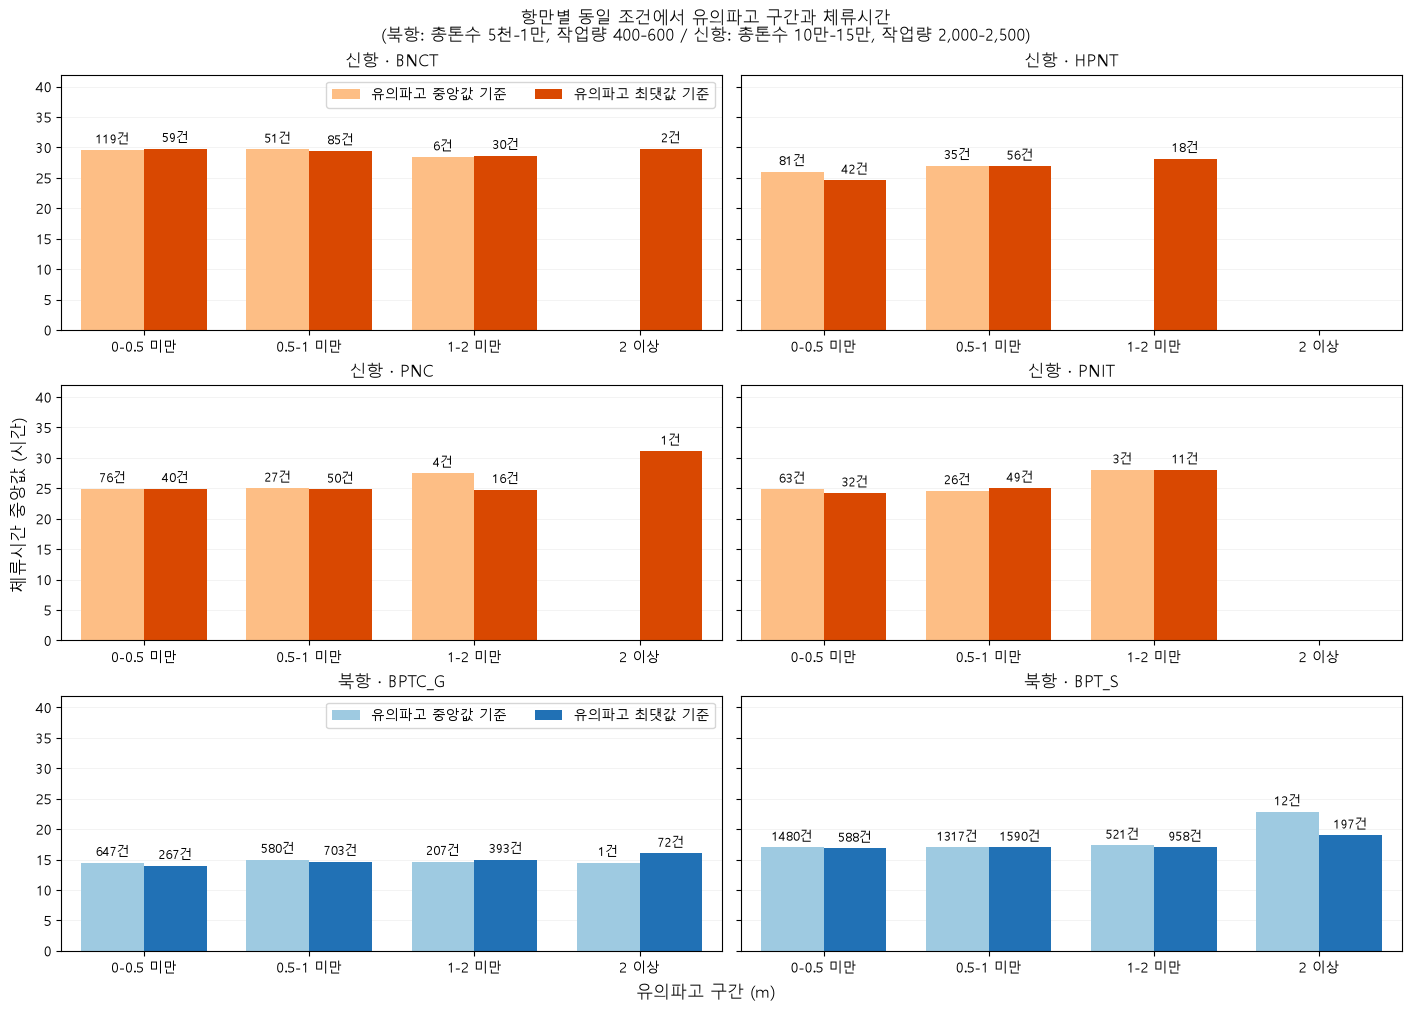

In [108]:
# 파고구간마다 유의파고 중앙값·최댓값 기준의 체류시간 중앙값을 나란히 비교한다.
# 막대 위 숫자는 각 기준에서 해당 구간에 속한 기록 수이다.
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]
x = np.arange(len(파고순서))
폭 = 0.38

fig, axes = plt.subplots(
    3, 2, figsize=(14, 10), sharey=True, layout="constrained"
)

for ax, 터미널 in zip(axes.flat, 터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    중앙색, 최대색 = (
        ("#9ECAE1", "#2171B5") if 북항 else ("#FDBE85", "#D94801")
    )

    for 종류, 색, 위치조정 in [
        ("중앙값", 중앙색, -폭 / 2),
        ("최댓값", 최대색, 폭 / 2),
    ]:
        자료 = 유의파고결과[종류].xs(
            (항만, 터미널), level=("항만", "터미널")
        ).reindex(파고순서)
        유효 = 자료["기록수"].gt(0).to_numpy()

        막대 = ax.bar(
            x[유효] + 위치조정, 자료.loc[유효, "체류시간_중앙값"],
            width=폭, color=색, label=f"유의파고 {종류} 기준",
        )
        ax.bar_label(
            막대,
            labels=[f"{int(n)}건" for n in 자료.loc[유효, "기록수"]],
            padding=3, fontsize=9,
        )

    ax.set_xticks(x, 파고순서)
    ax.set_xlim(-0.5, len(파고순서) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

전체최대 = pd.concat(유의파고결과.values())["체류시간_중앙값"].max()
axes[0, 0].set_ylim(0, 전체최대 * 1.35)
axes[0, 0].legend(loc="upper right", ncol=2)
axes[2, 0].legend(loc="upper right", ncol=2)

fig.suptitle(
    "항만별 동일 조건에서 유의파고 구간과 체류시간\n"
    "(북항: 총톤수 5천-1만, 작업량 400-600 / 신항: 총톤수 10만-15만, 작업량 2,000-2,500)"
)
fig.supxlabel("유의파고 구간 (m)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- 유의파고는 값이 대부분 1m 미만에 집중되어 중앙값과 최댓값 모두 0-0.5, 0.5-1, 1-2, 2 이상 구간으로 나눠 비교했다. 같은 구간의 두 막대는 각 기준으로 나눈 서로 다른 기록 집단이며, 막대 위 숫자는 기록 수다.

- 유의파고 최댓값 기준으로 북항의 체류시간 중앙값은 0-0.5 미만보다 2m 이상 구간에서 BPTC_G 14.00 → 16.00시간(72건), BPT_S 16.83 → 19.00시간(197건)으로 길었다.

- 신항은 유의파고 최댓값 기준으로 0-0.5 미만보다 1-2 미만 구간에서 HPNT 24.60 → 28.15시간(18건), PNIT 24.21 → 28.00시간(11건)으로 길었다.

- 유의파고 중앙값 기준으로는 BPT_S가 2m 이상 구간에서 17.00 → 22.83시간(12건)으로 증가했다. 다만 이 구간은 기록이 적고, 총톤수 중앙값이 7,634로 다른 구간(약 9,100-9,500)보다 작다.

- 체류가 길수록 높은 파고를 만날 가능성도 커지므로, 이 결과만으로 파고가 체류를 늘렸다고 단정할 수는 없다.

In [109]:
# 항만별 동일 총톤수·작업량 조건에서 순간최대파고 중앙값·최댓값의 분포를 확인한다.
# 결측과 값이 집중된 범위를 확인한 뒤 비교 구간을 정한다.
순간파고열목록 = [
    "체류시간_순간최대파고_중앙값_m",
    "체류시간_순간최대파고_최댓값_m",
]

순간파고분포 = 후보전체.groupby(["항만", "터미널"])[순간파고열목록].agg(
    ["count", "min", lambda s: s.quantile(0.25), "median",
     lambda s: s.quantile(0.75), "max"]
).reindex(터미널인덱스)
순간파고분포.columns = pd.MultiIndex.from_product(
    [["중앙값", "최댓값"], ["유효건수", "최솟값", "25%", "중앙값", "75%", "최댓값"]]
)

display(순간파고분포.round(2))

# 두 변수의 결측 건수도 함께 확인한다.
display(
    후보전체.groupby(["항만", "터미널"])[순간파고열목록]
    .agg(lambda s: s.isna().sum())
    .reindex(터미널인덱스)
    .rename(columns=lambda 열: 열 + "_결측건수")
)

중앙값                                최댓값                          
           유효건수   최솟값   25%   중앙값  75%   최댓값  유효건수  최솟값  25%   중앙값  75%  최댓값
항만 터미널                                                                      
북항 BPTC_G  1435  0.20  0.50  0.65  1.0  3.10  1435  0.2  0.7  1.00  1.5  5.1
   BPT_S   3330  0.20  0.50  0.65  1.0  5.75  3330  0.2  0.7  1.00  1.6  6.9
신항 BNCT     176  0.20  0.30  0.50  0.7  2.00   176  0.3  0.6  0.80  1.2  3.5
   HPNT     116  0.10  0.40  0.50  0.7  1.20   116  0.3  0.6  0.80  1.2  2.5
   PNC      107  0.20  0.38  0.50  0.7  1.80   107  0.4  0.6  0.80  1.1  2.8
   PNIT      92  0.15  0.38  0.50  0.7  1.70    92  0.3  0.5  0.85  1.2  3.2

체류시간_순간최대파고_중앙값_m_결측건수  체류시간_순간최대파고_최댓값_m_결측건수
항만 터미널                                                   
북항 BPTC_G                      43                      43
   BPT_S                       91                      91
신항 BNCT                         0                       0
   HPNT                         3                       3
   PNC                          1                       1
   PNIT                         1                       1

In [110]:
# 순간최대파고 중앙값과 최댓값을 같은 구간으로 나눠 체류시간을 비교한다.
# 구간은 탐색적 비교용이며 공식적인 위험 기준은 아니다.
순간파고설정 = {
    "중앙값": "체류시간_순간최대파고_중앙값_m",
    "최댓값": "체류시간_순간최대파고_최댓값_m",
}
순간파고순서 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]
순간파고결과 = {}

for 종류, 열 in 순간파고설정.items():
    자료 = 후보전체.copy()
    자료["파고구간"] = pd.cut(
        자료[열],
        bins=[0, 1, 2, 3, float("inf")],
        labels=순간파고순서,
        right=False,
    )

    결과 = 자료.groupby(
        ["항만", "터미널", "파고구간"], observed=False
    ).agg(
        기록수=("체류시간", "count"),
        작업량_중앙값=("총작업량", "median"),
        총톤수_중앙값=("총톤수", "median"),
        체류시간_중앙값=("체류시간", "median"),
    )

    # 조합이 없는 항만·터미널 행은 표에서 제외한다.
    순간파고결과[종류] = 결과.loc[
        결과.index.droplevel("파고구간").isin(터미널순서)
    ]

    print(f"순간최대파고 {종류} 기준")
    display(순간파고결과[종류].round(2))

순간최대파고 중앙값 기준


기록수  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    파고구간                                     
북항 BPTC_G 0-1 미만  1062    491.0    9587.0     14.54
          1-2 미만   329    494.0    9587.0     14.67
          2-3 미만    43    476.0    9191.0     15.00
          3 이상       1    440.0    9956.0     14.50
   BPT_S  0-1 미만  2390    502.0    9287.0     17.00
          1-2 미만   827    504.0    9520.0     17.00
          2-3 미만   107    506.0    9038.0     18.33
          3 이상       6    549.5    7589.5     22.83
신항 BNCT   0-1 미만   159   2232.0  116295.0     29.58
          1-2 미만    16   2165.0  131332.0     28.42
          2-3 미만     1   2423.0  141795.0     24.92
          3 이상       0      NaN       NaN       NaN
   HPNT   0-1 미만   102   2245.0  115761.0     26.40
          1-2 미만    14   2311.5  116273.5     27.40
          2-3 미만     0      NaN       NaN       NaN
          3 이상       0      NaN       NaN       NaN
   PNC    0-1 미만    92   2202.0  114044.0     24.91
          1-2 미만    15   2220.0  118523.0     25.00
          2-3 미만     0      NaN       NaN       NaN
          3 이상       0      NaN       NaN       NaN
   PNIT   0-1 미만    84   2232.0  114044.0     24.83
          1-2 미만     8   2340.5  113042.0     24.29
          2-3 미만     0      NaN       NaN       NaN
          3 이상       0      NaN       NaN       NaN

순간최대파고 최댓값 기준


기록수  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    파고구간                                     
북항 BPTC_G 0-1 미만   715    489.0    9587.0     14.33
          1-2 미만   520    491.0    9563.0     14.67
          2-3 미만   154    505.5    9587.0     15.33
          3 이상      46    485.5    9522.0     17.08
   BPT_S  0-1 미만  1556    498.0    9365.0     17.00
          1-2 미만  1252    507.0    9191.0     17.00
          2-3 미만   383    503.0    9520.0     17.33
          3 이상     139    526.0    8306.0     19.83
신항 BNCT   0-1 미만   109   2252.0  113735.0     29.62
          1-2 미만    52   2210.5  122970.0     29.41
          2-3 미만    13   2174.0  131332.0     26.72
          3 이상       2   2153.5  139121.5     31.08
   HPNT   0-1 미만    73   2267.0  115761.0     26.00
          1-2 미만    39   2236.0  115761.0     26.90
          2-3 미만     4   2382.5  127550.0     32.40
          3 이상       0      NaN       NaN       NaN
   PNC    0-1 미만    67   2180.0  114044.0     24.20
          1-2 미만    34   2231.0  114044.0     25.29
          2-3 미만     6   2250.5  127369.5     28.71
          3 이상       0      NaN       NaN       NaN
   PNIT   0-1 미만    53   2225.0  114044.0     24.80
          1-2 미만    34   2244.0  113042.0     24.92
          2-3 미만     4   2338.5  127476.0     24.75
          3 이상       1   2169.0  141649.0     29.40

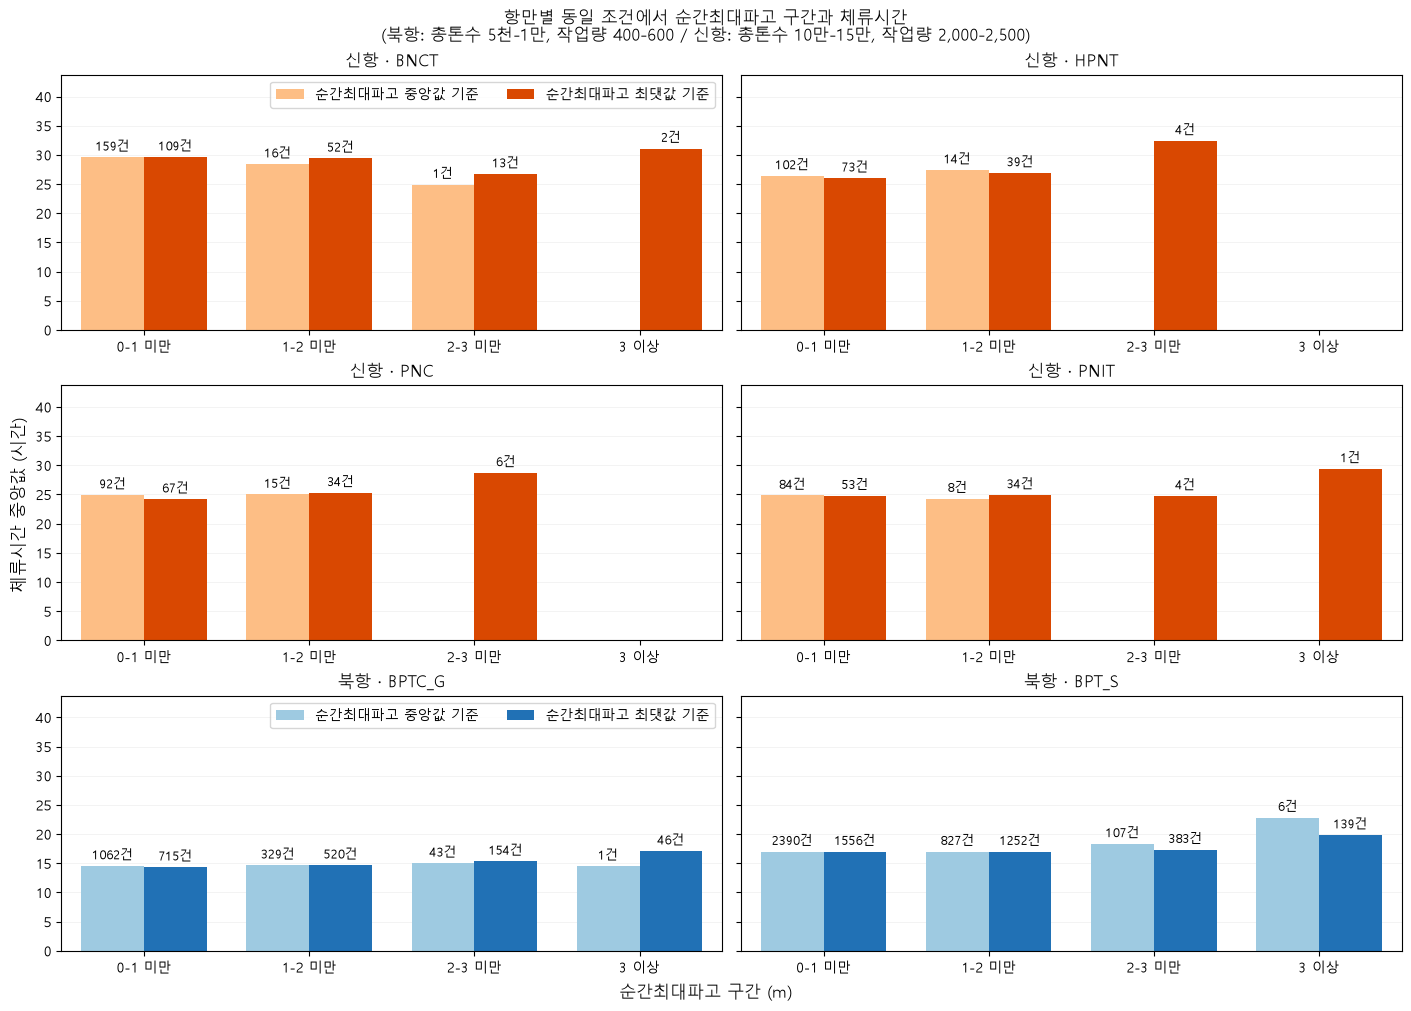

In [111]:
# 파고구간마다 순간최대파고 중앙값·최댓값 기준의 체류시간 중앙값을 나란히 비교한다.
# 막대 위 숫자는 각 기준에서 해당 구간에 속한 기록 수이다.
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]
x = np.arange(len(순간파고순서))
폭 = 0.38

fig, axes = plt.subplots(
    3, 2, figsize=(14, 10), sharey=True, layout="constrained"
)

for ax, 터미널 in zip(axes.flat, 터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    중앙색, 최대색 = (
        ("#9ECAE1", "#2171B5") if 북항 else ("#FDBE85", "#D94801")
    )

    for 종류, 색, 위치조정 in [
        ("중앙값", 중앙색, -폭 / 2),
        ("최댓값", 최대색, 폭 / 2),
    ]:
        자료 = 순간파고결과[종류].xs(
            (항만, 터미널), level=("항만", "터미널")
        ).reindex(순간파고순서)
        유효 = 자료["기록수"].gt(0).to_numpy()

        막대 = ax.bar(
            x[유효] + 위치조정, 자료.loc[유효, "체류시간_중앙값"],
            width=폭, color=색, label=f"순간최대파고 {종류} 기준",
        )
        ax.bar_label(
            막대,
            labels=[f"{int(n)}건" for n in 자료.loc[유효, "기록수"]],
            padding=3, fontsize=9,
        )

    ax.set_xticks(x, 순간파고순서)
    ax.set_xlim(-0.5, len(순간파고순서) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

전체최대 = pd.concat(순간파고결과.values())["체류시간_중앙값"].max()
axes[0, 0].set_ylim(0, 전체최대 * 1.35)
axes[0, 0].legend(loc="upper right", ncol=2)
axes[2, 0].legend(loc="upper right", ncol=2)

fig.suptitle(
    "항만별 동일 조건에서 순간최대파고 구간과 체류시간\n"
    "(북항: 총톤수 5천-1만, 작업량 400-600 / 신항: 총톤수 10만-15만, 작업량 2,000-2,500)"
)
fig.supxlabel("순간최대파고 구간 (m)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- 순간최대파고는 최댓값의 분포가 넓어 중앙값과 최댓값 모두 0-1, 1-2, 2-3, 3 이상 구간으로 나눠 비교했다. 같은 구간의 두 막대는 각 기준으로 나눈 서로 다른 기록 집단이며, 막대 위 숫자는 기록 수다.

- 순간최대파고 최댓값 기준으로 북항의 체류시간 중앙값은 0-1 미만보다 3m 이상 구간에서 BPTC_G 14.33 → 17.08시간(46건), BPT_S 17.00 → 19.83시간(139건)으로 길었다.

- 순간최대파고 중앙값 기준으로는 BPT_S가 2-3 미만 구간에서 17.00 → 18.33시간(107건)으로 증가했다.

- 신항은 순간최대파고 최댓값 기준으로 PNC가 24.20 → 25.29시간(1-2 미만, 34건), 28.71시간(2-3 미만, 6건)으로 늘었고, HPNT도 2-3 미만 구간에서 26.00 → 32.40시간(4건)으로 길었다. 다만 해당 구간은 기록이 적고 총톤수 중앙값이 약 127,000으로 다른 구간(약 114,000-116,000)보다 크다.

- 체류가 길수록 높은 파고를 만날 가능성도 커지므로, 이 결과만으로 파고가 체류를 늘렸다고 단정할 수는 없다.

In [112]:
# 항만별 동일 총톤수·작업량 조건에서 시정 중앙값·최솟값의 분포를 확인한다.
# 시정 단위는 원자료의 10m이며, 쉼표가 포함된 문자열을 숫자로 바꿔 사용한다.
시정열목록 = [
    "체류시간_시정_중앙값_10m",
    "체류시간_시정_최솟값_10m",
]

시정자료 = 후보전체.copy()

for 열 in 시정열목록:
    시정자료[열] = pd.to_numeric(
        시정자료[열].astype("string").str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )

시정분포 = 시정자료.groupby(["항만", "터미널"])[시정열목록].agg(
    ["count", "min", lambda s: s.quantile(0.25), "median",
     lambda s: s.quantile(0.75), "max"]
).reindex(터미널인덱스)
시정분포.columns = pd.MultiIndex.from_product(
    [["중앙값", "최솟값"], ["유효건수", "최솟값", "25%", "중앙값", "75%", "최댓값"]]
)

display(시정분포.round(1))

# 두 변수의 결측 건수도 함께 확인한다.
display(
    시정자료.groupby(["항만", "터미널"])[시정열목록]
    .agg(lambda s: s.isna().sum())
    .reindex(터미널인덱스)
    .rename(columns=lambda 열: 열 + "_결측건수")
)

중앙값                                          최솟값                \
           유효건수    최솟값     25%     중앙값     75%     최댓값  유효건수   최솟값     25%   
항만 터미널                                                                       
북항 BPTC_G  1476  139.0  2408.4  4104.8  5000.0  5000.0  1476  14.0  1038.2   
   BPT_S   3415  127.0  2316.5  3936.0  5000.0  5000.0  3415  14.0   884.0   
신항 BNCT     176  413.0  2970.9  4575.2  5000.0  5000.0   176  26.0   866.2   
   HPNT     119  253.0  2355.5  3448.0  5000.0  5000.0   119  21.0   620.0   
   PNC      108  263.0  2605.1  4491.5  5000.0  5000.0   108  30.0   875.5   
   PNIT      93  243.0  2454.0  3976.5  5000.0  5000.0    93  36.0   690.0   

                                   
              중앙값     75%     최댓값  
항만 터미널                             
북항 BPTC_G  2264.0  3986.0  5000.0  
   BPT_S   1981.0  3578.0  5000.0  
신항 BNCT    1871.0  3237.8  5000.0  
   HPNT    1318.0  2711.5  5000.0  
   PNC     2269.5  3832.8  5000.0  
   PNIT    1593.0  2678.0  5000.0

체류시간_시정_중앙값_10m_결측건수  체류시간_시정_최솟값_10m_결측건수
항만 터미널                                               
북항 BPTC_G                     2                     2
   BPT_S                      6                     6
신항 BNCT                       0                     0
   HPNT                       0                     0
   PNC                        0                     0
   PNIT                       0                     0

In [113]:
# 시정 중앙값과 최솟값을 같은 구간으로 나눠 체류시간을 비교한다.
# 오른쪽 구간일수록 시정이 낮으며, 구간은 탐색적 비교용으로 공식 기준은 아니다.
시정설정 = {
    "중앙값": "체류시간_시정_중앙값_10m",
    "최솟값": "체류시간_시정_최솟값_10m",
}
시정순서 = ["3,000 이상", "1,000-3,000 미만", "500-1,000 미만", "0-500 미만"]
시정결과 = {}

for 종류, 열 in 시정설정.items():
    자료 = 시정자료.copy()
    자료["시정구간"] = pd.cut(
        자료[열],
        bins=[0, 500, 1000, 3000, float("inf")],
        labels=시정순서[::-1],
        right=False,
    )

    결과 = 자료.groupby(
        ["항만", "터미널", "시정구간"], observed=False
    ).agg(
        기록수=("체류시간", "count"),
        작업량_중앙값=("총작업량", "median"),
        총톤수_중앙값=("총톤수", "median"),
        체류시간_중앙값=("체류시간", "median"),
    )

    # 조합이 없는 항만·터미널 행은 표에서 제외한다.
    시정결과[종류] = 결과.loc[
        결과.index.droplevel("시정구간").isin(터미널순서)
    ].reindex(시정순서, level="시정구간")

    print(f"시정 {종류} 기준")
    display(시정결과[종류].round(2))

시정 중앙값 기준


기록수  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    시정구간                                             
북항 BPTC_G 3,000 이상         960    490.0    9567.0     14.67
          1,000-3,000 미만   428    494.0    9587.0     14.50
          500-1,000 미만      55    492.0    9524.0     14.00
          0-500 미만          33    514.0    9531.0     15.00
   BPT_S  3,000 이상        2161    504.0    9520.0     17.00
          1,000-3,000 미만  1029    501.0    9287.0     17.00
          500-1,000 미만     161    512.0    9520.0     17.67
          0-500 미만          64    496.5    9162.5     15.33
신항 BNCT   3,000 이상         130   2232.5  113735.0     29.62
          1,000-3,000 미만    38   2222.5  128600.0     28.48
          500-1,000 미만       6   2236.0  134594.0     27.77
          0-500 미만           2   2085.0  121332.0     25.99
   HPNT   3,000 이상          73   2236.0  114023.0     26.70
          1,000-3,000 미만    40   2285.0  118524.0     26.10
          500-1,000 미만       5   2369.0  113042.0     27.70
          0-500 미만           1   2381.0  143262.0     25.00
   PNC    3,000 이상          77   2235.0  114044.0     24.95
          1,000-3,000 미만    26   2152.5  113543.0     24.08
          500-1,000 미만       3   2127.0  109534.0     26.72
          0-500 미만           2   2093.0  127525.0     23.08
   PNIT   3,000 이상          60   2240.0  114010.0     24.78
          1,000-3,000 미만    26   2211.5  113042.0     25.17
          500-1,000 미만       6   2199.5  139548.5     25.17
          0-500 미만           1   2319.0  113042.0     20.00

시정 최솟값 기준


기록수  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    시정구간                                             
북항 BPTC_G 3,000 이상         547    487.0    9531.0     14.50
          1,000-3,000 미만   578    491.0    9587.0     14.33
          500-1,000 미만     153    497.0    9587.0     15.00
          0-500 미만         198    505.0    9587.0     15.21
   BPT_S  3,000 이상        1102    503.5    9141.0     17.00
          1,000-3,000 미만  1399    503.0    9520.0     17.00
          500-1,000 미만     398    496.5    9520.0     17.00
          0-500 미만         516    509.5    9287.0     17.67
신항 BNCT   3,000 이상          49   2231.0  128600.0     29.27
          1,000-3,000 미만    77   2232.0  113735.0     29.53
          500-1,000 미만      23   2316.0  131332.0     29.60
          0-500 미만          27   2174.0  128600.0     30.33
   HPNT   3,000 이상          25   2192.0  115761.0     25.90
          1,000-3,000 미만    51   2222.0  115761.0     26.00
          500-1,000 미만      15   2267.0  118523.0     27.00
          0-500 미만          28   2348.5  117142.0     27.37
   PNC    3,000 이상          42   2184.5  114044.0     24.95
          1,000-3,000 미만    36   2242.0  114044.0     24.34
          500-1,000 미만      16   2238.0  120284.5     26.22
          0-500 미만          14   2135.0  114008.5     25.46
   PNIT   3,000 이상          19   2309.0  140096.0     24.50
          1,000-3,000 미만    43   2225.0  113509.0     24.83
          500-1,000 미만       9   2224.0  113042.0     25.17
          0-500 미만          22   2239.0  114044.0     28.50

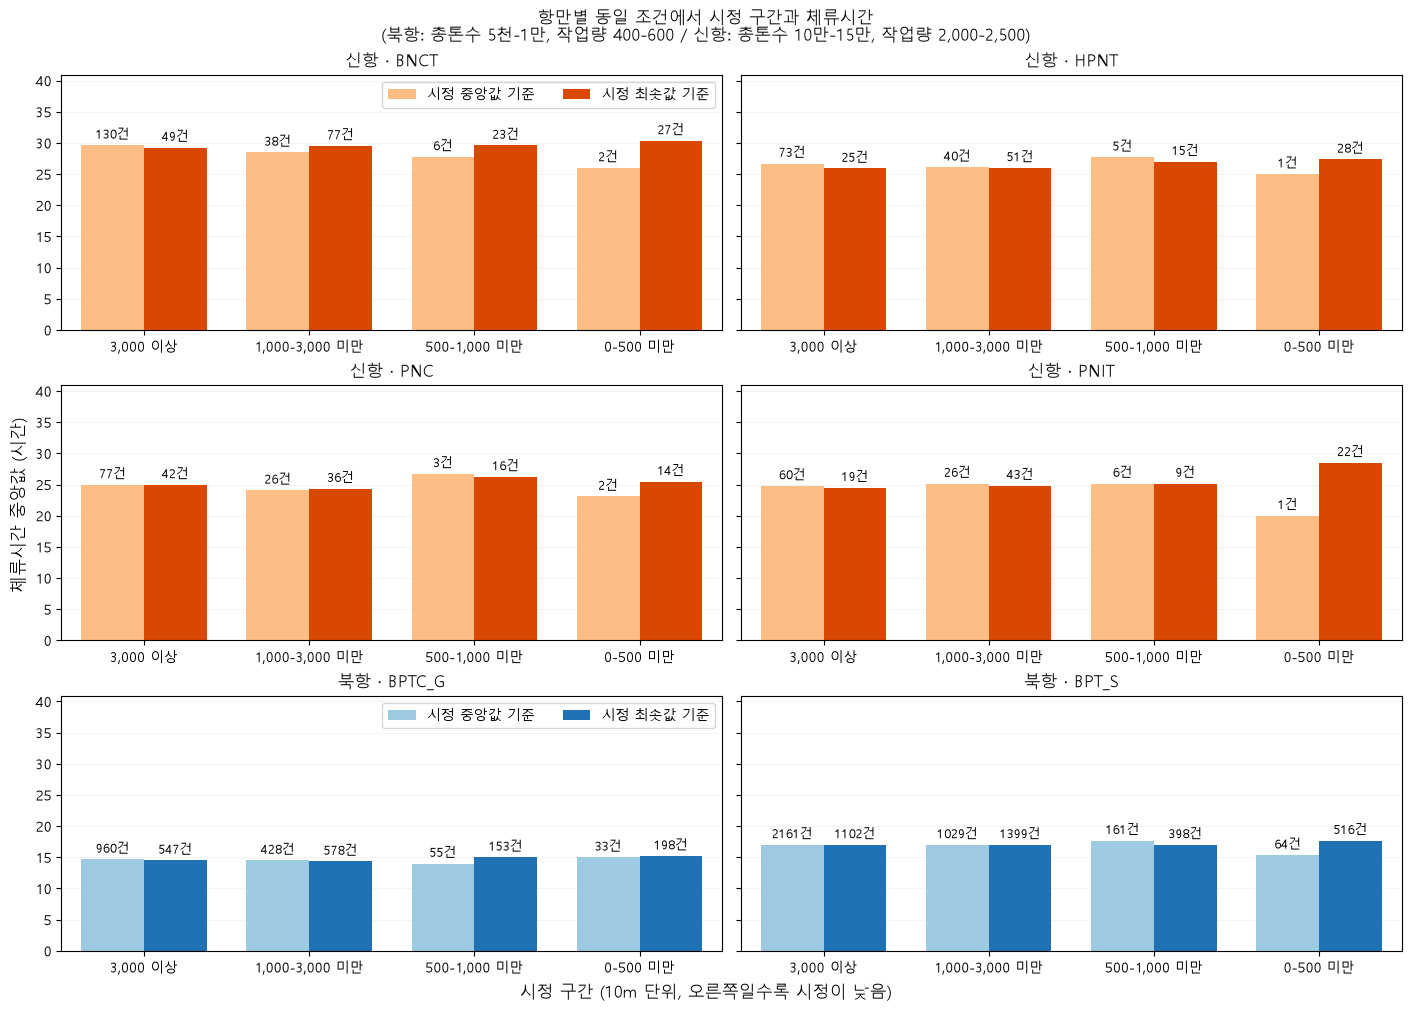

In [114]:
# 시정구간마다 시정 중앙값·최솟값 기준의 체류시간 중앙값을 나란히 비교한다.
# 오른쪽 구간일수록 시정이 낮고, 막대 위 숫자는 각 기준의 기록 수이다.
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]
x = np.arange(len(시정순서))
폭 = 0.38

fig, axes = plt.subplots(
    3, 2, figsize=(14, 10), sharey=True, layout="constrained"
)

for ax, 터미널 in zip(axes.flat, 터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"
    중앙색, 최소색 = (
        ("#9ECAE1", "#2171B5") if 북항
        else ("#FDBE85", "#D94801")
    )

    for 종류, 색, 위치조정 in [
        ("중앙값", 중앙색, -폭 / 2),
        ("최솟값", 최소색, 폭 / 2),
    ]:
        자료 = 시정결과[종류].xs(
            (항만, 터미널), level=("항만", "터미널")
        ).reindex(시정순서)
        유효 = 자료["기록수"].gt(0).to_numpy()

        막대 = ax.bar(
            x[유효] + 위치조정, 자료.loc[유효, "체류시간_중앙값"],
            width=폭, color=색, label=f"시정 {종류} 기준",
        )
        ax.bar_label(
            막대,
            labels=[f"{int(n)}건" for n in 자료.loc[유효, "기록수"]],
            padding=3, fontsize=9,
        )

    ax.set_xticks(x, 시정순서)
    ax.set_xlim(-0.5, len(시정순서) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

전체최대 = pd.concat(시정결과.values())["체류시간_중앙값"].max()
axes[0, 0].set_ylim(0, 전체최대 * 1.35)
axes[0, 0].legend(loc="upper right", ncol=2)
axes[2, 0].legend(loc="upper right", ncol=2)

fig.suptitle(
    "항만별 동일 조건에서 시정 구간과 체류시간\n"
    "(북항: 총톤수 5천-1만, 작업량 400-600 / 신항: 총톤수 10만-15만, 작업량 2,000-2,500)"
)
fig.supxlabel("시정 구간 (10m 단위, 오른쪽일수록 시정이 낮음)")
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- 시정은 중앙값의 약 30%가 상한값 5,000에 몰려 있어, 중앙값과 최솟값 모두 3,000 이상, 1,000-3,000, 500-1,000, 0-500 구간(10m 단위)으로 나눠 비교했다. 같은 구간의 두 막대는 각 기준으로 나눈 서로 다른 기록 집단이며, 막대 위 숫자는 기록 수다.

- 시정 최솟값이 0-500 미만인 구간에서 신항의 체류시간 중앙값은 3,000 이상 구간보다 PNIT 24.50 → 28.50시간(22건), HPNT 25.90 → 27.37시간(28건), BNCT 29.27 → 30.33시간(27건)으로 길었다.

- 북항은 같은 구간에서 BPTC_G 14.50 → 15.21시간(198건), BPT_S 17.00 → 17.67시간(516건)으로 증가했으며, 증가폭은 1시간 미만이었다.

- 체류가 길수록 낮은 시정을 겪을 가능성도 커지므로, 이 결과만으로 시정이 체류를 늘렸다고 단정할 수는 없다.

In [115]:
# 항만별 동일 총톤수·작업량 조건에서 특보 노출 여부에 따른 체류시간을 비교한다.
# 결측과 음수는 제외하고, 0시간은 특보 없음, 0시간 초과는 특보 있음으로 구분한다.
특보열 = "체류시간_특보노출시간"
특보구분순서 = ["특보 없음", "특보 있음"]

특보자료 = 후보전체.copy()
특보자료[특보열] = pd.to_numeric(특보자료[특보열], errors="coerce")
특보자료 = 특보자료.loc[특보자료[특보열].ge(0)].copy()
특보자료["특보여부"] = np.where(
    특보자료[특보열].gt(0), "특보 있음", "특보 없음"
)

특보인덱스 = pd.MultiIndex.from_tuples(
    [
        (항만, 터미널, 구분)
        for 항만, 터미널 in 터미널순서
        for 구분 in 특보구분순서
    ],
    names=["항만", "터미널", "특보여부"],
)

특보결과 = 특보자료.groupby(["항만", "터미널", "특보여부"]).agg(
    기록수=("체류시간", "count"),
    특보노출시간_중앙값=(특보열, "median"),
    작업량_중앙값=("총작업량", "median"),
    총톤수_중앙값=("총톤수", "median"),
    체류시간_중앙값=("체류시간", "median"),
).reindex(특보인덱스)

특보결과["기록수"] = 특보결과["기록수"].fillna(0).astype(int)
display(특보결과.round(2))

기록수  특보노출시간_중앙값  작업량_중앙값   총톤수_중앙값  체류시간_중앙값
항만 터미널    특보여부                                                
북항 BPTC_G 특보 없음  1284        0.00    491.0    9587.0     14.50
          특보 있음   194       10.00    494.0    9549.0     15.00
   BPT_S  특보 없음  2962        0.00    502.0    9287.0     17.00
          특보 있음   459       11.33    511.0    9520.0     18.50
신항 BNCT   특보 없음   144        0.00   2232.0  122447.5     29.48
          특보 있음    32       14.00   2187.5  128600.0     30.79
   HPNT   특보 없음   103        0.00   2265.0  115761.0     26.20
          특보 있음    16       11.35   2297.0  114892.0     28.05
   PNC    특보 없음    88        0.00   2218.0  114044.0     24.82
          특보 있음    20       14.33   2208.5  127928.5     25.62
   PNIT   특보 없음    79        0.00   2232.0  114044.0     24.83
          특보 있음    14       12.75   2316.0  113042.0     26.33

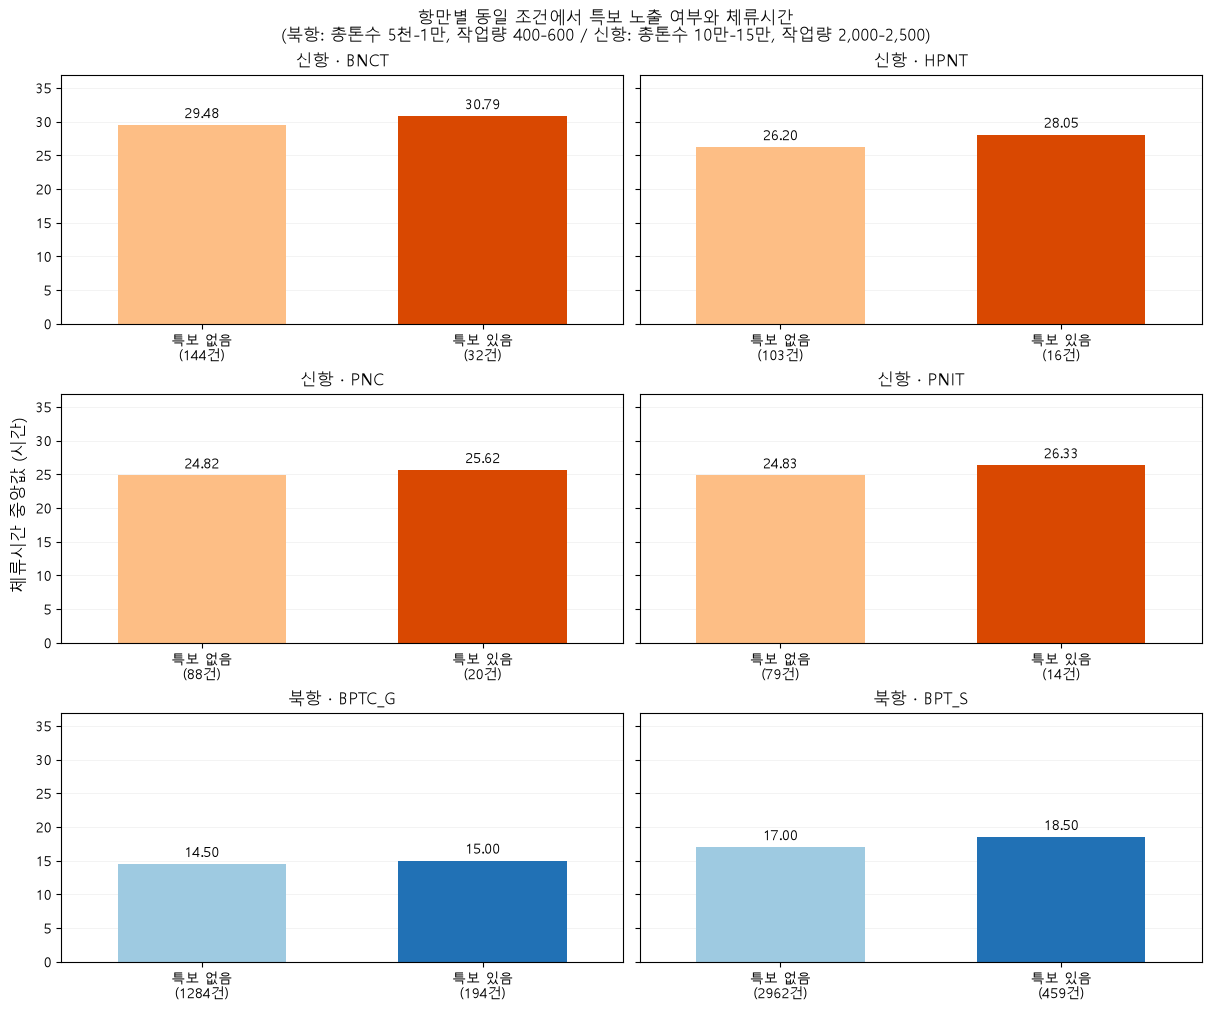

In [116]:
# 특보 노출 여부에 따른 체류시간을 터미널별로 비교한다.
터미널목록 = ["BNCT", "HPNT", "PNC", "PNIT", "BPTC_G", "BPT_S"]
위치 = np.arange(len(특보구분순서))

fig, axes = plt.subplots(
    3, 2, figsize=(12, 10), sharey=True, layout="constrained"
)

for ax, 터미널 in zip(axes.flat, 터미널목록):
    북항 = 터미널 in ["BPTC_G", "BPT_S"]
    항만 = "북항" if 북항 else "신항"

    자료 = 특보결과.xs(
        (항만, 터미널), level=("항만", "터미널")
    ).reindex(특보구분순서)
    건수 = 자료["기록수"].to_numpy()
    유효 = 건수 > 0

    막대 = ax.bar(
        위치[유효],
        자료.loc[유효, "체류시간_중앙값"].to_numpy(dtype=float),
        width=0.6,
        color=["#9ECAE1", "#2171B5"] if 북항 else ["#FDBE85", "#D94801"],
    )
    ax.bar_label(막대, fmt="%.2f", padding=3)

    ax.set_xticks(
        위치, [f"{구분}\n({n}건)" for 구분, n in zip(특보구분순서, 건수)]
    )
    ax.set_xlim(-0.5, len(위치) - 0.5)
    ax.set_title(f"{항만} · {터미널}")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

최대시간 = 특보결과["체류시간_중앙값"].max()
axes[0, 0].set_ylim(0, 최대시간 * 1.2)

fig.suptitle(
    "항만별 동일 조건에서 특보 노출 여부와 체류시간\n"
    "(북항: 총톤수 5천-1만, 작업량 400-600 / 신항: 총톤수 10만-15만, 작업량 2,000-2,500)"
)
fig.supylabel("체류시간 중앙값 (시간)")
그림표시()

- 항만별 동일 조건에서 특보노출시간이 0시간인 기록과 0시간을 초과한 기록의 체류시간을 비교했다.

- 특보 노출 기록의 체류시간 중앙값은 미노출 기록보다 HPNT 26.20 → 28.05시간(16건), BPT_S 17.00 → 18.50시간(459건), PNIT 24.83 → 26.33시간(14건), BNCT 29.48 → 30.79시간(32건)으로 1시간 이상 길었다.

최대순간풍속 최댓값과 유의파고 최댓값 동시에 고려하여 분석 (북항, 신항 기준으로)

In [117]:
# 조합별 기록 수
# 최대순간풍속 최댓값과 유의파고 최댓값의 구간을 교차해 기록 수를 확인한다.
복합돌풍열 = "체류시간_최대순간풍속_최댓값_mps"
복합파고열 = "체류시간_유의파고_최댓값_m"

복합돌풍순서 = ["0-5 미만", "5-8 미만", "8 이상"]
복합파고순서 = ["0-1 미만", "1-2 미만", "2-3 미만", "3 이상"]

행순서 = pd.MultiIndex.from_tuples(
    [
        (항만, 터미널, 돌풍)
        for 항만, 터미널 in 터미널순서
        for 돌풍 in 복합돌풍순서
    ],
    names=["항만", "터미널", "돌풍구간"],
)

복합기상자료 = 후보전체.dropna(subset=[복합돌풍열, 복합파고열]).copy()

복합기상자료["돌풍구간"] = pd.cut(
    복합기상자료[복합돌풍열],
    bins=[0, 5, 8, float("inf")],
    labels=복합돌풍순서,
    right=False,
)
복합기상자료["파고구간"] = pd.cut(
    복합기상자료[복합파고열],
    bins=[0, 1, 2, 3, float("inf")],
    labels=복합파고순서,
    right=False,
)

건수표 = (
    복합기상자료.groupby(["항만", "터미널", "돌풍구간", "파고구간"], observed=True)
    .size()
    .unstack("파고구간")
    .reindex(index=행순서, columns=복합파고순서)
    .fillna(0)
    .astype(int)
)

print("최대순간풍속(m/s) × 유의파고(m) 기록 수")
display(건수표)

최대순간풍속(m/s) × 유의파고(m) 기록 수


파고구간              0-1 미만  1-2 미만  2-3 미만  3 이상
항만 터미널    돌풍구간                                
북항 BPTC_G 0-5 미만     402     164      15     0
          5-8 미만     462     190      37     0
          8 이상        39      30      15     0
   BPT_S  0-5 미만     893     372      32     0
          5-8 미만    1060     482     112     8
          8 이상       109      96      35     6
신항 BNCT   0-5 미만      52       6       0     0
          5-8 미만      73      15       1     0
          8 이상        16       9       0     0
   HPNT   0-5 미만      36       4       0     0
          5-8 미만      46      11       0     0
          8 이상        14       2       0     0
   PNC    0-5 미만      32       3       0     0
          5-8 미만      39       5       1     0
          8 이상        14       7       0     0
   PNIT   0-5 미만      30       3       0     0
          5-8 미만      44       4       0     0
          8 이상         5       4       0     0

In [118]:
# 조합별 체류시간
# 셀마다 체류시간 중앙값과 기록 수를 표시한다.
복합기상결과 = 복합기상자료.groupby(
    ["항만", "터미널", "돌풍구간", "파고구간"], observed=True
)["체류시간"].agg(기록수="count", 체류시간_중앙값="median")

시간표 = (
    복합기상결과["체류시간_중앙값"].unstack("파고구간")
    .reindex(index=행순서, columns=복합파고순서)
)

표시표 = 시간표.map(lambda 값: f"{값:.2f}h" if pd.notna(값) else "")
표시표 = 표시표 + " (" + 건수표.astype(str) + "건)"
표시표 = 표시표.mask(건수표.eq(0), "0건")

print("체류시간 중앙값 (기록 수)")
display(표시표)

체류시간 중앙값 (기록 수)


파고구간                      0-1 미만         1-2 미만         2-3 미만         3 이상
항만 터미널    돌풍구간                                                             
북항 BPTC_G 0-5 미만   14.33h (402건)  14.58h (164건)   14.67h (15건)           0건
          5-8 미만   14.33h (462건)  14.75h (190건)   15.00h (37건)           0건
          8 이상      15.00h (39건)   16.00h (30건)   23.50h (15건)           0건
   BPT_S  0-5 미만   16.50h (893건)  17.00h (372건)   18.00h (32건)           0건
          5-8 미만  17.00h (1060건)  17.00h (482건)  18.00h (112건)  17.50h (8건)
          8 이상     18.50h (109건)   18.25h (96건)   23.17h (35건)  19.00h (6건)
신항 BNCT   0-5 미만    29.48h (52건)    26.61h (6건)             0건           0건
          5-8 미만    29.42h (73건)   28.42h (15건)    24.92h (1건)           0건
          8 이상      32.79h (16건)    31.42h (9건)             0건           0건
   HPNT   0-5 미만    25.85h (36건)    23.85h (4건)             0건           0건
          5-8 미만    26.90h (46건)   28.00h (11건)             0건           0건
          8 이상      26.65h (14건)    35.65h (2건)             0건           0건
   PNC    0-5 미만    23.98h (32건)    26.33h (3건)             0건           0건
          5-8 미만    25.05h (39건)    22.48h (5건)    31.08h (1건)           0건
          8 이상      26.40h (14건)    25.00h (7건)             0건           0건
   PNIT   0-5 미만    24.83h (30건)    21.50h (3건)             0건           0건
          5-8 미만    24.33h (44건)    22.62h (4건)             0건           0건
          8 이상       32.00h (5건)    29.07h (4건)             0건           0건

In [119]:
# 돌풍과 파고가 함께 높은 기록 확인
# 돌풍 8m/s 이상·유의파고 2m 이상이 함께 나타난 입항 기록을 확인한다.
# 체류 기간이 겹치는 기록은 같은 기상 사례로 묶어, 한 사례가 여러 건으로 세어지는 정도를 본다.
높은기상기록 = 복합기상자료.loc[
    복합기상자료["돌풍구간"].eq("8 이상")
    & 복합기상자료["파고구간"].isin(["2-3 미만", "3 이상"])
].sort_values("접안일시").copy()

이전출항 = 높은기상기록["출항일시"].cummax().shift()
높은기상기록["기상사례"] = (
    높은기상기록["접안일시"].gt(이전출항).cumsum() + 1
)

사례요약 = 높은기상기록.groupby("기상사례").agg(
    시작=("접안일시", "min"),
    종료=("출항일시", "max"),
    기록수=("체류시간", "size"),
    BPTC_G건수=("터미널", lambda s: s.eq("BPTC_G").sum()),
    BPT_S건수=("터미널", lambda s: s.eq("BPT_S").sum()),
    체류시간_중앙값=("체류시간", "median"),
    돌풍_최댓값=(복합돌풍열, "max"),
    파고_최댓값=(복합파고열, "max"),
    특보노출_중앙값=("체류시간_특보노출시간", "median"),
)

print(f"기록 {len(높은기상기록)}건, 기상 사례 {len(사례요약)}개")
표시용사례요약 = 사례요약.copy()
숫자열 = 표시용사례요약.select_dtypes(include="number").columns
표시용사례요약[숫자열] = 표시용사례요약[숫자열].round(2)
display(표시용사례요약)

기록 56건, 기상 사례 18개


,시작,종료,기록수,BPTC_G건수,BPT_S건수,체류시간_중앙값,돌풍_최댓값,파고_최댓값,특보노출_중앙값
기상사례,,,,,,,,,
1,2021-03-27 08:00:00,2021-03-29 03:00:00,3,1,2,23.00,10.96,2.0,13.00
2,2021-04-01 03:20:00,2021-04-02 03:00:00,3,0,3,17.67,9.03,3.2,13.67
3,2021-08-20 23:10:00,2021-08-22 21:00:00,5,1,4,27.00,10.71,2.4,17.00
4,2021-08-23 00:30:00,2021-08-25 12:00:00,6,2,4,51.50,14.92,2.1,33.00
5,2021-09-14 19:20:00,2021-09-15 23:00:00,2,1,1,18.83,8.82,2.1,4.75
6,2022-03-18 02:00:00,2022-03-18 23:00:00,1,0,1,21.00,9.41,3.2,21.00
7,2022-03-25 11:20:00,2022-03-27 01:00:00,3,1,2,18.67,9.55,3.0,14.58
8,2022-06-23 14:00:00,2022-06-24 23:59:00,2,2,0,29.99,11.19,2.4,24.49
9,2022-09-13 01:00:00,2022-09-15 06:00:00,5,3,2,18.00,8.42,2.4,12.00


- 최대순간풍속과 유의파고를 함께 보기 위해 항만별 동일 조건에서 최대순간풍속 최댓값(0-5, 5-8, 8 이상)과 유의파고 최댓값(0-1, 1-2, 2-3, 3 이상)을 교차했다.

- 북항은 최대순간풍속 8m/s 이상·유의파고 2-3m 미만 조합에서 체류시간 중앙값이 가장 길었다. 두 값이 모두 낮은 구간과 비교해 BPTC_G는 14.33 → 23.50시간(15건), BPT_S는 16.50 → 23.17시간(35건)이었다.

- 하나만 높을 때는 증가폭이 작았다. 최대순간풍속만 8m/s 이상이면 BPTC_G 15.00시간(39건), BPT_S 18.50시간(109건), 유의파고만 2-3m 미만이면 BPTC_G 14.67시간(15건), BPT_S 18.00시간(32건)이었다.

- BPT_S의 최대순간풍속 8m/s 이상·유의파고 3m 이상 구간은 19.00시간(6건)으로 2-3m 미만 구간보다 짧았고, BPTC_G는 3m 이상 기록이 없었다. 파고가 높을수록 계속 길어지는 양상은 확인되지 않았다.

- 신항은 유의파고 2m 이상 기록이 2건뿐이어서 최대순간풍속과 파고가 함께 높은 조건을 비교하기 어렵다. 다만 최대순간풍속 8m/s 이상 구간에서 BNCT 29.48 → 32.79시간(16건), PNC 23.98 → 26.40시간(14건), PNIT 24.83 → 32.00시간(5건)으로 체류시간 중앙값이 길었다.

- 북항의 최대순간풍속 8m/s 이상·유의파고 2m 이상 기록 56건은 체류 기간이 겹치는 기록을 묶으면 18개 기상 사례였고, 54건이 특보에 노출됐다. 기록 수보다 실제 독립된 사례 수가 적으므로 결과 해석에 주의가 필요하다.
